# Bank Profitability Diagnostics & Peer-Relative Underperformance Screening

## 01. Business Problem & Objectives

### 1.1 Business Context

Bank profitability cannot be assessed reliably through standalone ROA figures alone. Differences in institution size, lending concentration, and financial structure can make industry-wide comparisons misleading.

This project uses FDIC financial data to identify banks experiencing persistent profitability weakness relative to comparable peers and examine the accounting contributions behind their performance changes.

**Target stakeholders:** Bank CFOs, Financial Planning & Analysis (FP&A) teams, and performance management professionals.

### 1.2 Key Business Questions

- **BQ1 - Persistent Underperformance:** Which banks consistently report ROA below their peer-group median?
- **BQ2 - Profitability Deterioration:** Which banks exhibit worsening peer-relative ROA performance?
- **BQ3 - Financial Driver Diagnosis:** Which income statement components contribute most to bank-level ROA changes?
- **BQ4 - Severity Patterns:** How do dominant negative accounting contributions vary across deterioration severity bands?
- **BQ5 - Management Prioritisation:** Which institutions warrant further financial review, and which accounting indicators should management investigate?

### 1.3 Data Sources & Scope

- **Primary source:** FDIC BankFind Financials API.
- **Supporting source:** FDIC BankFind Institutions API.
- **Coverage:** US banking institutions, 2022Q1-2026Q2.
- **Frequency:** Quarterly.
- **Unit of analysis:** Bank-quarter observation.

### 1.4 Analytical Boundaries

The analysis distinguishes peer-relative deterioration from changes in a bank's own estimated ROA. Accounting decomposition identifies financial contributions but does not establish operational causes.

Peer groups and severity thresholds are project-defined analytical tools, not regulatory risk classifications or validated predictions of financial distress.

## 02. Data Sources & Extraction

### 2.1 Data Source

Financial data is retrieved from the Federal Deposit Insurance Corporation (FDIC) BankFind Financials API.

The dataset covers quarterly financial reports from Q1 2022 to Q2 2026, representing 18 reporting quarters.

Python is used to automate data extraction through API pagination and prepare the dataset for subsequent financial analysis.

### 2.2 Definitions

#### 2.2.1 Financial Data Dictionary

The following FDIC financial fields support profitability screening, peer benchmarking, and accounting driver analysis.

| FDIC Field | Financial Term | Analytical Purpose |
|---|---|---|
| CERT | FDIC Certificate Number | Institution identifier. |
| REPDTE | Report Date | Financial reporting period. |
| ASSET | Total Assets | Bank size and ROA denominator. |
| DEP | Total Deposits | Deposit base. |
| ROA | Return on Assets | FDIC-reported reference profitability ratio. |
| NIMY | Net Interest Margin | Net interest margin ratio. |
| INTINC | Interest Income | Interest revenue. |
| EINTEXP | Interest Expense | Interest funding costs. |
| NIM | Net Interest Income | Monetary net interest income. |
| NONII | Noninterest Income | Noninterest revenue. |
| NONIX | Noninterest Expense | Noninterest operating expenses. |
| ELNATR | Provision for Credit Losses | Credit loss provision expense. |
| PTAXNETINC | Pretax Net Income | Pretax earnings. |
| ITAX | Income Taxes | Income tax expense or benefit. |
| IGLSEC | Securities Gains or Losses | Securities gains or losses. |
| EXTRA | Extraordinary Items | Extraordinary items or adjustments. |
| NETINBM | Net Income Before Minority Interest | Intermediate net income reconciliation measure. |
| NETIMIN | Net Income Attributable to Minority Interests | Minority interest reconciliation component. |
| NETINC | Net Income | Reported net income used to calculate estimated ROA. |

**Derived Analytical Metrics**

| Metric | Definition |
|---|---|
| Quarterly Income | Individual-quarter income derived from year-to-date values. |
| Estimated Annualized Quarterly ROA | Quarterly net income divided by two-point average assets, annualized as a percentage. |
| Peer-Relative ROA Gap | Bank estimated ROA minus peer-group median ROA. |
| Bank ROA Change | Change in average bank ROA between comparison periods. |
| Peer-Relative ROA Gap Change | Change in average peer-relative ROA gap between comparison periods. |
| Earnings Bridge Contributions | Accounting contributions to ROA changes, measured in percentage points. |

Reporting units, source conventions, and the distinction between FDIC-reported and estimated ROA are documented in Section 2.2.2.

#### 2.2.2 Data Definitions and Reporting Conventions

**Financial Reporting Units**

- **Monetary values:** USD thousands ($000), unless otherwise stated.
- **Balance-sheet variables:** `ASSET` and `DEP` represent balances at the reporting date.
- **Income statement variables:** Income and expense fields represent year-to-date (YTD) amounts, subsequently converted into individual quarterly values.
- **Financial ratios:** ROA and NIMY are expressed as percentages rather than monetary amounts.

For example, `ASSET = 100,000` represents USD 100 million.

**Institution Reference Variables**

| Variable | Definition |
|---|---|
| CERT | FDIC certificate number used as the institution identifier. |
| BANK_NAME | Institution name from FDIC reference data. |
| BKCLASS | Institution charter and regulatory classification code. |
| SPECGRP | Institution specialty-group classification code. |
| ACTIVE | Institution activity-status indicator. |

`BKCLASS` and `SPECGRP` are categorical descriptors, not measures of financial performance. `SPECGRP` codes should be interpreted using the corresponding FDIC specialty-group descriptions.

Missing institution reference attributes do not automatically invalidate otherwise eligible financial observations.

**Analytical Conventions**

Estimated quarterly ROA is calculated separately from FDIC-reported ROA using quarterly net income and two-point average assets. Monetary values remain in USD thousands unless explicitly converted.

**Source:** FDIC BankFind Suite — Financial and Institution Data Definitions and API Documentation.

### 2.3 Full Historical Data Extraction

Financial records are retrieved quarter by quarter using the FDIC BankFind API.

API pagination is implemented to collect all available records for each reporting period.

The extracted records are combined into a single Pandas DataFrame for further validation and analysis.

In [0]:
# Configure FDIC data extraction

import requests
import pandas as pd

# FDIC Financials API
api_url = "https://api.fdic.gov/banks/financials"

# Financial fields required for analysis
financial_fields = [
    "CERT", "REPDTE", "ASSET", "DEP", "ROA", "NIMY",
    "NIM", "INTINC", "EINTEXP", "NONII", "NONIX",
    "ELNATR", "ITAX", "IGLSEC", "EXTRA",
    "PTAXNETINC", "NETINBM", "NETIMIN", "NETINC"
]

# Reporting quarters: Q1 2022 to Q2 2026
report_dates = (
    pd.period_range("2022Q1", "2026Q2", freq="Q")
    .to_timestamp(how="end")
    .strftime("%Y%m%d")
    .tolist()
)

print("Financial fields:", len(financial_fields))
print("Reporting quarters:", len(report_dates))
print("First reporting date:", report_dates[0])
print("Last reporting date:", report_dates[-1])

Financial fields: 19
Reporting quarters: 18
First reporting date: 20220331
Last reporting date: 20260630


In [0]:
# Extract full historical FDIC data

import time
import random
import requests


def fetch_quarter(report_date):
    quarter_records = []
    offset = 0
    expected_total = None

    while True:
        params = {
            "filters": f"REPDTE:{report_date}",
            "fields": ",".join(financial_fields),
            "sort_by": "CERT",
            "sort_order": "ASC",
            "limit": 1000,
            "offset": offset,
            "format": "json"
        }

        # Retry temporary API errors and rate limits
        max_attempts = 6

        for attempt in range(max_attempts):
            try:
                response = requests.get(
                    api_url,
                    params=params,
                    timeout=60
                )

                # Retry when the API is temporarily unavailable
                if response.status_code in [429, 500, 502, 503, 504]:
                    if attempt == max_attempts - 1:
                        response.raise_for_status()

                    retry_after = response.headers.get("Retry-After")

                    if retry_after and retry_after.isdigit():
                        wait_seconds = int(retry_after)
                    else:
                        wait_seconds = min(
                            5 * (2 ** attempt), 60
                        ) + random.uniform(0, 1)

                    print(
                        f"HTTP {response.status_code} for "
                        f"{report_date}, offset {offset}. "
                        f"Retrying in {wait_seconds:.1f}s..."
                    )

                    time.sleep(wait_seconds)
                    continue

                response.raise_for_status()
                break

            except (requests.exceptions.Timeout,
                    requests.exceptions.ConnectionError):

                if attempt == max_attempts - 1:
                    raise

                wait_seconds = min(
                    5 * (2 ** attempt), 60
                ) + random.uniform(0, 1)

                print(
                    f"Connection issue for {report_date}. "
                    f"Retrying in {wait_seconds:.1f}s..."
                )

                time.sleep(wait_seconds)

        payload = response.json()

        # Check the total number of records
        total = int(payload["meta"]["total"])

        if expected_total is None:
            expected_total = total
        elif total != expected_total:
            raise ValueError(
                f"Record count changed for {report_date}"
            )

        # Extract records from the current page
        page_records = [
            item["data"] for item in payload["data"]
        ]

        if not page_records and len(quarter_records) < expected_total:
            raise ValueError(
                f"Empty page for {report_date}"
            )

        quarter_records.extend(page_records)

        if len(quarter_records) >= expected_total:
            break

        offset += len(page_records)

        # Small delay to reduce API rate limiting
        time.sleep(0.5)

    # Validate the extracted quarter
    if len(quarter_records) != expected_total:
        raise ValueError(
            f"Record count mismatch for {report_date}"
        )

    certs = [record["CERT"] for record in quarter_records]

    if len(certs) != len(set(certs)):
        raise ValueError(
            f"Duplicate bank records for {report_date}"
        )

    return quarter_records


# Retrieve all 18 reporting quarters
all_records = []

for report_date in report_dates:
    quarter_records = fetch_quarter(report_date)
    all_records.extend(quarter_records)

    print(f"{report_date}: {len(quarter_records):,} records")

    # Delay between reporting quarters
    time.sleep(1)


# Create the raw dataset
raw_df = pd.DataFrame(all_records)


# Verify the updated dataset structure
missing_fields = set(financial_fields) - set(raw_df.columns)

if missing_fields:
    raise ValueError(
        f"Missing requested fields: {missing_fields}"
    )

print("\n--- Extraction Summary ---")
print("Total records:", len(raw_df))
print("Unique banks:", raw_df["CERT"].nunique())
print("Reporting quarters:", raw_df["REPDTE"].nunique())
print("DataFrame shape:", raw_df.shape)

print("\n--- Additional Accounting Fields ---")
print("NETINBM available:", "NETINBM" in raw_df.columns)
print("NETIMIN available:", "NETIMIN" in raw_df.columns)

20220331: 4,861 records
20220630: 4,838 records
20220930: 4,813 records
20221231: 4,773 records
20230331: 4,740 records
20230630: 4,714 records
20230930: 4,686 records
HTTP 429 for 20231231, offset 2000. Retrying in 41.0s...
20231231: 4,658 records
20240331: 4,640 records
20240630: 4,610 records
20240930: 4,589 records
20241231: 4,560 records
HTTP 429 for 20250331, offset 4000. Retrying in 56.0s...
20250331: 4,536 records
20250630: 4,494 records
20250930: 4,452 records
20251231: 4,411 records
20260331: 4,353 records
20260630: 4,313 records

--- Extraction Summary ---
Total records: 83041
Unique banks: 4908
Reporting quarters: 18
DataFrame shape: (83041, 20)

--- Additional Accounting Fields ---
NETINBM available: True
NETIMIN available: True


### 2.4 Extraction Validation

The extracted dataset is validated to confirm the expected reporting periods, required financial fields, and uniqueness of bank-quarter records.

These checks help ensure the completeness and structural consistency of the API extraction before proceeding to data quality assessment.

In [0]:
# Check requested fields
missing_fields = set(financial_fields) - set(raw_df.columns)

# Check reporting dates
expected_dates = set(report_dates)
actual_dates = set(raw_df["REPDTE"].dropna())

missing_dates = expected_dates - actual_dates
unexpected_dates = actual_dates - expected_dates

# Check bank-quarter uniqueness
duplicate_records = raw_df.duplicated(
    subset=["CERT", "REPDTE"]
).sum()

# Check missing identifiers
missing_cert = raw_df["CERT"].isna().sum()
missing_repdate = raw_df["REPDTE"].isna().sum()

# Summarise validation results
print("--- Extraction Validation ---")
print("Missing requested fields:", missing_fields)
print("Missing reporting dates:", missing_dates)
print("Unexpected reporting dates:", unexpected_dates)
print("Duplicate bank-quarter records:", duplicate_records)
print("Missing CERT values:", missing_cert)
print("Missing REPDTE values:", missing_repdate)

# Final validation
validation_passed = (
    len(missing_fields) == 0
    and len(missing_dates) == 0
    and len(unexpected_dates) == 0
    and duplicate_records == 0
    and missing_cert == 0
    and missing_repdate == 0
)

if not validation_passed:
    raise ValueError(
        "FDIC extraction contains structural or coverage issues. "
        "Review the validation summary before proceeding."
    )

print(
    "\nFDIC extraction completed successfully. "
    "All requested reporting periods and fields are present, "
    "with unique bank-quarter identifiers."
)

--- Extraction Validation ---
Missing requested fields: set()
Missing reporting dates: set()
Unexpected reporting dates: set()
Duplicate bank-quarter records: 0
Missing CERT values: 0
Missing REPDTE values: 0

FDIC extraction completed successfully. All requested reporting periods and fields are present, with unique bank-quarter identifiers.


### 2.5 Raw Data Storage & Integrity Validation

The extracted FDIC financial data is stored in a Delta table in Databricks, preserving the original source fields without financial transformations or record exclusions.

The storage process includes two validation stages:

1. **Storage integrity:** Verify record counts, schema consistency, required fields, and unique bank-quarter identifiers.
2. **Full-source reconciliation:** Compare the stored dataset against the complete extracted source to confirm that no records were lost, duplicated, or unintentionally modified during storage.

These checks establish a reliable raw-data foundation for subsequent financial calculations and bank-level analysis.

In [0]:
# Save and validate the historical FDIC financial dataset

from pyspark.sql import functions as F

# Define the Delta table name
table_name = (
    "workspace.default."
    "fdic_financials_raw_2022q1_2026q2_v2_19fields"
)

# Ensure extraction validation passed
if not validation_passed:
    raise ValueError("FDIC extraction validation failed.")

# Convert source data to Spark
spark_df = spark.createDataFrame(raw_df)

# Create the Delta table only if it does not exist
if spark.catalog.tableExists(table_name):

    print("Delta table already exists.")
    print("Using the existing snapshot without overwriting.")

else:

    (
        spark_df.write
        .format("delta")
        .mode("errorifexists")
        .saveAsTable(table_name)
    )

    print("New Delta table created.")

# Load the stored snapshot
saved_df = spark.table(table_name)

# Validate record counts and schema
source_records = spark_df.count()
saved_records = saved_df.count()

source_columns = spark_df.columns
saved_columns = saved_df.columns

missing_fields = set(financial_fields) - set(saved_columns)

schema_matches = (
    set(source_columns) == set(saved_columns)
)

# Check duplicate bank-quarter identifiers
source_duplicates = (
    spark_df
    .groupBy("CERT", "REPDTE")
    .count()
    .filter(F.col("count") > 1)
    .count()
)

saved_duplicates = (
    saved_df
    .groupBy("CERT", "REPDTE")
    .count()
    .filter(F.col("count") > 1)
    .count()
)

# Validate storage integrity
storage_integrity_passed = all([
    source_records == saved_records,
    len(source_columns) == len(saved_columns),
    schema_matches,
    len(missing_fields) == 0,
    source_duplicates == 0,
    saved_duplicates == 0
])

if not storage_integrity_passed:
    raise ValueError(
        "FDIC dataset failed storage integrity validation."
    )

# Align columns for full-source comparison
source_aligned = spark_df.select(*source_columns)
saved_aligned = saved_df.select(*source_columns)

# Compare all columns without exclusions
source_only = (
    source_aligned.exceptAll(saved_aligned).count()
)

saved_only = (
    saved_aligned.exceptAll(source_aligned).count()
)

full_reconciliation_passed = (
    source_only == 0
    and saved_only == 0
)

# Automatically identify columns with changed values
key_columns = ["CERT", "REPDTE"]

comparison_columns = [
    column for column in source_columns
    if column not in key_columns
]

comparison = (
    source_aligned.alias("source")
    .join(
        saved_aligned.alias("saved"),
        on=key_columns,
        how="inner"
    )
)

difference_counts = []

for column in comparison_columns:

    difference_count = (
        comparison
        .filter(
            ~F.col(f"source.`{column}`").eqNullSafe(
                F.col(f"saved.`{column}`")
            )
        )
        .count()
    )

    if difference_count > 0:
        difference_counts.append(
            (column, difference_count)
        )

# Preserve the downstream validation variable
storage_validation_passed = storage_integrity_passed

# Display storage summary
print("\n--- FDIC Storage Integrity ---")
print("Delta table:", table_name)
print("Source records:", source_records)
print("Stored records:", saved_records)
print("Stored columns:", len(saved_columns))
print("Missing required fields:", len(missing_fields))
print("Source duplicate records:", source_duplicates)
print("Stored duplicate records:", saved_duplicates)

print("\nPASS: Storage integrity validation.")

# Display full-source reconciliation
print("\n--- Full-Source Reconciliation ---")
print("Source-only records:", source_only)
print("Delta-only records:", saved_only)

if full_reconciliation_passed:

    print("PASS: All source fields match the Delta snapshot.")

else:

    print("SOURCE VARIATION DETECTED")

    print("\nColumns with differences:")

    for column, count in difference_counts:
        print(f"{column}: {count} records")

    print(
        "\nWARNING: Current extraction differs "
        "from the stored historical snapshot."
    )

# Confirm which dataset will be used in downstream analysis
print("\n--- Analysis Data Source ---")
print("Analysis source: Stored Delta snapshot")
print("Delta table:", table_name)

if full_reconciliation_passed:
    print("Source status: Matches the current FDIC extraction.")
else:
    print("Source status: Differs from the current FDIC extraction.")
    print(
        "NOTE: Downstream analysis uses the preserved "
        "Delta snapshot, not the newly extracted data."
    )

print("Historical snapshot preserved without overwriting.")

Delta table already exists.
Using the existing snapshot without overwriting.

--- FDIC Storage Integrity ---
Delta table: workspace.default.fdic_financials_raw_2022q1_2026q2_v2_19fields
Source records: 83041
Stored records: 83041
Stored columns: 20
Missing required fields: 0
Source duplicate records: 0
Stored duplicate records: 0

PASS: Storage integrity validation.

--- Full-Source Reconciliation ---
Source-only records: 28
Delta-only records: 28
SOURCE VARIATION DETECTED

Columns with differences:
NIMY: 27 records
ROA: 27 records
DEP: 1 records


--- Analysis Data Source ---
Analysis source: Stored Delta snapshot
Delta table: workspace.default.fdic_financials_raw_2022q1_2026q2_v2_19fields
Source status: Differs from the current FDIC extraction.
NOTE: Downstream analysis uses the preserved Delta snapshot, not the newly extracted data.
Historical snapshot preserved without overwriting.


**Historical Snapshot Policy**

The analysis uses the stored Delta snapshot as its fixed historical data source. A fresh FDIC API extraction is used to assess source consistency, but it does not automatically replace the stored dataset.

If source differences are detected, they are reported as source variations rather than silently modifying historical records. All downstream financial calculations and screening results remain based on the preserved Delta snapshot.

### 2.6 Institution Reference Data

To improve the interpretability of bank-level analysis, institution names are retrieved from the FDIC BankFind Institutions API.

The FDIC Certificate Number (CERT) is retained as the primary institution identifier, while the institution name is used for reporting and presentation.

Institution reference data is retrieved separately from financial data and stored in a reusable Delta table. This allows subsequent analytical sections to display bank names without repeatedly requesting institution information from the API.

Institution names represent the available reference information at the time of extraction and may differ from historical institution names.

In [0]:
import pandas as pd
import requests

lookup_table = "workspace.default.fdic_bank_lookup"

# 1. Load existing reference table if available
if spark.catalog.tableExists(lookup_table):

    print("Existing institution lookup table found.")
    bank_lookup = spark.table(lookup_table).toPandas()

else:
    print("Creating institution lookup from FDIC API...")

    institutions_url = "https://api.fdic.gov/banks/institutions"

    institution_records = []
    offset = 0
    expected_total = None

    while True:
        params = {
            "fields": "CERT,NAME",
            "sort_by": "CERT",
            "sort_order": "ASC",
            "limit": 1000,
            "offset": offset,
            "format": "json"
        }

        response = requests.get(
            institutions_url,
            params=params,
            timeout=60
        )
        response.raise_for_status()

        payload = response.json()
        total = int(payload["meta"]["total"])

        if expected_total is None:
            expected_total = total
        elif total != expected_total:
            raise ValueError(
                "Institution record count changed during extraction."
            )

        page_records = [
            item["data"] for item in payload["data"]
        ]

        if not page_records:
            break

        institution_records.extend(page_records)

        if len(institution_records) >= expected_total:
            break

        offset += len(page_records)

    if len(institution_records) != expected_total:
        raise ValueError(
            "Incomplete institution reference extraction."
        )

    institution_df = pd.DataFrame(institution_records)

    institution_df["CERT"] = pd.to_numeric(
        institution_df["CERT"], errors="raise"
    ).astype(int)

    institution_df = institution_df.rename(
        columns={"NAME": "BANK_NAME"}
    )

    # One reference record per certificate number
    if institution_df["CERT"].duplicated().any():
        raise ValueError(
            "Duplicate certificates returned by Institutions API."
        )

    bank_lookup = institution_df[
        ["CERT", "BANK_NAME"]
    ].copy()

    spark.createDataFrame(bank_lookup).write.format(
        "delta"
    ).mode("errorifexists").saveAsTable(lookup_table)

    print("New institution lookup table created.")


# 2. Validate lookup structure
required_columns = {"CERT", "BANK_NAME"}

if not required_columns.issubset(bank_lookup.columns):
    raise ValueError("Institution lookup is missing required columns.")

bank_lookup["CERT"] = pd.to_numeric(
    bank_lookup["CERT"], errors="raise"
).astype(int)

if bank_lookup["CERT"].duplicated().any():
    raise ValueError("Duplicate CERT values in institution lookup.")


# 3. Compare lookup coverage with financial dataset
financial_certs = (
    spark.table(table_name)
    .select("CERT")
    .distinct()
    .toPandas()
)

financial_certs["CERT"] = pd.to_numeric(
    financial_certs["CERT"], errors="raise"
).astype(int)

lookup_coverage = financial_certs.merge(
    bank_lookup[["CERT", "BANK_NAME"]],
    on="CERT",
    how="left",
    validate="one_to_one"
)

total_banks = len(lookup_coverage)
matched_banks = int(
    lookup_coverage["BANK_NAME"].notna().sum()
)
unmatched_banks = total_banks - matched_banks

print("\n--- Institution Reference Data Summary ---")
print("Banks in financial dataset:", total_banks)
print("Banks with matched names:", matched_banks)
print("Banks without matched names:", unmatched_banks)
print(
    "Name coverage (%):",
    round(matched_banks / total_banks * 100, 2)
)
print("Reference table:", lookup_table)

# 4. Display institution reference coverage
bank_lookup_report = lookup_coverage.rename(
    columns={
        "CERT": "FDIC Certificate Number",
        "BANK_NAME": "Bank Name"
    }
)

display(
    bank_lookup_report[
        ["Bank Name", "FDIC Certificate Number"]
    ].head(10)
)

Existing institution lookup table found.

--- Institution Reference Data Summary ---
Banks in financial dataset: 4908
Banks with matched names: 4847
Banks without matched names: 61
Name coverage (%): 98.76
Reference table: workspace.default.fdic_bank_lookup


Bank Name,FDIC Certificate Number
"First State Bank of Ben Wheeler, Texas",11904
The National Bank of Coxsackie,7018
"The Poca Valley Bank, Inc.",11952
First Colony Bank of Florida,58644
UniBank for Savings,90290
United Trust Bank,35393
American Bank of Baxter Springs,4624
State Bank of Southwest Missouri,26358
Silver Lake Bank,15323
Union State Bank,5602


## 03. Data Quality & Validation

Before conducting financial analysis, the raw dataset is assessed for data completeness, consistency, and reporting accuracy.

The validation process includes reviewing data types, missing values, reporting continuity, and financial statement reconciliation.

### 3.1 Load and Inspect Raw Data

The stored FDIC financial dataset and institution reference data are loaded from their respective Delta tables.

An initial inspection summarises dataset coverage, reporting periods, institution identifiers, and available financial variables before detailed data quality assessments.

This step establishes the analytical dataset without modifying the original financial records.

In [0]:
import pandas as pd

# Load financial data from the saved Delta table
analysis_df = spark.table(table_name).toPandas()

# Load institution names from the reusable Delta table
bank_lookup = spark.table(
    "workspace.default.fdic_bank_lookup"
).toPandas()

# Define financial field descriptions
field_names = {
    "CERT": "FDIC Certificate Number",
    "REPDTE": "Reporting Date",
    "ASSET": "Total Assets",
    "DEP": "Total Deposits",
    "ROA": "Return on Assets (%)",
    "NIMY": "Net Interest Margin (%)",
    "INTINC": "Interest Income",
    "EINTEXP": "Interest Expense",
    "NIM": "Net Interest Income",
    "NONII": "Noninterest Income",
    "NONIX": "Noninterest Expense",
    "ELNATR": "Provision for Credit Losses",
    "PTAXNETINC": "Pretax Net Income",
    "ITAX": "Income Taxes",
    "IGLSEC": "Securities Gains or Losses",
    "EXTRA": "Extraordinary Items",
    "NETINBM": "Net Income Before Minority Interest",
    "NETIMIN": "Net Income Attributable to Minority Interests",
    "NETINC": "Net Income",
    "ID": "FDIC Financial Record Identifier"
}

# Summarise financial dataset coverage
print("--- Financial Dataset Overview ---")
print("Total records:", len(analysis_df))
print("Total fields:", len(analysis_df.columns))
print("Unique banks:", analysis_df["CERT"].nunique())
print("Reporting quarters:", analysis_df["REPDTE"].nunique())

# Create a readable field structure table
field_summary = pd.DataFrame({
    "FDIC Field Code": analysis_df.columns,
    "Financial Field Name": [
        field_names.get(col, "Definition not available")
        for col in analysis_df.columns
    ],
    "Data Type": [
        str(analysis_df[col].dtype)
        for col in analysis_df.columns
    ]
})

print("\n--- Financial Field Structure ---")
display(field_summary)

# Prepare a bank-level data preview
preview_df = analysis_df.head(5).copy()

# Add institution names without modifying the source dataset
preview_df = preview_df.merge(
    bank_lookup[["CERT", "BANK_NAME"]],
    on="CERT",
    how="left",
    validate="many_to_one"
)

# Place bank identity fields first
identity_columns = ["BANK_NAME", "CERT"]

preview_df = preview_df[
    identity_columns
    + [
        col for col in preview_df.columns
        if col not in identity_columns
    ]
]

print("\n--- Financial Data Preview ---")
display(preview_df)

--- Financial Dataset Overview ---
Total records: 83041
Total fields: 20
Unique banks: 4908
Reporting quarters: 18

--- Financial Field Structure ---


FDIC Field Code,Financial Field Name,Data Type
ITAX,Income Taxes,float64
NETIMIN,Net Income Attributable to Minority Interests,float64
EINTEXP,Interest Expense,float64
NIMY,Net Interest Margin (%),float64
EXTRA,Extraordinary Items,float64
ROA,Return on Assets (%),float64
REPDTE,Reporting Date,object
ELNATR,Provision for Credit Losses,float64
ASSET,Total Assets,int64
INTINC,Interest Income,float64



--- Financial Data Preview ---


BANK_NAME,CERT,ITAX,NETIMIN,EINTEXP,NIMY,EXTRA,ROA,REPDTE,ELNATR,ASSET,INTINC,NETINBM,NONIX,NETINC,DEP,NIM,PTAXNETINC,NONII,IGLSEC,ID
Marblehead Bank,90234,207.0,0.0,1336.0,3.928911037313417,0.0,0.41007975609896746,20240930,82.0,256670,8519.0,800.0,6791.0,800.0,225804,7183.0,1007,697.0,0.0,90234_20240930
Main Street Bank,90235,1677.0,0.0,31183.0,2.6488682500798806,0.0,0.426840254984623,20240930,-1503.0,1626150,62427.0,5317.0,26157.0,5317.0,1290428,31244.0,7516,926.0,-522.0,90235_20240930
Monson Savings Bank,90245,929.0,0.0,9433.0,2.9788388289610825,0.0,0.6902985550848819,20240930,37.0,721593,24127.0,3582.0,13275.0,3582.0,648964,14694.0,4534,3152.0,-23.0,90245_20240930
Institution for Savings in Newburyport and Its Vicinity,90250,7031.0,0.0,105610.0,1.0052283524327743,0.0,0.930353087229355,20240930,150.0,5214566,141789.0,35832.0,40468.0,35832.0,3133418,36179.0,2219,6658.0,40644.0,90250_20240930
Newburyport Five Cents Savings Bank,90251,-1163.0,0.0,30910.0,2.654005550027698,0.0,-0.1636283501298381,20240930,8193.0,1639136,61238.0,-1971.0,29676.0,-1971.0,1321558,30328.0,-4986,2555.0,1852.0,90251_20240930


### 3.2 Date Standardisation & Sorting

The reporting date is converted into a datetime format to support time-series analysis.

Records are then sorted by bank identifier and reporting date to ensure chronological consistency before calculating financial changes across quarters.

The original dataset remains unchanged.

In [0]:
# Create a working copy of the raw financial dataset
working_df = analysis_df.copy()

# Convert reporting dates to datetime
working_df["REPDTE"] = pd.to_datetime(
    working_df["REPDTE"].astype(str),
    format="%Y%m%d",
    errors="raise"
)

# Sort observations by institution and reporting date
working_df = (
    working_df
    .sort_values(["CERT", "REPDTE"])
    .reset_index(drop=True)
)

# Summarise the prepared dataset
print("--- Prepared Financial Dataset ---")
print("Total records:", len(working_df))
print("Unique banks:", working_df["CERT"].nunique())
print("Reporting quarters:", working_df["REPDTE"].nunique())
print("Reporting date data type:", working_df["REPDTE"].dtype)

# Prepare a readable bank-level preview
preview_columns = [
    "CERT", "REPDTE", "ASSET", "DEP",
    "ROA", "NIMY", "NETINBM", "NETIMIN", "NETINC"
]

working_preview = working_df[preview_columns].head(10).copy()

# Add bank names using the saved institution lookup
working_preview = working_preview.merge(
    bank_lookup[["CERT", "BANK_NAME"]],
    on="CERT",
    how="left",
    validate="many_to_one"
)

# Place bank identity fields first
working_preview = working_preview[
    ["BANK_NAME", "CERT"]
    + [
        col for col in working_preview.columns
        if col not in ["BANK_NAME", "CERT"]
    ]
]

print("\n--- Prepared Financial Data Preview ---")
display(working_preview)

--- Prepared Financial Dataset ---
Total records: 83041
Unique banks: 4908
Reporting quarters: 18
Reporting date data type: datetime64[ns]

--- Prepared Financial Data Preview ---


BANK_NAME,CERT,REPDTE,ASSET,DEP,ROA,NIMY,NETINBM,NETIMIN,NETINC
State Street Bank and Trust Company,14,2022-03-31T00:00:00.000Z,318494000,257005000,0.7446506035196178,0.8438818565400843,586000.0,0.0,586000.0
State Street Bank and Trust Company,14,2022-06-30T00:00:00.000Z,296434000,247184000,0.8591876162943268,0.9345992119112474,1326000.0,0.0,1326000.0
State Street Bank and Trust Company,14,2022-09-30T00:00:00.000Z,300010000,243887000,0.8748006893958488,1.0198538061755427,2011000.0,0.0,2011000.0
State Street Bank and Trust Company,14,2022-12-31T00:00:00.000Z,298020000,241844000,0.9104205257014174,1.1282058710159728,2775000.0,0.0,2775000.0
State Street Bank and Trust Company,14,2023-03-31T00:00:00.000Z,287069000,230488000,0.8422650229281357,1.4638856212870557,616000.0,0.0,616000.0
State Street Bank and Trust Company,14,2023-06-30T00:00:00.000Z,290889000,229272000,0.9294753977839626,1.445241820332753,1357000.0,0.0,1357000.0
State Street Bank and Trust Company,14,2023-09-30T00:00:00.000Z,280469000,218322000,0.847632584977954,1.423737796616436,1838000.0,0.0,1838000.0
State Street Bank and Trust Company,14,2023-12-31T00:00:00.000Z,293238000,227068000,0.7194666427534258,1.4062756352329338,2086000.0,0.0,2086000.0
State Street Bank and Trust Company,14,2024-03-31T00:00:00.000Z,333667000,258582000,0.6814429618522743,1.2161712774549083,534000.0,0.0,534000.0
State Street Bank and Trust Company,14,2024-06-30T00:00:00.000Z,321473000,244620000,0.8015791171874506,1.219607103426534,1267000.0,0.0,1267000.0


### 3.3 Missing Values Assessment

Missing values are assessed across the financial dataset to evaluate data completeness before profitability analysis.

The assessment includes:

1. **Field-level completeness:** Quantify missing records and missing percentages for each financial field.
2. **Institution-level patterns:** Identify affected banks, the number of incomplete reporting records, and their reporting date ranges.
3. **Missing-data concentration:** Distinguish records missing all affected fields from those with partially missing information.

Missing values are not automatically replaced with zero because unavailable financial information does not necessarily represent zero financial activity.

The results provide a basis for investigating systematic reporting gaps and determining appropriate data preparation decisions in subsequent sections.

In [0]:
# Calculate missing values for each field
missing_summary = pd.DataFrame({
    "Missing Records": working_df.isna().sum(),
    "Missing (%)": (
        working_df.isna().mean() * 100
    ).round(2)
})

# Sort fields by missing records
missing_summary = (
    missing_summary
    .sort_values("Missing Records", ascending=False)
    .rename_axis("FDIC Field")
    .reset_index()
)

# Add financial field descriptions
missing_summary.insert(
    1,
    "Financial Field Name",
    missing_summary["FDIC Field"].map(field_names)
)

# Identify records containing missing values
rows_with_missing = working_df.isna().any(axis=1)

# Summarise missing data
print("--- Missing Data Assessment ---")
print("Total records:", len(working_df))
print("Total fields:", len(working_df.columns))

print(
    "Fields with missing values:",
    (missing_summary["Missing Records"] > 0).sum()
)

print(
    "Records with missing values:",
    rows_with_missing.sum()
)

print(
    "Unique banks affected:",
    working_df.loc[rows_with_missing, "CERT"].nunique()
)

print(
    "Total missing cells:",
    working_df.isna().sum().sum()
)

# Check field description coverage
undefined_fields = missing_summary.loc[
    missing_summary["Financial Field Name"].isna(),
    "FDIC Field"
].tolist()

if undefined_fields:
    print(
        "\nFields requiring descriptions:",
        undefined_fields
    )

# Display missing values by financial field
print("\n--- Missing Values by Financial Field ---")
display(missing_summary)

--- Missing Data Assessment ---
Total records: 83041
Total fields: 20
Fields with missing values: 12
Records with missing values: 306
Unique banks affected: 17
Total missing cells: 3672

--- Missing Values by Financial Field ---


FDIC Field,Financial Field Name,Missing Records,Missing (%)
ITAX,Income Taxes,306,0.37
INTINC,Interest Income,306,0.37
IGLSEC,Securities Gains or Losses,306,0.37
NONII,Noninterest Income,306,0.37
NIM,Net Interest Income,306,0.37
NETINC,Net Income,306,0.37
NONIX,Noninterest Expense,306,0.37
NETIMIN,Net Income Attributable to Minority Interests,306,0.37
NETINBM,Net Income Before Minority Interest,306,0.37
ELNATR,Provision for Credit Losses,306,0.37


In [0]:
# Select records containing missing values
missing_df = working_df.loc[rows_with_missing].copy()

# Summarise missing records by bank
missing_by_bank = (
    missing_df.groupby("CERT")
    .agg(
        MISSING_RECORDS=("REPDTE", "size"),
        FIRST_REPORT=("REPDTE", "min"),
        LAST_REPORT=("REPDTE", "max")
    )
    .reset_index()
    .sort_values("CERT")
)

# Identify financial fields with missing values
missing_fields = missing_summary.loc[
    missing_summary["Missing Records"] > 0,
    "FDIC Field"
].tolist()

# Check whether affected records are missing all affected fields
all_fields_missing = missing_df[missing_fields].isna().all(axis=1)

# Add institution names using the reusable lookup
missing_by_bank = missing_by_bank.merge(
    bank_lookup[["CERT", "BANK_NAME"]],
    on="CERT",
    how="left",
    validate="one_to_one"
)

# Place bank identity fields first
missing_by_bank = missing_by_bank[
    [
        "BANK_NAME",
        "CERT",
        "MISSING_RECORDS",
        "FIRST_REPORT",
        "LAST_REPORT"
    ]
]

# Summarise missing data patterns
print("--- Missing Data Pattern Analysis ---")
print("Banks affected:", len(missing_by_bank))
print("Missing records:", len(missing_df))
print("Financial fields affected:", len(missing_fields))

print(
    "Records missing all affected fields:",
    all_fields_missing.sum()
)

print(
    "Records with partial missing fields:",
    (~all_fields_missing).sum()
)

print(
    "Banks with 18 missing quarters:",
    (missing_by_bank["MISSING_RECORDS"] == 18).sum()
)

print(
    "Affected banks without matched names:",
    missing_by_bank["BANK_NAME"].isna().sum()
)

# Display affected banks
print("\n--- Banks with Missing Financial Data ---")
display(missing_by_bank)

--- Missing Data Pattern Analysis ---
Banks affected: 17
Missing records: 306
Financial fields affected: 12
Records missing all affected fields: 306
Records with partial missing fields: 0
Banks with 18 missing quarters: 17
Affected banks without matched names: 2

--- Banks with Missing Financial Data ---


BANK_NAME,CERT,MISSING_RECORDS,FIRST_REPORT,LAST_REPORT
null,25927,18,2022-03-31T00:00:00.000Z,2026-06-30T00:00:00.000Z
The Bank of East Asia Ltd.,26028,18,2022-03-31T00:00:00.000Z,2026-06-30T00:00:00.000Z
The Bank of East Asia Ltd.,33646,18,2022-03-31T00:00:00.000Z,2026-06-30T00:00:00.000Z
Bank of India,33648,18,2022-03-31T00:00:00.000Z,2026-06-30T00:00:00.000Z
Industrial Bank of Korea,33649,18,2022-03-31T00:00:00.000Z,2026-06-30T00:00:00.000Z
Bank of China,33653,18,2022-03-31T00:00:00.000Z,2026-06-30T00:00:00.000Z
Metropolitan Bank and Trust Company,33656,18,2022-03-31T00:00:00.000Z,2026-06-30T00:00:00.000Z
"Mizrahi Tefahot Bank, Ltd.",33661,18,2022-03-31T00:00:00.000Z,2026-06-30T00:00:00.000Z
State Bank of India,33664,18,2022-03-31T00:00:00.000Z,2026-06-30T00:00:00.000Z
Bank of Baroda,33681,18,2022-03-31T00:00:00.000Z,2026-06-30T00:00:00.000Z


### 3.4 Institution Profile Verification

The missing-data assessment identified 17 institutions with incomplete financial statement fields across all 18 reporting quarters.

To investigate whether this pattern is associated with institution characteristics, the analysis examines FDIC institution classifications, active status, and supervisory group information.

Institution profiles are retrieved from the FDIC BankFind Institutions API and stored as reusable reference data. Subsequent notebook runs use the saved profiles rather than repeatedly requesting the same information.

This assessment helps determine whether the missing-data pattern is concentrated among particular institution types. However, institution classification alone does not establish the underlying reason for missing financial fields.

In [0]:
import requests
import pandas as pd

profile_table = "workspace.default.fdic_missing_bank_profiles"
institution_url = "https://api.fdic.gov/banks/institutions"

# Load saved institution profiles when available
if spark.catalog.tableExists(profile_table):
    institution_profiles = spark.table(profile_table).toPandas()

else:
    # Retrieve metadata only for the affected institutions
    cert_filters = " OR ".join(
        f"CERT:{int(cert)}"
        for cert in missing_by_bank["CERT"]
    )

    params = {
        "filters": cert_filters,
        "fields": "CERT,NAME,BKCLASS,ACTIVE,SPECGRP",
        "limit": 1000,
        "format": "json"
    }

    response = requests.get(
        institution_url,
        params=params,
        timeout=60
    )
    response.raise_for_status()

    records = [
        item["data"]
        for item in response.json().get("data", [])
    ]

    if not records:
        raise ValueError(
            "No institution profiles were returned by FDIC."
        )

    institution_profiles = pd.DataFrame(records)

    institution_profiles = institution_profiles[
        ["CERT", "NAME", "BKCLASS", "ACTIVE", "SPECGRP"]
    ].copy()

    institution_profiles["CERT"] = pd.to_numeric(
        institution_profiles["CERT"], errors="raise"
    ).astype("int64")

    # Ensure each institution has one reference record
    if institution_profiles["CERT"].duplicated().any():
        raise ValueError(
            "Duplicate institution profiles found for the same CERT."
        )

    # Save metadata for subsequent notebook runs
    spark.createDataFrame(institution_profiles).write \
        .format("delta") \
        .mode("overwrite") \
        .saveAsTable(profile_table)

# Join metadata to the missing-data summary
bank_profiles = missing_by_bank.merge(
    institution_profiles[
        ["CERT", "NAME", "BKCLASS", "ACTIVE", "SPECGRP"]
    ],
    on="CERT",
    how="left",
    validate="one_to_one",
    indicator=True
)

# Use saved bank names where available
bank_profiles["BANK_NAME"] = bank_profiles["BANK_NAME"].fillna(
    bank_profiles["NAME"]
)

# Remove duplicate name column
bank_profiles = bank_profiles.drop(columns=["NAME"])

# Place bank identity fields first
bank_profiles = bank_profiles[
    [
        "BANK_NAME",
        "CERT",
        "BKCLASS",
        "ACTIVE",
        "SPECGRP",
        "MISSING_RECORDS",
        "FIRST_REPORT",
        "LAST_REPORT",
        "_merge"
    ]
]

# Summarise institution profile coverage
matched_profiles = (bank_profiles["_merge"] == "both").sum()
unmatched_profiles = (bank_profiles["_merge"] == "left_only").sum()

print("--- Institution Profile Verification ---")
print("Institutions with missing financial data:", len(bank_profiles))
print("Institutions matched with FDIC profiles:", matched_profiles)
print("Institutions without FDIC profiles:", unmatched_profiles)
print(
    "Institutions without bank names:",
    bank_profiles["BANK_NAME"].isna().sum()
)

# Display institution classifications
classification_summary = (
    bank_profiles.groupby(
        ["BKCLASS", "SPECGRP"],
        dropna=False
    )
    .size()
    .reset_index(name="Institutions")
    .sort_values("Institutions", ascending=False)
)

print("\n--- Institution Classification Summary ---")
display(classification_summary)

print("\n--- Institution Profiles of Affected Banks ---")
display(bank_profiles.drop(columns=["_merge"]))

--- Institution Profile Verification ---
Institutions with missing financial data: 17
Institutions matched with FDIC profiles: 15
Institutions without FDIC profiles: 2
Institutions without bank names: 2

--- Institution Classification Summary ---


BKCLASS,SPECGRP,Institutions
OI,4.0,6
NC,4.0,4
NC,9.0,2
OI,9.0,2
null,null,2
OI,7.0,1



--- Institution Profiles of Affected Banks ---


BANK_NAME,CERT,BKCLASS,ACTIVE,SPECGRP,MISSING_RECORDS,FIRST_REPORT,LAST_REPORT
null,25927,null,null,null,18,2022-03-31T00:00:00.000Z,2026-06-30T00:00:00.000Z
The Bank of East Asia Ltd.,26028,NC,1.0,4.0,18,2022-03-31T00:00:00.000Z,2026-06-30T00:00:00.000Z
The Bank of East Asia Ltd.,33646,OI,1.0,4.0,18,2022-03-31T00:00:00.000Z,2026-06-30T00:00:00.000Z
Bank of India,33648,OI,1.0,9.0,18,2022-03-31T00:00:00.000Z,2026-06-30T00:00:00.000Z
Industrial Bank of Korea,33649,NC,0.0,4.0,18,2022-03-31T00:00:00.000Z,2026-06-30T00:00:00.000Z
Bank of China,33653,OI,1.0,4.0,18,2022-03-31T00:00:00.000Z,2026-06-30T00:00:00.000Z
Metropolitan Bank and Trust Company,33656,OI,1.0,7.0,18,2022-03-31T00:00:00.000Z,2026-06-30T00:00:00.000Z
"Mizrahi Tefahot Bank, Ltd.",33661,OI,1.0,4.0,18,2022-03-31T00:00:00.000Z,2026-06-30T00:00:00.000Z
State Bank of India,33664,OI,1.0,9.0,18,2022-03-31T00:00:00.000Z,2026-06-30T00:00:00.000Z
Bank of Baroda,33681,OI,1.0,4.0,18,2022-03-31T00:00:00.000Z,2026-06-30T00:00:00.000Z


In [0]:
# Select records with missing financial fields
affected_records = working_df.loc[rows_with_missing].copy()

# Review financial fields that remain available
fields_to_review = [
    "ASSET",
    "DEP",
    "ROA",
    "NIMY",
    "PTAXNETINC"
]

# Summarise missing, zero, and non-zero values
value_summary = []

for field in fields_to_review:
    values = affected_records[field]

    missing_count = values.isna().sum()
    zero_count = (values == 0).sum()
    nonzero_count = values.notna().sum() - zero_count

    value_summary.append({
        "FDIC Field": field,
        "Financial Field Name": field_names.get(field, field),
        "Missing Records": missing_count,
        "Zero Values": zero_count,
        "Non-zero Values": nonzero_count
    })

value_summary = pd.DataFrame(value_summary)

# Summarise reported financial values
print("--- Reported Financial Values Assessment ---")
print("Records assessed:", len(affected_records))
print(
    "Unique banks:",
    affected_records["CERT"].nunique()
)

print(
    "Records with ROA = 0 and PTAXNETINC = 0:",
    (
        (affected_records["ROA"] == 0)
        & (affected_records["PTAXNETINC"] == 0)
    ).sum()
)

print("\n--- Financial Field Availability ---")
display(value_summary)

# Prepare a readable bank-level preview
affected_preview = affected_records[
    [
        "CERT",
        "REPDTE",
        "ROA",
        "PTAXNETINC",
        "NETINBM",
        "NETIMIN",
        "NETINC"
    ]
].head(10).copy()

# Add institution names without modifying source data
affected_preview = affected_preview.merge(
    bank_lookup[["CERT", "BANK_NAME"]],
    on="CERT",
    how="left",
    validate="many_to_one"
)

# Place bank identity fields first
affected_preview = affected_preview[
    ["BANK_NAME", "CERT"]
    + [
        col for col in affected_preview.columns
        if col not in ["BANK_NAME", "CERT"]
    ]
]

print("\n--- Financial Records with Missing Income Data ---")
display(affected_preview)

--- Reported Financial Values Assessment ---
Records assessed: 306
Unique banks: 17
Records with ROA = 0 and PTAXNETINC = 0: 306

--- Financial Field Availability ---


FDIC Field,Financial Field Name,Missing Records,Zero Values,Non-zero Values
ASSET,Total Assets,0,0,306
DEP,Total Deposits,0,18,288
ROA,Return on Assets (%),0,306,0
NIMY,Net Interest Margin (%),0,306,0
PTAXNETINC,Pretax Net Income,0,306,0



--- Financial Records with Missing Income Data ---


BANK_NAME,CERT,REPDTE,ROA,PTAXNETINC,NETINBM,NETIMIN,NETINC
null,25927,2022-03-31T00:00:00.000Z,0.0,0,null,null,null
null,25927,2022-06-30T00:00:00.000Z,0.0,0,null,null,null
null,25927,2022-09-30T00:00:00.000Z,0.0,0,null,null,null
null,25927,2022-12-31T00:00:00.000Z,0.0,0,null,null,null
null,25927,2023-03-31T00:00:00.000Z,0.0,0,null,null,null
null,25927,2023-06-30T00:00:00.000Z,0.0,0,null,null,null
null,25927,2023-09-30T00:00:00.000Z,0.0,0,null,null,null
null,25927,2023-12-31T00:00:00.000Z,0.0,0,null,null,null
null,25927,2024-03-31T00:00:00.000Z,0.0,0,null,null,null
null,25927,2024-06-30T00:00:00.000Z,0.0,0,null,null,null


### 3.5 Data Eligibility & Exclusion

Banks with systematically missing income statement data across all reporting quarters are excluded from profitability screening.

Excluded records are retained in the raw dataset and documented separately for transparency.

Banks with shorter reporting histories are not automatically excluded. Their reporting continuity is assessed separately.

In [0]:
# Preserve the complete working dataset
eligible_df = working_df.copy()

# Identify institutions with systematic missing income data
excluded_certs = set(missing_by_bank["CERT"])

# Flag observations eligible for profitability analysis
eligible_df["PROFITABILITY_ELIGIBLE"] = (
    ~eligible_df["CERT"].isin(excluded_certs)
)

# Document the exclusion reason
eligible_df["EXCLUSION_REASON"] = None

eligible_df.loc[
    ~eligible_df["PROFITABILITY_ELIGIBLE"],
    "EXCLUSION_REASON"
] = "Systematic missing income statement data"

# Separate eligible and excluded observations
screening_df = eligible_df.loc[
    eligible_df["PROFITABILITY_ELIGIBLE"]
].copy()

exclusion_log = eligible_df.loc[
    ~eligible_df["PROFITABILITY_ELIGIBLE"]
].copy()

# Reconcile the analytical population
original_records = len(working_df)
eligible_records = len(screening_df)
excluded_records = len(exclusion_log)

original_banks = working_df["CERT"].nunique()
eligible_banks = screening_df["CERT"].nunique()
excluded_banks = exclusion_log["CERT"].nunique()

records_reconciled = (
    eligible_records + excluded_records == original_records
)

banks_reconciled = (
    eligible_banks + excluded_banks == original_banks
)

print("--- Profitability Eligibility Summary ---")
print("Original records:", original_records)
print("Eligible records:", eligible_records)
print("Excluded records:", excluded_records)

print("\nOriginal banks:", original_banks)
print("Eligible banks:", eligible_banks)
print("Excluded banks:", excluded_banks)

print("\nRecords reconciled:", records_reconciled)
print("Banks reconciled:", banks_reconciled)

if not records_reconciled or not banks_reconciled:
    raise ValueError(
        "Profitability eligibility counts do not reconcile."
    )

# Summarise excluded institutions
exclusion_summary = (
    exclusion_log.groupby("CERT")
    .agg(
        EXCLUDED_RECORDS=("REPDTE", "size"),
        FIRST_REPORT=("REPDTE", "min"),
        LAST_REPORT=("REPDTE", "max"),
        EXCLUSION_REASON=("EXCLUSION_REASON", "first")
    )
    .reset_index()
)

# Add institution names and classification
exclusion_summary = exclusion_summary.merge(
    bank_profiles[["CERT", "BANK_NAME", "BKCLASS"]],
    on="CERT",
    how="left",
    validate="one_to_one"
)

# Place institution identity fields first
exclusion_summary = exclusion_summary[
    [
        "BANK_NAME",
        "CERT",
        "BKCLASS",
        "EXCLUDED_RECORDS",
        "FIRST_REPORT",
        "LAST_REPORT",
        "EXCLUSION_REASON"
    ]
].sort_values("CERT")

print("\n--- Institutions Excluded from Profitability Analysis ---")
display(exclusion_summary)

--- Profitability Eligibility Summary ---
Original records: 83041
Eligible records: 82735
Excluded records: 306

Original banks: 4908
Eligible banks: 4891
Excluded banks: 17

Records reconciled: True
Banks reconciled: True

--- Institutions Excluded from Profitability Analysis ---


BANK_NAME,CERT,BKCLASS,EXCLUDED_RECORDS,FIRST_REPORT,LAST_REPORT,EXCLUSION_REASON
null,25927,null,18,2022-03-31T00:00:00.000Z,2026-06-30T00:00:00.000Z,Systematic missing income statement data
The Bank of East Asia Ltd.,26028,NC,18,2022-03-31T00:00:00.000Z,2026-06-30T00:00:00.000Z,Systematic missing income statement data
The Bank of East Asia Ltd.,33646,OI,18,2022-03-31T00:00:00.000Z,2026-06-30T00:00:00.000Z,Systematic missing income statement data
Bank of India,33648,OI,18,2022-03-31T00:00:00.000Z,2026-06-30T00:00:00.000Z,Systematic missing income statement data
Industrial Bank of Korea,33649,NC,18,2022-03-31T00:00:00.000Z,2026-06-30T00:00:00.000Z,Systematic missing income statement data
Bank of China,33653,OI,18,2022-03-31T00:00:00.000Z,2026-06-30T00:00:00.000Z,Systematic missing income statement data
Metropolitan Bank and Trust Company,33656,OI,18,2022-03-31T00:00:00.000Z,2026-06-30T00:00:00.000Z,Systematic missing income statement data
"Mizrahi Tefahot Bank, Ltd.",33661,OI,18,2022-03-31T00:00:00.000Z,2026-06-30T00:00:00.000Z,Systematic missing income statement data
State Bank of India,33664,OI,18,2022-03-31T00:00:00.000Z,2026-06-30T00:00:00.000Z,Systematic missing income statement data
Bank of Baroda,33681,OI,18,2022-03-31T00:00:00.000Z,2026-06-30T00:00:00.000Z,Systematic missing income statement data


In [0]:
# Validate systematic missing-data exclusions

missing_quarters = (
    missing_df.groupby("CERT")["REPDTE"]
    .nunique()
)

reported_quarters = (
    working_df.groupby("CERT")["REPDTE"]
    .nunique()
)

# Confirm that excluded banks have missing data
# in every reported quarter
systematic_missing = (
    missing_quarters == reported_quarters.reindex(
        missing_quarters.index
    )
)

# Confirm that all affected fields are missing
# in every affected record
complete_field_missing = missing_df[
    missing_fields
].isna().all(axis=1).all()

# Check exclusion consistency
excluded_match = (
    set(missing_quarters.index)
    == excluded_certs
)

exclusion_validation_passed = (
    systematic_missing.all()
    and complete_field_missing
    and excluded_match
)

print("--- Exclusion Criteria Validation ---")
print("Banks assessed:", len(missing_quarters))
print(
    "Banks missing data in every reported quarter:",
    int(systematic_missing.sum())
)
print(
    "All affected fields missing together:",
    complete_field_missing
)
print("Excluded CERTs match:", excluded_match)
print("Validation passed:", exclusion_validation_passed)

if not exclusion_validation_passed:
    raise ValueError(
        "Exclusion criteria require further review."
    )

--- Exclusion Criteria Validation ---
Banks assessed: 17
Banks missing data in every reported quarter: 17
All affected fields missing together: True
Excluded CERTs match: True
Validation passed: True


### 3.6 Reporting Continuity Validation

Reporting continuity is assessed across 18 quarterly reporting periods, from 2022Q1 to 2026Q2.

Two types of incomplete reporting histories are distinguished:

- **Shorter reporting histories:** Institutions with fewer than 18 available quarters, but no missing quarters between their first and last reported periods.
- **Internal reporting gaps:** Institutions with one or more missing quarters between their first and last reported periods.

The analysis also checks for duplicate bank-quarter observations to ensure that each institution has a unique record for each reporting period.

Incomplete reporting histories are flagged for further assessment rather than automatically excluded. Subsequent financial calculations may require consecutive reporting periods to ensure comparability.

In [0]:
# Define the expected reporting period
expected_quarters = pd.period_range(
    start="2022Q1",
    end="2026Q2",
    freq="Q"
)

# Check for duplicate institution-quarter observations
duplicate_records = screening_df.duplicated(
    subset=["CERT", "REPDTE"]
).sum()

if duplicate_records > 0:
    raise ValueError(
        "Duplicate institution-quarter observations detected."
    )

coverage_records = []

# Assess reporting continuity for each eligible institution
for cert, bank_data in screening_df.groupby("CERT"):

    bank_quarters = set(
        bank_data["REPDTE"].dt.to_period("Q")
    )

    first_quarter = min(bank_quarters)
    last_quarter = max(bank_quarters)

    # Expected quarters within the institution's reporting history
    continuous_range = pd.period_range(
        start=first_quarter,
        end=last_quarter,
        freq="Q"
    )

    # Identify missing quarters within the reporting history
    missing_internal = [
        quarter
        for quarter in continuous_range
        if quarter not in bank_quarters
    ]

    # Classify reporting coverage
    quarters_available = len(bank_quarters)
    internal_gaps = len(missing_internal)

    if internal_gaps > 0:
        coverage_status = "Internal reporting gaps"
    elif quarters_available < len(expected_quarters):
        coverage_status = "Shorter reporting history"
    else:
        coverage_status = "Complete reporting history"

    coverage_records.append({
        "CERT": cert,
        "QUARTERS_AVAILABLE": quarters_available,
        "FIRST_QUARTER": str(first_quarter),
        "LAST_QUARTER": str(last_quarter),
        "INTERNAL_GAPS": internal_gaps,
        "MISSING_INTERNAL_QUARTERS": ", ".join(
            str(quarter) for quarter in missing_internal
        ),
        "COVERAGE_STATUS": coverage_status
    })

# Create institution-level reporting coverage summary
coverage_summary = pd.DataFrame(coverage_records)

# Add institution names from the reusable lookup
coverage_summary = coverage_summary.merge(
    bank_lookup[["CERT", "BANK_NAME"]],
    on="CERT",
    how="left",
    validate="one_to_one"
)

# Place institution identity fields first
coverage_summary = coverage_summary[
    [
        "BANK_NAME",
        "CERT",
        "QUARTERS_AVAILABLE",
        "FIRST_QUARTER",
        "LAST_QUARTER",
        "INTERNAL_GAPS",
        "MISSING_INTERNAL_QUARTERS",
        "COVERAGE_STATUS"
    ]
]

# Summarise reporting continuity
print("--- Reporting Continuity Assessment ---")
print("Eligible banks:", len(coverage_summary))
print("Expected reporting quarters:", len(expected_quarters))
print("Duplicate bank-quarter records:", duplicate_records)

print("\n--- Reporting Coverage Classification ---")
coverage_status_summary = (
    coverage_summary["COVERAGE_STATUS"]
    .value_counts()
    .rename_axis("Coverage Status")
    .reset_index(name="Institutions")
)

display(coverage_status_summary)

# Display institutions with incomplete reporting coverage
incomplete_coverage = coverage_summary.loc[
    coverage_summary["COVERAGE_STATUS"]
    != "Complete reporting history"
].copy()

print("\nInstitutions with incomplete reporting coverage:",
      len(incomplete_coverage))

print("\n--- Institutions Requiring Coverage Review ---")
display(incomplete_coverage)

--- Reporting Continuity Assessment ---
Eligible banks: 4891
Expected reporting quarters: 18
Duplicate bank-quarter records: 0

--- Reporting Coverage Classification ---


Coverage Status,Institutions
Complete reporting history,4249
Shorter reporting history,641
Internal reporting gaps,1



Institutions with incomplete reporting coverage: 642

--- Institutions Requiring Coverage Review ---


BANK_NAME,CERT,QUARTERS_AVAILABLE,FIRST_QUARTER,LAST_QUARTER,INTERNAL_GAPS,MISSING_INTERNAL_QUARTERS,COVERAGE_STATUS
First State Bank of Warren,94,9,2022Q1,2024Q1,0,,Shorter reporting history
Manson State Bank,223,1,2022Q1,2022Q1,0,,Shorter reporting history
Peoples Savings Bank,225,2,2022Q1,2022Q2,0,,Shorter reporting history
Holmes County Bank,321,15,2022Q1,2025Q3,0,,Shorter reporting history
Stockmens Bank,358,12,2022Q1,2024Q4,0,,Shorter reporting history
Dakota Prairie Bank,504,7,2022Q1,2023Q3,0,,Shorter reporting history
First City Bank,741,3,2022Q1,2022Q3,0,,Shorter reporting history
State Bank of Cochran,872,15,2022Q1,2025Q3,0,,Shorter reporting history
Synovus Bank,873,16,2022Q1,2025Q4,0,,Shorter reporting history
Community Banks of Shelby County,920,2,2022Q1,2022Q2,0,,Shorter reporting history


### 3.7 Financial Statement Reconciliation

Financial statement reconciliation is performed to assess the internal consistency of FDIC-reported accounting values before profitability analysis.

Four accounting relationships are evaluated by reconstructing reported financial measures from their underlying components.

| Financial Measure | Reconciliation Formula | Description |
|---|---|---|
| **Net Interest Income (NIM)** | `NIM = INTINC - EINTEXP` | Net Interest Income equals Interest Income less Interest Expense. |
| **Pre-tax Net Income (PTAXNETINC)** | `PTAXNETINC = NIM + NONII - NONIX - ELNATR` | Reconstructs pre-tax income from net interest income, noninterest income, noninterest expense, and credit loss provisions. |
| **Net Income Before Minority Interests (NETINBM)** | `NETINBM = PTAXNETINC - ITAX + IGLSEC + EXTRA` | Incorporates income taxes, securities gains or losses, and extraordinary items. |
| **Net Income (NETINC)** | `NETINC = NETINBM - NETIMIN` | Accounts for net income attributable to minority interests. |

**Note:** In this dataset, `NIM` represents a monetary amount, whereas `NIMY` represents Net Interest Margin (%).

**Reconciliation Methodology**

For each relationship, the reconciliation difference is calculated as: **Difference** = **Calculated Value** - **Reported Value**

Differences with an absolute value greater than **0.000001** are flagged for review.

Reported financial values are preserved without automatic adjustment. Reconciliation differences are documented for further investigation and are not automatically classified as reporting errors.

In [0]:
# Validate financial statement accounting relationships

reconciliation_df = screening_df.copy()

# Reconstruct financial statement measures
reconciliation_df["NIM_CALCULATED"] = (
    reconciliation_df["INTINC"]
    - reconciliation_df["EINTEXP"]
)

reconciliation_df["PTAXNETINC_CALCULATED"] = (
    reconciliation_df["NIM"]
    + reconciliation_df["NONII"]
    - reconciliation_df["NONIX"]
    - reconciliation_df["ELNATR"]
)

reconciliation_df["NETINBM_CALCULATED"] = (
    reconciliation_df["PTAXNETINC"]
    - reconciliation_df["ITAX"]
    + reconciliation_df["IGLSEC"]
    + reconciliation_df["EXTRA"]
)

reconciliation_df["NETINC_CALCULATED"] = (
    reconciliation_df["NETINBM"]
    - reconciliation_df["NETIMIN"]
)

# Define accounting relationships
accounting_checks = [
    {
        "field": "NIM",
        "name": "Net Interest Income",
        "formula": "INTINC - EINTEXP"
    },
    {
        "field": "PTAXNETINC",
        "name": "Pre-tax Net Income",
        "formula": "NIM + NONII - NONIX - ELNATR"
    },
    {
        "field": "NETINBM",
        "name": "Net Income Before Minority Interests",
        "formula": "PTAXNETINC - ITAX + IGLSEC + EXTRA"
    },
    {
        "field": "NETINC",
        "name": "Net Income",
        "formula": "NETINBM - NETIMIN"
    }
]

# Compare calculated values with reported values
tolerance = 0.000001
summary_records = []

for check in accounting_checks:
    field = check["field"]
    diff_column = f"{field}_DIFF"

    reconciliation_df[diff_column] = (
        reconciliation_df[f"{field}_CALCULATED"]
        - reconciliation_df[field]
    )

    differences = reconciliation_df[diff_column]
    valid_differences = differences.dropna()

    summary_records.append({
        "FDIC Field": field,
        "Financial Field Name": check["name"],
        "Accounting Formula": check["formula"],
        "Records Checked": len(valid_differences),
        "Missing Calculations": differences.isna().sum(),
        "Records with Differences": (
            valid_differences.abs() > tolerance
        ).sum(),
        "Maximum Absolute Difference": (
            valid_differences.abs().max()
            if not valid_differences.empty else None
        )
    })

# Create reconciliation summary
reconciliation_summary = pd.DataFrame(summary_records)

print("--- Financial Statement Reconciliation ---")
print("Eligible records:", len(reconciliation_df))
print("Reconciliation tolerance:", tolerance)

print("\n--- Accounting Relationship Summary ---")
display(reconciliation_summary)

# Identify observations with reconciliation differences
difference_columns = [
    f"{check['field']}_DIFF"
    for check in accounting_checks
]

records_with_differences = (
    reconciliation_df[difference_columns].abs() > tolerance
).any(axis=1)

difference_count = records_with_differences.sum()

print(
    "\nRecords with reconciliation differences:",
    difference_count
)

if difference_count > 0:

    # Prepare institution-level reconciliation review
    difference_preview = reconciliation_df.loc[
        records_with_differences,
        ["CERT", "REPDTE"] + difference_columns
    ].copy()

    # Add bank names from the saved reference table
    difference_preview = difference_preview.merge(
        bank_lookup[["CERT", "BANK_NAME"]],
        on="CERT",
        how="left",
        validate="many_to_one"
    )

    # Place bank identity fields first
    difference_preview = difference_preview[
        ["BANK_NAME", "CERT", "REPDTE"]
        + difference_columns
    ]

    print("\n--- Records Requiring Reconciliation Review ---")
    display(difference_preview.head(20))

else:
    print(
        "No reconciliation differences exceed the defined tolerance."
    )

--- Financial Statement Reconciliation ---
Eligible records: 82735
Reconciliation tolerance: 1e-06

--- Accounting Relationship Summary ---


FDIC Field,Financial Field Name,Accounting Formula,Records Checked,Missing Calculations,Records with Differences,Maximum Absolute Difference
NIM,Net Interest Income,INTINC - EINTEXP,82735,0,0,0.0
PTAXNETINC,Pre-tax Net Income,NIM + NONII - NONIX - ELNATR,82735,0,15,3.0
NETINBM,Net Income Before Minority Interests,PTAXNETINC - ITAX + IGLSEC + EXTRA,82735,0,0,0.0
NETINC,Net Income,NETINBM - NETIMIN,82735,0,0,0.0



Records with reconciliation differences: 15

--- Records Requiring Reconciliation Review ---


BANK_NAME,CERT,REPDTE,NIM_DIFF,PTAXNETINC_DIFF,NETINBM_DIFF,NETINC_DIFF
The Bank of Old Monroe,1655,2022-06-30T00:00:00.000Z,0.0,-1.0,0.0,0.0
Union National Bank and Trust Company of Elgin,3661,2023-09-30T00:00:00.000Z,0.0,1.0,0.0,0.0
Union National Bank and Trust Company of Elgin,3661,2024-06-30T00:00:00.000Z,0.0,1.0,0.0,0.0
Union National Bank and Trust Company of Elgin,3661,2024-09-30T00:00:00.000Z,0.0,1.0,0.0,0.0
Union National Bank and Trust Company of Elgin,3661,2024-12-31T00:00:00.000Z,0.0,1.0,0.0,0.0
Union National Bank and Trust Company of Elgin,3661,2025-09-30T00:00:00.000Z,0.0,2.0,0.0,0.0
Barwick Banking Company,22205,2022-03-31T00:00:00.000Z,0.0,2.0,0.0,0.0
Barwick Banking Company,22205,2022-06-30T00:00:00.000Z,0.0,1.0,0.0,0.0
Barwick Banking Company,22205,2022-09-30T00:00:00.000Z,0.0,1.0,0.0,0.0
Barwick Banking Company,22205,2023-03-31T00:00:00.000Z,0.0,-1.0,0.0,0.0


**Reconciliation Findings**

The financial statement reconciliation covered 82,735 eligible bank-quarter observations across four accounting relationships.

Net Interest Income, Net Income Before Minority Interests, and Net Income reconciled exactly with their reconstructed values.

The Pre-tax Net Income relationship showed 15 observations with non-zero differences, affecting three institutions. The maximum absolute difference was 3 in the dataset's reported monetary units.

These differences represent a small proportion of the analytical dataset and do not establish reporting errors. Potential explanations, including reporting precision or accounting presentation differences, have not been independently verified.

All FDIC-reported financial values were retained without adjustment. The identified differences are documented as a limitation of the accounting reconciliation.

### 3.8 Data Quality Summary & Treatment Decisions

The FDIC financial dataset contains **83,041 bank-quarter observations across 4,908 institutions and 18 reporting quarters (2022Q1-2026Q2)**.

The following data quality findings and treatment decisions were established:

| Data Quality Finding | Result | Treatment Decision |
|---|---|---|
| Duplicate bank-quarter records | 0 | No corrective action required |
| Systematic missing income statement data | 306 records across 17 institutions | Excluded from profitability screening; retained in raw data |
| Eligible profitability population | 82,735 records across 4,891 institutions | Retained for further analysis |
| Complete reporting histories | 4,249 institutions with all 18 quarters | Retained for further analysis |
| Shorter reporting histories | 641 institutions | Retained; coverage limitations documented |
| Internal reporting gaps | 1 institution | Retained; consecutive-quarter calculations require validation |
| NIM, NETINBM and NETINC reconciliation | 0 differences exceeding tolerance | No reconciliation differences detected |
| PTAXNETINC reconciliation | 15 differences across 3 institutions; maximum absolute difference of 3 reported monetary units | Reported values preserved; differences documented |

**Data Quality Conclusion**

The dataset is suitable for further profitability analysis, subject to the documented exclusions and metric-specific eligibility requirements.

Institutions with systematically unavailable income statement data were excluded from profitability screening, while shorter reporting histories and internal gaps were retained for subsequent period-specific validation.

The identified pre-tax income reconciliation differences were documented without modifying FDIC-reported values. Because income statement fields are reported on a year-to-date basis, quarterly earnings calculations require additional conversion and reconciliation checks in Section 4.

## 04. Financial Metrics Preparation

Financial data is prepared for consistent quarterly profitability analysis and peer comparison.

FDIC income statement fields reported on a year-to-date (YTD) basis are converted into individual quarterly values. Balance sheet amounts and reported financial ratios are handled separately because they represent different measurement types.

### 4.1 Financial Data Classification & Quarterly Conversion Readiness

Financial fields are classified into three categories:

| Data Category | Examples | Treatment |
|---|---|---|
| Year-to-date income statement amounts | INTINC, EINTEXP, NIM, NONII, NONIX, NETINC | Convert into individual quarterly values |
| Balance sheet amounts | ASSET, DEP | Preserve reported quarter-end balances |
| Reported financial ratios | ROA, NIMY | Preserve as reported; do not apply YTD differencing |

**Quarterly Conversion Methodology**

Quarterly income is derived from year-to-date (YTD) financial values using the following rules:

- **First quarter (Q1):** Quarterly Income = YTD Income.
- **Subsequent quarters (Q2-Q4):** Quarterly Income = Current Quarter YTD Income - Previous Quarter YTD Income.

The second formula is applied only when the previous reporting quarter belongs to the same calendar year and both current and previous income values are available.

Records that do not satisfy these conditions are flagged rather than assigned estimated quarterly values.

This preparation ensures that subsequent profitability calculations use consistent quarterly income measures without altering the original FDIC-reported financial values.

In [0]:
# Define year-to-date income statement fields
income_ytd_fields = [
    "INTINC", "EINTEXP", "NIM",
    "NONII", "NONIX", "ELNATR",
    "PTAXNETINC", "ITAX", "IGLSEC", "EXTRA",
    "NETINBM", "NETIMIN", "NETINC"
]

# Prepare the financial metrics dataset
metrics_df = (
    screening_df
    .sort_values(["CERT", "REPDTE"])
    .reset_index(drop=True)
    .copy()
)

# Identify reporting quarters
report_period = metrics_df["REPDTE"].dt.to_period("Q")

# Identify the previous reported quarter for each institution
previous_period = (
    metrics_df.groupby("CERT")["REPDTE"]
    .shift(1)
    .dt.to_period("Q")
)

# Identify first-quarter observations
is_q1 = metrics_df["REPDTE"].dt.quarter == 1

# Check reporting continuity
previous_consecutive = (
    previous_period == report_period - 1
)

# Check current and previous income data completeness
current_income_complete = (
    metrics_df[income_ytd_fields].notna().all(axis=1)
)

previous_income_complete = (
    current_income_complete.groupby(metrics_df["CERT"])
    .shift(1)
    .eq(True)
)

# Determine whether quarterly income can be calculated
metrics_df["QUARTERLY_CONVERSION_READY"] = (
    current_income_complete
    & (
        is_q1
        | (previous_consecutive & previous_income_complete)
    )
)

# Explain the conversion status
metrics_df["CONVERSION_STATUS"] = "Previous quarter unavailable"

metrics_df.loc[
    ~current_income_complete,
    "CONVERSION_STATUS"
] = "Current income data incomplete"

metrics_df.loc[
    ~is_q1
    & previous_consecutive
    & ~previous_income_complete
    & current_income_complete,
    "CONVERSION_STATUS"
] = "Previous income data incomplete"

metrics_df.loc[
    is_q1 & current_income_complete,
    "CONVERSION_STATUS"
] = "Q1 YTD equals quarterly"

metrics_df.loc[
    ~is_q1
    & previous_consecutive
    & previous_income_complete
    & current_income_complete,
    "CONVERSION_STATUS"
] = "Previous quarter available"

# Store readable quarter labels
metrics_df["REPORT_QUARTER"] = report_period.astype(str)

metrics_df["PREVIOUS_REPORTED_QUARTER"] = (
    previous_period.astype("string")
)

# Summarise quarterly conversion readiness
print("--- Quarterly Conversion Readiness ---")
print("Income statement fields:", len(income_ytd_fields))
print("Total records:", len(metrics_df))

print(
    "Ready for quarterly conversion:",
    metrics_df["QUARTERLY_CONVERSION_READY"].sum()
)

print(
    "Not ready for quarterly conversion:",
    (~metrics_df["QUARTERLY_CONVERSION_READY"]).sum()
)

print(
    "Records with missing current income fields:",
    (~current_income_complete).sum()
)

# Summarise conversion status
conversion_summary = (
    metrics_df["CONVERSION_STATUS"]
    .value_counts()
    .rename_axis("Conversion Status")
    .reset_index(name="Records")
)

print("\n--- Conversion Readiness Classification ---")
display(conversion_summary)

# Review records that cannot be converted
conversion_exceptions = metrics_df.loc[
    ~metrics_df["QUARTERLY_CONVERSION_READY"],
    [
        "CERT",
        "REPORT_QUARTER",
        "PREVIOUS_REPORTED_QUARTER",
        "QUARTERLY_CONVERSION_READY",
        "CONVERSION_STATUS"
    ]
].copy()

# Add institution names from the reference lookup
conversion_exceptions = conversion_exceptions.merge(
    bank_lookup[["CERT", "BANK_NAME"]],
    on="CERT",
    how="left",
    validate="many_to_one"
)

conversion_exceptions = conversion_exceptions[
    [
        "BANK_NAME",
        "CERT",
        "REPORT_QUARTER",
        "PREVIOUS_REPORTED_QUARTER",
        "QUARTERLY_CONVERSION_READY",
        "CONVERSION_STATUS"
    ]
]

print(
    "\nRecords requiring conversion review:",
    len(conversion_exceptions)
)

print("\n--- Quarterly Conversion Exceptions ---")
display(conversion_exceptions)

--- Quarterly Conversion Readiness ---
Income statement fields: 13
Total records: 82735
Ready for quarterly conversion: 82697
Not ready for quarterly conversion: 38
Records with missing current income fields: 0

--- Conversion Readiness Classification ---


Conversion Status,Records
Previous quarter available,59652
Q1 YTD equals quarterly,23045
Previous quarter unavailable,38



Records requiring conversion review: 38

--- Quarterly Conversion Exceptions ---


BANK_NAME,CERT,REPORT_QUARTER,PREVIOUS_REPORTED_QUARTER,QUARTERLY_CONVERSION_READY,CONVERSION_STATUS
null,18342,2026Q2,2025Q4,false,Previous quarter unavailable
Legacy Bank,59204,2022Q2,null,false,Previous quarter unavailable
"Agility Bank, National Association",59239,2022Q2,null,false,Previous quarter unavailable
Gainey Business Bank,59273,2022Q2,null,false,Previous quarter unavailable
Gulf Coast Business Bank,59281,2022Q2,null,false,Previous quarter unavailable
Integro Bank,59283,2022Q2,null,false,Previous quarter unavailable
Moultrie Bank & Trust,59285,2022Q2,null,false,Previous quarter unavailable
Thrivent Bank,59286,2025Q2,null,false,Previous quarter unavailable
Walden Mutual Bank,59289,2022Q4,null,false,Previous quarter unavailable
Beach Cities Commercial Bank,59290,2023Q2,null,false,Previous quarter unavailable


### 4.2 YTD-to-Quarterly Income Conversion

The 13 year-to-date (YTD) income statement fields are converted into individual quarterly financial amounts.

**Conversion Formulas**

- **First quarter (Q1):** Quarterly Income = YTD Income.
- **Subsequent quarters (Q2-Q4):** Quarterly Income = Current Quarter YTD Income - Previous Quarter YTD Income.

The second formula is applied only when the preceding reporting quarter is available within the same calendar year and both observations contain the required income data.

**Data treatment and validation**

- Original FDIC-reported YTD values are preserved.
- Quarterly values are calculated separately for each institution.
- Records that do not satisfy the conversion requirements retain missing (`NaN`) quarterly values rather than estimated amounts.
- The converted values are checked against the corresponding YTD amounts to confirm that the transformation follows the defined formulas.

This approach supports consistent quarterly earnings analysis while maintaining traceability to the original reported financial data.

In [0]:
import pandas as pd
import numpy as np
import requests

# Define full names for FDIC income statement fields
field_definitions = {
    "INTINC": "Total Interest Income",
    "EINTEXP": "Total Interest Expense",
    "NIM": "Net Interest Income",
    "NONII": "Noninterest Income",
    "NONIX": "Noninterest Expense",
    "ELNATR": "Provision for Loan and Lease Losses",
    "PTAXNETINC": "Pre-tax Net Income",
    "ITAX": "Income Taxes",
    "IGLSEC": "Securities Gains (Losses)",
    "EXTRA": "Extraordinary Items",
    "NETINBM": "Net Income Before Minority Interests",
    "NETIMIN": "Net Income Attributable to Minority Interests",
    "NETINC": "Net Income Attributable to Bank"
}

# Identify Q1 and records eligible for conversion
is_q1 = metrics_df["REPDTE"].dt.quarter == 1
conversion_ready = metrics_df["QUARTERLY_CONVERSION_READY"]

quarterly_fields = []

# Convert all 13 income statement fields
for field in income_ytd_fields:

    quarterly_col = f"{field}_QUARTERLY"

    # Previous reported YTD amount for the same institution
    previous_ytd = (
        metrics_df.groupby("CERT")[field].shift(1)
    )

    # Q1 uses reported YTD; Q2-Q4 use YTD differences
    quarterly_values = metrics_df[field].where(
        is_q1,
        metrics_df[field] - previous_ytd
    )

    # Preserve missing values when conversion is not possible
    metrics_df[quarterly_col] = quarterly_values.where(
        conversion_ready
    )

    quarterly_fields.append(quarterly_col)

# Summarise converted financial fields
conversion_summary = pd.DataFrame({
    "FDIC Field": income_ytd_fields,
    "Financial Field Name": [
        field_definitions[field]
        for field in income_ytd_fields
    ],
    "Quarterly Field": quarterly_fields,
    "Available Records": [
        metrics_df[col].notna().sum()
        for col in quarterly_fields
    ],
    "Missing Records": [
        metrics_df[col].isna().sum()
        for col in quarterly_fields
    ]
})

# Validate Q1 conversion across all income fields
q1_conversion_matches = all(
    np.allclose(
        metrics_df.loc[
            is_q1, f"{field}_QUARTERLY"
        ].to_numpy(dtype=float),
        metrics_df.loc[
            is_q1, field
        ].to_numpy(dtype=float),
        rtol=0,
        atol=1e-6,
        equal_nan=True
    )
    for field in income_ytd_fields
)

# Validate Q2-Q4 conversion across all income fields
non_q1_ready = ~is_q1 & conversion_ready

non_q1_conversion_matches = True

for field in income_ytd_fields:
    previous_ytd = metrics_df.groupby("CERT")[field].shift(1)

    expected_values = (
        metrics_df.loc[non_q1_ready, field]
        - previous_ytd.loc[non_q1_ready]
    )

    actual_values = metrics_df.loc[
        non_q1_ready, f"{field}_QUARTERLY"
    ]

    if not actual_values.equals(expected_values):
        non_q1_conversion_matches = False
        break

# Verify that non-ready records have missing quarterly values
non_ready_flagged = (
    metrics_df.loc[~conversion_ready, quarterly_fields]
    .isna()
    .all(axis=1)
)

# Summarise conversion results
print("--- YTD-to-Quarterly Income Conversion ---")
print("Income fields converted:", len(quarterly_fields))
print("Total records:", len(metrics_df))

print(
    "Records with quarterly Net Income:",
    metrics_df["NETINC_QUARTERLY"].notna().sum()
)

print(
    "Records without quarterly Net Income:",
    metrics_df["NETINC_QUARTERLY"].isna().sum()
)

print("\n--- Conversion Consistency Checks ---")
print("Q1 income conversion matches YTD:", q1_conversion_matches)
print(
    "Q2-Q4 income conversion matches YTD differences:",
    non_q1_conversion_matches
)
print(
    "Non-ready records retaining missing quarterly values:",
    non_ready_flagged.sum()
)

if not (
    q1_conversion_matches
    and non_q1_conversion_matches
    and non_ready_flagged.all()
):
    raise ValueError(
        "Quarterly income conversion consistency check failed."
    )

print("\n--- Quarterly Financial Field Availability ---")
display(conversion_summary)

# Review records that cannot be converted
conversion_review = metrics_df.loc[
    ~conversion_ready,
    [
        "CERT",
        "REPORT_QUARTER",
        "NETINC",
        "NETINC_QUARTERLY",
        "QUARTERLY_CONVERSION_READY",
        "CONVERSION_STATUS"
    ]
].copy()

# Add institution names from the reusable lookup
conversion_review = conversion_review.merge(
    bank_lookup[["CERT", "BANK_NAME"]],
    on="CERT",
    how="left",
    validate="many_to_one"
)

conversion_review = conversion_review[
    [
        "BANK_NAME",
        "CERT",
        "REPORT_QUARTER",
        "NETINC",
        "NETINC_QUARTERLY",
        "QUARTERLY_CONVERSION_READY",
        "CONVERSION_STATUS"
    ]
]

print("\n--- Records Without Quarterly Income Estimates ---")
display(conversion_review)

--- YTD-to-Quarterly Income Conversion ---
Income fields converted: 13
Total records: 82735
Records with quarterly Net Income: 82697
Records without quarterly Net Income: 38

--- Conversion Consistency Checks ---
Q1 income conversion matches YTD: True
Q2-Q4 income conversion matches YTD differences: True
Non-ready records retaining missing quarterly values: 38

--- Quarterly Financial Field Availability ---


FDIC Field,Financial Field Name,Quarterly Field,Available Records,Missing Records
INTINC,Total Interest Income,INTINC_QUARTERLY,82697,38
EINTEXP,Total Interest Expense,EINTEXP_QUARTERLY,82697,38
NIM,Net Interest Income,NIM_QUARTERLY,82697,38
NONII,Noninterest Income,NONII_QUARTERLY,82697,38
NONIX,Noninterest Expense,NONIX_QUARTERLY,82697,38
ELNATR,Provision for Loan and Lease Losses,ELNATR_QUARTERLY,82697,38
PTAXNETINC,Pre-tax Net Income,PTAXNETINC_QUARTERLY,82697,38
ITAX,Income Taxes,ITAX_QUARTERLY,82697,38
IGLSEC,Securities Gains (Losses),IGLSEC_QUARTERLY,82697,38
EXTRA,Extraordinary Items,EXTRA_QUARTERLY,82697,38



--- Records Without Quarterly Income Estimates ---


BANK_NAME,CERT,REPORT_QUARTER,NETINC,NETINC_QUARTERLY,QUARTERLY_CONVERSION_READY,CONVERSION_STATUS
null,18342,2026Q2,16469.0,null,false,Previous quarter unavailable
Legacy Bank,59204,2022Q2,-750.0,null,false,Previous quarter unavailable
"Agility Bank, National Association",59239,2022Q2,-4989.0,null,false,Previous quarter unavailable
Gainey Business Bank,59273,2022Q2,-180.0,null,false,Previous quarter unavailable
Gulf Coast Business Bank,59281,2022Q2,-1239.0,null,false,Previous quarter unavailable
Integro Bank,59283,2022Q2,-5346.0,null,false,Previous quarter unavailable
Moultrie Bank & Trust,59285,2022Q2,-1789.0,null,false,Previous quarter unavailable
Thrivent Bank,59286,2025Q2,-34636.0,null,false,Previous quarter unavailable
Walden Mutual Bank,59289,2022Q4,-2833.0,null,false,Previous quarter unavailable
Beach Cities Commercial Bank,59290,2023Q2,-1563.0,null,false,Previous quarter unavailable


### 4.3 Quarterly Financial Reconciliation

**Quarterly accounting relationships**

| FDIC Field | Financial Field Name | Quarterly Accounting Formula |
|---|---|---|
| NIM | Net Interest Income | INTINC_QUARTERLY - EINTEXP_QUARTERLY |
| PTAXNETINC | Pre-tax Net Income | NIM_QUARTERLY + NONII_QUARTERLY - NONIX_QUARTERLY - ELNATR_QUARTERLY |
| NETINBM | Net Income Before Minority Interests | PTAXNETINC_QUARTERLY - ITAX_QUARTERLY + IGLSEC_QUARTERLY + EXTRA_QUARTERLY |
| NETINC | Net Income Attributable to Bank | NETINBM_QUARTERLY - NETIMIN_QUARTERLY |

For each relationship, the calculated amount is compared with the corresponding quarterly value derived from FDIC-reported YTD data.

**Reconciliation Methodology**

The reconciliation difference is defined as: **Difference = Calculated Quarterly Value - Converted Reported Quarterly Value.**

Only observations eligible for quarterly conversion are assessed.

Quarterly reconciliation differences are also compared with the corresponding changes in YTD reconciliation residuals. This distinguishes differences inherited from the reported financial data from inconsistencies introduced during quarterly conversion.

All original FDIC-reported values and derived quarterly values are preserved without automatic adjustment. Any remaining differences are quantified and documented for further review.

In [0]:
# Assess quarterly financial statement reconciliation

quarterly_reconciliation_df = metrics_df.copy()

tolerance = 1e-6

# Define the four accounting relationships
quarterly_checks = [
    {
        "field": "NIM",
        "name": "Net Interest Income",
        "components": [
            ("INTINC", 1),
            ("EINTEXP", -1)
        ],
        "formula": "INTINC - EINTEXP"
    },
    {
        "field": "PTAXNETINC",
        "name": "Pre-tax Net Income",
        "components": [
            ("NIM", 1),
            ("NONII", 1),
            ("NONIX", -1),
            ("ELNATR", -1)
        ],
        "formula": "NIM + NONII - NONIX - ELNATR"
    },
    {
        "field": "NETINBM",
        "name": "Net Income Before Minority Interests",
        "components": [
            ("PTAXNETINC", 1),
            ("ITAX", -1),
            ("IGLSEC", 1),
            ("EXTRA", 1)
        ],
        "formula": "PTAXNETINC - ITAX + IGLSEC + EXTRA"
    },
    {
        "field": "NETINC",
        "name": "Net Income Attributable to Bank",
        "components": [
            ("NETINBM", 1),
            ("NETIMIN", -1)
        ],
        "formula": "NETINBM - NETIMIN"
    }
]

conversion_ready = quarterly_reconciliation_df[
    "QUARTERLY_CONVERSION_READY"
]

is_q1 = quarterly_reconciliation_df["REPDTE"].dt.quarter == 1

quarterly_summary_records = []
diff_columns = []
residual_alignment_columns = []

for check in quarterly_checks:

    field = check["field"]
    components = check["components"]

    # Reconstruct quarterly amounts from component fields
    calculated_quarterly = sum(
        quarterly_reconciliation_df[f"{component}_QUARTERLY"] * sign
        for component, sign in components
    )

    calculated_col = f"{field}_Q_CALCULATED"
    diff_col = f"{field}_Q_DIFF"

    quarterly_reconciliation_df[calculated_col] = calculated_quarterly

    # Difference against the converted reported quarterly value
    quarterly_reconciliation_df[diff_col] = (
        quarterly_reconciliation_df[calculated_col]
        - quarterly_reconciliation_df[f"{field}_QUARTERLY"]
    ).where(conversion_ready)

    diff_columns.append(diff_col)

    # Calculate the corresponding YTD accounting residual
    calculated_ytd = sum(
        quarterly_reconciliation_df[component] * sign
        for component, sign in components
    )

    ytd_residual = (
        calculated_ytd - quarterly_reconciliation_df[field]
    )

    # Previous YTD residual for the same bank
    previous_ytd_residual = (
        ytd_residual.groupby(
            quarterly_reconciliation_df["CERT"]
        ).shift(1)
    )

    # Convert YTD residuals into expected quarterly residuals
    expected_quarterly_residual = ytd_residual.where(
        is_q1,
        ytd_residual - previous_ytd_residual
    ).where(conversion_ready)

    expected_col = f"{field}_Q_EXPECTED_RESIDUAL"
    alignment_col = f"{field}_Q_RESIDUAL_ALIGNMENT_DIFF"

    quarterly_reconciliation_df[expected_col] = (
        expected_quarterly_residual
    )

    # Compare observed quarterly residual with YTD-derived residual
    quarterly_reconciliation_df[alignment_col] = (
        quarterly_reconciliation_df[diff_col]
        - quarterly_reconciliation_df[expected_col]
    )

    residual_alignment_columns.append(alignment_col)

    differences = quarterly_reconciliation_df.loc[
        conversion_ready, diff_col
    ]

    alignment_differences = quarterly_reconciliation_df.loc[
        conversion_ready, alignment_col
    ]

    quarterly_summary_records.append({
        "FDIC Field": field,
        "Financial Field Name": check["name"],
        "Accounting Formula": check["formula"],
        "Records Checked": differences.notna().sum(),
        "Records with Differences": (
            differences.abs() > tolerance
        ).sum(),
        "Maximum Absolute Difference": differences.abs().max(),
        "Residual Alignment Exceptions": (
            alignment_differences.abs() > tolerance
        ).sum()
    })

# Create reconciliation summary
quarterly_reconciliation_summary = pd.DataFrame(
    quarterly_summary_records
)

print("--- Quarterly Financial Reconciliation ---")
print("Total records:", len(quarterly_reconciliation_df))
print("Records ready for conversion:", conversion_ready.sum())
print("Records excluded from reconciliation:", (~conversion_ready).sum())

print("\n--- Quarterly Accounting Relationship Summary ---")
display(quarterly_reconciliation_summary)

# Identify records with quarterly accounting differences
quarterly_differences = (
    quarterly_reconciliation_df[diff_columns].abs() > tolerance
).any(axis=1)

# Identify residual alignment exceptions
residual_alignment_exceptions = (
    quarterly_reconciliation_df[
        residual_alignment_columns
    ].abs() > tolerance
).any(axis=1)

print(
    "\nRecords with quarterly accounting differences:",
    quarterly_differences.sum()
)

print(
    "Records with unexplained residual alignment differences:",
    residual_alignment_exceptions.sum()
)

# Review quarterly accounting differences
if quarterly_differences.any():

    difference_preview = quarterly_reconciliation_df.loc[
        quarterly_differences,
        ["CERT", "REPORT_QUARTER"] + diff_columns
    ].copy()

    # Add institution names from the reference lookup
    difference_preview = difference_preview.merge(
        bank_lookup[["CERT", "BANK_NAME"]],
        on="CERT",
        how="left",
        validate="many_to_one"
    )

    difference_preview = difference_preview[
        ["BANK_NAME", "CERT", "REPORT_QUARTER"] + diff_columns
    ]

    print("\n--- Quarterly Reconciliation Differences ---")
    display(difference_preview.head(30))

else:
    print(
        "\nNo quarterly accounting differences exceed the tolerance."
    )

# Review residual alignment exceptions separately
if residual_alignment_exceptions.any():

    alignment_preview = quarterly_reconciliation_df.loc[
        residual_alignment_exceptions,
        [
            "CERT",
            "REPORT_QUARTER"
        ] + residual_alignment_columns
    ].copy()

    alignment_preview = alignment_preview.merge(
        bank_lookup[["CERT", "BANK_NAME"]],
        on="CERT",
        how="left",
        validate="many_to_one"
    )

    alignment_preview = alignment_preview[
        ["BANK_NAME", "CERT", "REPORT_QUARTER"]
        + residual_alignment_columns
    ]

    print("\n--- Residual Alignment Exceptions ---")
    display(alignment_preview.head(30))

else:
    print(
        "Quarterly reconciliation differences align with "
        "the corresponding YTD residual movements."
    )

--- Quarterly Financial Reconciliation ---
Total records: 82735
Records ready for conversion: 82697
Records excluded from reconciliation: 38

--- Quarterly Accounting Relationship Summary ---


FDIC Field,Financial Field Name,Accounting Formula,Records Checked,Records with Differences,Maximum Absolute Difference,Residual Alignment Exceptions
NIM,Net Interest Income,INTINC - EINTEXP,82697,0,0.0,0
PTAXNETINC,Pre-tax Net Income,NIM + NONII - NONIX - ELNATR,82697,19,4.0,0
NETINBM,Net Income Before Minority Interests,PTAXNETINC - ITAX + IGLSEC + EXTRA,82697,0,0.0,0
NETINC,Net Income Attributable to Bank,NETINBM - NETIMIN,82697,0,0.0,0



Records with quarterly accounting differences: 19
Records with unexplained residual alignment differences: 0

--- Quarterly Reconciliation Differences ---


BANK_NAME,CERT,REPORT_QUARTER,NIM_Q_DIFF,PTAXNETINC_Q_DIFF,NETINBM_Q_DIFF,NETINC_Q_DIFF
The Bank of Old Monroe,1655,2022Q2,0.0,-1.0,0.0,0.0
The Bank of Old Monroe,1655,2022Q3,0.0,1.0,0.0,0.0
Union National Bank and Trust Company of Elgin,3661,2023Q3,0.0,1.0,0.0,0.0
Union National Bank and Trust Company of Elgin,3661,2023Q4,0.0,-1.0,0.0,0.0
Union National Bank and Trust Company of Elgin,3661,2024Q2,0.0,1.0,0.0,0.0
Union National Bank and Trust Company of Elgin,3661,2025Q3,0.0,2.0,0.0,0.0
Union National Bank and Trust Company of Elgin,3661,2025Q4,0.0,-2.0,0.0,0.0
Barwick Banking Company,22205,2022Q1,0.0,2.0,0.0,0.0
Barwick Banking Company,22205,2022Q2,0.0,-1.0,0.0,0.0
Barwick Banking Company,22205,2022Q4,0.0,-1.0,0.0,0.0


Quarterly reconciliation differences align with the corresponding YTD residual movements.


**The 19 pre-tax income reconciliation differences were retained without adjustment**. Their quarterly values align with the corresponding movements in the FDIC-reported YTD residuals. This confirms consistency of the quarterly transformation but does not establish the underlying accounting cause of those residuals.

### 4.4 Financial Metrics Validation

Quarterly financial metrics are assessed for completeness and consistency with the original FDIC-reported year-to-date (YTD) income statement values.

**Annual reconciliation methodology**

For each institution with four valid reporting quarters in the same calendar year, quarterly income is aggregated and compared with the corresponding Q4 YTD amount.

**Annual Income = Q1 Quarterly Income + Q2 Quarterly Income + Q3 Quarterly Income + Q4 Quarterly Income.**

The reconciliation difference is calculated as:

**Annual Difference = Annual Income - Q4 YTD Income.**

The comparison is performed separately for all 13 income statement fields.

**Validation scope**

- Only bank-years containing all four reporting quarters with valid quarterly income values are included in the annual reconciliation.
- Records without valid quarterly conversions remain flagged and are not assigned estimated amounts.
- Original FDIC-reported YTD amounts are preserved.
- Any reconciliation differences are identified and reported at both the financial-field and institution levels.

This validation assesses the internal consistency of the quarterly transformation process. It does not independently verify the accuracy of the underlying FDIC-reported financial statements.

In [0]:
# Validate quarterly income completeness and annual YTD consistency

validation_df = metrics_df.copy()

tolerance = 1e-6

# Identify reporting year and quarter
validation_df["YEAR"] = validation_df["REPDTE"].dt.year
validation_df["QUARTER"] = validation_df["REPDTE"].dt.quarter

# Identify all converted quarterly income fields
quarterly_columns = [
    f"{field}_QUARTERLY"
    for field in income_ytd_fields
]

ready = validation_df["QUARTERLY_CONVERSION_READY"]

# Assess quarterly data completeness
missing_in_ready = (
    validation_df.loc[ready, quarterly_columns]
    .isna()
    .sum()
    .sum()
)

nonmissing_in_nonready = (
    validation_df.loc[~ready, quarterly_columns]
    .notna()
    .sum()
    .sum()
)

print("--- Quarterly Data Completeness ---")
print("Total records:", len(validation_df))
print("Records ready for conversion:", ready.sum())
print("Records not ready for conversion:", (~ready).sum())
print("Missing quarterly values in ready records:", missing_in_ready)
print(
    "Non-missing quarterly values in non-ready records:",
    nonmissing_in_nonready
)

if missing_in_ready != 0 or nonmissing_in_nonready != 0:
    raise ValueError(
        "Quarterly income completeness is inconsistent "
        "with conversion eligibility."
    )

# Identify bank-years with four valid reporting quarters
annual_coverage = (
    validation_df.groupby(["CERT", "YEAR"])
    .agg(
        REPORTED_QUARTERS=("QUARTER", "nunique"),
        VALID_QUARTERS=("NETINC_QUARTERLY", "count")
    )
    .reset_index()
)

complete_years = annual_coverage.loc[
    (annual_coverage["REPORTED_QUARTERS"] == 4)
    & (annual_coverage["VALID_QUARTERS"] == 4),
    ["CERT", "YEAR"]
].copy()

# Select records belonging to complete bank-years
complete_year_df = validation_df.merge(
    complete_years,
    on=["CERT", "YEAR"],
    how="inner",
    validate="many_to_one"
)

# Aggregate quarterly income for all 13 fields
annual_quarterly = (
    complete_year_df.groupby(["CERT", "YEAR"])[quarterly_columns]
    .sum(min_count=4)
    .reset_index()
)

# Retrieve FDIC-reported Q4 YTD values
annual_reported = complete_year_df.loc[
    complete_year_df["QUARTER"] == 4,
    ["CERT", "YEAR"] + income_ytd_fields
].copy()

# Match calculated annual totals with reported Q4 YTD values
annual_validation = annual_quarterly.merge(
    annual_reported,
    on=["CERT", "YEAR"],
    how="inner",
    validate="one_to_one"
)

# Calculate annual reconciliation differences
annual_summary_records = []
annual_difference_columns = []

for field in income_ytd_fields:

    diff_col = f"{field}_ANNUAL_DIFF"

    annual_validation[diff_col] = (
        annual_validation[f"{field}_QUARTERLY"]
        - annual_validation[field]
    )

    annual_difference_columns.append(diff_col)

    differences = annual_validation[diff_col]

    annual_summary_records.append({
        "FDIC Field": field,
        "Financial Field Name": field_definitions[field],
        "Complete Bank-Years Checked": differences.notna().sum(),
        "Records with Differences": (
            differences.abs() > tolerance
        ).sum(),
        "Maximum Absolute Difference": differences.abs().max()
    })

annual_validation_summary = pd.DataFrame(
    annual_summary_records
)

# Identify annual reconciliation exceptions
annual_exceptions = (
    annual_validation[annual_difference_columns].abs() > tolerance
).any(axis=1)

print("\n--- Annual YTD Consistency Assessment ---")
print("Complete bank-years:", len(complete_years))
print("Income fields checked:", len(income_ytd_fields))

print(
    "Bank-years with annual reconciliation differences:",
    annual_exceptions.sum()
)

print("\n--- Annual Financial Field Reconciliation ---")
display(annual_validation_summary)

# Review bank-years with reconciliation differences
if annual_exceptions.any():

    annual_exception_preview = annual_validation.loc[
        annual_exceptions,
        ["CERT", "YEAR"] + annual_difference_columns
    ].copy()

    # Add institution names from the reusable reference lookup
    annual_exception_preview = annual_exception_preview.merge(
        bank_lookup[["CERT", "BANK_NAME"]],
        on="CERT",
        how="left",
        validate="many_to_one"
    )

    annual_exception_preview = annual_exception_preview[
        ["BANK_NAME", "CERT", "YEAR"]
        + annual_difference_columns
    ]

    print("\n--- Annual Reconciliation Exceptions ---")
    display(annual_exception_preview.head(30))

else:
    print(
        "\nNo annual reconciliation differences "
        "exceed the defined tolerance."
    )

--- Quarterly Data Completeness ---
Total records: 82735
Records ready for conversion: 82697
Records not ready for conversion: 38
Missing quarterly values in ready records: 0
Non-missing quarterly values in non-ready records: 0

--- Annual YTD Consistency Assessment ---
Complete bank-years: 18301
Income fields checked: 13
Bank-years with annual reconciliation differences: 0

--- Annual Financial Field Reconciliation ---


FDIC Field,Financial Field Name,Complete Bank-Years Checked,Records with Differences,Maximum Absolute Difference
INTINC,Total Interest Income,18301,0,0.0
EINTEXP,Total Interest Expense,18301,0,0.0
NIM,Net Interest Income,18301,0,0.0
NONII,Noninterest Income,18301,0,0.0
NONIX,Noninterest Expense,18301,0,0.0
ELNATR,Provision for Loan and Lease Losses,18301,0,0.0
PTAXNETINC,Pre-tax Net Income,18301,0,0.0
ITAX,Income Taxes,18301,0,0.0
IGLSEC,Securities Gains (Losses),18301,0,0.0
EXTRA,Extraordinary Items,18301,0,0.0



No annual reconciliation differences exceed the defined tolerance.


**Annual reconciliation** confirms that quarterly income conversion preserves the reported Q4 YTD totals for all complete bank-years. This is an internal consistency check rather than independent verification of the original FDIC values.

In [0]:
# Identify valid quarterly income observations
valid_quarters = metrics_df.loc[
    metrics_df["NETINC_QUARTERLY"].notna(),
    ["CERT", "REPORT_QUARTER"]
].copy()

valid_quarters["YEAR"] = valid_quarters["REPORT_QUARTER"].astype(str).str[:4]

# Identify complete bank-years with all four quarters
bank_year_coverage = (
    valid_quarters
    .groupby(["CERT", "YEAR"])["REPORT_QUARTER"]
    .nunique()
    .reset_index(name="VALID_QUARTERS")
)

complete_bank_years = bank_year_coverage.loc[
    bank_year_coverage["VALID_QUARTERS"] == 4,
    ["CERT", "YEAR"]
].copy()

# Flag records belonging to complete bank-years
valid_quarters = valid_quarters.merge(
    complete_bank_years.assign(COMPLETE_BANK_YEAR=True),
    on=["CERT", "YEAR"],
    how="left",
    validate="many_to_one"
)

valid_quarters["COMPLETE_BANK_YEAR"] = (
    valid_quarters["COMPLETE_BANK_YEAR"].eq(True)
)

# Summarise coverage by year
yearly_coverage = (
    valid_quarters.groupby("YEAR")
    .agg(
        VALID_RECORDS=("CERT", "size"),
        COMPLETE_YEAR_RECORDS=("COMPLETE_BANK_YEAR", "sum")
    )
    .reset_index()
)

yearly_coverage["INCOMPLETE_YEAR_RECORDS"] = (
    yearly_coverage["VALID_RECORDS"]
    - yearly_coverage["COMPLETE_YEAR_RECORDS"]
)

print("--- Annual Coverage Breakdown ---")
display(yearly_coverage)

print("\n--- Coverage Validation ---")
print("Valid quarterly records:", len(valid_quarters))
print("Complete bank-years:", len(complete_bank_years))
print(
    "Records outside complete bank-years:",
    int((~valid_quarters["COMPLETE_BANK_YEAR"]).sum())
)

# Summarise incomplete historical bank-years
historical_coverage = annual_coverage.loc[
    annual_coverage["YEAR"].between(2022, 2025)
]

incomplete_historical = historical_coverage.loc[
    historical_coverage["VALID_QUARTERS"] < 4
]

historical_records = yearly_coverage.loc[
    yearly_coverage["YEAR"].isin(
        ["2022", "2023", "2024", "2025"]
    )
]

print("\n--- Historical Incomplete Coverage ---")
print(
    "Incomplete bank-years (2022-2025):",
    len(incomplete_historical)
)
print(
    "Valid quarterly records outside complete bank-years (2022-2025):",
    int(historical_records["INCOMPLETE_YEAR_RECORDS"].sum())
)

--- Annual Coverage Breakdown ---


YEAR,VALID_RECORDS,COMPLETE_YEAR_RECORDS,INCOMPLETE_YEAR_RECORDS
2022,19203,18968,235
2023,18721,18528,193
2024,18324,18144,180
2025,17822,17564,258
2026,8627,0,8627



--- Coverage Validation ---
Valid quarterly records: 82697
Complete bank-years: 18301
Records outside complete bank-years: 9493

--- Historical Incomplete Coverage ---
Incomplete bank-years (2022-2025): 441
Valid quarterly records outside complete bank-years (2022-2025): 866


**Annual Reconciliation Coverage**

The annual reconciliation covers **18,301 complete bank-years (73,204 bank-quarter observations)**, each containing four valid reporting quarters within the same calendar year.

Of the **82,697 records** with valid quarterly income, **9,493 fall outside complete bank-years**:

- **8,627 records** belong to 2026, for which the dataset extends only through Q2.
- **866 records** occur across **441 incomplete bank-years** during 2022-2025. These bank-years lack a complete set of four valid quarterly observations due to missing reporting quarters and/or quarterly conversion exceptions.

These records remain eligible for quarterly analysis where the required financial values are available, but cannot be included in full-year reconciliation.

All 13 income statement fields reconcile to their corresponding Q4 YTD totals, with no annual differences detected. This confirms conversion consistency for complete bank-years rather than independent accuracy of the underlying FDIC-reported values.

### 4.5 Financial Metrics Preparation Summary

Thirteen FDIC year-to-date income statement fields were converted into individual quarterly values for profitability analysis.

Of the 82,735 bank-quarter observations retained after the profitability eligibility assessment, 82,697 (99.95%) were eligible for quarterly conversion. The remaining 38 observations lacked the required preceding quarter and were retained with missing quarterly values rather than estimated amounts.

Quarterly accounting reconciliation identified no differences for Net Interest Income, Net Income Before Minority Interests, and Net Income. Pre-tax Net Income had 19 quarterly reconciliation residuals, with a maximum absolute difference of 4 (USD thousands). These residuals were consistent with the corresponding movements in the original YTD accounting residuals.

Annual consistency checks covered 18,301 complete bank-years across all 13 income statement fields. No differences were identified between aggregated quarterly income and FDIC-reported Q4 YTD amounts.

**Treatment Decisions**

- Preserve all original FDIC-reported YTD values.
- Retain the 38 observations with unavailable quarterly values and flag them for downstream analysis.
- Preserve reported financial values without automatically adjusting accounting residuals.
- Use quarterly income fields only where conversion readiness has been confirmed.
- Treat annual YTD consistency checks as validation of the transformation process, not independent verification of source accuracy.

The prepared financial dataset supports the next stage of profitability analysis, subject to the documented data quality and reporting limitations.

## 05. Profitability Screening Framework

This section develops the profitability measures and peer comparison framework used to identify banks experiencing persistent profitability deterioration.

The analysis addresses three key questions:

1. Which banks experienced a measurable decline in profitability over the assessment period?
2. How does each bank's profitability performance compare with that of comparable institutions?
3. Which banks warrant further financial review based on the magnitude and persistence of their profitability deterioration?

The screening framework identifies preliminary review candidates rather than making regulatory risk classifications or establishing the causes of profitability changes.

### 5.1 Profitability Metrics & Definitions

Profitability is assessed using quarterly financial performance and FDIC-reported financial ratios.

**Estimated Annualized Quarterly Return on Assets (ROA)**

**Estimated Quarterly ROA (%) = (Quarterly Net Income × 4 / Average Assets) × 100**

Where:

**Average Assets = (Current Quarter Assets + Previous Quarter Assets) / 2**

The quarterly ROA is annualized by multiplying quarterly net income by 4. Average assets are calculated using the current and immediately preceding quarter-end asset balances.

- **Quarterly Net Income:** `NETINC_QUARTERLY`, derived from FDIC-reported YTD net income.
- **Assets:** `ASSET`, the reported quarter-end total asset balance.
- **Average Assets:** The arithmetic mean of two consecutive quarter-end asset balances.
- **Annualization factor:** 4, reflecting four quarters per year.

The estimated annualized quarterly ROA is calculated only when quarterly net income is available and both consecutive quarter-end asset balances are positive.

**FDIC-Reported ROA**

The original FDIC-reported `ROA` field is retained as a separate reference measure.

The estimated quarterly ROA and FDIC-reported ROA are not assumed to be directly equivalent because their measurement periods and asset averaging methodologies may differ.

Missing quarterly income or asset observations are not replaced with estimated values.

In [0]:
# Prepare profitability dataset
profitability_df = (
    metrics_df
    .sort_values(["CERT", "REPDTE"])
    .reset_index(drop=True)
    .copy()
)

# Retrieve previous quarter-end assets and reporting dates
previous_assets = profitability_df.groupby("CERT")["ASSET"].shift(1)
previous_date = profitability_df.groupby("CERT")["REPDTE"].shift(1)

# Identify consecutive reporting quarters
current_quarter = profitability_df["REPDTE"].dt.to_period("Q")
previous_quarter = previous_date.dt.to_period("Q")

consecutive_assets = previous_quarter.eq(current_quarter - 1).fillna(False)

# Require positive current and previous asset balances
valid_assets = (
    profitability_df["ASSET"].gt(0)
    & previous_assets.gt(0)
    & consecutive_assets
)

# Average assets = (Current quarter assets + Previous quarter assets) / 2
profitability_df["AVG_ASSETS_2PT"] = (
    (profitability_df["ASSET"] + previous_assets) / 2
).where(valid_assets)

# Estimated annualized quarterly ROA (%) =
# Quarterly Net Income / Average Assets * 4 * 100
profitability_df["ROA_Q_ANNUALIZED_PCT_EST"] = (
    400
    * profitability_df["NETINC_QUARTERLY"]
    / profitability_df["AVG_ASSETS_2PT"]
)

# Confirm that estimated ROA is available only for valid inputs
valid_roa_inputs = (
    profitability_df["NETINC_QUARTERLY"].notna()
    & valid_assets
)

roa_available = profitability_df[
    "ROA_Q_ANNUALIZED_PCT_EST"
].notna()

if not roa_available.equals(valid_roa_inputs):
    raise ValueError(
        "Estimated ROA availability does not match valid financial inputs."
    )

# Prepare bank names for reporting without modifying the calculation dataset
profitability_report = profitability_df.merge(
    bank_lookup[["CERT", "BANK_NAME"]],
    on="CERT",
    how="left",
    validate="many_to_one"
)

# Summarise calculation coverage
print("--- Quarterly Profitability Metrics ---")
print("Total eligible records:", len(profitability_df))
print(
    "Records with quarterly Net Income:",
    profitability_df["NETINC_QUARTERLY"].notna().sum()
)
print(
    "Records with valid consecutive assets:",
    valid_assets.sum()
)
print(
    "Records with estimated quarterly ROA:",
    roa_available.sum()
)
print(
    "Records without estimated quarterly ROA:",
    (~roa_available).sum()
)
print(
    "Missing FDIC-reported ROA:",
    profitability_df["ROA"].isna().sum()
)

# Compare estimated and FDIC-reported ROA for a sample bank
sample_columns = [
    "BANK_NAME",
    "CERT",
    "REPORT_QUARTER",
    "NETINC_QUARTERLY",
    "ASSET",
    "AVG_ASSETS_2PT",
    "ROA",
    "ROA_Q_ANNUALIZED_PCT_EST"
]

print("\n--- Reported vs Estimated ROA: Sample Institution ---")

display(
    profitability_report.loc[
        profitability_report["CERT"] == 14,
        sample_columns
    ].head(10)
)

# Review the known internal reporting gap
print("\n--- ROA Availability: Internal Reporting Gap ---")

display(
    profitability_report.loc[
        (profitability_report["CERT"] == 18342)
        & profitability_report["REPORT_QUARTER"].isin(
            ["2025Q4", "2026Q2"]
        ),
        [
            "BANK_NAME",
            "CERT",
            "REPORT_QUARTER",
            "NETINC_QUARTERLY",
            "AVG_ASSETS_2PT",
            "ROA_Q_ANNUALIZED_PCT_EST"
        ]
    ]
)

--- Quarterly Profitability Metrics ---
Total eligible records: 82735
Records with quarterly Net Income: 82697
Records with valid consecutive assets: 77843
Records with estimated quarterly ROA: 77843
Records without estimated quarterly ROA: 4892
Missing FDIC-reported ROA: 0

--- Reported vs Estimated ROA: Sample Institution ---


BANK_NAME,CERT,REPORT_QUARTER,NETINC_QUARTERLY,ASSET,AVG_ASSETS_2PT,ROA,ROA_Q_ANNUALIZED_PCT_EST
State Street Bank and Trust Company,14,2022Q1,586000.0,318494000,null,0.7446506035196178,null
State Street Bank and Trust Company,14,2022Q2,740000.0,296434000,3.07464E8,0.8591876162943268,0.9627143340358546
State Street Bank and Trust Company,14,2022Q3,685000.0,300010000,2.98222E8,0.8748006893958488,0.9187786280019583
State Street Bank and Trust Company,14,2022Q4,764000.0,298020000,2.99015E8,0.9104205257014174,1.0220223065732488
State Street Bank and Trust Company,14,2023Q1,616000.0,287069000,2.925445E8,0.8422650229281357,0.8422650229281358
State Street Bank and Trust Company,14,2023Q2,741000.0,290889000,2.88979E8,0.9294753977839626,1.0256800667176507
State Street Bank and Trust Company,14,2023Q3,481000.0,280469000,2.85679E8,0.847632584977954,0.6734831751721337
State Street Bank and Trust Company,14,2023Q4,248000.0,293238000,2.868535E8,0.7194666427534258,0.34582112472045834
State Street Bank and Trust Company,14,2024Q1,534000.0,333667000,3.134525E8,0.6814429618522743,0.6814429618522743
State Street Bank and Trust Company,14,2024Q2,733000.0,321473000,3.2757E8,0.8015791171874506,0.8950758616478921



--- ROA Availability: Internal Reporting Gap ---


BANK_NAME,CERT,REPORT_QUARTER,NETINC_QUARTERLY,AVG_ASSETS_2PT,ROA_Q_ANNUALIZED_PCT_EST
null,18342,2025Q4,8321.0,90717.5,36.68972359247113
null,18342,2026Q2,null,null,null


**Quarterly ROA Availability - Key Findings**

Of the 82,735 eligible bank-quarter observations, 82,697 have quarterly Net Income available, while 77,843 have sufficient consecutive-quarter asset data to calculate estimated quarterly ROA.

The remaining 4,892 observations do not have an estimated quarterly ROA, primarily because the previous quarter's asset balance is unavailable. This includes observations from 2022Q1, the first reporting quarter in the dataset. These observations are retained in the profitability dataset rather than removed. 

In [0]:
# Review estimated ROA coverage and a high-value observation

roa_coverage = pd.DataFrame({
    "Metric": [
        "Total eligible observations",
        "Valid estimated ROA observations",
        "Missing estimated ROA observations",
        "Missing quarterly net income",
        "Invalid or unavailable consecutive assets"
    ],
    "Records": [
        len(profitability_df),
        roa_available.sum(),
        (~roa_available).sum(),
        profitability_df["NETINC_QUARTERLY"].isna().sum(),
        (~valid_assets).sum()
    ]
})

print("--- Estimated ROA Coverage ---")
display(roa_coverage)

# Review financial inputs for CERT 18342
print("\n--- High ROA Observation Review ---")

display(
    profitability_report.loc[
        (profitability_report["CERT"] == 18342)
        & (profitability_report["REPORT_QUARTER"] == "2025Q4"),
        [
            "BANK_NAME",
            "CERT",
            "REPORT_QUARTER",
            "NETINC_QUARTERLY",
            "ASSET",
            "AVG_ASSETS_2PT",
            "ROA",
            "ROA_Q_ANNUALIZED_PCT_EST"
        ]
    ]
)

--- Estimated ROA Coverage ---


Metric,Records
Total eligible observations,82735
Valid estimated ROA observations,77843
Missing estimated ROA observations,4892
Missing quarterly net income,38
Invalid or unavailable consecutive assets,4892



--- High ROA Observation Review ---


BANK_NAME,CERT,REPORT_QUARTER,NETINC_QUARTERLY,ASSET,AVG_ASSETS_2PT,ROA,ROA_Q_ANNUALIZED_PCT_EST
null,18342,2025Q4,8321.0,88115,90717.5,40.6654322416387,36.68972359247113


**Quarterly ROA Distribution and Extreme Value Review**

The distribution of estimated annualized quarterly ROA is examined to assess variation in profitability and identify unusually high or low observations.

Observations above 10% or below -10% are flagged for exploratory review. These thresholds are not treated as regulatory risk classifications or automatic exclusion criteria.

Extreme observations are retained for further bank-level investigation, with particular attention to earnings amounts and the asset base used in the ROA calculation.

In [0]:
# Review quarterly ROA distribution and extreme values

roa_field = "ROA_Q_ANNUALIZED_PCT_EST"

# Select observations with valid estimated ROA
roa_review = profitability_df.loc[
    profitability_df[roa_field].notna()
].copy()

# Summarise the distribution
roa_distribution = (
    roa_review[roa_field]
    .describe(
        percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
    )
    .reset_index()
)

roa_distribution.columns = ["Statistic", "ROA (%)"]

print("--- Quarterly ROA Distribution ---")
print("Records assessed:", len(roa_review))
print("Unique banks:", roa_review["CERT"].nunique())

display(roa_distribution)

# Identify extreme ROA observations
extreme_threshold = 10

roa_review["EXTREME_ROA_FLAG"] = (
    (roa_review[roa_field] > extreme_threshold)
    | (roa_review[roa_field] < -extreme_threshold)
)

extreme_roa = roa_review.loc[
    roa_review["EXTREME_ROA_FLAG"]
].copy()

print("\n--- Extreme ROA Assessment ---")
print(
    "ROA above 10%:",
    (roa_review[roa_field] > extreme_threshold).sum()
)
print(
    "ROA below -10%:",
    (roa_review[roa_field] < -extreme_threshold).sum()
)
print("Total extreme observations:", len(extreme_roa))
print("Banks affected:", extreme_roa["CERT"].nunique())

# Review financial values behind extreme observations
review_columns = [
    "BANK_NAME",
    "CERT",
    "REPORT_QUARTER",
    "NETINC_QUARTERLY",
    "ASSET",
    "AVG_ASSETS_2PT",
    "ROA",
    "ROA_Q_ANNUALIZED_PCT_EST"
]

# Add bank names to the ROA review data
roa_review_named = roa_review.merge(
    bank_lookup[["CERT", "BANK_NAME"]],
    on="CERT",
    how="left",
    validate="many_to_one"
)

print("\n--- Top 10 Highest Quarterly ROA ---")
display(
    roa_review_named
    .sort_values(roa_field, ascending=False)
    [review_columns]
    .head(10)
)

print("\n--- Top 10 Lowest Quarterly ROA ---")
display(
    roa_review_named
    .sort_values(roa_field, ascending=True)
    [review_columns]
    .head(10)
)

--- Quarterly ROA Distribution ---
Records assessed: 77843
Unique banks: 4856


Statistic,ROA (%)
count,77843.0
mean,1.367310344672204
std,7.374634251808399
min,-71.43605216567339
1%,-2.8236266731192963
5%,-0.15444783897347858
25%,0.6375304837144373
50%,1.0518372853451627
75%,1.5015167333463846
95%,2.5581686958387313



--- Extreme ROA Assessment ---
ROA above 10%: 785
ROA below -10%: 177
Total extreme observations: 962
Banks affected: 165

--- Top 10 Highest Quarterly ROA ---


BANK_NAME,CERT,REPORT_QUARTER,NETINC_QUARTERLY,ASSET,AVG_ASSETS_2PT,ROA,ROA_Q_ANNUALIZED_PCT_EST
FDS Bank,33831,2022Q4,208128.0,136536,122519.5,562.2716664125022,679.493468386665
FDS Bank,33831,2022Q2,164837.0,105257,105454.0,523.7047272118243,625.2470271397956
FDS Bank,33831,2025Q3,118267.0,70140,78526.0,503.05335746654725,602.4348623385885
FDS Bank,33831,2022Q3,157600.0,108503,106880.0,537.3683360614293,589.8203592814372
FDS Bank,33831,2025Q2,121494.0,86912,91451.0,463.06981029631953,531.4058894927338
FDS Bank,33831,2024Q4,130089.0,120993,111472.5,356.56766056646705,466.8021260849088
FDS Bank,33831,2023Q1,135523.0,118380,127458.0,425.31029829434004,425.3102982943401
FDS Bank,33831,2023Q4,147841.0,138405,139322.0,380.04545518184403,424.4584487733452
FDS Bank,33831,2025Q1,113047.0,95990,108491.5,416.79578584497403,416.79578584497403
FDS Bank,33831,2023Q2,110897.0,109271,113825.5,405.97824743881574,389.7088086588682



--- Top 10 Lowest Quarterly ROA ---


BANK_NAME,CERT,REPORT_QUARTER,NETINC_QUARTERLY,ASSET,AVG_ASSETS_2PT,ROA,ROA_Q_ANNUALIZED_PCT_EST
Independence Bank,57379,2024Q4,-3581.0,19985,20051.5,-19.399351430413486,-71.43605216567339
Everence Trust Company,57109,2022Q4,-2083.0,13111,13357.5,-9.90765679107349,-62.376941793000185
Silvergate Bank,27330,2024Q1,-36743.0,257237,263240.5,-55.831834387185864,-55.831834387185864
null,59276,2022Q3,-4096.0,31648,32416.0,-15.03874924608552,-50.54294175715696
null,59366,2026Q2,-3225.0,25594,26229.5,-39.510652381769596,-49.18126536914543
"Varo Bank, National Association",59190,2022Q2,-77094.0,593178,629180.5,-50.802246121393715,-49.012326351500086
null,59346,2025Q3,-995.0,8677,8953.0,-28.81516636738143,-44.45437283592092
null,59346,2023Q4,-1472.0,13020,13578.5,-21.73288654858784,-43.362668925139005
null,59366,2025Q4,-3172.0,29119,30553.0,-32.590004264626984,-41.52783687362943
Streator Home Savings Bank,30357,2026Q1,-14057.0,136999,145883.5,-38.54308403623439,-38.54308403623439


**Bank-Level Investigation of Extreme Quarterly ROA**

Extreme quarterly ROA observations are examined at the institution level to distinguish isolated events from recurring patterns.

For each affected bank, the analysis measures the number of extreme quarters, the proportion of valid ROA observations exceeding the exploratory ±10% threshold, and the maximum absolute ROA.

Banks with recurring extreme observations are identified for further investigation. A high frequency of extreme ROA does not necessarily indicate financial distress, as unusually high profitability may reflect institution-specific business models or nonrecurring financial items.

The institution with the highest observed quarterly ROA is examined in greater detail to assess the relationship between reported earnings and the asset base used in the calculation.

In [0]:
# Investigate extreme quarterly ROA by bank

roa_field = "ROA_Q_ANNUALIZED_PCT_EST"

# Use the previously identified extreme ROA observations
extreme_roa = extreme_roa.copy()

# Count valid ROA observations for each bank
bank_roa_coverage = (
    roa_review.groupby("CERT")
    .agg(VALID_ROA_QUARTERS=("REPORT_QUARTER", "nunique"))
    .reset_index()
)

# Summarise extreme observations by institution
extreme_bank_summary = (
    extreme_roa.groupby("CERT")
    .agg(
        EXTREME_QUARTERS=("REPORT_QUARTER", "nunique"),
        MIN_ROA_PCT=(roa_field, "min"),
        MAX_ROA_PCT=(roa_field, "max"),
        MAX_ABS_ROA_PCT=(roa_field, lambda x: x.abs().max())
    )
    .reset_index()
    .merge(
        bank_roa_coverage,
        on="CERT",
        how="left",
        validate="one_to_one"
    )
)

# Calculate the proportion of valid quarters with extreme ROA
extreme_bank_summary["EXTREME_QUARTER_PCT"] = (
    extreme_bank_summary["EXTREME_QUARTERS"]
    / extreme_bank_summary["VALID_ROA_QUARTERS"]
    * 100
)

# Add institution names from the shared reference table
extreme_bank_summary = extreme_bank_summary.merge(
    bank_lookup[["CERT", "BANK_NAME"]],
    on="CERT",
    how="left",
    validate="one_to_one"
)

# Arrange columns for business reporting
extreme_bank_summary = extreme_bank_summary[
    [
        "BANK_NAME",
        "CERT",
        "VALID_ROA_QUARTERS",
        "EXTREME_QUARTERS",
        "EXTREME_QUARTER_PCT",
        "MIN_ROA_PCT",
        "MAX_ROA_PCT",
        "MAX_ABS_ROA_PCT"
    ]
].sort_values(
    ["MAX_ABS_ROA_PCT", "EXTREME_QUARTERS"],
    ascending=[False, False]
)

# Summarise institution-level patterns
print("--- Bank-Level Extreme ROA Investigation ---")
print("Extreme observations:", len(extreme_roa))
print("Banks affected:", len(extreme_bank_summary))

print(
    "Banks with one extreme quarter:",
    (extreme_bank_summary["EXTREME_QUARTERS"] == 1).sum()
)

print(
    "Banks with multiple extreme quarters:",
    (extreme_bank_summary["EXTREME_QUARTERS"] > 1).sum()
)

print(
    "Banks with extreme ROA in at least half of valid quarters:",
    (
        extreme_bank_summary["EXTREME_QUARTER_PCT"] >= 50
    ).sum()
)

print("\n--- Top 10 Banks by Maximum Absolute ROA ---")
display(extreme_bank_summary.head(10))


# Investigate the bank with the highest positive ROA
highest_roa_cert = int(
    roa_review.loc[roa_review[roa_field].idxmax(), "CERT"]
)

bank_extreme_review = (
    profitability_df.loc[
        profitability_df["CERT"] == highest_roa_cert
    ]
    .sort_values("REPDTE")
    .copy()
)

# Add institution name
bank_extreme_review = bank_extreme_review.merge(
    bank_lookup[["CERT", "BANK_NAME"]],
    on="CERT",
    how="left",
    validate="many_to_one"
)

# Calculate the quarterly earnings-to-assets ratio
bank_extreme_review["NET_INCOME_TO_AVG_ASSETS_PCT"] = (
    bank_extreme_review["NETINC_QUARTERLY"]
    / bank_extreme_review["AVG_ASSETS_2PT"]
    * 100
)

print("\n--- Highest-ROA Institution: Financial Review ---")
print("FDIC certificate:", highest_roa_cert)

display(
    bank_extreme_review[
        [
            "BANK_NAME",
            "CERT",
            "REPORT_QUARTER",
            "ASSET",
            "AVG_ASSETS_2PT",
            "NIM_QUARTERLY",
            "NONII_QUARTERLY",
            "NONIX_QUARTERLY",
            "NETINC_QUARTERLY",
            "NET_INCOME_TO_AVG_ASSETS_PCT",
            "ROA",
            "ROA_Q_ANNUALIZED_PCT_EST"
        ]
    ]
)

--- Bank-Level Extreme ROA Investigation ---
Extreme observations: 962
Banks affected: 165
Banks with one extreme quarter: 70
Banks with multiple extreme quarters: 95
Banks with extreme ROA in at least half of valid quarters: 58

--- Top 10 Banks by Maximum Absolute ROA ---


BANK_NAME,CERT,VALID_ROA_QUARTERS,EXTREME_QUARTERS,EXTREME_QUARTER_PCT,MIN_ROA_PCT,MAX_ROA_PCT,MAX_ABS_ROA_PCT
FDS Bank,33831,14,14,100.0,299.2866093879256,679.493468386665,679.493468386665
ITS Bank,34619,17,2,11.76470588235294,112.0206761960019,323.2531345306676,323.2531345306676
null,33239,17,14,82.35294117647058,-16.192322605661108,128.2675759051794,128.2675759051794
null,59344,11,9,81.81818181818183,35.61889592153246,95.4227002812793,95.4227002812793
"Wilmington Trust, National Association",34069,17,2,11.76470588235294,16.005616005616005,92.69235996818728,92.69235996818728
null,34935,5,5,100.0,20.905008491617785,92.18106995884774,92.18106995884774
null,59194,17,17,100.0,43.67285216922409,91.31780858796608,91.31780858796608
null,58011,17,17,100.0,55.0638915239105,81.88213503357139,81.88213503357139
Capital Bank and Trust Company,35164,17,17,100.0,22.150574763409473,81.42673890984281,81.42673890984281
null,18342,15,15,100.0,33.74309659207375,73.15131231284128,73.15131231284128



--- Highest-ROA Institution: Financial Review ---
FDIC certificate: 33831


BANK_NAME,CERT,REPORT_QUARTER,ASSET,AVG_ASSETS_2PT,NIM_QUARTERLY,NONII_QUARTERLY,NONIX_QUARTERLY,NETINC_QUARTERLY,NET_INCOME_TO_AVG_ASSETS_PCT,ROA,ROA_Q_ANNUALIZED_PCT_EST
FDS Bank,33831,2022Q1,105651,null,23.0,217861.0,30736.0,147854.0,null,467.5447056777396,null
FDS Bank,33831,2022Q2,105257,105454.0,102.0,232762.0,24195.0,164837.0,156.3117567849489,523.7047272118243,625.2470271397956
FDS Bank,33831,2022Q3,108503,106880.0,330.0,226387.0,27238.0,157600.0,147.4550898203593,537.3683360614293,589.8203592814372
FDS Bank,33831,2022Q4,136536,122519.5,839.0,295021.0,32403.0,208128.0,169.87336709666624,562.2716664125022,679.493468386665
FDS Bank,33831,2023Q1,118380,127458.0,721.0,204004.0,33181.0,135523.0,106.32757457358501,425.31029829434004,425.3102982943401
FDS Bank,33831,2023Q2,109271,113825.5,971.0,165658.0,26258.0,110897.0,97.42720216471704,405.97824743881574,389.7088086588682
FDS Bank,33831,2023Q3,140239,124755.0,1401.0,144735.0,26700.0,94349.0,75.62742976233417,360.28857172310705,302.5097190493367
FDS Bank,33831,2023Q4,138405,139322.0,1881.0,215118.0,29855.0,147841.0,106.11461219333631,380.04545518184403,424.4584487733452
FDS Bank,33831,2024Q1,105781,122093.0,994.0,142574.0,27941.0,91352.0,74.82165234698141,299.28660938792564,299.2866093879256
FDS Bank,33831,2024Q2,105965,105873.0,1248.0,148553.0,25485.0,98214.0,92.76586098438695,324.83014470899695,371.06344393754785


In [0]:
# Assess institution reference coverage for extreme-ROA banks

import requests
import pandas as pd

# 1. Select the top 10 banks by maximum absolute ROA
top_extreme_banks = (
    extreme_bank_summary
    .sort_values("MAX_ABS_ROA_PCT", ascending=False)
    .head(10)
    .copy()
)

top_extreme_banks["CERT"] = (
    top_extreme_banks["CERT"].astype(int)
)

# 2. Retrieve institution profiles from FDIC API
cert_list = top_extreme_banks["CERT"].tolist()

cert_filter = " OR ".join(
    f"CERT:{cert}" for cert in cert_list
)

params = {
    "filters": cert_filter,
    "fields": "CERT,NAME,BKCLASS,SPECGRP,ACTIVE",
    "limit": 100,
    "format": "json"
}

response = requests.get(
    "https://api.fdic.gov/banks/institutions",
    params=params,
    timeout=60
)

response.raise_for_status()
payload = response.json()

profile_fields = [
    "CERT", "NAME", "BKCLASS", "SPECGRP", "ACTIVE"
]

extreme_profiles = pd.DataFrame(
    [item["data"] for item in payload.get("data", [])],
    columns=profile_fields
)

if not extreme_profiles.empty:
    extreme_profiles["CERT"] = pd.to_numeric(
        extreme_profiles["CERT"]
    ).astype(int)

    if extreme_profiles["CERT"].duplicated().any():
        raise ValueError(
            "Duplicate institution profiles returned by FDIC."
        )

# 3. Combine financial results with institution profiles
extreme_bank_profiles = top_extreme_banks.merge(
    extreme_profiles,
    on="CERT",
    how="left",
    validate="one_to_one",
    indicator=True
)

# 4. Resolve institution names without duplicate columns

# Use existing bank names if already available
if "BANK_NAME" not in extreme_bank_profiles.columns:
    extreme_bank_profiles["BANK_NAME"] = pd.NA

# Create a reusable name lookup
name_lookup = (
    bank_lookup[["CERT", "BANK_NAME"]]
    .drop_duplicates(subset="CERT")
    .copy()
)

name_lookup["CERT"] = pd.to_numeric(
    name_lookup["CERT"]
).astype(int)

name_map = name_lookup.set_index("CERT")["BANK_NAME"]

# Fill missing names from the existing bank lookup
extreme_bank_profiles["BANK_NAME"] = (
    extreme_bank_profiles["BANK_NAME"]
    .combine_first(
        extreme_bank_profiles["CERT"].map(name_map)
    )
)

# Use FDIC institution names when available
extreme_bank_profiles["BANK_NAME"] = (
    extreme_bank_profiles["NAME"]
    .combine_first(
        extreme_bank_profiles["BANK_NAME"]
    )
)

# Use FDIC institution name when available
# Otherwise retain the existing bank lookup name
extreme_bank_profiles["BANK_NAME"] = (
    extreme_bank_profiles["NAME"]
    .combine_first(extreme_bank_profiles["BANK_NAME"])
)

# 5. Classify institution profile coverage
extreme_bank_profiles["PROFILE_STATUS"] = (
    extreme_bank_profiles["_merge"].map({
        "both": "PROFILE_MATCHED",
        "left_only": "PROFILE_UNMATCHED",
        "right_only": "PROFILE_UNMATCHED"
    }).astype(str)
)

extreme_bank_profiles["REFERENCE_REVIEW_REQUIRED"] = (
    extreme_bank_profiles["PROFILE_STATUS"]
    == "PROFILE_UNMATCHED"
)

# Preserve all financial records
extreme_bank_profiles["FINANCIAL_DATA_TREATMENT"] = (
    "Retained for financial analysis"
)

# 6. Validate reference assessment
if len(extreme_bank_profiles) != len(top_extreme_banks):
    raise ValueError(
        "Institution reference assessment changed the bank count."
    )

if extreme_bank_profiles["CERT"].duplicated().any():
    raise ValueError(
        "Duplicate banks found after institution profile merge."
    )

# 7. Summarise reference coverage
print("--- Extreme ROA Institution Reference Assessment ---")

print("Banks investigated:", len(extreme_bank_profiles))

print(
    "Banks with matched profiles:",
    (extreme_bank_profiles["PROFILE_STATUS"] == "PROFILE_MATCHED").sum()
)

print(
    "Banks without matched profiles:",
    (extreme_bank_profiles["PROFILE_STATUS"] == "PROFILE_UNMATCHED").sum()
)

print(
    "Banks requiring reference review:",
    extreme_bank_profiles["REFERENCE_REVIEW_REQUIRED"].sum()
)

print(
    "Banks retained for financial analysis:",
    len(extreme_bank_profiles)
)

print(
    "Banks without available names:",
    extreme_bank_profiles["BANK_NAME"].isna().sum()
)

# 8. Display complete institution assessment
print("\n--- Extreme ROA Institution Assessment ---")

display(
    extreme_bank_profiles[
        [
            "BANK_NAME",
            "CERT",
            "BKCLASS",
            "SPECGRP",
            "ACTIVE",
            "VALID_ROA_QUARTERS",
            "EXTREME_QUARTERS",
            "EXTREME_QUARTER_PCT",
            "MIN_ROA_PCT",
            "MAX_ROA_PCT",
            "MAX_ABS_ROA_PCT",
            "PROFILE_STATUS",
            "REFERENCE_REVIEW_REQUIRED",
            "FINANCIAL_DATA_TREATMENT"
        ]
    ]
)

--- Extreme ROA Institution Reference Assessment ---
Banks investigated: 10
Banks with matched profiles: 4
Banks without matched profiles: 6
Banks requiring reference review: 6
Banks retained for financial analysis: 10
Banks without available names: 6

--- Extreme ROA Institution Assessment ---


BANK_NAME,CERT,BKCLASS,SPECGRP,ACTIVE,VALID_ROA_QUARTERS,EXTREME_QUARTERS,EXTREME_QUARTER_PCT,MIN_ROA_PCT,MAX_ROA_PCT,MAX_ABS_ROA_PCT,PROFILE_STATUS,REFERENCE_REVIEW_REQUIRED,FINANCIAL_DATA_TREATMENT
FDS Bank,33831,SB,7.0,0.0,14,14,100.0,299.2866093879256,679.493468386665,679.493468386665,PROFILE_MATCHED,false,Retained for financial analysis
ITS Bank,34619,NM,7.0,1.0,17,2,11.76470588235294,112.0206761960019,323.2531345306676,323.2531345306676,PROFILE_MATCHED,false,Retained for financial analysis
null,33239,null,null,null,17,14,82.35294117647058,-16.192322605661108,128.2675759051794,128.2675759051794,PROFILE_UNMATCHED,true,Retained for financial analysis
null,59344,null,null,null,11,9,81.81818181818183,35.61889592153246,95.4227002812793,95.4227002812793,PROFILE_UNMATCHED,true,Retained for financial analysis
"Wilmington Trust, National Association",34069,N,7.0,1.0,17,2,11.76470588235294,16.005616005616005,92.69235996818728,92.69235996818728,PROFILE_MATCHED,false,Retained for financial analysis
null,34935,null,null,null,5,5,100.0,20.905008491617785,92.18106995884774,92.18106995884774,PROFILE_UNMATCHED,true,Retained for financial analysis
null,59194,null,null,null,17,17,100.0,43.67285216922409,91.31780858796608,91.31780858796608,PROFILE_UNMATCHED,true,Retained for financial analysis
null,58011,null,null,null,17,17,100.0,55.0638915239105,81.88213503357139,81.88213503357139,PROFILE_UNMATCHED,true,Retained for financial analysis
Capital Bank and Trust Company,35164,SB,7.0,1.0,17,17,100.0,22.150574763409473,81.42673890984281,81.42673890984281,PROFILE_MATCHED,false,Retained for financial analysis
null,18342,null,null,null,15,15,100.0,33.74309659207375,73.15131231284128,73.15131231284128,PROFILE_UNMATCHED,true,Retained for financial analysis


In [0]:
# ROA Methodology Validation
# Compare estimated quarterly ROA with FDIC-reported ROA.
# Q1 provides the most comparable reporting period.

import numpy as np
import pandas as pd

roa_validation = profitability_df[
    [
        "CERT",
        "REPORT_QUARTER",
        "ROA",
        "ROA_Q_ANNUALIZED_PCT_EST",
        "NETINC_QUARTERLY",
        "ASSET",
        "AVG_ASSETS_2PT"
    ]
].copy()

roa_validation = roa_validation.replace(
    [np.inf, -np.inf], np.nan
)

roa_validation = roa_validation.dropna(
    subset=[
        "ROA",
        "ROA_Q_ANNUALIZED_PCT_EST"
    ]
)

# Overall comparison
roa_validation["ABS_DIFF_PP"] = (
    roa_validation["ROA_Q_ANNUALIZED_PCT_EST"]
    - roa_validation["ROA"]
).abs()

print("--- ROA Methodology Validation ---")
print("Comparable observations:", len(roa_validation))
print(
    "Overall median absolute difference (pp):",
    round(roa_validation["ABS_DIFF_PP"].median(), 3)
)

# Q1 denominator comparison
q1_validation = roa_validation[
    roa_validation["REPORT_QUARTER"]
    .astype(str).str.endswith("Q1")
].copy()

q1_validation = q1_validation.dropna(
    subset=[
        "NETINC_QUARTERLY",
        "ASSET",
        "AVG_ASSETS_2PT"
    ]
)

q1_validation = q1_validation[
    (q1_validation["ASSET"] > 0)
    & (q1_validation["AVG_ASSETS_2PT"] > 0)
]

q1_validation["ROA_2PT"] = (
    q1_validation["NETINC_QUARTERLY"]
    * 400 / q1_validation["AVG_ASSETS_2PT"]
)

q1_validation["ROA_ENDING"] = (
    q1_validation["NETINC_QUARTERLY"]
    * 400 / q1_validation["ASSET"]
)

q1_validation["DIFF_2PT_PP"] = (
    q1_validation["ROA_2PT"]
    - q1_validation["ROA"]
).abs()

q1_validation["DIFF_ENDING_PP"] = (
    q1_validation["ROA_ENDING"]
    - q1_validation["ROA"]
).abs()

denominator_comparison = pd.DataFrame({
    "Method": [
        "Two-point average assets",
        "Ending assets"
    ],
    "Median_Difference_PP": [
        q1_validation["DIFF_2PT_PP"].median(),
        q1_validation["DIFF_ENDING_PP"].median()
    ],
    "P95_Difference_PP": [
        q1_validation["DIFF_2PT_PP"].quantile(0.95),
        q1_validation["DIFF_ENDING_PP"].quantile(0.95)
    ],
    "Mean_Difference_PP": [
        q1_validation["DIFF_2PT_PP"].mean(),
        q1_validation["DIFF_ENDING_PP"].mean()
    ]
})

print("\n--- Q1 Denominator Comparison ---")
print("Q1 observations:", len(q1_validation))

display(
    denominator_comparison.round(4)
)

# Check the agreement between methods
two_point_closer = (
    q1_validation["DIFF_2PT_PP"]
    < q1_validation["DIFF_ENDING_PP"]
).sum()

ending_closer = (
    q1_validation["DIFF_ENDING_PP"]
    < q1_validation["DIFF_2PT_PP"]
).sum()

q1_exceptions_count = (
    q1_validation["DIFF_2PT_PP"] > 0.001
).sum()

print("\n--- Validation Summary ---")
print("Two-point closer:", int(two_point_closer))
print("Ending assets closer:", int(ending_closer))
print(
    "Q1 exceptions above 0.001 pp:",
    int(q1_exceptions_count)
)

# Validate that the stored estimated ROA follows its formula
formula_matches = np.isclose(
    q1_validation["ROA_2PT"],
    q1_validation["ROA_Q_ANNUALIZED_PCT_EST"],
    rtol=1e-10,
    atol=1e-10
)

print(
    "Stored estimated ROA formula matches:",
    int(formula_matches.sum()),
    "/",
    len(q1_validation)
)

--- ROA Methodology Validation ---
Comparable observations: 77843
Overall median absolute difference (pp): 0.077

--- Q1 Denominator Comparison ---
Q1 observations: 18191


Method,Median_Difference_PP,P95_Difference_PP,Mean_Difference_PP
Two-point average assets,0.0,0.0,2.0E-4
Ending assets,0.0099,0.0749,0.0493



--- Validation Summary ---
Two-point closer: 18160
Ending assets closer: 23
Q1 exceptions above 0.001 pp: 25
Stored estimated ROA formula matches: 18191 / 18191


**ROA Methodology Validation**

To assess the consistency of the estimated annualized quarterly Return on Assets (ROA), the analysis compares calculated ROA against FDIC-reported ROA across 77,843 comparable bank-quarter observations.

The overall median absolute difference was **0.077 percentage points (pp)**. Differences outside the first quarter partly reflect the distinction between quarterly profitability estimates and year-to-date reported profitability.

A focused validation of 18,191 first-quarter observations, where the reporting periods are more directly comparable, confirmed that the estimated ROA formula was reproduced consistently across all observations.

The two-point average assets denominator produced estimates closer to FDIC-reported ROA in 18,160 observations (99.83%), compared with 23 observations where ending assets provided a closer estimate. Twenty-five observations exceeded an absolute difference threshold of 0.001 pp under the two-point method.

These results support retaining the two-point average assets methodology for estimating quarterly profitability. Nevertheless, the estimates are not identical to FDIC-reported ROA, and differences may arise from asset measurement, reporting conventions, and unusual financial observations.

**Methodological decision:** Retain estimated annualized quarterly ROA for peer benchmarking, persistence screening, year-over-year deterioration analysis, and the accounting earnings bridge. Treat the measure as an analytical estimate rather than an exact reproduction of FDIC-reported ROA.

### 5.2 Loan Portfolio Data Preparation

Peer groups are designed to compare banks with broadly similar financial characteristics rather than using a single industry-wide profitability benchmark.

The initial framework considers bank asset size and loan portfolio composition. Income structure is also assessed to identify institutions whose financial performance may not be directly comparable with traditional lending-focused banks.

Peer characteristics will be evaluated at the relevant reporting period to avoid using future information in historical comparisons.

Extreme profitability values are retained during this assessment. Banks are not automatically excluded solely because their ROA falls outside a predefined range.

The final peer grouping methodology will be determined after validating the availability, coverage, and definitions of the required FDIC financial fields.

In [0]:
# Verify candidate FDIC loan portfolio fields

loan_field_candidates = {
    "LNLSGR": "Gross Loans and Leases",
    "LNCI": "Commercial and Industrial Loans",
    "LNRERES": "1-4 Family Residential Real Estate Loans",
    "LNRECONS": "Construction and Land Development Loans",
    "LNCRCD": "Credit Card Loans",
    "LNRE": "Total Real Estate Loans"
}

field_check_results = []

# Check field availability using the latest reporting quarter
for field, description in loan_field_candidates.items():

    params = {
        "filters": "REPDTE:20260630",
        "fields": f"CERT,REPDTE,{field}",
        "sort_by": "CERT",
        "sort_order": "ASC",
        "limit": 1,
        "format": "json"
    }

    try:
        response = requests.get(
            api_url,
            params=params,
            timeout=60
        )

        if response.ok:

            records = [
                item["data"]
                for item in response.json().get("data", [])
            ]

            field_returned = (
                len(records) > 0
                and field in records[0]
            )

            sample_value = (
                records[0].get(field)
                if field_returned else None
            )

            status = (
                "Field returned"
                if field_returned
                else "Field not returned"
            )

        else:
            field_returned = False
            sample_value = None
            status = f"HTTP error {response.status_code}"

        http_status = response.status_code

    except requests.RequestException as error:

        field_returned = False
        sample_value = None
        http_status = None
        status = f"Request failed: {type(error).__name__}"

    field_check_results.append({
        "FDIC Field": field,
        "Financial Field Name": description,
        "Field Returned": field_returned,
        "Sample Value": sample_value,
        "HTTP Status": http_status,
        "Verification Status": status
    })

loan_field_check = pd.DataFrame(field_check_results)

print("--- FDIC Loan Portfolio Field Verification ---")
print("Candidate fields:", len(loan_field_candidates))

print(
    "Fields successfully returned:",
    loan_field_check["Field Returned"].sum()
)

print(
    "Fields not verified:",
    (~loan_field_check["Field Returned"]).sum()
)

print("\nNote: This check verifies API field retrieval,")
print("not historical data completeness or peer-group suitability.")

display(loan_field_check)

--- FDIC Loan Portfolio Field Verification ---
Candidate fields: 6
Fields successfully returned: 6
Fields not verified: 0

Note: This check verifies API field retrieval,
not historical data completeness or peer-group suitability.


FDIC Field,Financial Field Name,Field Returned,Sample Value,HTTP Status,Verification Status
LNLSGR,Gross Loans and Leases,true,52369000,200,Field returned
LNCI,Commercial and Industrial Loans,true,1325000,200,Field returned
LNRERES,1-4 Family Residential Real Estate Loans,true,0,200,Field returned
LNRECONS,Construction and Land Development Loans,true,0,200,Field returned
LNCRCD,Credit Card Loans,true,0,200,Field returned
LNRE,Total Real Estate Loans,true,2292000,200,Field returned


In [0]:
# Define loan portfolio fields
loan_fields = list(loan_field_candidates.keys())

# Retrieve all Q2 2026 loan portfolio records
loan_records = []
offset = 0
total_records = None

while True:
    params = {
        "filters": "REPDTE:20260630",
        "fields": ",".join(["CERT", "REPDTE"] + loan_fields),
        "sort_by": "CERT",
        "sort_order": "ASC",
        "limit": 1000,
        "offset": offset,
        "format": "json"
    }

    response = requests.get(
        api_url,
        params=params,
        timeout=60
    )
    response.raise_for_status()

    payload = response.json()
    total_records = int(payload["meta"]["total"])

    page_records = [
        item["data"]
        for item in payload["data"]
    ]

    if not page_records:
        break

    loan_records.extend(page_records)

    if len(loan_records) >= total_records:
        break

    offset += len(page_records)


# Create loan portfolio dataset
loan_q2_df = pd.DataFrame(loan_records)

# Validate record counts
if len(loan_q2_df) != total_records:
    raise ValueError(
        "Loan portfolio record count mismatch."
    )

# Validate bank-quarter uniqueness
if loan_q2_df.duplicated(["CERT", "REPDTE"]).any():
    raise ValueError(
        "Duplicate bank-quarter records found."
    )


# Convert bank identifiers to numeric
loan_q2_df["CERT"] = pd.to_numeric(
    loan_q2_df["CERT"],
    errors="raise"
).astype(int)


# Convert financial fields to numeric values
for field in loan_fields:
    loan_q2_df[field] = pd.to_numeric(
        loan_q2_df[field],
        errors="coerce"
    )


# Assess loan portfolio field coverage
loan_coverage_summary = pd.DataFrame([
    {
        "FDIC Field": field,
        "Financial Field Name": loan_field_candidates[field],
        "Available Records": loan_q2_df[field].notna().sum(),
        "Missing Records": loan_q2_df[field].isna().sum(),
        "Zero Values": (loan_q2_df[field] == 0).sum(),
        "Negative Values": (loan_q2_df[field] < 0).sum()
    }
    for field in loan_fields
])


# Compare bank coverage against the original FDIC dataset

# Standardise reporting dates
original_dates = pd.to_datetime(
    raw_df["REPDTE"].astype(str),
    format="%Y%m%d",
    errors="coerce"
)

# Handle records already stored as datetime
if original_dates.isna().any():
    original_dates = pd.to_datetime(
        raw_df["REPDTE"],
        errors="coerce"
    )

# Identify original Q2 2026 banks
original_q2_certs = set(
    pd.to_numeric(
        raw_df.loc[
            original_dates.dt.to_period("Q") == pd.Period("2026Q2"),
            "CERT"
        ],
        errors="coerce"
    ).dropna().astype(int)
)

# Identify banks retrieved from the loan portfolio API
loan_q2_certs = set(
    loan_q2_df["CERT"]
)


# Summarise loan portfolio coverage
print("--- Q2 2026 Loan Portfolio Coverage ---")

print("Records retrieved:", len(loan_q2_df))
print("Unique banks:", loan_q2_df["CERT"].nunique())
print("Original Q2 banks:", len(original_q2_certs))

print(
    "Banks missing from loan extraction:",
    len(original_q2_certs - loan_q2_certs)
)

print(
    "Additional banks in loan extraction:",
    len(loan_q2_certs - original_q2_certs)
)

print(
    "Banks with zero gross loans:",
    (loan_q2_df["LNLSGR"] == 0).sum()
)

print(
    "Banks with missing gross loans:",
    loan_q2_df["LNLSGR"].isna().sum()
)


# Display coverage for all six loan portfolio fields
print("\n--- Loan Portfolio Field Availability ---")
display(loan_coverage_summary)

--- Q2 2026 Loan Portfolio Coverage ---
Records retrieved: 4313
Unique banks: 4313
Original Q2 banks: 4313
Banks missing from loan extraction: 0
Additional banks in loan extraction: 0
Banks with zero gross loans: 90
Banks with missing gross loans: 0

--- Loan Portfolio Field Availability ---


FDIC Field,Financial Field Name,Available Records,Missing Records,Zero Values,Negative Values
LNLSGR,Gross Loans and Leases,4313,0,90,0
LNCI,Commercial and Industrial Loans,4313,0,216,0
LNRERES,1-4 Family Residential Real Estate Loans,4313,0,173,0
LNRECONS,Construction and Land Development Loans,4313,0,433,0
LNCRCD,Credit Card Loans,4296,17,3628,0
LNRE,Total Real Estate Loans,4313,0,121,0


#### 5.2.1 Historical Loan Portfolio Extraction

Loan portfolio data is retrieved from the FDIC BankFind Financials API for Q1 2022 to Q2 2026.

Six loan-related fields are selected to assess lending concentration and portfolio composition.

The loan portfolio dataset is maintained separately from the validated profitability dataset. Both datasets will be linked using bank identifiers and reporting dates after data quality checks.

Loan balances are reported as point-in-time values and do not require YTD-to-quarterly conversion.

In [0]:
# Extract historical loan portfolio data

import time
import random
import requests

loan_fields = [
    "LNLSGR",
    "LNCI",
    "LNRERES",
    "LNRECONS",
    "LNCRCD",
    "LNRE"
]


def fetch_loan_quarter(report_date):
    quarter_records = []
    offset = 0
    expected_total = None

    while True:
        params = {
            "filters": f"REPDTE:{report_date}",
            "fields": ",".join(
                ["CERT", "REPDTE"] + loan_fields
            ),
            "sort_by": "CERT",
            "sort_order": "ASC",
            "limit": 1000,
            "offset": offset,
            "format": "json"
        }

        # Retry temporary API errors and rate limits
        max_attempts = 6

        for attempt in range(max_attempts):
            try:
                response = requests.get(
                    api_url,
                    params=params,
                    timeout=60
                )

                # Retry temporary server errors
                if response.status_code in [429, 500, 502, 503, 504]:
                    if attempt == max_attempts - 1:
                        response.raise_for_status()

                    retry_after = response.headers.get("Retry-After")

                    if retry_after and retry_after.isdigit():
                        wait_seconds = int(retry_after)
                    else:
                        wait_seconds = min(
                            5 * (2 ** attempt), 60
                        ) + random.uniform(0, 1)

                    print(
                        f"HTTP {response.status_code} for "
                        f"{report_date}, offset {offset}. "
                        f"Retrying in {wait_seconds:.1f}s..."
                    )

                    time.sleep(wait_seconds)
                    continue

                response.raise_for_status()
                break

            except (
                requests.exceptions.Timeout,
                requests.exceptions.ConnectionError
            ):
                if attempt == max_attempts - 1:
                    raise

                wait_seconds = min(
                    5 * (2 ** attempt), 60
                ) + random.uniform(0, 1)

                print(
                    f"Connection issue for {report_date}, "
                    f"offset {offset}. "
                    f"Retrying in {wait_seconds:.1f}s..."
                )

                time.sleep(wait_seconds)

        payload = response.json()
        total = int(payload["meta"]["total"])

        # Check the total number of records
        if expected_total is None:
            expected_total = total
        elif total != expected_total:
            raise ValueError(
                f"Record count changed for {report_date}"
            )

        # Extract records from the current page
        page_records = [
            item["data"]
            for item in payload["data"]
        ]

        if not page_records:
            if len(quarter_records) < expected_total:
                raise ValueError(
                    f"Incomplete extraction for {report_date}"
                )
            break

        quarter_records.extend(page_records)

        if len(quarter_records) >= expected_total:
            break

        offset += len(page_records)

        # Reduce API rate limiting between pages
        time.sleep(0.5)

    # Validate each reporting quarter
    if len(quarter_records) != expected_total:
        raise ValueError(
            f"Record count mismatch for {report_date}"
        )

    certs = [record["CERT"] for record in quarter_records]

    if len(certs) != len(set(certs)):
        raise ValueError(
            f"Duplicate bank records for {report_date}"
        )

    return quarter_records


# Extract all 18 reporting quarters
all_loan_records = []

for report_date in report_dates:
    quarter_records = fetch_loan_quarter(report_date)
    all_loan_records.extend(quarter_records)

    print(
        f"{report_date}: {len(quarter_records):,} records"
    )

    # Reduce API rate limiting between quarters
    time.sleep(1)


# Create historical loan portfolio dataset
loan_history_df = pd.DataFrame(all_loan_records)


# Standardise identifiers
loan_history_df["CERT"] = pd.to_numeric(
    loan_history_df["CERT"]
).astype(int)

loan_history_df["REPDTE"] = (
    loan_history_df["REPDTE"].astype(str)
)


# Convert loan balances to numeric
for field in loan_fields:
    loan_history_df[field] = pd.to_numeric(
        loan_history_df[field],
        errors="coerce"
    )


# Extraction summary
print("\n--- Historical Loan Portfolio Extraction ---")

print("Total records:", len(loan_history_df))

print(
    "Unique banks:",
    loan_history_df["CERT"].nunique()
)

print(
    "Reporting quarters:",
    loan_history_df["REPDTE"].nunique()
)

print(
    "Dataset shape:",
    loan_history_df.shape
)

print(
    "Duplicate bank-quarter records:",
    loan_history_df.duplicated(
        ["CERT", "REPDTE"]
    ).sum()
)

20220331: 4,861 records
20220630: 4,838 records
20220930: 4,813 records
HTTP 429 for 20221231, offset 3000. Retrying in 26.0s...
20221231: 4,773 records
HTTP 429 for 20230331, offset 0. Retrying in 7.0s...
20230331: 4,740 records
20230630: 4,714 records
HTTP 429 for 20230930, offset 0. Retrying in 27.0s...
20230930: 4,686 records
20231231: 4,658 records
20240331: 4,640 records
20240630: 4,610 records
20240930: 4,589 records
HTTP 429 for 20241231, offset 1000. Retrying in 28.0s...
20241231: 4,560 records
20250331: 4,536 records
20250630: 4,494 records
HTTP 429 for 20250930, offset 4000. Retrying in 17.0s...
20250930: 4,452 records
20251231: 4,411 records
20260331: 4,353 records
HTTP 429 for 20260630, offset 4000. Retrying in 53.0s...
20260630: 4,313 records

--- Historical Loan Portfolio Extraction ---
Total records: 83041
Unique banks: 4908
Reporting quarters: 18
Dataset shape: (83041, 9)
Duplicate bank-quarter records: 0


In [0]:
# Standardise bank-quarter identifiers
financial_keys = working_df[["CERT", "REPDTE"]].copy()
loan_keys = loan_history_df[["CERT", "REPDTE"]].copy()

financial_keys["CERT"] = pd.to_numeric(
    financial_keys["CERT"], errors="raise"
).astype(int)

loan_keys["CERT"] = pd.to_numeric(
    loan_keys["CERT"], errors="raise"
).astype(int)

financial_keys["REPDTE"] = pd.to_datetime(
    financial_keys["REPDTE"]
).dt.strftime("%Y%m%d")

loan_keys["REPDTE"] = pd.to_datetime(
    loan_keys["REPDTE"].astype(str),
    format="%Y%m%d"
).dt.strftime("%Y%m%d")


# Compare bank-quarter coverage
coverage_check = financial_keys.merge(
    loan_keys,
    on=["CERT", "REPDTE"],
    how="outer",
    indicator=True,
    validate="one_to_one"
)

# Summarise matching results
matched_records = (coverage_check["_merge"] == "both").sum()
financial_only = (coverage_check["_merge"] == "left_only").sum()
loan_only = (coverage_check["_merge"] == "right_only").sum()

historical_coverage_passed = (
    financial_only == 0
    and loan_only == 0
)

print("--- Historical Loan Portfolio Coverage Validation ---")
print("Financial records:", len(financial_keys))
print("Loan portfolio records:", len(loan_keys))
print("Matched bank-quarter records:", matched_records)
print("Financial records without loan matches:", financial_only)
print("Loan records without financial matches:", loan_only)
print("Historical coverage passed:", historical_coverage_passed)

if not historical_coverage_passed:
    print("\n--- Unmatched Bank-Quarter Records ---")
    display(
        coverage_check.loc[
            coverage_check["_merge"] != "both"
        ].head(20)
    )

    raise ValueError(
        "Historical loan portfolio coverage does not match financial data."
    )

--- Historical Loan Portfolio Coverage Validation ---
Financial records: 83041
Loan portfolio records: 83041
Matched bank-quarter records: 83041
Financial records without loan matches: 0
Loan records without financial matches: 0
Historical coverage passed: True


#### 5.2.2 Historical Loan Portfolio Data Validation

The historical loan portfolio dataset is assessed for field completeness, missing values, zero balances, and negative balances across all 18 reporting quarters.

Record-level coverage against the original FDIC financial dataset was validated in the preceding step, confirming that all 83,041 bank-quarter observations were matched.

Missing values are distinguished from reported zero balances. The distribution of missing data across reporting quarters is examined to identify potential data quality limitations.

All records are retained for further assessment without automatic exclusion or imputation.

In [0]:
# 1. Assess field completeness
loan_coverage_summary = pd.DataFrame([
    {
        "FDIC Field": field,
        "Financial Field Name": loan_field_candidates[field],
        "Available Records": loan_history_df[field].notna().sum(),
        "Missing Records": loan_history_df[field].isna().sum(),
        "Missing (%)": round(
            loan_history_df[field].isna().mean() * 100, 2
        ),
        "Zero Values": (loan_history_df[field] == 0).sum(),
        "Negative Values": (loan_history_df[field] < 0).sum()
    }
    for field in loan_fields
])

# Identify records containing missing loan fields
records_with_missing = (
    loan_history_df[loan_fields].isna().any(axis=1)
)

print("--- Historical Loan Portfolio Data Quality ---")

print("Total records:", len(loan_history_df))
print("Unique banks:", loan_history_df["CERT"].nunique())
print("Reporting quarters:", loan_history_df["REPDTE"].nunique())

print(
    "Records with missing loan fields:",
    records_with_missing.sum()
)

print(
    "Banks affected by missing values:",
    loan_history_df.loc[
        records_with_missing, "CERT"
    ].nunique()
)

print(
    "Records with zero gross loans:",
    (loan_history_df["LNLSGR"] == 0).sum()
)

print("\n--- Loan Portfolio Field Completeness ---")
display(loan_coverage_summary)


# 2. Review missing values by reporting quarter
quarterly_coverage = (
    loan_history_df
    .assign(
        HAS_MISSING_LOAN_FIELD=records_with_missing,
        LNCRCD_MISSING=loan_history_df["LNCRCD"].isna()
    )
    .groupby("REPDTE")
    .agg(
        TOTAL_RECORDS=("CERT", "size"),
        RECORDS_WITH_MISSING=(
            "HAS_MISSING_LOAN_FIELD", "sum"
        ),
        LNCRCD_MISSING=("LNCRCD_MISSING", "sum")
    )
    .reset_index()
    .sort_values("REPDTE")
)

quarterly_coverage["MISSING_RECORD_PCT"] = (
    quarterly_coverage["RECORDS_WITH_MISSING"]
    / quarterly_coverage["TOTAL_RECORDS"]
    * 100
).round(2)

print("\n--- Missing Loan Data by Reporting Quarter ---")
display(quarterly_coverage)


# 3. Confirm previously validated historical coverage
print("\n--- Historical Coverage Validation Status ---")

print(
    "Historical coverage passed:",
    historical_coverage_passed
)

if not historical_coverage_passed:
    raise ValueError(
        "Historical loan portfolio coverage validation failed."
    )

--- Historical Loan Portfolio Data Quality ---
Total records: 83041
Unique banks: 4908
Reporting quarters: 18
Records with missing loan fields: 306
Banks affected by missing values: 17
Records with zero gross loans: 1658

--- Loan Portfolio Field Completeness ---


FDIC Field,Financial Field Name,Available Records,Missing Records,Missing (%),Zero Values,Negative Values
LNLSGR,Gross Loans and Leases,83041,0,0.0,1658,0
LNCI,Commercial and Industrial Loans,83041,0,0.0,3954,0
LNRERES,1-4 Family Residential Real Estate Loans,83041,0,0.0,3112,0
LNRECONS,Construction and Land Development Loans,83041,0,0.0,8327,0
LNCRCD,Credit Card Loans,82735,306,0.37,69231,0
LNRE,Total Real Estate Loans,83041,0,0.0,2179,0



--- Missing Loan Data by Reporting Quarter ---


REPDTE,TOTAL_RECORDS,RECORDS_WITH_MISSING,LNCRCD_MISSING,MISSING_RECORD_PCT
20220331,4861,17,17,0.35
20220630,4838,17,17,0.35
20220930,4813,17,17,0.35
20221231,4773,17,17,0.36
20230331,4740,17,17,0.36
20230630,4714,17,17,0.36
20230930,4686,17,17,0.36
20231231,4658,17,17,0.36
20240331,4640,17,17,0.37
20240630,4610,17,17,0.37



--- Historical Coverage Validation Status ---
Historical coverage passed: True


In [0]:
# Validate systematic missing credit card loan data

# Identify banks with missing LNCRCD observations
missing_lncrcd = loan_history_df[
    loan_history_df["LNCRCD"].isna()
]

missing_bank_summary = (
    loan_history_df
    .groupby("CERT")
    .agg(
        TOTAL_QUARTERS=("REPDTE", "nunique"),
        MISSING_QUARTERS=(
            "LNCRCD",
            lambda values: values.isna().sum()
        )
    )
    .reset_index()
)

# Retain banks with at least one missing observation
missing_bank_summary = missing_bank_summary[
    missing_bank_summary["MISSING_QUARTERS"] > 0
].copy()

# Check whether missingness covers all reported quarters
missing_bank_summary["ALL_QUARTERS_MISSING"] = (
    missing_bank_summary["MISSING_QUARTERS"]
    == missing_bank_summary["TOTAL_QUARTERS"]
)

# Compare affected banks against profitability exclusions
missing_loan_certs = set(missing_bank_summary["CERT"])

exclusions_match = (
    missing_loan_certs == excluded_certs
)

print("--- Missing LNCRCD Validation ---")
print("Missing observations:", len(missing_lncrcd))
print("Affected banks:", len(missing_loan_certs))
print(
    "Banks missing all quarters:",
    int(missing_bank_summary["ALL_QUARTERS_MISSING"].sum())
)
print("Matches profitability exclusions:", exclusions_match)

assert missing_bank_summary["ALL_QUARTERS_MISSING"].all()
assert exclusions_match

print("PASS: Systematic missingness matches existing exclusions.")

--- Missing LNCRCD Validation ---
Missing observations: 306
Affected banks: 17
Banks missing all quarters: 17
Matches profitability exclusions: True
PASS: Systematic missingness matches existing exclusions.


**Historical Loan Data Quality Findings**

The historical loan portfolio dataset contains 83,041 bank-quarter observations across 4,908 institutions and 18 reporting quarters, with complete record-level alignment against the financial dataset.

Credit Card Loans (`LNCRCD`) has 306 missing observations across 17 institutions. All 17 institutions have systematic missing values throughout their reporting histories and exactly match the previously excluded institutions.

The dataset also contains 1,658 observations with zero gross loans across 122 institutions. These observations are retained, but loan composition ratios are undefined when gross loans equal zero.

**Data treatment decisions:**
- Preserve original reported values without automatic imputation.
- Retain zero loan balances.
- Exclude invalid denominators from ratio calculations without removing the underlying records.
- Maintain the historical loan dataset separately for traceability and downstream integration.

These checks support using the loan portfolio data for peer-group development, subject to the documented limitations.

In [0]:
# Investigate zero gross loans across bank histories
zero_loan_records = loan_history_df.loc[
    loan_history_df["LNLSGR"] == 0
].copy()

zero_loan_summary = (
    loan_history_df.groupby("CERT")
    .agg(
        QUARTERS_REPORTED=("REPDTE", "nunique"),
        ZERO_LOAN_QUARTERS=(
            "LNLSGR",
            lambda values: (values == 0).sum()
        )
    )
    .reset_index()
)

# Banks with zero gross loans in every reported quarter
always_zero_loans = zero_loan_summary.loc[
    zero_loan_summary["ZERO_LOAN_QUARTERS"]
    == zero_loan_summary["QUARTERS_REPORTED"]
].copy()

print("--- Zero Gross Loans Investigation ---")
print("Bank-quarter records with zero loans:", len(zero_loan_records))

print(
    "Unique banks with at least one zero-loan quarter:",
    zero_loan_records["CERT"].nunique()
)

print(
    "Banks with zero loans in every reported quarter:",
    len(always_zero_loans)
)

print("\n--- Sample Banks with Consistently Zero Loans ---")

display(
    always_zero_loans
    .sort_values("QUARTERS_REPORTED", ascending=False)
    .head(100)
)

--- Zero Gross Loans Investigation ---
Bank-quarter records with zero loans: 1658
Unique banks with at least one zero-loan quarter: 122
Banks with zero loans in every reported quarter: 99

--- Sample Banks with Consistently Zero Loans ---


CERT,QUARTERS_REPORTED,ZERO_LOAN_QUARTERS
35510,18,18
57418,18,18
57380,18,18
57337,18,18
57304,18,18
57179,18,18
57160,18,18
57150,18,18
57109,18,18
57093,18,18


**Additional Loan Portfolio Findings**

Further validation confirmed that the 17 institutions with systematically missing credit card loan data exactly matched the institutions previously excluded from profitability screening. No additional exclusions are required due to missing LNCRCD values.

The historical dataset also contained 1,658 bank-quarter observations with zero gross loans, affecting 122 institutions. Of these, 99 institutions reported zero gross loans throughout their available reporting histories, while the remaining 23 reported zero loans in only part of their histories.

These findings indicate that loan portfolio characteristics vary substantially across institutions. Banks with zero gross loans are retained for profitability analysis, but loan composition ratios requiring positive gross loan balances must be treated as undefined when the denominator is zero.

The findings support evaluating lending intensity alongside asset size and income structure when developing comparable peer groups.

#### 5.2.3 Loan Portfolio Data Storage

The validated historical loan portfolio dataset is stored as a separate Delta table in Databricks for reproducibility and downstream peer-group analysis.

The dataset contains 83,041 bank-quarter records across 4,908 institutions and 18 reporting quarters (2022Q1-2026Q2). All six original loan portfolio fields are preserved, including reported zero balances and missing credit card loan values.

The stored dataset is validated against the extracted source to confirm record counts, bank-quarter uniqueness, missing values, and financial data consistency.

Existing Delta tables are not automatically overwritten. The original FDIC financial dataset remains unchanged, and both datasets can be linked using institution identifiers and reporting dates.

In [0]:
# Save and validate the historical loan portfolio dataset

from pyspark.sql import functions as F

# Define the Delta table
loan_table_name = (
    "workspace.default."
    "fdic_loan_portfolio_raw_2022q1_2026q2_v1_6fields"
)

# Prepare source data
loan_spark_df = spark.createDataFrame(loan_history_df)

# Convert missing LNCRCD values to SQL NULL
loan_spark_df = loan_spark_df.withColumn(
    "LNCRCD",
    F.when(
        F.isnan(F.col("LNCRCD")),
        F.lit(None)
    ).otherwise(F.col("LNCRCD"))
)

# Create Delta table only if it does not exist
if spark.catalog.tableExists(loan_table_name):

    print("Delta table already exists.")
    print("Using the existing snapshot without overwriting.")

else:

    (
        loan_spark_df.write
        .format("delta")
        .mode("errorifexists")
        .saveAsTable(loan_table_name)
    )

    print("New Delta table created.")

# Load the stored Delta snapshot
saved_loan_df = spark.table(loan_table_name)

# Check record counts and schema
source_records = loan_spark_df.count()
saved_records = saved_loan_df.count()

source_columns = loan_spark_df.columns
saved_columns = saved_loan_df.columns

schema_matches = (
    set(source_columns) == set(saved_columns)
)

# Check missing credit card loan values
source_missing_lncrcd = (
    loan_spark_df
    .filter(F.col("LNCRCD").isNull())
    .count()
)

saved_missing_lncrcd = (
    saved_loan_df
    .filter(F.col("LNCRCD").isNull())
    .count()
)

# Check zero gross loan balances
source_zero_loans = (
    loan_spark_df
    .filter(F.col("LNLSGR") == 0)
    .count()
)

saved_zero_loans = (
    saved_loan_df
    .filter(F.col("LNLSGR") == 0)
    .count()
)

# Check duplicate bank-quarter records
source_duplicates = (
    loan_spark_df
    .groupBy("CERT", "REPDTE")
    .count()
    .filter(F.col("count") > 1)
    .count()
)

saved_duplicates = (
    saved_loan_df
    .groupBy("CERT", "REPDTE")
    .count()
    .filter(F.col("count") > 1)
    .count()
)

# Validate storage integrity
storage_integrity_passed = all([
    source_records == saved_records,
    len(source_columns) == len(saved_columns),
    schema_matches,
    source_missing_lncrcd == saved_missing_lncrcd,
    source_zero_loans == saved_zero_loans,
    source_duplicates == 0,
    saved_duplicates == 0
])

if not storage_integrity_passed:
    raise ValueError(
        "Loan portfolio failed storage integrity validation."
    )

# Align all columns for reconciliation
source_compare = loan_spark_df.select(*source_columns)
saved_compare = saved_loan_df.select(*source_columns)

# Compare the entire source and stored datasets
missing_from_delta = (
    source_compare.exceptAll(saved_compare).count()
)

extra_in_delta = (
    saved_compare.exceptAll(source_compare).count()
)

source_reconciliation_passed = (
    missing_from_delta == 0
    and extra_in_delta == 0
)

# Identify columns with changed values
key_columns = ["CERT", "REPDTE"]

financial_columns = [
    column for column in source_columns
    if column not in key_columns
]

comparison = (
    source_compare.alias("source")
    .join(
        saved_compare.alias("saved"),
        on=key_columns,
        how="inner"
    )
)

difference_counts = []

for column in financial_columns:

    difference_count = (
        comparison
        .filter(
            ~F.col(f"source.`{column}`").eqNullSafe(
                F.col(f"saved.`{column}`")
            )
        )
        .count()
    )

    if difference_count > 0:
        difference_counts.append(
            (column, difference_count)
        )

# Preserve downstream validation variable
validation_passed = storage_integrity_passed

# Display storage summary
print("\n--- Loan Portfolio Storage Integrity ---")
print("Delta table:", loan_table_name)
print("Source records:", source_records)
print("Stored records:", saved_records)
print("Stored columns:", len(saved_columns))
print("Missing LNCRCD values:", saved_missing_lncrcd)
print("Zero gross loan records:", saved_zero_loans)
print("Source duplicate records:", source_duplicates)
print("Stored duplicate records:", saved_duplicates)

print("\nPASS: Storage integrity validation.")

# Display full-source reconciliation
print("\n--- Full-Source Reconciliation ---")
print("Source-only records:", missing_from_delta)
print("Delta-only records:", extra_in_delta)

if source_reconciliation_passed:

    print("PASS: All source fields match the Delta snapshot.")

else:

    print("SOURCE VARIATION DETECTED")

    print("\nColumns with differences:")

    for column, count in difference_counts:
        print(f"{column}: {count} records")

    print(
        "\nWARNING: Current extraction differs "
        "from the stored historical snapshot."
    )

print("\nExisting Delta snapshot preserved.")

Delta table already exists.
Using the existing snapshot without overwriting.

--- Loan Portfolio Storage Integrity ---
Delta table: workspace.default.fdic_loan_portfolio_raw_2022q1_2026q2_v1_6fields
Source records: 83041
Stored records: 83041
Stored columns: 9
Missing LNCRCD values: 306
Zero gross loan records: 1658
Source duplicate records: 0
Stored duplicate records: 0

PASS: Storage integrity validation.

--- Full-Source Reconciliation ---
Source-only records: 4
Delta-only records: 4
SOURCE VARIATION DETECTED

Columns with differences:
LNRE: 2 records
LNCI: 4 records
LNRERES: 1 records
LNRECONS: 2 records


Existing Delta snapshot preserved.


#### 5.2.4 Profitability and Loan Portfolio Integration

The validated historical loan portfolio dataset is integrated with the profitability dataset using the bank identifier (CERT) and reporting date (REPDTE).

The profitability dataset serves as the primary analytical population.

The integration is validated through record counts, bank-quarter uniqueness, and matching coverage. Missing loan portfolio values are assessed separately to distinguish source-data limitations from integration errors.

Original financial and loan portfolio datasets remain unchanged. The integrated dataset provides the foundation for developing peer-group characteristics.

In [0]:
# 1. Load validated loan portfolio data from Delta
loan_for_merge = (
    spark.table(loan_table_name)
    .select("CERT", "REPDTE", *loan_fields)
    .toPandas()
)

# 2. Prepare profitability data
profit_for_merge = profitability_df.copy()

# Standardise bank identifiers
profit_for_merge["CERT"] = (
    pd.to_numeric(profit_for_merge["CERT"]).astype(int)
)

loan_for_merge["CERT"] = (
    pd.to_numeric(loan_for_merge["CERT"]).astype(int)
)

# Standardise reporting dates
profit_for_merge["REPORT_DATE_KEY"] = (
    pd.to_datetime(profit_for_merge["REPDTE"])
    .dt.strftime("%Y%m%d")
)

loan_for_merge["REPORT_DATE_KEY"] = (
    pd.to_datetime(
        loan_for_merge["REPDTE"].astype(str),
        format="%Y%m%d"
    )
    .dt.strftime("%Y%m%d")
)

# 3. Validate keys before integration
merge_keys = ["CERT", "REPORT_DATE_KEY"]

profit_duplicates = (
    profit_for_merge.duplicated(merge_keys).sum()
)

loan_duplicates = (
    loan_for_merge.duplicated(merge_keys).sum()
)

if profit_duplicates > 0 or loan_duplicates > 0:
    raise ValueError(
        "Duplicate bank-quarter keys detected before integration."
    )

# Keep original profitability reporting dates
loan_for_merge = loan_for_merge.drop(columns="REPDTE")

# 4. Integrate using profitability as the primary dataset
peer_base_df = profit_for_merge.merge(
    loan_for_merge,
    on=merge_keys,
    how="left",
    validate="one_to_one",
    indicator=True
)

# 5. Assess integration coverage
matched_records = (
    peer_base_df["_merge"] == "both"
).sum()

unmatched_records = (
    peer_base_df["_merge"] == "left_only"
).sum()

missing_loan_records = (
    peer_base_df[loan_fields].isna().any(axis=1)
)

# Identify missing values among matched records
matched_missing_loan = (
    (peer_base_df["_merge"] == "both")
    & missing_loan_records
)

# 6. Validate integration
integration_passed = (
    len(peer_base_df) == len(profit_for_merge)
    and profit_duplicates == 0
    and loan_duplicates == 0
    and unmatched_records == 0
    and not peer_base_df.duplicated(merge_keys).any()
)

print("--- Profitability & Loan Portfolio Integration ---")

print("Profitability records:", len(profit_for_merge))
print("Loan portfolio records:", len(loan_for_merge))
print("Merged records:", len(peer_base_df))

print("\n--- Bank-Quarter Matching ---")
print("Matched records:", matched_records)
print("Unmatched profitability records:", unmatched_records)

print("\n--- Loan Field Completeness ---")

print(
    "Matched records with missing loan fields:",
    matched_missing_loan.sum()
)

print(
    "Records with missing gross loans:",
    peer_base_df["LNLSGR"].isna().sum()
)

print(
    "Records with missing credit card loans:",
    peer_base_df["LNCRCD"].isna().sum()
)

print(
    "\nUnique eligible banks:",
    peer_base_df["CERT"].nunique()
)

print(
    "\nIntegration validation:",
    "PASSED" if integration_passed else "FAILED"
)

if not integration_passed:
    raise ValueError(
        "Profitability and loan portfolio integration failed."
    )

# 7. Remove temporary matching columns
peer_base_df = peer_base_df.drop(
    columns=["REPORT_DATE_KEY", "_merge"]
)

# 8. Preview integrated financial data
print("\n--- Integrated Financial Dataset Preview ---")

display(
    peer_base_df[
        [
            "CERT",
            "REPORT_QUARTER",
            "ASSET",
            "ROA",
            "ROA_Q_ANNUALIZED_PCT_EST",
            "LNLSGR",
            "LNCI",
            "LNRERES",
            "LNRECONS",
            "LNCRCD",
            "LNRE"
        ]
    ].head(10)
)

--- Profitability & Loan Portfolio Integration ---
Profitability records: 82735
Loan portfolio records: 83041
Merged records: 82735

--- Bank-Quarter Matching ---
Matched records: 82735
Unmatched profitability records: 0

--- Loan Field Completeness ---
Matched records with missing loan fields: 0
Records with missing gross loans: 0
Records with missing credit card loans: 0

Unique eligible banks: 4891

Integration validation: PASSED

--- Integrated Financial Dataset Preview ---


CERT,REPORT_QUARTER,ASSET,ROA,ROA_Q_ANNUALIZED_PCT_EST,LNLSGR,LNCI,LNRERES,LNRECONS,LNCRCD,LNRE
14,2022Q1,318494000,0.7446506035196178,null,35290000,4283000,0,0,0.0,2558000
14,2022Q2,296434000,0.8591876162943268,0.9627143340358546,33758000,3478000,0,0,0.0,2682000
14,2022Q3,300010000,0.8748006893958488,0.9187786280019583,36306000,3239000,0,0,0.0,2921000
14,2022Q4,298020000,0.9104205257014174,1.0220223065732488,32372000,3436000,0,0,0.0,2985000
14,2023Q1,287069000,0.8422650229281357,0.8422650229281358,34139000,3280000,0,0,0.0,2900000
14,2023Q2,290889000,0.9294753977839626,1.0256800667176507,34345000,3343000,0,0,0.0,2984000
14,2023Q3,280469000,0.847632584977954,0.6734831751721337,35658000,3314000,0,0,0.0,3117000
14,2023Q4,293238000,0.7194666427534258,0.34582112472045834,36852000,3488000,0,0,0.0,3069000
14,2024Q1,333667000,0.6814429618522743,0.6814429618522743,38810000,3590000,0,0,0.0,3062000
14,2024Q2,321473000,0.8015791171874506,0.8950758616478921,39555000,3369000,0,0,0.0,2858000


#### 5.2.5 Loan Portfolio Feature Engineering

Loan portfolio ratios are calculated to describe differences in lending concentration and support peer group design.

Gross loans are compared with total assets, while individual lending categories are expressed as a percentage of gross loans and leases.

Ratios with zero or invalid denominators are left undefined rather than assigned zero. Reported zero-loan institutions are retained for separate assessment.

Loan category relationships and ratio boundaries are checked to identify potential inconsistencies before peer classification.

**Loan Portfolio Ratio Definitions**

The six original FDIC loan portfolio fields are reported as monetary balances in USD thousands. To support comparisons across banks of different sizes, six financial ratios are calculated using the reported loan balances and total assets.

- **Loan-to-Asset Ratio**: **LOAN_TO_ASSET_PCT = (LNLSGR / ASSET) × 100**

Measures gross loans and leases as a percentage of total assets, indicating the relative importance of lending activities within a bank's asset base.

- **Commercial and Industrial Loan Share**: **CI_LOAN_SHARE_PCT = (LNCI / LNLSGR) × 100**

Measures the proportion of gross loans attributable to commercial and industrial lending.

- **Real Estate Loan Share**: **RE_LOAN_SHARE_PCT = (LNRE / LNLSGR) × 100**

Measures the proportion of gross loans attributable to real estate lending. This ratio is used to assess real estate loan concentration.

- **Residential Real Estate Loan Share**: **RESIDENTIAL_LOAN_SHARE_PCT = (LNRERES / LNLSGR) × 100**

Measures the proportion of gross loans attributable to 1-4 family residential real estate lending.

- **Construction and Land Development Loan Share**: **CONSTRUCTION_LOAN_SHARE_PCT = (LNRECONS / LNLSGR) × 100**

Measures the proportion of gross loans attributable to construction and land development lending.

- **Credit Card Loan Share**: **CREDIT_CARD_LOAN_SHARE_PCT = (LNCRCD / LNLSGR) × 100**

Measures the proportion of gross loans attributable to credit card lending.

**Calculation and Interpretation Notes**

- All ratios are expressed as percentages.
- Loan balances and total assets are measured in USD thousands, but the resulting ratios are unitless percentages.
- Loan-to-Asset Ratio is undefined when total assets are zero.
- Loan share ratios are undefined when gross loans and leases are zero. These observations are retained, but the corresponding ratios are not assigned a value of 0%.
- The loan categories are not necessarily mutually exclusive and should not be summed to obtain 100%.
- Ratios exceeding 100% are flagged for further investigation rather than automatically adjusted.

These derived ratios support the analysis of lending intensity, loan portfolio composition, and the development of comparable peer groups.

In [0]:
# Loan portfolio feature engineering

import numpy as np

loan_mix_df = peer_base_df.copy()

# Define loan portfolio ratios
ratio_definitions = {
    "LOAN_TO_ASSET_PCT": ("LNLSGR", "ASSET"),
    "CI_LOAN_SHARE_PCT": ("LNCI", "LNLSGR"),
    "RE_LOAN_SHARE_PCT": ("LNRE", "LNLSGR"),
    "RESIDENTIAL_LOAN_SHARE_PCT": ("LNRERES", "LNLSGR"),
    "CONSTRUCTION_LOAN_SHARE_PCT": ("LNRECONS", "LNLSGR"),
    "CREDIT_CARD_LOAN_SHARE_PCT": ("LNCRCD", "LNLSGR")
}

# Calculate ratios with valid financial values
for ratio_name, (numerator, denominator) in ratio_definitions.items():

    valid_values = (
        loan_mix_df[numerator].notna()
        & loan_mix_df[denominator].notna()
        & (loan_mix_df[numerator] >= 0)
        & (loan_mix_df[denominator] > 0)
    )

    loan_mix_df[ratio_name] = np.nan

    loan_mix_df.loc[valid_values, ratio_name] = (
        loan_mix_df.loc[valid_values, numerator]
        / loan_mix_df.loc[valid_values, denominator]
        * 100
    )


# Summarise calculated ratios
ratio_summary_records = []

for ratio_name, (numerator, denominator) in ratio_definitions.items():

    values = loan_mix_df[ratio_name].dropna()

    ratio_summary_records.append({
        "Ratio": ratio_name,
        "Formula": f"({numerator} / {denominator}) × 100",
        "Available Records": len(values),
        "Undefined Records": int(loan_mix_df[ratio_name].isna().sum()),
        "Median (%)": round(values.median(), 2),
        "95th Percentile (%)": round(values.quantile(0.95), 2),
        "Maximum (%)": round(values.max(), 2),
        "Below 0%": int((values < 0).sum()),
        "Above 100%": int((values > 100).sum())
    })

loan_ratio_summary = pd.DataFrame(ratio_summary_records)

print("--- Loan Portfolio Feature Engineering ---")
print("Total records:", len(loan_mix_df))
print("Ratios created:", len(ratio_definitions))

print(
    "Records with zero gross loans:",
    (loan_mix_df["LNLSGR"] == 0).sum()
)

print(
    "Records with zero assets:",
    (loan_mix_df["ASSET"] == 0).sum()
)

print("\n--- Loan Ratio Distribution ---")
display(loan_ratio_summary)


# Check loan category relationships
loan_category_checks = {
    "C&I loans exceed gross loans":
        ("LNCI > LNLSGR", loan_mix_df["LNCI"] > loan_mix_df["LNLSGR"]),

    "Real estate loans exceed gross loans":
        ("LNRE > LNLSGR", loan_mix_df["LNRE"] > loan_mix_df["LNLSGR"]),

    "Credit card loans exceed gross loans":
        ("LNCRCD > LNLSGR", loan_mix_df["LNCRCD"] > loan_mix_df["LNLSGR"]),

    "Residential loans exceed real estate loans":
        ("LNRERES > LNRE", loan_mix_df["LNRERES"] > loan_mix_df["LNRE"]),

    "Construction loans exceed real estate loans":
        ("LNRECONS > LNRE", loan_mix_df["LNRECONS"] > loan_mix_df["LNRE"])
}

category_check_summary = pd.DataFrame([
    {
        "Validation Check": check_name,
        "FDIC Fields": field_rule,
        "Flagged Records": int(flag.sum())
    }
    for check_name, (field_rule, flag) in loan_category_checks.items()
])

print("\n--- Loan Category Consistency ---")
display(category_check_summary)


# Validate feature engineering record preservation
feature_engineering_passed = (
    len(loan_mix_df) == len(peer_base_df)
    and not loan_mix_df.duplicated(
        ["CERT", "REPDTE"]
    ).any()
)

print("\n--- Feature Engineering Validation ---")
print(
    "Record preservation and uniqueness:",
    "PASSED" if feature_engineering_passed else "FAILED"
)

if not feature_engineering_passed:
    raise ValueError(
        "Loan portfolio feature engineering validation failed."
    )


# Preview calculated ratios
preview_columns = [
    "CERT",
    "REPORT_QUARTER",
    "LOAN_TO_ASSET_PCT",
    "CI_LOAN_SHARE_PCT",
    "RE_LOAN_SHARE_PCT",
    "RESIDENTIAL_LOAN_SHARE_PCT",
    "CONSTRUCTION_LOAN_SHARE_PCT",
    "CREDIT_CARD_LOAN_SHARE_PCT"
]

print("\n--- Loan Portfolio Ratio Preview ---")
display(loan_mix_df[preview_columns].head(18))

--- Loan Portfolio Feature Engineering ---
Total records: 82735
Ratios created: 6
Records with zero gross loans: 1656
Records with zero assets: 0

--- Loan Ratio Distribution ---


Ratio,Formula,Available Records,Undefined Records,Median (%),95th Percentile (%),Maximum (%),Below 0%,Above 100%
LOAN_TO_ASSET_PCT,(LNLSGR / ASSET) × 100,82735,0,65.92,85.45,99.92,0,0
CI_LOAN_SHARE_PCT,(LNCI / LNLSGR) × 100,81079,1656,10.19,31.9,100.0,0,0
RE_LOAN_SHARE_PCT,(LNRE / LNLSGR) × 100,81079,1656,78.5,97.72,102.38,0,365
RESIDENTIAL_LOAN_SHARE_PCT,(LNRERES / LNLSGR) × 100,81079,1656,25.8,72.31,100.35,0,11
CONSTRUCTION_LOAN_SHARE_PCT,(LNRECONS / LNLSGR) × 100,81079,1656,5.42,18.86,78.77,0,0
CREDIT_CARD_LOAN_SHARE_PCT,(LNCRCD / LNLSGR) × 100,81079,1656,0.0,0.35,100.0,0,0



--- Loan Category Consistency ---


Validation Check,FDIC Fields,Flagged Records
C&I loans exceed gross loans,LNCI > LNLSGR,0
Real estate loans exceed gross loans,LNRE > LNLSGR,365
Credit card loans exceed gross loans,LNCRCD > LNLSGR,0
Residential loans exceed real estate loans,LNRERES > LNRE,0
Construction loans exceed real estate loans,LNRECONS > LNRE,0



--- Feature Engineering Validation ---
Record preservation and uniqueness: PASSED

--- Loan Portfolio Ratio Preview ---


CERT,REPORT_QUARTER,LOAN_TO_ASSET_PCT,CI_LOAN_SHARE_PCT,RE_LOAN_SHARE_PCT,RESIDENTIAL_LOAN_SHARE_PCT,CONSTRUCTION_LOAN_SHARE_PCT,CREDIT_CARD_LOAN_SHARE_PCT
14,2022Q1,11.080271527878075,12.136582601303486,7.248512326438085,0.0,0.0,0.0
14,2022Q2,11.388032411936551,10.30274305349843,7.944783458735707,0.0,0.0,0.0
14,2022Q3,12.101596613446217,8.921390403790006,8.045502120861565,0.0,0.0,0.0
14,2022Q4,10.862358230991209,10.614110960088965,9.220931669343878,0.0,0.0,0.0
14,2023Q1,11.892262835764225,9.607779958405342,8.494683499809602,0.0,0.0,0.0
14,2023Q2,11.806909164664185,9.733585674770708,8.688309797641578,0.0,0.0,0.0
14,2023Q3,12.713704544887314,9.293847103034382,8.741376409220933,0.0,0.0,0.0
14,2023Q4,12.567266179690218,9.464886573320308,8.327906219472485,0.0,0.0,0.0
14,2024Q1,11.631357011631357,9.250193249162587,7.889719144550374,0.0,0.0,0.0
14,2024Q2,12.30429927241168,8.517254455821009,7.225382378965997,0.0,0.0,0.0


In [0]:
# Identify flagged bank-quarter observations
re_exceptions = loan_mix_df.loc[
    loan_mix_df["RE_LOAN_SHARE_PCT"] > 100
].copy()

re_exceptions["EXCESS_LOANS"] = (
    re_exceptions["LNRE"] - re_exceptions["LNLSGR"]
)

# Get bank names from the existing bank lookup
bank_names = (
    bank_lookup[["CERT", "BANK_NAME"]]
    .dropna(subset=["BANK_NAME"])
    .drop_duplicates(subset=["CERT"])
)

# Add bank names to flagged observations
re_exceptions = re_exceptions.merge(
    bank_names,
    on="CERT",
    how="left",
    validate="many_to_one"
)

# Investigation summary
print("--- Real Estate Loan Ratio Investigation ---")
print("Flagged observations:", len(re_exceptions))
print("Unique banks affected:", re_exceptions["CERT"].nunique())
print(
    "Reporting quarters affected:",
    re_exceptions["REPORT_QUARTER"].nunique()
)
print(
    "Median excess (USD thousands):",
    re_exceptions["EXCESS_LOANS"].median()
)
print(
    "Maximum excess (USD thousands):",
    re_exceptions["EXCESS_LOANS"].max()
)
print(
    "Banks with available names:",
    re_exceptions.loc[
        re_exceptions["BANK_NAME"].notna(), "CERT"
    ].nunique()
)


# Summarise recurring exceptions by bank
re_exception_banks = (
    re_exceptions.groupby("CERT")
    .agg(
        FLAGGED_QUARTERS=("REPORT_QUARTER", "nunique"),
        MAX_RE_LOAN_SHARE_PCT=("RE_LOAN_SHARE_PCT", "max"),
        MAX_EXCESS_LOANS=("EXCESS_LOANS", "max")
    )
    .reset_index()
    .sort_values(
        ["FLAGGED_QUARTERS", "MAX_RE_LOAN_SHARE_PCT"],
        ascending=False
    )
)

# Add bank names to the bank-level summary
re_exception_banks = re_exception_banks.merge(
    bank_names,
    on="CERT",
    how="left",
    validate="many_to_one"
)

print("\n--- Banks with Recurring Exceptions ---")

bank_summary_columns = [
    "CERT",
    "BANK_NAME",
    "FLAGGED_QUARTERS",
    "MAX_RE_LOAN_SHARE_PCT",
    "MAX_EXCESS_LOANS"
]

bank_summary_preview = re_exception_banks[
    bank_summary_columns
].copy()

bank_summary_preview["MAX_RE_LOAN_SHARE_PCT"] = (
    bank_summary_preview["MAX_RE_LOAN_SHARE_PCT"].round(2)
)

display(bank_summary_preview)


# Preview individual flagged financial records
print("\n--- Sample Flagged Financial Records ---")

preview_columns = [
    "CERT",
    "BANK_NAME",
    "REPORT_QUARTER",
    "ASSET",
    "LNLSGR",
    "LNRE",
    "LNRERES",
    "RE_LOAN_SHARE_PCT",
    "EXCESS_LOANS"
]

re_exception_preview = (
    re_exceptions[preview_columns]
    .sort_values("RE_LOAN_SHARE_PCT", ascending=False)
    .head(18)
    .copy()
)

re_exception_preview["RE_LOAN_SHARE_PCT"] = (
    re_exception_preview["RE_LOAN_SHARE_PCT"].round(2)
)

display(re_exception_preview)


--- Real Estate Loan Ratio Investigation ---
Flagged observations: 365
Unique banks affected: 39
Reporting quarters affected: 18
Median excess (USD thousands): 256.0
Maximum excess (USD thousands): 50952
Banks with available names: 39

--- Banks with Recurring Exceptions ---


CERT,BANK_NAME,FLAGGED_QUARTERS,MAX_RE_LOAN_SHARE_PCT,MAX_EXCESS_LOANS
29708,"North American Savings Bank, F.S.B.",18,102.38,50952
28035,"Belmont Savings Bank, SSB",18,100.76,951
25158,"Finance Factors, Ltd.",18,100.44,2109
33013,Asian Pacific National Bank,18,100.37,89
32257,Abacus Federal Savings Bank,18,100.32,776
28841,Community Savings Bank,18,100.3,696
31406,First Federal Savings and Loan Association of San Rafael,18,100.16,321
28729,Ascendia Bank,18,100.15,460
30155,"Hatboro Federal Savings, FA",18,100.14,474
30031,Huntingdon Savings Bank,18,100.11,14



--- Sample Flagged Financial Records ---


CERT,BANK_NAME,REPORT_QUARTER,ASSET,LNLSGR,LNRE,LNRERES,RE_LOAN_SHARE_PCT,EXCESS_LOANS
29708,"North American Savings Bank, F.S.B.",2023Q1,2759494,2118744,2169215,1787688,102.38,50471
29708,"North American Savings Bank, F.S.B.",2023Q3,2811573,2099035,2148545,1800331,102.36,49510
29708,"North American Savings Bank, F.S.B.",2023Q2,2732298,2101533,2151041,1797970,102.36,49508
29708,"North American Savings Bank, F.S.B.",2022Q4,2517837,2171358,2222310,1844536,102.35,50952
29708,"North American Savings Bank, F.S.B.",2023Q4,2750302,2132404,2181439,1817722,102.3,49035
29708,"North American Savings Bank, F.S.B.",2024Q1,2861093,2141344,2189436,1812571,102.25,48092
29708,"North American Savings Bank, F.S.B.",2024Q3,2859268,2141314,2189257,1787182,102.24,47943
29708,"North American Savings Bank, F.S.B.",2025Q3,2932535,2156308,2204046,1734577,102.21,47738
29708,"North American Savings Bank, F.S.B.",2024Q2,2786536,2135872,2183157,1798381,102.21,47285
29708,"North American Savings Bank, F.S.B.",2025Q2,2938521,2146884,2194322,1744912,102.21,47438


In [0]:
# Flag real estate loan share exceptions

loan_mix_df["RE_LOAN_SHARE_EXCEPTION"] = (
    loan_mix_df["RE_LOAN_SHARE_PCT"] > 100
)

print("--- Real Estate Loan Share Exception Flag ---")

print(
    "Flagged records:",
    loan_mix_df["RE_LOAN_SHARE_EXCEPTION"].sum()
)

print(
    "Banks affected:",
    loan_mix_df.loc[
        loan_mix_df["RE_LOAN_SHARE_EXCEPTION"], "CERT"
    ].nunique()
)

print(
    "Records retained:",
    len(loan_mix_df)
)

assert len(loan_mix_df) == len(peer_base_df)

assert (
    loan_mix_df["RE_LOAN_SHARE_EXCEPTION"].sum() == 365
)

print("Exception flag validation: PASSED")

--- Real Estate Loan Share Exception Flag ---
Flagged records: 365
Banks affected: 39
Records retained: 82735
Exception flag validation: PASSED


**Loan Portfolio Ratio Validation Findings**

The feature engineering process retained all 82,735 eligible bank-quarter observations and generated six loan portfolio ratios.

A total of 1,656 observations reported zero gross loans. Loan category shares were left undefined for these records to avoid division by zero.

The validation identified 365 observations across 39 banks where reported real estate loans exceeded gross loans and leases. Several institutions exhibited recurring differences across multiple reporting quarters, with the maximum observed real estate loan share reaching 102.38%.

These differences were retained and flagged for further assessment. No financial values were modified or observations excluded solely because a loan share exceeded 100%. The underlying FDIC field definitions require further verification before interpreting the discrepancies.

The resulting loan portfolio features are available for peer-group development, subject to the documented comparability limitations.

#### 5.2.6 Loan Mix Feature Validation

Loan portfolio ratios are reviewed before being used for peer classification.

Reported loan balances and original calculated ratios are preserved. Separate peer-classification features are created, with ratios outside the expected 0-100% range marked as unavailable pending further review.

Banks with zero gross loans are identified separately. No banks or financial records are automatically excluded from the profitability analysis at this stage.

In [0]:
# Prepare loan mix features for peer classification

loan_mix_peer_df = loan_mix_df.copy()

# Flag loan share ratios above 100%
loan_mix_peer_df["RE_SHARE_REVIEW_FLAG"] = (
    loan_mix_peer_df["RE_LOAN_SHARE_PCT"] > 100
)

loan_mix_peer_df["RESIDENTIAL_SHARE_REVIEW_FLAG"] = (
    loan_mix_peer_df["RESIDENTIAL_LOAN_SHARE_PCT"] > 100
)

# Create separate ratios for peer classification
# Original ratios remain unchanged
loan_mix_peer_df["RE_LOAN_SHARE_PCT_PEER"] = (
    loan_mix_peer_df["RE_LOAN_SHARE_PCT"].where(
        loan_mix_peer_df["RE_LOAN_SHARE_PCT"].between(0, 100)
    )
)

loan_mix_peer_df["RESIDENTIAL_LOAN_SHARE_PCT_PEER"] = (
    loan_mix_peer_df["RESIDENTIAL_LOAN_SHARE_PCT"].where(
        loan_mix_peer_df["RESIDENTIAL_LOAN_SHARE_PCT"].between(0, 100)
    )
)

# Assign a review status
loan_mix_peer_df["LOAN_MIX_STATUS"] = "Ready for peer classification"

loan_mix_peer_df.loc[
    loan_mix_peer_df["LNLSGR"] == 0,
    "LOAN_MIX_STATUS"
] = "No gross loans"

loan_mix_peer_df.loc[
    loan_mix_peer_df["RE_SHARE_REVIEW_FLAG"]
    | loan_mix_peer_df["RESIDENTIAL_SHARE_REVIEW_FLAG"],
    "LOAN_MIX_STATUS"
] = "Loan share review required"

# Summarise the validation results
print("--- Loan Mix Feature Validation ---")

print("Total records:", len(loan_mix_peer_df))

print(
    "RE share above 100%:",
    loan_mix_peer_df["RE_SHARE_REVIEW_FLAG"].sum()
)

print(
    "Residential share above 100%:",
    loan_mix_peer_df["RESIDENTIAL_SHARE_REVIEW_FLAG"].sum()
)

print(
    "Records with zero gross loans:",
    (loan_mix_peer_df["LNLSGR"] == 0).sum()
)

print("\n--- Loan Mix Status ---")

loan_mix_status_summary = (
    loan_mix_peer_df["LOAN_MIX_STATUS"]
    .value_counts()
    .rename_axis("Loan Mix Status")
    .reset_index(name="Records")
)

display(loan_mix_status_summary)

# Verify that peer classification ratios are within range
re_peer_valid = (
    loan_mix_peer_df["RE_LOAN_SHARE_PCT_PEER"]
    .dropna()
    .between(0, 100)
    .all()
)

residential_peer_valid = (
    loan_mix_peer_df["RESIDENTIAL_LOAN_SHARE_PCT_PEER"]
    .dropna()
    .between(0, 100)
    .all()
)

records_preserved = len(loan_mix_peer_df) == len(loan_mix_df)

print("\n--- Validation Checks ---")
print("RE peer ratio valid:", re_peer_valid)
print("Residential peer ratio valid:", residential_peer_valid)
print("All original records preserved:", records_preserved)

if not (re_peer_valid and residential_peer_valid and records_preserved):
    raise ValueError("Loan mix feature validation failed.")

--- Loan Mix Feature Validation ---
Total records: 82735
RE share above 100%: 365
Residential share above 100%: 11
Records with zero gross loans: 1656

--- Loan Mix Status ---


Loan Mix Status,Records
Ready for peer classification,80714
No gross loans,1656
Loan share review required,365



--- Validation Checks ---
RE peer ratio valid: True
Residential peer ratio valid: True
All original records preserved: True


In [0]:
# Identify records with unavailable peer ratios
missing_peer_ratios = (
    loan_mix_peer_df["RE_LOAN_SHARE_PCT_PEER"].isna()
    | loan_mix_peer_df["RESIDENTIAL_LOAN_SHARE_PCT_PEER"].isna()
)

# Flag other missing peer features
other_missing = (
    missing_peer_ratios
    & (loan_mix_peer_df["LNLSGR"] > 0)
    & ~loan_mix_peer_df["RE_SHARE_REVIEW_FLAG"]
    & ~loan_mix_peer_df["RESIDENTIAL_SHARE_REVIEW_FLAG"]
)

loan_mix_peer_df.loc[
    other_missing,
    "LOAN_MIX_STATUS"
] = "Missing peer ratio"

print(
    "Records with other missing peer ratios:",
    other_missing.sum()
)

Records with other missing peer ratios: 0


### 5.3 Peer Group Design

Banks with no gross loans or unresolved loan share anomalies are retained for separate classification review rather than automatically excluded from profitability analysis.

**Peer Group Design - Analytical Approach and Rationale**

The objective of peer group design is to establish meaningful profitability comparisons between banks with similar financial characteristics. Rather than comparing all banks against a single industry benchmark, this analysis considers differences in asset size and lending portfolio composition.

**Exploratory Sample**

The latest reporting quarter, **2026Q2**, is used as the initial reference period, covering **4,296 banks**. This is the complete eligible population for that quarter, rather than a randomly selected sample.

The purpose is to evaluate potential grouping structures before applying the selected framework across the full 18-quarter analysis period (2022Q1-2026Q2).

**Selection of Grouping Dimensions**

Asset size is selected as the primary grouping dimension because banks of different scales may operate under different business models, cost structures, and lending strategies.

Four preliminary asset-size bands are considered: below $100 million, $100 million-$1 billion, $1 billion-$10 billion, and $10 billion or above.

These thresholds provide interpretable, fixed size categories that can be applied consistently across reporting periods. They are analytical design choices rather than data-derived optimal thresholds or an asserted FDIC peer classification standard.

Lending portfolio composition is considered as a potential secondary grouping dimension. Six loan ratios were developed during feature engineering:

- Loan-to-Asset Ratio
- Commercial & Industrial (C&I) Loan Share
- Real Estate (RE) Loan Share
- Residential Loan Share
- Construction Loan Share
- Credit Card Loan Share

These ratios capture different aspects of lending activity. Loan-to-Asset measures overall lending intensity, while the remaining ratios describe lending composition. Some measures also overlap, particularly Residential and Construction lending within broader Real Estate lending.

To keep the initial framework interpretable and avoid excessive fragmentation, the analysis focuses on selected lending composition indicators rather than using all six ratios as simultaneous grouping dimensions.

**Exploratory Evaluation - Sections 5.3.1-5.3.4**

- **5.3.1 - Asset Size Distribution:** Examine the distribution of bank assets and assess the proposed four asset-size categories.
- **5.3.2 - Loan Mix Distribution:** Compare RE, C&I, Residential, and Credit Card Loan Shares across asset-size categories to explore differences in lending composition.
- **5.3.3 - Loan Ratio Candidate Assessment:** Evaluate six loan ratios using financial relevance, data coverage, distributional suitability, and peer-group classification feasibility to select a secondary grouping dimension.
- **5.3.4 - RE Loan Share Band Design:** Compare median split, tertile, and fixed-band classification methods to determine an interpretable and sufficiently populated peer-group structure.

**Peer Group Size and Design Limitations**

A minimum of **30 banks per group** is used as an exploratory diagnostic threshold. Small groups may produce less stable median and percentile benchmarks, particularly when individual observations have a greater influence on the distribution.

This threshold is a project-level analytical choice, not a mandatory FDIC requirement or a guarantee of statistical reliability.

The Asset Size × RE Share framework is evaluated as a candidate design and subsequently selected based on financial interpretability, data coverage, and group-size feasibility. This selection does not establish statistical optimality or superiority over every alternative. Other loan ratios may also provide useful grouping dimensions, and the exploratory analysis does not establish that RE Share is superior to every alternative.

The final design should balance **business similarity, group size, interpretability, and consistency across reporting periods**. The selected thresholds will subsequently be evaluated using the historical dataset before peer profitability benchmarks are applied.

The minimum group-size threshold is used for framework evaluation and subsequent sensitivity checks, rather than as an automatic exclusion rule in the primary profitability screening.

#### 5.3.1 Asset Size Distribution

In [0]:
# Focus on the latest reporting quarter
latest_quarter = "2026Q2"

latest_banks = loan_mix_peer_df[
    loan_mix_peer_df["REPORT_QUARTER"] == latest_quarter
].copy()

# FDIC ASSET is reported in USD thousands
latest_banks["ASSETS_USD_MILLIONS"] = (
    latest_banks["ASSET"] / 1000
)

print("--- Asset Size Distribution ---")
print("Reporting quarter:", latest_quarter)
print("Banks assessed:", latest_banks["CERT"].nunique())

# Review the distribution before defining peer groups
asset_distribution = (
    latest_banks["ASSETS_USD_MILLIONS"]
    .describe(percentiles=[0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99])
    .round(2)
    .rename_axis("Statistic")
    .reset_index(name="Assets (USD Millions)")
)

display(asset_distribution)

# Explore candidate asset size categories
# These are analytical thresholds, not official FDIC peer groups
asset_bins = [0, 100, 1000, 10000, float("inf")]

asset_labels = [
    "Below $100M",
    "$100M - $1B",
    "$1B - $10B",
    "$10B and above"
]

latest_banks["ASSET_SIZE_CANDIDATE"] = pd.cut(
    latest_banks["ASSETS_USD_MILLIONS"],
    bins=asset_bins,
    labels=asset_labels,
    right=False
)

# Count banks and loan mix status within each size category
asset_group_summary = (
    latest_banks
    .groupby("ASSET_SIZE_CANDIDATE", observed=True)
    .agg(
        BANKS=("CERT", "nunique"),
        MEDIAN_ASSETS_USD_MILLIONS=(
            "ASSETS_USD_MILLIONS", "median"
        ),
        NO_GROSS_LOAN_BANKS=(
            "LNLSGR", lambda values: (values == 0).sum()
        ),
        LOAN_SHARE_REVIEW_BANKS=(
            "RE_SHARE_REVIEW_FLAG", "sum"
        )
    )
    .reset_index()
)

print("\n--- Candidate Asset Size Groups ---")
display(asset_group_summary.round(2))

print("\n--- Validation ---")
print("Banks classified:", asset_group_summary["BANKS"].sum())
print("Banks assessed:", len(latest_banks))

--- Asset Size Distribution ---
Reporting quarter: 2026Q2
Banks assessed: 4296


Statistic,Assets (USD Millions)
count,4296.0
mean,6166.17
std,90222.11
min,3.06
10%,81.28
25%,166.66
50%,384.17
75%,981.05
90%,2974.94
95%,7091.12



--- Candidate Asset Size Groups ---


ASSET_SIZE_CANDIDATE,BANKS,MEDIAN_ASSETS_USD_MILLIONS,NO_GROSS_LOAN_BANKS,LOAN_SHARE_REVIEW_BANKS
Below $100M,583,61.97,58,7
$100M - $1B,2659,323.8,22,11
$1B - $10B,895,2010.0,8,2
$10B and above,159,26986.72,2,0



--- Validation ---
Banks classified: 4296
Banks assessed: 4296


In [0]:
# Validate asset size classification

unclassified_banks = latest_banks[
    latest_banks["ASSET_SIZE_CANDIDATE"].isna()
]

classified_count = (
    latest_banks["ASSET_SIZE_CANDIDATE"]
    .notna()
    .sum()
)

unique_bank_quarters = not latest_banks.duplicated(
    ["CERT", "REPORT_QUARTER"]
).any()

asset_classification_passed = (
    len(unclassified_banks) == 0
    and classified_count == len(latest_banks)
    and unique_bank_quarters
)

print("\n--- Asset Classification Validation ---")

print("Records assessed:", len(latest_banks))
print("Records classified:", classified_count)
print("Unclassified records:", len(unclassified_banks))
print("Unique bank-quarter records:", unique_bank_quarters)

print(
    "Asset classification validation:",
    "PASSED" if asset_classification_passed else "FAILED"
)

if not asset_classification_passed:
    display(
        unclassified_banks[
            ["CERT", "REPORT_QUARTER", "ASSET"]
        ].head(20)
    )


--- Asset Classification Validation ---
Records assessed: 4296
Records classified: 4296
Unclassified records: 0
Unique bank-quarter records: True
Asset classification validation: PASSED


#### 5.3.2 Loan Portfolio Composition by Asset Size

Loan portfolio composition is examined across the candidate asset size groups to assess whether banks of similar size also have comparable lending characteristics.

The analysis focuses on real estate, commercial and industrial, residential real estate, and credit card loan shares.

Only validated loan share values are used in the distribution summaries. Banks with zero gross loans or unresolved ratio anomalies remain in the dataset and are tracked separately.

The results will inform the design of business-model-aware peer groups.

In [0]:
# Loan mix distribution by asset size

loan_mix_by_size = latest_banks.copy()

# Validate loan shares used in the summary
for field in [
    "CI_LOAN_SHARE_PCT",
    "CREDIT_CARD_LOAN_SHARE_PCT"
]:
    valid_values = loan_mix_by_size[field].dropna()

    if not valid_values.between(0, 100).all():
        raise ValueError(f"Invalid loan share values in {field}")

# Identify zero-loan and review-required records
loan_mix_by_size["ZERO_LOAN_FLAG"] = (
    loan_mix_by_size["LNLSGR"] == 0
)

loan_mix_by_size["LOAN_SHARE_REVIEW_FLAG"] = (
    loan_mix_by_size["RE_SHARE_REVIEW_FLAG"]
    | loan_mix_by_size["RESIDENTIAL_SHARE_REVIEW_FLAG"]
)

# Summarise loan composition within each asset size group
loan_mix_group_summary = (
    loan_mix_by_size
    .groupby("ASSET_SIZE_CANDIDATE", observed=True)
    .agg(
        BANKS=("CERT", "nunique"),

        ZERO_LOAN_BANKS=("ZERO_LOAN_FLAG", "sum"),

        LOAN_SHARE_REVIEW_BANKS=(
            "LOAN_SHARE_REVIEW_FLAG", "sum"
        ),

        VALID_RE_SHARE_RECORDS=(
            "RE_LOAN_SHARE_PCT_PEER", "count"
        ),

        VALID_CI_SHARE_RECORDS=(
            "CI_LOAN_SHARE_PCT", "count"
        ),

        VALID_RESIDENTIAL_SHARE_RECORDS=(
            "RESIDENTIAL_LOAN_SHARE_PCT_PEER", "count"
        ),

        VALID_CREDIT_CARD_SHARE_RECORDS=(
            "CREDIT_CARD_LOAN_SHARE_PCT", "count"
        ),

        RE_SHARE_P25=(
            "RE_LOAN_SHARE_PCT_PEER",
            lambda values: values.quantile(0.25)
        ),

        RE_SHARE_MEDIAN=(
            "RE_LOAN_SHARE_PCT_PEER", "median"
        ),

        RE_SHARE_P75=(
            "RE_LOAN_SHARE_PCT_PEER",
            lambda values: values.quantile(0.75)
        ),

        CI_SHARE_MEDIAN=(
            "CI_LOAN_SHARE_PCT", "median"
        ),

        RESIDENTIAL_SHARE_MEDIAN=(
            "RESIDENTIAL_LOAN_SHARE_PCT_PEER", "median"
        ),

        CREDIT_CARD_SHARE_MEDIAN=(
            "CREDIT_CARD_LOAN_SHARE_PCT", "median"
        )
    )
    .reset_index()
)

# Rename columns for presentation
loan_mix_group_summary = loan_mix_group_summary.rename(
    columns={
        "ASSET_SIZE_CANDIDATE": "Asset Size Group",
        "BANKS": "Banks",
        "ZERO_LOAN_BANKS": "Zero Loan Banks",
        "LOAN_SHARE_REVIEW_BANKS": "Loan Share Review Banks",
        "VALID_RE_SHARE_RECORDS": "Valid RE Shares",
        "VALID_CI_SHARE_RECORDS": "Valid C&I Shares",
        "VALID_RESIDENTIAL_SHARE_RECORDS": "Valid Residential Shares",
        "VALID_CREDIT_CARD_SHARE_RECORDS": "Valid Credit Card Shares",
        "RE_SHARE_P25": "RE Share P25 (%)",
        "RE_SHARE_MEDIAN": "Median RE Share (%)",
        "RE_SHARE_P75": "RE Share P75 (%)",
        "CI_SHARE_MEDIAN": "Median C&I Share (%)",
        "RESIDENTIAL_SHARE_MEDIAN": "Median Residential Share (%)",
        "CREDIT_CARD_SHARE_MEDIAN": "Median Credit Card Share (%)"
    }
)

print("--- Loan Mix Distribution by Asset Size ---")
print("Reporting quarter:", latest_quarter)
print("Banks assessed:", len(loan_mix_by_size))

display(loan_mix_group_summary.round(2))

# Validate group coverage
banks_in_summary = loan_mix_group_summary["Banks"].sum()
banks_in_source = loan_mix_by_size["CERT"].nunique()

group_coverage_passed = (
    banks_in_summary == banks_in_source
    and not loan_mix_by_size["CERT"].duplicated().any()
)

print("\n--- Loan Mix Group Validation ---")
print("Banks in summary:", banks_in_summary)
print("Banks in source:", banks_in_source)
print("All banks represented:", group_coverage_passed)

if not group_coverage_passed:
    raise ValueError("Loan mix group coverage validation failed.")

--- Loan Mix Distribution by Asset Size ---
Reporting quarter: 2026Q2
Banks assessed: 4296


Asset Size Group,Banks,Zero Loan Banks,Loan Share Review Banks,Valid RE Shares,Valid C&I Shares,Valid Residential Shares,Valid Credit Card Shares,RE Share P25 (%),Median RE Share (%),RE Share P75 (%),Median C&I Share (%),Median Residential Share (%),Median Credit Card Share (%)
Below $100M,583,58,7,518,525,525,525,49.28,68.78,83.49,8.72,28.89,0.0
$100M - $1B,2659,22,11,2626,2637,2636,2637,68.9,80.78,88.94,9.32,28.96,0.0
$1B - $10B,895,8,2,885,887,886,887,70.69,81.18,89.13,11.02,22.43,0.0
$10B and above,159,2,0,157,157,157,157,39.44,60.06,77.07,14.98,20.64,0.0



--- Loan Mix Group Validation ---
Banks in summary: 4296
Banks in source: 4296
All banks represented: True


#### 5.3.3 Loan Ratio Candidate Assessment

**Objective**

The objective is to select one financially interpretable lending characteristic that complements asset size and supports meaningful, sufficiently populated peer groups for quarterly profitability benchmarking.

Six loan ratios developed in Section 5.2 are initially considered. Candidate selection follows a consistent evaluation framework rather than assuming a preferred ratio in advance.

**Evaluation Criteria**

1. **Financial Relevance:** The ratio should capture a meaningful banking characteristic that complements asset size.
2. **Data Coverage:** The ratio should be available and valid for a substantial proportion of eligible banks.
3. **Distributional Suitability:** The ratio should provide sufficient variation to distinguish banks.
4. **Classification Feasibility:** All candidates should be evaluated using a consistent percentile-based classification method.
5. **Historical Validation:** The selected peer-group framework will subsequently be validated across the study period.

The initial assessment uses 2026Q2 as the reference quarter. Each candidate is evaluated using the same percentile thresholds (P33.33 and P66.67), combined with the four asset-size bands.

The selection process distinguishes between choosing a **classification variable** and designing its **final band boundaries**. Fixed percentage bands will be considered only after selecting the secondary dimension.

The assessment aims to identify a practical and defensible peer classification variable, not to establish statistical superiority or maximise differences in observed ROA.

In [0]:
# Compare six loan ratios as potential peer grouping variables

loan_ratio_candidates = {
    "Loan-to-Asset": "LOAN_TO_ASSET_PCT",
    "RE Loan Share": "RE_LOAN_SHARE_PCT_PEER",
    "C&I Loan Share": "CI_LOAN_SHARE_PCT",
    "Residential Loan Share": "RESIDENTIAL_LOAN_SHARE_PCT_PEER",
    "Construction Loan Share": "CONSTRUCTION_LOAN_SHARE_PCT",
    "Credit Card Loan Share": "CREDIT_CARD_LOAN_SHARE_PCT"
}

candidate_summary = []

for ratio_name, field in loan_ratio_candidates.items():
    if field not in latest_banks.columns:
        raise ValueError(f"Missing loan ratio column: {field}")

    values = latest_banks[field].dropna()

    # Only valid percentages are considered for peer classification
    valid_values = values[values.between(0, 100)]

    candidate_summary.append({
        "Loan Ratio": ratio_name,
        "Valid Banks": len(valid_values),
        "Coverage (%)": (
            len(valid_values) / len(latest_banks) * 100
        ),
        "Zero Share Banks": (valid_values == 0).sum(),
        "Zero Share (%)": (
            (valid_values == 0).mean() * 100
            if len(valid_values) > 0 else float("nan")
        ),
        "P25 (%)": valid_values.quantile(0.25),
        "Median (%)": valid_values.median(),
        "P75 (%)": valid_values.quantile(0.75),
        "IQR (pp)": (
            valid_values.quantile(0.75)
            - valid_values.quantile(0.25)
        )
    })

loan_ratio_candidate_summary = pd.DataFrame(candidate_summary)

print("--- Loan Ratio Candidate Screening ---")
print("Reporting quarter:", latest_quarter)
print("Banks assessed:", len(latest_banks))

display(loan_ratio_candidate_summary.round(2))

--- Loan Ratio Candidate Screening ---
Reporting quarter: 2026Q2
Banks assessed: 4296


Loan Ratio,Valid Banks,Coverage (%),Zero Share Banks,Zero Share (%),P25 (%),Median (%),P75 (%),IQR (pp)
Loan-to-Asset,4296,100.0,90,2.09,56.53,69.06,77.5,20.97
RE Loan Share,4186,97.44,25,0.6,66.31,79.57,88.38,22.07
C&I Loan Share,4206,97.91,125,2.97,5.56,9.68,15.43,9.87
Residential Loan Share,4204,97.86,69,1.64,14.99,26.77,41.24,26.25
Construction Loan Share,4206,97.91,333,7.92,2.21,5.36,9.77,7.56
Credit Card Loan Share,4206,97.91,3538,84.12,0.0,0.0,0.0,0.0


In [0]:
# Compare peer group feasibility across all six loan ratios

peer_candidates = {
    "Loan-to-Asset": "LOAN_TO_ASSET_PCT",
    "RE Loan Share": "RE_LOAN_SHARE_PCT_PEER",
    "C&I Loan Share": "CI_LOAN_SHARE_PCT",
    "Residential Loan Share": "RESIDENTIAL_LOAN_SHARE_PCT_PEER",
    "Construction Loan Share": "CONSTRUCTION_LOAN_SHARE_PCT",
    "Credit Card Loan Share": "CREDIT_CARD_LOAN_SHARE_PCT"
}

feasibility_results = []

for ratio_name, field in peer_candidates.items():

    candidate_banks = latest_banks[
        ["CERT", "ASSET_SIZE_CANDIDATE", field]
    ].copy()

    candidate_banks = candidate_banks[
        candidate_banks[field].between(0, 100)
    ].copy()

    # Determine candidate thresholds from the observed distribution
    lower_cutoff = candidate_banks[field].quantile(1 / 3)
    upper_cutoff = candidate_banks[field].quantile(2 / 3)

    # Assign equal values to the same band
    if lower_cutoff < upper_cutoff:
        candidate_banks["LOAN_RATIO_BAND"] = pd.cut(
            candidate_banks[field],
            bins=[-float("inf"), lower_cutoff, upper_cutoff, float("inf")],
            labels=["Low", "Medium", "High"]
        )
    else:
        candidate_banks["LOAN_RATIO_BAND"] = "Not Separable"

    group_counts = (
        candidate_banks
        .groupby(
            ["ASSET_SIZE_CANDIDATE", "LOAN_RATIO_BAND"],
            observed=True
        )["CERT"]
        .nunique()
    )

    feasibility_results.append({
        "Candidate": ratio_name,
        "Classified Banks": candidate_banks["CERT"].nunique(),
        "Lower Cutoff (%)": lower_cutoff,
        "Upper Cutoff (%)": upper_cutoff,
        "Peer Groups": len(group_counts),
        "Groups Under 30": (group_counts < 30).sum(),
        "Smallest Group": group_counts.min(),
        "Largest Group": group_counts.max(),
        "Three Bands Feasible": lower_cutoff < upper_cutoff
    })

peer_feasibility_summary = pd.DataFrame(feasibility_results)

print("--- Six-Ratio Peer Group Feasibility ---")
print("Reporting quarter:", latest_quarter)
print("Minimum peer group size: 30 banks")

display(peer_feasibility_summary.round(2))

--- Six-Ratio Peer Group Feasibility ---
Reporting quarter: 2026Q2
Minimum peer group size: 30 banks


Candidate,Classified Banks,Lower Cutoff (%),Upper Cutoff (%),Peer Groups,Groups Under 30,Smallest Group,Largest Group,Three Bands Feasible
Loan-to-Asset,4296,61.63,74.87,12,0,39,917,true
RE Loan Share,4186,71.63,85.42,12,1,15,946,true
C&I Loan Share,4206,6.94,13.12,12,1,26,936,true
Residential Loan Share,4204,19.01,35.43,12,1,20,958,true
Construction Loan Share,4206,3.19,7.94,12,1,29,917,true
Credit Card Loan Share,4206,0.0,0.0,4,0,157,2637,false


**Financial Suitability Assessment**

The secondary peer classification dimension is intended to complement asset size by capturing differences in lending portfolio composition.

Loan-to-Asset measures lending intensity relative to total assets rather than the composition of the loan portfolio. It is therefore not prioritised for the selected classification objective, although it remains a relevant banking characteristic.

The remaining four candidates represent different dimensions of loan portfolio composition. RE Loan Share provides a broad measure of real estate lending concentration, while C&I Loan Share captures commercial and industrial lending exposure. Residential and Construction Loan Shares measure more specialised lending segments.

These differences establish the financial interpretation of each candidate but do not, by themselves, demonstrate that one candidate is statistically superior.

The four portfolio composition candidates are therefore retained for further assessment of data coverage, distributional suitability, and peer group feasibility.

In [0]:
composition_candidates = {
    "RE Loan Share": "RE_LOAN_SHARE_PCT_PEER",
    "C&I Loan Share": "CI_LOAN_SHARE_PCT",
    "Residential Loan Share": "RESIDENTIAL_LOAN_SHARE_PCT_PEER",
    "Construction Loan Share": "CONSTRUCTION_LOAN_SHARE_PCT"
}

distribution_results = []

for ratio_name, field in composition_candidates.items():
    values = latest_banks[field].dropna()
    values = values[values.between(0, 100)]

    p33 = values.quantile(1 / 3)
    p67 = values.quantile(2 / 3)

    # Percentage of banks within 2 percentage points of either cutoff
    near_cutoff = (
        ((values - p33).abs() <= 2) |
        ((values - p67).abs() <= 2)
    ).mean() * 100

    distribution_results.append({
        "Candidate": ratio_name,
        "Valid Banks": len(values),
        "Zero %": round((values == 0).mean() * 100, 2),
        "P25": round(values.quantile(0.25), 2),
        "Median": round(values.median(), 2),
        "P75": round(values.quantile(0.75), 2),
        "IQR": round(values.quantile(0.75) - values.quantile(0.25), 2),
        "P33": round(p33, 2),
        "P67": round(p67, 2),
        "Near Cutoff %": round(near_cutoff, 2)
    })

distribution_comparison = pd.DataFrame(distribution_results)

print("--- Loan Composition Distribution Comparison ---")
print("Reporting quarter:", latest_quarter)
print("Near Cutoff: within ±2 percentage points of P33 or P67")

display(distribution_comparison)

--- Loan Composition Distribution Comparison ---
Reporting quarter: 2026Q2
Near Cutoff: within ±2 percentage points of P33 or P67


Candidate,Valid Banks,Zero %,P25,Median,P75,IQR,P33,P67,Near Cutoff %
RE Loan Share,4186,0.6,66.31,79.57,88.38,22.07,71.63,85.42,18.11
C&I Loan Share,4206,2.97,5.56,9.68,15.43,9.87,6.94,13.12,40.87
Residential Loan Share,4204,1.64,14.99,26.77,41.24,26.25,19.01,35.43,15.13
Construction Loan Share,4206,7.92,2.21,5.36,9.77,7.56,3.19,7.94,52.92


In [0]:
# Validate the relationship between RE loans and its subcategories
portfolio_hierarchy = latest_banks[
    [
        "CERT",
        "RE_LOAN_SHARE_PCT_PEER",
        "RESIDENTIAL_LOAN_SHARE_PCT_PEER",
        "CONSTRUCTION_LOAN_SHARE_PCT"
    ]
].copy()

portfolio_hierarchy.columns = [
    "CERT",
    "RE Share",
    "Residential Share",
    "Construction Share"
]

# Keep banks with valid loan share values
portfolio_hierarchy = portfolio_hierarchy.dropna()

for column in ["RE Share", "Residential Share", "Construction Share"]:
    portfolio_hierarchy = portfolio_hierarchy[
        portfolio_hierarchy[column].between(0, 100)
    ]

# Calculate the combined share of the two RE subcategories
portfolio_hierarchy["Combined Subcategory Share"] = (
    portfolio_hierarchy["Residential Share"]
    + portfolio_hierarchy["Construction Share"]
)

# Small tolerance for floating-point calculations
tolerance = 0.000001

hierarchy_summary = pd.DataFrame({
    "Validation": [
        "Residential Share <= RE Share",
        "Construction Share <= RE Share",
        "Combined Subcategories <= RE Share"
    ],
    "Banks Passing": [
        (
            portfolio_hierarchy["Residential Share"]
            <= portfolio_hierarchy["RE Share"] + tolerance
        ).sum(),
        (
            portfolio_hierarchy["Construction Share"]
            <= portfolio_hierarchy["RE Share"] + tolerance
        ).sum(),
        (
            portfolio_hierarchy["Combined Subcategory Share"]
            <= portfolio_hierarchy["RE Share"] + tolerance
        ).sum()
    ]
})

hierarchy_summary["Banks Tested"] = len(portfolio_hierarchy)

hierarchy_summary["Pass Rate %"] = (
    hierarchy_summary["Banks Passing"]
    / hierarchy_summary["Banks Tested"] * 100
).round(2)

print("--- RE Loan Portfolio Hierarchy Validation ---")
print("Reporting quarter:", latest_quarter)

display(hierarchy_summary)

--- RE Loan Portfolio Hierarchy Validation ---
Reporting quarter: 2026Q2


Validation,Banks Passing,Banks Tested,Pass Rate %
Residential Share <= RE Share,4186,4186,100.0
Construction Share <= RE Share,4186,4186,100.0
Combined Subcategories <= RE Share,4186,4186,100.0


**Portfolio Hierarchy Validation - 2026Q2**

The portfolio hierarchy validation was conducted on 4,186 eligible banks with valid RE, Residential, and Construction Loan Share values.

All banks satisfied the three consistency checks: Residential Loan Share ≤ RE Loan Share, Construction Loan Share ≤ RE Loan Share, and the combined Residential and Construction Loan Shares ≤ RE Loan Share.

Residential and Construction Loan Shares represent narrower components of the broader real estate lending portfolio. As the peer-group framework aims to capture broad lending concentration rather than specialised loan segments, these two candidates are not advanced to the final selection stage.

RE Loan Share and C&I Loan Share remain under consideration.

In [0]:
dominance_data = latest_banks[
    [
        "CERT",
        "ASSET_SIZE_CANDIDATE",
        "RE_LOAN_SHARE_PCT_PEER",
        "CI_LOAN_SHARE_PCT"
    ]
].copy()

dominance_data = dominance_data[
    dominance_data["RE_LOAN_SHARE_PCT_PEER"].between(0, 100)
    & dominance_data["CI_LOAN_SHARE_PCT"].between(0, 100)
].copy()

dominance_data["RE Dominant"] = (
    dominance_data["RE_LOAN_SHARE_PCT_PEER"]
    > dominance_data["CI_LOAN_SHARE_PCT"]
)

dominance_summary = (
    dominance_data
    .groupby("ASSET_SIZE_CANDIDATE", observed=True)
    .agg(
        Banks=("CERT", "nunique"),
        RE_Dominant_Banks=("RE Dominant", "sum"),
        Median_RE_Share=("RE_LOAN_SHARE_PCT_PEER", "median"),
        Median_CI_Share=("CI_LOAN_SHARE_PCT", "median")
    )
    .reset_index()
)

dominance_summary["RE Dominant %"] = (
    dominance_summary["RE_Dominant_Banks"]
    / dominance_summary["Banks"] * 100
).round(2)

print("--- RE vs C&I Portfolio Dominance ---")
print("Reporting quarter:", latest_quarter)

display(dominance_summary.round(2))

--- RE vs C&I Portfolio Dominance ---
Reporting quarter: 2026Q2


ASSET_SIZE_CANDIDATE,Banks,RE_Dominant_Banks,Median_RE_Share,Median_CI_Share,RE Dominant %
Below $100M,518,488,68.78,8.82,94.21
$100M - $1B,2626,2583,80.78,9.35,98.36
$1B - $10B,885,845,81.18,11.04,95.48
$10B and above,157,143,60.06,14.98,91.08


The loan ratio candidate assessment was conducted using the 2026Q2 reference quarter to identify a suitable secondary dimension for peer group classification alongside asset size.

Six candidate ratios were evaluated through sequential screening:

- **Credit Card Loan Share** was excluded due to its highly concentrated distribution, with 84.12% of valid observations equal to zero, making percentile-based three-band classification infeasible.
- **Loan-to-Asset Ratio** was excluded from further consideration because it measures lending intensity rather than loan portfolio composition.
- **Residential Loan Share and Construction Loan Share** were not advanced because they represent narrower components of the broader real estate loan portfolio. The portfolio hierarchy validation confirmed that all 4,186 tested banks satisfied the relevant subcategory consistency checks.
- **C&I Loan Share** remained a viable candidate but was not selected. The portfolio dominance assessment showed that RE Loan Share exceeded C&I Loan Share in 91.08%-98.36% of banks across the four asset size categories.

**Final Selection: RE Loan Share**

RE Loan Share was selected as the secondary peer classification dimension because it provides a broad, interpretable measure of real estate lending concentration and represents a larger lending exposure than C&I for the substantial majority of banks in the 2026Q2 sample.

This selection reflects the framework's objective of capturing broad lending portfolio characteristics. It does not imply that RE Loan Share is statistically superior to every alternative.

The next stage will determine the final RE Loan Share classification boundaries and assess the feasibility of the resulting peer groups.

#### 5.3.4 RE Loan Share Band Design

Following the selection of RE Loan Share as the secondary peer classification dimension in Section 5.3.3, this section evaluates alternative RE Loan Share banding methods using the 2026Q2 reference quarter.

The objective is to establish interpretable classification boundaries that balance **peer group granularity** with **sufficient group size** when combined with the four asset size categories.

Three alternative designs are assessed:

- **Median Split (2 bands):** Divides banks into Low and High RE exposure using the 2026Q2 median.
- **Tertiles (3 bands):** Divides banks into Low, Medium and High RE exposure using the 33.33rd and 66.67th percentiles.
- **Fixed Bands (3 bands):** Uses exploratory thresholds of 50% and 75% RE Loan Share to distinguish different levels of real estate lending concentration.

Each design is evaluated based on the number of resulting peer groups, the number of groups containing fewer than 30 banks, and the minimum and median group sizes.

The minimum threshold of 30 banks is adopted as a project-level screening criterion rather than an official FDIC requirement. The fixed thresholds are also exploratory and are not presented as regulatory or industry-standard boundaries.

The assessment aims to identify a feasible and interpretable classification design without using profitability outcomes to determine the boundaries.

In [0]:
re_banks = latest_banks[
    ["CERT", "ASSET_SIZE_CANDIDATE", "RE_LOAN_SHARE_PCT_PEER"]
].copy()

re_banks = re_banks[
    re_banks["RE_LOAN_SHARE_PCT_PEER"].between(0, 100)
].copy()

re_values = re_banks["RE_LOAN_SHARE_PCT_PEER"]

band_designs = {
    "Median Split": [
        -float("inf"),
        re_values.median(),
        float("inf")
    ],
    "Tertiles": [
        -float("inf"),
        re_values.quantile(1 / 3),
        re_values.quantile(2 / 3),
        float("inf")
    ],
    "Fixed Bands": [
        -float("inf"),
        50,
        75,
        float("inf")
    ]
}

design_results = []

for design_name, boundaries in band_designs.items():

    re_banks["RE_BAND"] = pd.cut(
        re_banks["RE_LOAN_SHARE_PCT_PEER"],
        bins=boundaries,
        labels=range(1, len(boundaries))
    )

    group_counts = (
        re_banks
        .groupby(
            ["ASSET_SIZE_CANDIDATE", "RE_BAND"],
            observed=False
        )["CERT"]
        .nunique()
    )

    design_results.append({
        "Design": design_name,
        "RE Bands": len(boundaries) - 1,
        "Peer Groups": len(group_counts),
        "Groups Below 30": (group_counts < 30).sum(),
        "Smallest Group": group_counts.min(),
        "Median Group Size": group_counts.median()
    })

re_band_comparison = pd.DataFrame(design_results)

print("--- RE Loan Share Band Design Comparison ---")
print("Reporting quarter:", latest_quarter)
print("Minimum peer group size: 30 banks")

display(re_band_comparison)

--- RE Loan Share Band Design Comparison ---
Reporting quarter: 2026Q2
Minimum peer group size: 30 banks


Design,RE Bands,Peer Groups,Groups Below 30,Smallest Group,Median Group Size
Median Split,2,8,0,31,376.0
Tertiles,3,12,1,15,262.5
Fixed Bands,3,12,0,46,180.0


In [0]:
# Test alternative thresholds for High RE concentration
high_thresholds = [70, 75, 80]

sensitivity_results = []

for high_threshold in high_thresholds:

    test_bands = pd.cut(
        re_banks["RE_LOAN_SHARE_PCT_PEER"],
        bins=[-float("inf"), 50, high_threshold, float("inf")],
        labels=["Low", "Medium", "High"]
    )

    test_data = re_banks.copy()
    test_data["RE_BAND"] = test_bands

    group_counts = (
        test_data
        .groupby(
            ["ASSET_SIZE_CANDIDATE", "RE_BAND"],
            observed=False
        )["CERT"]
        .nunique()
    )

    sensitivity_results.append({
        "RE Thresholds": f"50% / {high_threshold}%",
        "Peer Groups": len(group_counts),
        "Groups Below 30": (group_counts < 30).sum(),
        "Smallest Group": group_counts.min(),
        "Median Group Size": group_counts.median()
    })

re_threshold_sensitivity = pd.DataFrame(sensitivity_results)

print("--- RE Loan Share Threshold Sensitivity ---")
print("Reporting quarter:", latest_quarter)

display(re_threshold_sensitivity)

--- RE Loan Share Threshold Sensitivity ---
Reporting quarter: 2026Q2


RE Thresholds,Peer Groups,Groups Below 30,Smallest Group,Median Group Size
50% / 70%,12,0,38,137.5
50% / 75%,12,0,46,180.0
50% / 80%,12,1,29,172.0


**RE Loan Share Band Selection**

Three RE Loan Share classification methods were evaluated using the 2026Q2 reference quarter: median split, tertiles, and fixed thresholds.

The median split produced eight peer groups, all meeting the minimum size criterion, but offered only two levels of RE lending concentration. Tertiles produced twelve peer groups, with one group containing only 15 banks.

The fixed-threshold design using 50% and 75% produced twelve peer groups, all containing at least 30 banks, with a minimum group size of 46 banks.

A sensitivity analysis tested alternative upper thresholds of 70%, 75%, and 80%, while maintaining the 50% lower threshold. The 70% and 75% designs satisfied the minimum group-size criterion, whereas the 80% design produced one group with fewer than 30 banks.

**Selected Classification:**

- **Low RE Concentration:** RE Loan Share ≤ 50%
- **Medium RE Concentration:** 50% < RE Loan Share ≤ 75%
- **High RE Concentration:** RE Loan Share > 75%

The 50% threshold distinguishes banks where real estate lending represents a majority of total loans, while the 75% threshold identifies banks with more than three-quarters of their lending portfolio concentrated in real estate.

These boundaries are project-defined rather than regulatory thresholds. The selection balances financial interpretability, peer group granularity, and minimum group-size feasibility within the 2026Q2 reference population. It does not establish that these boundaries are statistically optimal.

The resulting framework consists of **four asset size categories and three RE concentration categories, producing twelve peer groups** for subsequent historical validation.

In [0]:
# Final peer group classification using selected RE thresholds

final_peer_groups = re_banks.copy()

final_peer_groups["RE_BAND"] = pd.cut(
    final_peer_groups["RE_LOAN_SHARE_PCT_PEER"],
    bins=[-float("inf"), 50, 75, float("inf")],
    labels=["Low", "Medium", "High"]
)

# Count banks in each Asset Size x RE Band combination
peer_group_summary = (
    final_peer_groups
    .groupby(
        ["ASSET_SIZE_CANDIDATE", "RE_BAND"],
        observed=False
    )["CERT"]
    .nunique()
    .reset_index(name="Banks")
)

# Calculate each peer group's share of all eligible banks
total_banks = final_peer_groups["CERT"].nunique()

peer_group_summary["Share of Total Banks %"] = (
    peer_group_summary["Banks"] / total_banks * 100
).round(2)

# Display the final classification
print("--- Final Peer Group Classification ---")
print("Reference quarter:", latest_quarter)
print("Total eligible banks:", total_banks)
print("Total peer groups:", len(peer_group_summary))

# Add RE Loan Share range descriptions
re_band_descriptions = {
    "Low": "≤50%",
    "Medium": ">50% to ≤75%",
    "High": ">75%"
}

peer_group_summary["RE Share Range"] = (
    peer_group_summary["RE_BAND"]
    .astype(str)
    .map(re_band_descriptions)
)

# Arrange columns for final presentation
peer_group_summary = peer_group_summary[
    [
        "ASSET_SIZE_CANDIDATE",
        "RE_BAND",
        "RE Share Range",
        "Banks",
        "Share of Total Banks %"
    ]
]
display(peer_group_summary)

--- Final Peer Group Classification ---
Reference quarter: 2026Q2
Total eligible banks: 4186
Total peer groups: 12


ASSET_SIZE_CANDIDATE,RE_BAND,RE Share Range,Banks,Share of Total Banks %
Below $100M,Low,≤50%,136,3.25
Below $100M,Medium,>50% to ≤75%,181,4.32
Below $100M,High,>75%,201,4.8
$100M - $1B,Low,≤50%,179,4.28
$100M - $1B,Medium,>50% to ≤75%,747,17.85
$100M - $1B,High,>75%,1700,40.61
$1B - $10B,Low,≤50%,74,1.77
$1B - $10B,Medium,>50% to ≤75%,222,5.3
$1B - $10B,High,>75%,589,14.07
$10B and above,Low,≤50%,60,1.43


**Final Peer Group Framework - 2026Q2**

The selected framework combines four asset size categories with three fixed RE Loan Share bands, resulting in 12 peer groups.

At the 2026Q2 reference quarter, 4,186 banks qualified for classification. All 12 peer groups met the project-defined minimum of 30 banks, with group sizes ranging from 46 to 1,700.

The distribution is uneven, with the largest concentration of banks in the $100M-$1B asset category and High RE band. This reflects the observed composition of the reference population rather than an attempt to balance group sizes artificially.

The framework will next be evaluated across the 18-quarter historical dataset to assess classification coverage and group-size stability before profitability analysis.

#### 5.3.5 Historical Peer Group Validation

Following the selection of the final peer group framework using the 2026Q2 reference quarter, this section evaluates its historical applicability across 18 quarters from 2022Q1 to 2026Q2.

The framework combines four asset size categories with three fixed RE Loan Share bands, producing 12 potential peer groups.

The validation focuses on:

- **Classification Coverage:** The number and proportion of banks eligible for classification in each quarter.
- **Group Size Stability:** Whether the 12 peer groups consistently meet the project-defined minimum of 30 banks.
- **Historical Applicability:** Whether the selected classification boundaries remain operational across the observation period.

The same classification boundaries are applied throughout the historical dataset. Each bank is classified using its asset size and RE Loan Share observed in the corresponding quarter, rather than its 2026Q2 values.

This assessment evaluates the structural feasibility of the peer group framework before profitability analysis. It does not use ROA to determine or modify classification boundaries.

In [0]:
# Create a separate dataframe for historical validation
historical_peer_validation = loan_mix_peer_df.copy()

# Classify banks by asset size (ASSET is reported in USD thousands)
historical_peer_validation["ASSET_SIZE_BAND"] = pd.cut(
    historical_peer_validation["ASSET"],
    bins=[0, 100_000, 1_000_000, 10_000_000, float("inf")],
    labels=[
        "Below $100M",
        "$100M - $1B",
        "$1B - $10B",
        "$10B and above"
    ],
    right=False
)

# Classify banks by RE Loan Share
historical_peer_validation["RE_BAND"] = pd.cut(
    historical_peer_validation["RE_LOAN_SHARE_PCT_PEER"],
    bins=[-float("inf"), 50, 75, float("inf")],
    labels=["Low", "Medium", "High"]
)

# Remove invalid RE Loan Share values from classification
historical_peer_validation.loc[
    ~historical_peer_validation["RE_LOAN_SHARE_PCT_PEER"].between(0, 100),
    "RE_BAND"
] = pd.NA

# Identify successfully classified observations
historical_peer_validation["CLASSIFIED"] = (
    historical_peer_validation["ASSET_SIZE_BAND"].notna()
    & historical_peer_validation["RE_BAND"].notna()
)

# Check that each bank appears only once per quarter
duplicate_count = historical_peer_validation.duplicated(
    subset=["CERT", "REPORT_QUARTER"]
).sum()

print("Duplicate bank-quarter records:", duplicate_count)

# Calculate classification coverage by quarter
historical_classification_coverage = (
    historical_peer_validation
    .groupby("REPORT_QUARTER")
    .agg(
        Total_Banks=("CERT", "nunique"),
        Classified_Banks=("CLASSIFIED", "sum")
    )
    .reset_index()
)

historical_classification_coverage["Coverage %"] = (
    historical_classification_coverage["Classified_Banks"]
    / historical_classification_coverage["Total_Banks"]
    * 100
).round(2)

print("\n--- Historical Peer Group Classification Coverage ---")
display(historical_classification_coverage)

Duplicate bank-quarter records: 0

--- Historical Peer Group Classification Coverage ---


REPORT_QUARTER,Total_Banks,Classified_Banks,Coverage %
2022Q1,4844,4737,97.79
2022Q2,4821,4710,97.7
2022Q3,4796,4686,97.71
2022Q4,4756,4641,97.58
2023Q1,4723,4615,97.71
2023Q2,4697,4582,97.55
2023Q3,4669,4549,97.43
2023Q4,4641,4528,97.57
2024Q1,4623,4510,97.56
2024Q2,4593,4479,97.52


In [0]:
# Count classified banks in each peer group and quarter
historical_group_sizes = (
    historical_peer_validation[
        historical_peer_validation["CLASSIFIED"]
    ]
    .groupby(
        ["REPORT_QUARTER", "ASSET_SIZE_BAND", "RE_BAND"],
        observed=False
    )["CERT"]
    .nunique()
    .reset_index(name="Banks")
)

# Check the minimum peer group size criterion
historical_group_sizes["Meets Minimum 30"] = (
    historical_group_sizes["Banks"] >= 30
)

# Summarize group size stability by quarter
historical_group_stability = (
    historical_group_sizes
    .groupby("REPORT_QUARTER")
    .agg(
        Peer_Groups=("Banks", "size"),
        Groups_At_Least_30=("Meets Minimum 30", "sum"),
        Smallest_Group=("Banks", "min"),
        Largest_Group=("Banks", "max")
    )
    .reset_index()
)

historical_group_stability["Groups Below 30"] = (
    historical_group_stability["Peer_Groups"]
    - historical_group_stability["Groups_At_Least_30"]
)

historical_group_stability["Group Stability %"] = (
    historical_group_stability["Groups_At_Least_30"]
    / historical_group_stability["Peer_Groups"]
    * 100
).round(2)

print("--- Historical Peer Group Size Stability ---")
display(historical_group_stability)

--- Historical Peer Group Size Stability ---


REPORT_QUARTER,Peer_Groups,Groups_At_Least_30,Smallest_Group,Largest_Group,Groups Below 30,Group Stability %
2022Q1,12,12,47,1799,0,100.0
2022Q2,12,12,45,1781,0,100.0
2022Q3,12,12,44,1777,0,100.0
2022Q4,12,12,49,1776,0,100.0
2023Q1,12,12,48,1787,0,100.0
2023Q2,12,12,46,1764,0,100.0
2023Q3,12,12,48,1749,0,100.0
2023Q4,12,12,49,1753,0,100.0
2024Q1,12,12,48,1746,0,100.0
2024Q2,12,12,48,1730,0,100.0


**Historical Validation Results**

The selected peer group framework was retrospectively evaluated across 18 quarters from 2022Q1 to 2026Q2, using consistent asset size and RE Loan Share classification boundaries.

Quarterly classification coverage ranged from **97.35% to 97.79%**, indicating that the framework could classify the substantial majority of eligible bank-quarter observations.

All **216 group-quarter combinations (12 peer groups × 18 quarters)** met the project-defined minimum of 30 banks, achieving **100% group-size compliance**. The smallest historical peer group contained 44 banks.

These results demonstrate that the selected framework is structurally feasible across the observation period without requiring quarter-specific threshold adjustments.

However, this validation establishes classification coverage and group-size feasibility rather than economic similarity within peer groups or predictive validity for profitability outcomes.

The validated framework will be used for subsequent peer-relative profitability analysis.

**Retrospective Calibration Limitation**

The peer group framework was developed using 2026Q2 as the reference quarter and subsequently applied retrospectively to 2022Q1-2026Q2.

Although the final classification boundaries are fixed and do not use ROA outcomes, their selection was informed by the banking population observed at the end of the study period. Therefore, the framework should be interpreted as a retrospective analytical classification rather than a prospectively established benchmark.

Historical validation demonstrates classification coverage and group-size stability, but does not establish that the same thresholds would have been selected using only information available at the beginning of the study period.

#### 5.3.6 Peer Group Membership Stability

Although the historical validation confirmed that all 12 peer groups maintained sufficient bank counts across the observation period, stable group sizes do not necessarily imply stable bank membership.

This section examines how frequently individual banks move between peer groups across consecutive reporting quarters.

Peer group changes are classified into three categories:

- **Asset Size Changes:** Movement between asset size categories.
- **RE Concentration Changes:** Movement between RE Loan Share bands.
- **Combined Changes:** Changes in both classification dimensions.

The analysis uses the selected fixed classification boundaries and compares banks only when valid classifications are available in two consecutive reporting quarters.

The objective is to assess membership stability and identify the main drivers of peer group transitions. A change in peer group is not automatically considered a classification error, as it may reflect genuine changes in a bank's financial characteristics.

**Peer Group Membership Stability Results**

Across 18 reporting quarters, 75,910 valid consecutive-quarter comparisons were identified across 4,741 banks.

- **Unchanged classifications:** 72,387 (95.36%).
- **RE concentration changes only:** 2,532 (3.34%).
- **Asset size changes only:** 928 (1.22%).
- **Changes in both dimensions:** 63 (0.08%).

The results indicate relatively stable peer group membership, with RE concentration accounting for most classification changes.

The 95.36% stability rate refers to consecutive-quarter comparisons, not the proportion of banks that never changed groups. Classification stability supports operational consistency but does not establish economic similarity within groups.

In [0]:
# Keep successfully classified bank-quarter observations
membership_df = historical_peer_validation.loc[
    historical_peer_validation["CLASSIFIED"],
    [
        "CERT",
        "REPORT_QUARTER",
        "ASSET_SIZE_BAND",
        "RE_BAND"
    ]
].copy()

# Convert quarter labels into quarterly periods
membership_df["QUARTER_PERIOD"] = pd.PeriodIndex(
    membership_df["REPORT_QUARTER"],
    freq="Q"
)

# Sort each bank's historical records
membership_df = membership_df.sort_values(
    ["CERT", "QUARTER_PERIOD"]
)

# Retrieve each bank's previous classification
membership_df["PREVIOUS_QUARTER"] = (
    membership_df.groupby("CERT")["QUARTER_PERIOD"].shift(1)
)

membership_df["PREVIOUS_ASSET_BAND"] = (
    membership_df.groupby("CERT")["ASSET_SIZE_BAND"].shift(1)
)

membership_df["PREVIOUS_RE_BAND"] = (
    membership_df.groupby("CERT")["RE_BAND"].shift(1)
)

# Compare only genuinely consecutive quarters
consecutive_membership = membership_df.loc[
    membership_df["PREVIOUS_QUARTER"].notna()
    & (
        membership_df["QUARTER_PERIOD"]
        == membership_df["PREVIOUS_QUARTER"] + 1
    )
].copy()

# Identify changes in each classification dimension
consecutive_membership["ASSET_CHANGED"] = (
    consecutive_membership["ASSET_SIZE_BAND"].astype(str)
    != consecutive_membership["PREVIOUS_ASSET_BAND"].astype(str)
)

consecutive_membership["RE_CHANGED"] = (
    consecutive_membership["RE_BAND"].astype(str)
    != consecutive_membership["PREVIOUS_RE_BAND"].astype(str)
)

# Classify the type of peer group movement
conditions = [
    consecutive_membership["ASSET_CHANGED"]
    & consecutive_membership["RE_CHANGED"],

    consecutive_membership["ASSET_CHANGED"],

    consecutive_membership["RE_CHANGED"]
]

choices = [
    "Both",
    "Asset size only",
    "RE concentration only"
]

consecutive_membership["CHANGE_TYPE"] = np.select(
    conditions,
    choices,
    default="No change"
)

# Summarize membership transitions
membership_change_summary = (
    consecutive_membership["CHANGE_TYPE"]
    .value_counts()
    .rename_axis("Change Type")
    .reset_index(name="Comparisons")
)

membership_change_summary["Share %"] = (
    membership_change_summary["Comparisons"]
    / len(consecutive_membership)
    * 100
).round(2)

print("--- Peer Group Membership Stability ---")
print("Consecutive-quarter comparisons:", len(consecutive_membership))
print("Unique banks compared:", consecutive_membership["CERT"].nunique())

display(membership_change_summary)

--- Peer Group Membership Stability ---
Consecutive-quarter comparisons: 75910
Unique banks compared: 4741


Change Type,Comparisons,Share %
No change,72387,95.36
RE concentration only,2532,3.34
Asset size only,928,1.22
Both,63,0.08


**Final Peer Group Framework Summary**

The selected framework combines **four asset size bands** with **three RE Loan Share bands**, producing 12 peer groups.

- **Asset Size:** Below $100M, $100M-$1B, $1B-$10B, and $10B and above.
- **RE Loan Share:** Low (≤50%), Medium (>50% to ≤75%), and High (>75%).

The framework was selected following loan ratio comparisons, threshold assessment, and historical validation. All 12 peer groups met the minimum requirement of 30 banks across the study period.

The framework provides a consistent basis for quarterly peer-relative ROA benchmarking in Section 6, although classification does not guarantee economic similarity within groups.

## 06. Peer-Relative Profitability Analysis

This section evaluates bank profitability relative to comparable peers rather than relying solely on absolute profitability measures.

Banks are grouped by asset size and real estate loan concentration for each reporting quarter.

### 6.1 Quarterly Peer Profitability Benchmarks

The median estimated quarterly ROA is calculated for each peer group and reporting quarter.

The median is preferred over the mean because extreme profitability observations may distort average performance.

Only records with valid estimated quarterly ROA are included in benchmark calculations. Peer group sample sizes are reassessed after applying this requirement.

The first reporting quarter may not have an estimated quarterly ROA because the preceding quarter's asset balance is unavailable.

In [0]:
import numpy as np
import pandas as pd

roa_data = historical_peer_validation.copy()

roa_metrics = {
    "Reported ROA": "ROA",
    "Estimated Quarterly ROA": "ROA_Q_ANNUALIZED_PCT_EST"
}

results = []

for metric_name, column in roa_metrics.items():
    valid_roa = np.isfinite(roa_data[column])

    results.append({
        "Metric": metric_name,
        "Valid Observations": int(valid_roa.sum()),
        "Coverage %": round(valid_roa.mean() * 100, 2),
        "Classified & Valid ROA": int(
            (roa_data["CLASSIFIED"] & valid_roa).sum()
        ),
        "Median ROA %": round(
            roa_data.loc[valid_roa, column].median(), 3
        )
    })

roa_coverage_comparison = pd.DataFrame(results)

print("--- ROA Coverage Comparison ---")
display(roa_coverage_comparison)

print("\nEstimated Quarterly ROA Coverage by Quarter:")

quarterly_roa_coverage = (
    roa_data.assign(
        VALID_ROA=np.isfinite(
            roa_data["ROA_Q_ANNUALIZED_PCT_EST"]
        )
    )
    .groupby("REPORT_QUARTER")
    .agg(
        Observations=("CERT", "size"),
        Valid_ROA=("VALID_ROA", "sum")
    )
    .reset_index()
)

quarterly_roa_coverage["Coverage %"] = (
    quarterly_roa_coverage["Valid_ROA"]
    / quarterly_roa_coverage["Observations"] * 100
).round(2)

display(quarterly_roa_coverage)

--- ROA Coverage Comparison ---


Metric,Valid Observations,Coverage %,Classified & Valid ROA,Median ROA %
Reported ROA,82735,100.0,80714,1.012
Estimated Quarterly ROA,77843,94.09,75959,1.052



Estimated Quarterly ROA Coverage by Quarter:


REPORT_QUARTER,Observations,Valid_ROA,Coverage %
2022Q1,4844,0,0.0
2022Q2,4821,4813,99.83
2022Q3,4796,4793,99.94
2022Q4,4756,4753,99.94
2023Q1,4723,4721,99.96
2023Q2,4697,4694,99.94
2023Q3,4669,4664,99.89
2023Q4,4641,4640,99.98
2024Q1,4623,4621,99.96
2024Q2,4593,4593,100.0


In [0]:
# Keep observations with valid peer classification and quarterly ROA
peer_profitability_sample = historical_peer_validation.loc[
    historical_peer_validation["CLASSIFIED"]
    & np.isfinite(
        historical_peer_validation["ROA_Q_ANNUALIZED_PCT_EST"]
    )
].copy()

# Count banks in each peer group and reporting quarter
profitability_group_sizes = (
    peer_profitability_sample
    .groupby(
        ["REPORT_QUARTER", "ASSET_SIZE_BAND", "RE_BAND"],
        observed=False
    )["CERT"]
    .nunique()
    .reset_index(name="Banks")
)

# Check minimum benchmark sample size
profitability_group_sizes["Meets Minimum 30"] = (
    profitability_group_sizes["Banks"] >= 30
)

# Summarize feasibility by reporting quarter
profitability_sample_summary = (
    profitability_group_sizes
    .groupby("REPORT_QUARTER")
    .agg(
        Peer_Groups=("Banks", "size"),
        Groups_At_Least_30=("Meets Minimum 30", "sum"),
        Smallest_Group=("Banks", "min"),
        Largest_Group=("Banks", "max")
    )
    .reset_index()
)

profitability_sample_summary["Groups Below 30"] = (
    profitability_sample_summary["Peer_Groups"]
    - profitability_sample_summary["Groups_At_Least_30"]
)

print("--- Peer Profitability Sample Feasibility ---")
print("Valid bank-quarter observations:", len(peer_profitability_sample))

display(profitability_sample_summary)

--- Peer Profitability Sample Feasibility ---
Valid bank-quarter observations: 75959


REPORT_QUARTER,Peer_Groups,Groups_At_Least_30,Smallest_Group,Largest_Group,Groups Below 30
2022Q2,12,12,45,1781,0
2022Q3,12,12,44,1777,0
2022Q4,12,12,49,1776,0
2023Q1,12,12,48,1787,0
2023Q2,12,12,46,1764,0
2023Q3,12,12,48,1749,0
2023Q4,12,12,49,1753,0
2024Q1,12,12,48,1746,0
2024Q2,12,12,48,1730,0
2024Q3,12,12,49,1733,0


In [0]:
# Quarterly Peer ROA Benchmarks

# Calculate quarterly peer benchmarks at full precision
peer_roa_benchmarks = (
    peer_profitability_sample
    .groupby(
        ["REPORT_QUARTER", "ASSET_SIZE_BAND", "RE_BAND"],
        observed=True
    )
    .agg(
        Banks=("CERT", "nunique"),
        ROA_P25=(
            "ROA_Q_ANNUALIZED_PCT_EST",
            lambda values: values.quantile(0.25)
        ),
        ROA_Median=(
            "ROA_Q_ANNUALIZED_PCT_EST",
            "median"
        ),
        ROA_P75=(
            "ROA_Q_ANNUALIZED_PCT_EST",
            lambda values: values.quantile(0.75)
        )
    )
    .reset_index()
)

# Validate the minimum peer group size
minimum_group_size = peer_roa_benchmarks["Banks"].min()

if minimum_group_size < 30:
    raise ValueError(
        "At least one peer benchmark contains fewer than 30 banks."
    )

# Display benchmark summary
print("--- Quarterly Peer ROA Benchmarks ---")
print(
    "Reporting quarters:",
    peer_roa_benchmarks["REPORT_QUARTER"].nunique()
)
print("Total peer benchmarks:", len(peer_roa_benchmarks))
print("Minimum benchmark sample size:", minimum_group_size)

# Round only the displayed table, not the underlying data
display(
    peer_roa_benchmarks.tail(12).round(3)
)

--- Quarterly Peer ROA Benchmarks ---
Reporting quarters: 17
Total peer benchmarks: 204
Minimum benchmark sample size: 44


REPORT_QUARTER,ASSET_SIZE_BAND,RE_BAND,Banks,ROA_P25,ROA_Median,ROA_P75
2026Q2,Below $100M,Low,135,0.715,1.105,1.636
2026Q2,Below $100M,Medium,180,0.56,1.1,1.641
2026Q2,Below $100M,High,199,0.371,0.818,1.342
2026Q2,$100M - $1B,Low,179,1.165,1.538,2.023
2026Q2,$100M - $1B,Medium,747,1.006,1.375,1.767
2026Q2,$100M - $1B,High,1700,0.801,1.218,1.671
2026Q2,$1B - $10B,Low,74,1.045,1.577,2.079
2026Q2,$1B - $10B,Medium,222,1.08,1.313,1.644
2026Q2,$1B - $10B,High,589,0.896,1.25,1.659
2026Q2,$10B and above,Low,60,1.088,1.341,1.795


### 6.2 Peer-Relative ROA Gap Analysis

This section evaluates each bank's quarterly profitability relative to the median ROA of its corresponding peer group.

Each bank-quarter observation is matched to a benchmark based on three dimensions: **reporting quarter, asset size band, and RE Loan Share band**.

Peer-relative profitability is measured as:

**ROA Gap (percentage points) = Bank Quarterly ROA (%) - Peer Group Median ROA (%)**

A negative ROA Gap indicates that a bank's quarterly profitability is below its peer group median, while a positive gap indicates above-median profitability.

The analysis also retains the peer group's P25 and P75 ROA values to provide additional context on the distribution of profitability.

Peer comparisons are descriptive and do not establish that differences in profitability are caused by RE lending concentration or asset size.

Only bank-quarter observations with valid peer classifications and estimated quarterly ROA are included.

In [0]:
# Match each bank-quarter observation to its peer benchmark
peer_relative_roa = peer_profitability_sample.merge(
    peer_roa_benchmarks[
        [
            "REPORT_QUARTER",
            "ASSET_SIZE_BAND",
            "RE_BAND",
            "Banks",
            "ROA_P25",
            "ROA_Median",
            "ROA_P75"
        ]
    ],
    on=["REPORT_QUARTER", "ASSET_SIZE_BAND", "RE_BAND"],
    how="left",
    validate="many_to_one"
)

# Calculate the difference from the peer median
peer_relative_roa["ROA_GAP_PP"] = (
    peer_relative_roa["ROA_Q_ANNUALIZED_PCT_EST"]
    - peer_relative_roa["ROA_Median"]
)

# Identify each bank's position within its peer ROA distribution
peer_relative_roa["ROA_POSITION"] = np.select(
    [
        peer_relative_roa["ROA_Q_ANNUALIZED_PCT_EST"]
        < peer_relative_roa["ROA_P25"],

        peer_relative_roa["ROA_Q_ANNUALIZED_PCT_EST"]
        < peer_relative_roa["ROA_Median"],

        peer_relative_roa["ROA_Q_ANNUALIZED_PCT_EST"]
        <= peer_relative_roa["ROA_P75"]
    ],
    [
        "Below P25",
        "P25 to Median",
        "Median to P75"
    ],
    default="Above P75"
)

# Validate the benchmark matching
unmatched_benchmarks = peer_relative_roa["ROA_Median"].isna().sum()

print("--- Peer-Relative ROA Gap Analysis ---")
print("Bank-quarter observations:", len(peer_relative_roa))
print("Unmatched peer benchmarks:", unmatched_benchmarks)

display(
    peer_relative_roa[
        [
            "CERT",
            "REPORT_QUARTER",
            "ASSET_SIZE_BAND",
            "RE_BAND",
            "ROA_Q_ANNUALIZED_PCT_EST",
            "ROA_Median",
            "ROA_GAP_PP",
            "ROA_POSITION"
        ]
    ].head(10).round(3)
)

--- Peer-Relative ROA Gap Analysis ---
Bank-quarter observations: 75959
Unmatched peer benchmarks: 0


CERT,REPORT_QUARTER,ASSET_SIZE_BAND,RE_BAND,ROA_Q_ANNUALIZED_PCT_EST,ROA_Median,ROA_GAP_PP,ROA_POSITION
14,2022Q2,$10B and above,Low,0.963,1.104,-0.141,P25 to Median
14,2022Q3,$10B and above,Low,0.919,1.219,-0.301,P25 to Median
14,2022Q4,$10B and above,Low,1.022,1.094,-0.072,P25 to Median
14,2023Q1,$10B and above,Low,0.842,1.218,-0.375,Below P25
14,2023Q2,$10B and above,Low,1.026,1.15,-0.124,P25 to Median
14,2023Q3,$10B and above,Low,0.673,1.272,-0.598,Below P25
14,2023Q4,$10B and above,Low,0.346,0.734,-0.388,P25 to Median
14,2024Q1,$10B and above,Low,0.681,1.034,-0.353,Below P25
14,2024Q2,$10B and above,Low,0.895,1.28,-0.385,P25 to Median
14,2024Q3,$10B and above,Low,0.856,1.112,-0.256,P25 to Median


In [0]:
# Sensitivity Check: Inclusive vs Leave-One-Out Peer Median

import numpy as np
import pandas as pd

# Define peer group columns
group_columns = [
    "REPORT_QUARTER",
    "ASSET_SIZE_BAND",
    "RE_BAND"
]

roa_column = "ROA_Q_ANNUALIZED_PCT_EST"


# Calculate the peer median after excluding each bank
def calculate_leave_one_out(group):

    group = group.copy()

    values = group[roa_column].to_numpy()

    leave_one_out_medians = []

    for index in range(len(values)):

        # Exclude the current bank's observation
        other_values = np.delete(values, index)

        # Calculate the median of the remaining banks
        leave_one_out_medians.append(
            np.median(other_values)
        )

    group["LOO_MEDIAN"] = leave_one_out_medians

    return group


# Calculate leave-one-out medians for every peer group
# Use a loop to avoid pandas groupby.apply FutureWarning
loo_parts = []

for _, group in peer_relative_roa.groupby(
    group_columns,
    observed=True
):

    calculated_group = calculate_leave_one_out(group)

    loo_parts.append(calculated_group)


# Combine all peer groups into one dataframe
loo_comparison = pd.concat(
    loo_parts,
    ignore_index=True
)


# Calculate peer-relative ROA using leave-one-out median
loo_comparison["LOO_ROA_GAP_PP"] = (
    loo_comparison[roa_column]
    - loo_comparison["LOO_MEDIAN"]
)


# Compare below-median classifications
loo_comparison["INCLUSIVE_BELOW_MEDIAN"] = (
    loo_comparison["ROA_GAP_PP"] < 0
)

loo_comparison["LOO_BELOW_MEDIAN"] = (
    loo_comparison["LOO_ROA_GAP_PP"] < 0
)

loo_comparison["CLASSIFICATION_CHANGED"] = (
    loo_comparison["INCLUSIVE_BELOW_MEDIAN"]
    != loo_comparison["LOO_BELOW_MEDIAN"]
)


# Calculate the difference between the two medians
loo_comparison["MEDIAN_DIFFERENCE_PP"] = (
    loo_comparison["LOO_MEDIAN"]
    - loo_comparison["ROA_Median"]
)


# Summarize sensitivity results
total_observations = len(loo_comparison)

changed_classifications = int(
    loo_comparison["CLASSIFICATION_CHANGED"].sum()
)

change_percentage = (
    changed_classifications / total_observations * 100
)


print("--- Leave-One-Out Sensitivity Check ---")

print("Bank-quarter observations:", total_observations)

print(
    "Changed below-median classifications:",
    changed_classifications
)

print(
    "Share of changed classifications (%):",
    round(change_percentage, 4)
)

print(
    "Maximum absolute median difference (pp):",
    loo_comparison["MEDIAN_DIFFERENCE_PP"].abs().max()
)


# Summarize changes by reporting quarter
quarterly_changes = (
    loo_comparison
    .groupby("REPORT_QUARTER")["CLASSIFICATION_CHANGED"]
    .sum()
    .reset_index(name="Changed_Banks")
    .sort_values("REPORT_QUARTER")
)

print("\nChanged classifications by quarter:")

display(quarterly_changes)

--- Leave-One-Out Sensitivity Check ---
Bank-quarter observations: 75959
Changed below-median classifications: 63
Share of changed classifications (%): 0.0829
Maximum absolute median difference (pp): 0.05598474744953452

Changed classifications by quarter:


REPORT_QUARTER,Changed_Banks
2022Q2,5
2022Q3,0
2022Q4,5
2023Q1,4
2023Q2,3
2023Q3,2
2023Q4,5
2024Q1,2
2024Q2,4
2024Q3,6


In [0]:
# Final Sensitivity Check: Impact on the 729-Bank Screening

import numpy as np
import pandas as pd

# Required quarters for the screening conditions
required_quarters = [
    "2025Q2",
    "2025Q3",
    "2025Q4",
    "2026Q1",
    "2026Q2"
]

persistent_quarters = required_quarters[1:]

# Prepare the alternative ROA gaps
sensitivity_data = loo_comparison[
    loo_comparison["REPORT_QUARTER"].astype(str).isin(
        required_quarters
    )
][[
    "CERT",
    "REPORT_QUARTER",
    "ROA_GAP_PP",
    "LOO_ROA_GAP_PP"
]].copy()

sensitivity_data["REPORT_QUARTER"] = (
    sensitivity_data["REPORT_QUARTER"].astype(str)
)

# Check unique bank-quarter records
if sensitivity_data.duplicated(
    ["CERT", "REPORT_QUARTER"]
).any():
    raise ValueError("Duplicate bank-quarter records detected.")

# Create one row per bank
inclusive_gaps = sensitivity_data.pivot(
    index="CERT",
    columns="REPORT_QUARTER",
    values="ROA_GAP_PP"
)

loo_gaps = sensitivity_data.pivot(
    index="CERT",
    columns="REPORT_QUARTER",
    values="LOO_ROA_GAP_PP"
)

# Require all five quarters for this comparison
eligible_banks = (
    inclusive_gaps[required_quarters].notna().all(axis=1)
    & loo_gaps[required_quarters].notna().all(axis=1)
)

inclusive_gaps = inclusive_gaps.loc[
    eligible_banks, required_quarters
]

loo_gaps = loo_gaps.loc[
    eligible_banks, required_quarters
]


# Apply the two screening conditions
def calculate_screening(gaps):

    persistent = (
        gaps[persistent_quarters] < 0
    ).all(axis=1)

    yoy_change = (
        gaps["2026Q2"] - gaps["2025Q2"]
    )

    deteriorating = yoy_change < 0

    return persistent & deteriorating


inclusive_screen = calculate_screening(inclusive_gaps)
loo_screen = calculate_screening(loo_gaps)

inclusive_banks = set(
    inclusive_screen[inclusive_screen].index
)

loo_banks = set(
    loo_screen[loo_screen].index
)

added_banks = loo_banks - inclusive_banks
removed_banks = inclusive_banks - loo_banks

print("--- Bank-Level Leave-One-Out Sensitivity ---")
print("Banks with all five quarters:", len(inclusive_gaps))
print("Inclusive candidates (recalculated):", len(inclusive_banks))
print("LOO candidates:", len(loo_banks))

print("\n--- Candidate Membership Changes ---")
print("Added under LOO:", len(added_banks))
print("Removed under LOO:", len(removed_banks))
print(
    "Unchanged candidates:",
    len(inclusive_banks & loo_banks)
)

# Show banks with changed membership
changed_bank_ids = sorted(added_banks | removed_banks)

changed_banks = pd.DataFrame({
    "CERT": changed_bank_ids,
    "CHANGE": [
        "Added under LOO" if cert in added_banks
        else "Removed under LOO"
        for cert in changed_bank_ids
    ]
})

print("\nBanks with changed screening membership:")
display(changed_banks)

--- Bank-Level Leave-One-Out Sensitivity ---
Banks with all five quarters: 4172
Inclusive candidates (recalculated): 729
LOO candidates: 734

--- Candidate Membership Changes ---
Added under LOO: 5
Removed under LOO: 0
Unchanged candidates: 729

Banks with changed screening membership:


CERT,CHANGE
6548,Added under LOO
17661,Added under LOO
20234,Added under LOO
34073,Added under LOO
57873,Added under LOO


In [0]:
# Diagnose the Five Banks Added Under Leave-One-Out

# Identify banks added by the alternative screening
added_cert_ids = sorted(loo_banks - inclusive_banks)

# Calculate the two screening conditions separately
inclusive_persistent = (
    inclusive_gaps[persistent_quarters] < 0
).all(axis=1)

loo_persistent = (
    loo_gaps[persistent_quarters] < 0
).all(axis=1)

inclusive_yoy_change = (
    inclusive_gaps["2026Q2"]
    - inclusive_gaps["2025Q2"]
)

loo_yoy_change = (
    loo_gaps["2026Q2"]
    - loo_gaps["2025Q2"]
)

inclusive_deteriorating = inclusive_yoy_change < 0
loo_deteriorating = loo_yoy_change < 0

# Compare screening conditions for added banks
added_bank_diagnostics = pd.DataFrame({
    "CERT": added_cert_ids,
    "Inclusive_Persistent": [
        bool(inclusive_persistent.loc[cert])
        for cert in added_cert_ids
    ],
    "LOO_Persistent": [
        bool(loo_persistent.loc[cert])
        for cert in added_cert_ids
    ],
    "Inclusive_Deteriorating": [
        bool(inclusive_deteriorating.loc[cert])
        for cert in added_cert_ids
    ],
    "LOO_Deteriorating": [
        bool(loo_deteriorating.loc[cert])
        for cert in added_cert_ids
    ],
    "Inclusive_YoY_Change_PP": [
        inclusive_yoy_change.loc[cert]
        for cert in added_cert_ids
    ],
    "LOO_YoY_Change_PP": [
        loo_yoy_change.loc[cert]
        for cert in added_cert_ids
    ]
})

# Explain which condition changed
def explain_change(row):

    reasons = []

    if (
        not row["Inclusive_Persistent"]
        and row["LOO_Persistent"]
    ):
        reasons.append("Persistence")

    if (
        not row["Inclusive_Deteriorating"]
        and row["LOO_Deteriorating"]
    ):
        reasons.append("YoY deterioration")

    return " + ".join(reasons) if reasons else "Review"


added_bank_diagnostics["Reason_Added"] = (
    added_bank_diagnostics.apply(
        explain_change,
        axis=1
    )
)

print("--- Five Added Banks: Screening Diagnostics ---")
print("Added banks:", len(added_bank_diagnostics))

display(
    added_bank_diagnostics.round(6)
)

print("\n--- Reasons for Addition ---")

display(
    added_bank_diagnostics["Reason_Added"]
    .value_counts()
    .rename_axis("Reason")
    .reset_index(name="Banks")
)

--- Five Added Banks: Screening Diagnostics ---
Added banks: 5


CERT,Inclusive_Persistent,LOO_Persistent,Inclusive_Deteriorating,LOO_Deteriorating,Inclusive_YoY_Change_PP,LOO_YoY_Change_PP,Reason_Added
6548,true,true,false,true,0.005691,-0.003209,YoY deterioration
17661,false,true,true,true,-0.089763,-0.100561,Persistence
20234,false,true,true,true,-0.011048,-0.002377,Persistence
34073,false,true,true,true,-0.295647,-0.320628,Persistence
57873,false,true,true,true,-0.176105,-0.175641,Persistence



--- Reasons for Addition ---


Reason,Banks
Persistence,4
YoY deterioration,1


**Peer Benchmark Sensitivity Analysis**

To evaluate the sensitivity of peer-relative profitability screening to benchmark construction, an alternative leave-one-out (LOO) peer median was calculated by excluding each bank from its own peer benchmark.

Across 75,959 bank-quarter observations, only 63 (0.0829%) changed their below-median classification under LOO benchmarking, indicating limited sensitivity to benchmark construction.

Reapplying the four-quarter persistence and year-over-year deterioration conditions produced 734 candidates under LOO benchmarking, compared with 729 under the primary inclusive-median approach.

All 729 original candidates remained eligible under LOO. Five additional banks qualified: four due to the persistence condition and one due to the year-over-year deterioration condition.

These findings indicate that candidate membership is relatively stable under the alternative benchmark construction. The inclusive peer median is retained as the primary method because it represents the contemporaneous profitability distribution of the full peer group.

This sensitivity test evaluates screening membership only; it does not establish that severity rankings, financial contributions, or subsequent analytical conclusions would remain unchanged under the alternative benchmark.

### 6.3 Persistent Peer Underperformance

This analysis identifies banks whose quarterly ROA remains below their respective peer-group median for four consecutive quarters. Peer comparisons are recalculated using each bank's classification in each quarter.

A persistent negative ROA gap indicates sustained relative underperformance, not necessarily financial distress.

**Eligibility:** Persistence rates are calculated only among banks with four consecutive quarters of valid peer-relative ROA observations, ensuring that incomplete histories do not dilute the reported rates.

In [0]:
# Check that each bank has only one record per quarter
duplicate_count = peer_relative_roa.duplicated(
    subset=["CERT", "REPORT_QUARTER"]
).sum()

print("Duplicate bank-quarter records:", duplicate_count)
print("Unique banks:", peer_relative_roa["CERT"].nunique())
print("Quarters:", peer_relative_roa["REPORT_QUARTER"].nunique())

Duplicate bank-quarter records: 0
Unique banks: 4747
Quarters: 17


In [0]:
# Prepare bank-quarter data for consecutive-quarter analysis
persistent_roa = peer_relative_roa.copy()

# Convert quarter labels into a quarterly period
persistent_roa["QUARTER_PERIOD"] = pd.PeriodIndex(
    persistent_roa["REPORT_QUARTER"],
    freq="Q"
)

# Sort each bank's observations chronologically
persistent_roa = persistent_roa.sort_values(
    ["CERT", "QUARTER_PERIOD"]
).reset_index(drop=True)

# Identify quarters with ROA below the peer median
persistent_roa["BELOW_PEER_MEDIAN"] = (
    persistent_roa["ROA_GAP_PP"] < 0
)

display(
    persistent_roa[
        ["CERT", "REPORT_QUARTER", "ROA_GAP_PP",
         "BELOW_PEER_MEDIAN"]
    ].head(10).round(3)
)

CERT,REPORT_QUARTER,ROA_GAP_PP,BELOW_PEER_MEDIAN
14,2022Q2,-0.141,true
14,2022Q3,-0.301,true
14,2022Q4,-0.072,true
14,2023Q1,-0.375,true
14,2023Q2,-0.124,true
14,2023Q3,-0.598,true
14,2023Q4,-0.388,true
14,2024Q1,-0.353,true
14,2024Q2,-0.385,true
14,2024Q3,-0.256,true


In [0]:
# Convert each quarter into a sequential number
persistent_roa["QUARTER_NUMBER"] = (
    persistent_roa["QUARTER_PERIOD"].astype("int64")
)

# Check whether the previous 3 observations are consecutive quarters
persistent_roa["FOUR_CONSECUTIVE_QUARTERS"] = (
    persistent_roa.groupby("CERT")["QUARTER_NUMBER"]
    .diff(3)
    .eq(3)
)

# Check whether ROA Gap is negative in all 4 observations
persistent_roa["FOUR_QUARTERS_BELOW_MEDIAN"] = (
    persistent_roa.groupby("CERT")["BELOW_PEER_MEDIAN"]
    .transform(
        lambda x: x.rolling(window=4, min_periods=4).sum().eq(4)
    )
)

# Flag persistent underperformance only when both conditions hold
persistent_roa["PERSISTENT_UNDERPERFORMANCE"] = (
    persistent_roa["FOUR_CONSECUTIVE_QUARTERS"]
    & persistent_roa["FOUR_QUARTERS_BELOW_MEDIAN"]
)

display(
    persistent_roa.loc[
        persistent_roa["CERT"] == 14,
        ["CERT", "REPORT_QUARTER", "ROA_GAP_PP",
         "PERSISTENT_UNDERPERFORMANCE"]
    ].head(10).round(3)
)

CERT,REPORT_QUARTER,ROA_GAP_PP,PERSISTENT_UNDERPERFORMANCE
14,2022Q2,-0.141,false
14,2022Q3,-0.301,false
14,2022Q4,-0.072,false
14,2023Q1,-0.375,true
14,2023Q2,-0.124,true
14,2023Q3,-0.598,true
14,2023Q4,-0.388,true
14,2024Q1,-0.353,true
14,2024Q2,-0.385,true
14,2024Q3,-0.256,true


In [0]:
# Count banks with four consecutive quarters of valid ROA data
eligible_summary = (
    persistent_roa.groupby("REPORT_QUARTER")
    .agg(
        Eligible_Banks=("FOUR_CONSECUTIVE_QUARTERS", "sum"),
        Persistent_Banks=("PERSISTENT_UNDERPERFORMANCE", "sum")
    )
    .reset_index()
)

# Calculate the rate among eligible banks only
eligible_summary["Persistent_Rate_Pct"] = (
    eligible_summary["Persistent_Banks"]
    / eligible_summary["Eligible_Banks"] * 100
).round(2)

display(eligible_summary)

REPORT_QUARTER,Eligible_Banks,Persistent_Banks,Persistent_Rate_Pct
2022Q2,0,0,null
2022Q3,0,0,null
2022Q4,0,0,null
2023Q1,4598,1291,28.08
2023Q2,4572,1388,30.36
2023Q3,4538,1429,31.49
2023Q4,4515,1456,32.25
2024Q1,4497,1452,32.29
2024Q2,4470,1427,31.92
2024Q3,4452,1448,32.52


#### 6.3.1 Persistent Underperformance by Peer Group

To identify where sustained relative underperformance is concentrated, persistence rates are calculated separately for each asset-size and real-estate concentration peer group. Only banks with four consecutive quarters of valid ROA gaps are included in the denominator. Banks are assigned to their peer group in the evaluation quarter.

In [0]:
# Keep only banks eligible for four-quarter evaluation
eligible_banks = persistent_roa[
    persistent_roa["FOUR_CONSECUTIVE_QUARTERS"]
].copy()

# Calculate persistence rates by quarter and peer group
persistent_by_peer = (
    eligible_banks.groupby(
        ["REPORT_QUARTER", "ASSET_SIZE_BAND", "RE_BAND"],
        observed=True
    )
    .agg(
        Eligible_Banks=("CERT", "nunique"),
        Persistent_Banks=("PERSISTENT_UNDERPERFORMANCE", "sum")
    )
    .reset_index()
)

persistent_by_peer["Persistent_Rate_Pct"] = (
    persistent_by_peer["Persistent_Banks"]
    / persistent_by_peer["Eligible_Banks"] * 100
)

# Display the latest quarter
display(
    persistent_by_peer[
        persistent_by_peer["REPORT_QUARTER"] == "2026Q2"
    ].round(2)
)

REPORT_QUARTER,ASSET_SIZE_BAND,RE_BAND,Eligible_Banks,Persistent_Banks,Persistent_Rate_Pct
2026Q2,Below $100M,Low,134,41,30.6
2026Q2,Below $100M,Medium,180,49,27.22
2026Q2,Below $100M,High,197,56,28.43
2026Q2,$100M - $1B,Low,179,47,26.26
2026Q2,$100M - $1B,Medium,747,225,30.12
2026Q2,$100M - $1B,High,1695,605,35.69
2026Q2,$1B - $10B,Low,73,23,31.51
2026Q2,$1B - $10B,Medium,222,69,31.08
2026Q2,$1B - $10B,High,589,207,35.14
2026Q2,$10B and above,Low,60,20,33.33


#### 6.3.2 Magnitude of Persistent Underperformance

Persistence identifies banks with negative peer-relative ROA gaps across four consecutive quarters. To assess the magnitude of this underperformance, the average ROA gap over the same four-quarter window is calculated for each bank. More negative values indicate larger average shortfalls relative to the bank's contemporaneous peer benchmarks.

In [0]:
# Calculate the average ROA gap over the latest four observations
persistent_roa["FOUR_QUARTER_AVG_GAP_PP"] = (
    persistent_roa.groupby("CERT")["ROA_GAP_PP"]
    .transform(
        lambda x: x.rolling(window=4, min_periods=4).mean()
    )
)

# Keep only banks with persistent underperformance in 2026Q2
persistent_2026q2 = persistent_roa[
    (persistent_roa["REPORT_QUARTER"] == "2026Q2")
    & (persistent_roa["PERSISTENT_UNDERPERFORMANCE"])
].copy()

# Show the banks with the largest average shortfalls
display(
    persistent_2026q2
    .merge(
        bank_lookup[["CERT", "BANK_NAME"]],
        on="CERT",
        how="left"
    )
    [
        ["CERT", "BANK_NAME", "ASSET_SIZE_BAND", "RE_BAND",
         "ROA_GAP_PP", "FOUR_QUARTER_AVG_GAP_PP"]
    ]
    .sort_values("FOUR_QUARTER_AVG_GAP_PP")
    .head(10)
    .round(3)
)

CERT,BANK_NAME,ASSET_SIZE_BAND,RE_BAND,ROA_GAP_PP,FOUR_QUARTER_AVG_GAP_PP
59190,"Varo Bank, National Association",$100M - $1B,Low,-27.856,-29.785
27010,Young Americans Bank,Below $100M,Low,-12.603,-14.265
59339,Altos Bank,Below $100M,High,-8.325,-10.149
58590,Nano Banc,$100M - $1B,High,-2.389,-8.017
8681,Lamont Bank of St. John,Below $100M,Low,-1.067,-7.827
32968,Bank47,Below $100M,Medium,-4.336,-6.363
18924,Old Glory Bank,$100M - $1B,Medium,-6.515,-6.261
34997,BayFirst National Bank,$1B - $10B,Medium,-12.459,-6.176
20026,Eastern National Bank,Below $100M,High,-6.77,-5.94
35314,BHM Bank,Below $100M,Medium,-2.99,-5.928


In [0]:
# Examine the magnitude of underperformance across persistent banks
gap_distribution = (
    persistent_2026q2["FOUR_QUARTER_AVG_GAP_PP"]
    .describe(
        percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
    )
)

display(gap_distribution.round(3))

count    1368.000
mean       -0.728
std         1.175
min       -29.785
1%         -4.602
5%         -2.001
25%        -0.792
50%        -0.508
75%        -0.314
95%        -0.147
99%        -0.076
max        -0.015
Name: FOUR_QUARTER_AVG_GAP_PP, dtype: float64

In [0]:
# Summarize the magnitude of persistent underperformance by quarter
persistent_magnitude_summary = (
    persistent_roa[
        persistent_roa["PERSISTENT_UNDERPERFORMANCE"]
    ]
    .groupby("REPORT_QUARTER")
    .agg(
        Persistent_Banks=("CERT", "nunique"),
        Median_Four_Quarter_Gap_PP=("FOUR_QUARTER_AVG_GAP_PP", "median"),
        P25_Four_Quarter_Gap_PP=("FOUR_QUARTER_AVG_GAP_PP", lambda x: x.quantile(0.25)),
        P75_Four_Quarter_Gap_PP=("FOUR_QUARTER_AVG_GAP_PP", lambda x: x.quantile(0.75))
    )
    .reset_index()
)

display(persistent_magnitude_summary.round(3))

REPORT_QUARTER,Persistent_Banks,Median_Four_Quarter_Gap_PP,P25_Four_Quarter_Gap_PP,P75_Four_Quarter_Gap_PP
2023Q1,1291,-0.447,-0.647,-0.289
2023Q2,1388,-0.476,-0.669,-0.304
2023Q3,1429,-0.488,-0.708,-0.313
2023Q4,1456,-0.511,-0.747,-0.319
2024Q1,1452,-0.516,-0.764,-0.322
2024Q2,1427,-0.514,-0.747,-0.319
2024Q3,1448,-0.509,-0.765,-0.325
2024Q4,1472,-0.488,-0.748,-0.306
2025Q1,1473,-0.503,-0.763,-0.307
2025Q2,1466,-0.501,-0.778,-0.31


**Key Findings - Persistent Peer Underperformance**

At 2026Q2, 1,368 of 4,173 eligible banks (32.78%) recorded quarterly ROA below their respective peer-group medians for four consecutive quarters. The highest persistence rate was observed among banks with $100M-$1B in assets and high real-estate loan concentration (35.69%).

Among persistently underperforming banks, the median four-quarter average ROA gap was -0.508 percentage points, compared with -0.447 percentage points in 2023Q1. This indicates a somewhat larger typical relative profitability shortfall at the end of the observation period, although the pattern was not consistently worsening.

These findings identify sustained peer-relative profitability shortfalls, not necessarily financial distress. Peer groups are assigned using each bank's characteristics in the evaluation quarter, while quarterly ROA gaps use the corresponding peer benchmark in each historical quarter.

### 6.4 Peer-Relative Profitability Deterioration

**Objective**

Identify banks experiencing year-over-year deterioration in profitability relative to their comparable peers.

**Methodology**

Peer-relative profitability is measured using each bank's quarterly ROA gap: **ROA Gap = Bank Quarterly ROA (%) - Peer Group Median ROA (%)**

Year-over-year change is calculated by comparing the current quarter's ROA gap with the same quarter of the previous year: **YoY ROA Gap Change (pp) = Current Quarter ROA Gap - ROA Gap Four Quarters Earlier**

**Interpretation**

- **Negative change:** Deterioration relative to peers.
- **Positive change:** Improvement relative to peers.
- **Zero change:** No change in peer-relative profitability.

**Methodological Notes**

- Comparisons use observations exactly four calendar quarters apart.
- Each ROA gap is calculated against the bank's corresponding peer-group median in that quarter.
- Banks may change peer groups over time.
- Relative deterioration does not necessarily imply declining absolute ROA or financial distress.
- No arbitrary deterioration threshold is applied.

In [0]:
# Prepare data for year-over-year ROA gap analysis
deterioration_roa = persistent_roa.copy()

# Get the quarter number from four observations earlier
deterioration_roa["PREVIOUS_YEAR_QUARTER"] = (
    deterioration_roa.groupby("CERT")["QUARTER_NUMBER"]
    .shift(4)
)

# Check whether the observations are exactly four quarters apart
deterioration_roa["VALID_YOY_COMPARISON"] = (
    deterioration_roa["QUARTER_NUMBER"]
    - deterioration_roa["PREVIOUS_YEAR_QUARTER"] == 4
)

print(
    "Valid year-over-year comparisons:",
    deterioration_roa["VALID_YOY_COMPARISON"].sum()
)

display(
    deterioration_roa[
        ["CERT", "REPORT_QUARTER", "VALID_YOY_COMPARISON"]
    ].head(10)
)

Valid year-over-year comparisons: 57155


CERT,REPORT_QUARTER,VALID_YOY_COMPARISON
14,2022Q2,false
14,2022Q3,false
14,2022Q4,false
14,2023Q1,false
14,2023Q2,true
14,2023Q3,true
14,2023Q4,true
14,2024Q1,true
14,2024Q2,true
14,2024Q3,true


In [0]:
# Get each bank's ROA gap from four quarters earlier
deterioration_roa["PREVIOUS_YEAR_ROA_GAP_PP"] = (
    deterioration_roa.groupby("CERT")["ROA_GAP_PP"]
    .shift(4)
)

# Calculate year-over-year change for valid comparisons only
deterioration_roa["YOY_ROA_GAP_CHANGE_PP"] = (
    deterioration_roa["ROA_GAP_PP"]
    - deterioration_roa["PREVIOUS_YEAR_ROA_GAP_PP"]
)

deterioration_roa.loc[
    ~deterioration_roa["VALID_YOY_COMPARISON"],
    "YOY_ROA_GAP_CHANGE_PP"
] = np.nan

# Display a sample bank's results
display(
    deterioration_roa.loc[
        deterioration_roa["CERT"] == 14,
        [
            "CERT",
            "REPORT_QUARTER",
            "ROA_GAP_PP",
            "PREVIOUS_YEAR_ROA_GAP_PP",
            "YOY_ROA_GAP_CHANGE_PP"
        ]
    ].head(10).round(3)
)

CERT,REPORT_QUARTER,ROA_GAP_PP,PREVIOUS_YEAR_ROA_GAP_PP,YOY_ROA_GAP_CHANGE_PP
14,2022Q2,-0.141,null,null
14,2022Q3,-0.301,null,null
14,2022Q4,-0.072,null,null
14,2023Q1,-0.375,null,null
14,2023Q2,-0.124,-0.141,0.017
14,2023Q3,-0.598,-0.301,-0.298
14,2023Q4,-0.388,-0.072,-0.316
14,2024Q1,-0.353,-0.375,0.023
14,2024Q2,-0.385,-0.124,-0.261
14,2024Q3,-0.256,-0.598,0.343


In [0]:
# Keep valid year-over-year comparisons
valid_deterioration = deterioration_roa[
    deterioration_roa["VALID_YOY_COMPARISON"]
].copy()

# Summarize year-over-year ROA gap changes by quarter
deterioration_summary = (
    valid_deterioration.groupby("REPORT_QUARTER")
    .agg(
        Banks=("CERT", "nunique"),
        Deteriorating_Banks=("YOY_ROA_GAP_CHANGE_PP", lambda x: (x < 0).sum()),
        Median_YOY_Change_PP=("YOY_ROA_GAP_CHANGE_PP", "median"),
        P25_YOY_Change_PP=("YOY_ROA_GAP_CHANGE_PP", lambda x: x.quantile(0.25)),
        P75_YOY_Change_PP=("YOY_ROA_GAP_CHANGE_PP", lambda x: x.quantile(0.75))
    )
    .reset_index()
)

deterioration_summary["Deteriorating_Banks_Pct"] = (
    deterioration_summary["Deteriorating_Banks"]
    / deterioration_summary["Banks"] * 100
)

display(deterioration_summary.round(3))

REPORT_QUARTER,Banks,Deteriorating_Banks,Median_YOY_Change_PP,P25_YOY_Change_PP,P75_YOY_Change_PP,Deteriorating_Banks_Pct
2023Q2,4566,2323,-0.013,-0.299,0.32,50.876
2023Q3,4536,2225,0.009,-0.249,0.296,49.052
2023Q4,4509,2278,-0.004,-0.312,0.27,50.521
2024Q1,4496,2204,0.01,-0.219,0.232,49.021
2024Q2,4468,2118,0.02,-0.208,0.225,47.404
2024Q3,4446,2182,0.008,-0.21,0.221,49.078
2024Q4,4418,2184,0.005,-0.254,0.254,49.434
2025Q1,4394,2234,-0.005,-0.211,0.191,50.842
2025Q2,4351,2294,-0.02,-0.227,0.179,52.724
2025Q3,4314,2245,-0.014,-0.228,0.188,52.04


In [0]:
# Compare each bank's current ROA with the same quarter last year
valid_deterioration["PREVIOUS_YEAR_ROA"] = (
    deterioration_roa.groupby("CERT")["ROA_Q_ANNUALIZED_PCT_EST"]
    .shift(4)
    .loc[valid_deterioration.index]
)

valid_deterioration["YOY_BANK_ROA_CHANGE_PP"] = (
    valid_deterioration["ROA_Q_ANNUALIZED_PCT_EST"]
    - valid_deterioration["PREVIOUS_YEAR_ROA"]
)

# Classify banks with negative peer-relative ROA change
deteriorating_banks = valid_deterioration[
    valid_deterioration["YOY_ROA_GAP_CHANGE_PP"] < 0
].copy()

deteriorating_banks["DETERIORATION_TYPE"] = np.where(
    deteriorating_banks["YOY_BANK_ROA_CHANGE_PP"] < 0,
    "Bank ROA Declined",
    "Bank ROA Stable or Improved"
)

display(
    deteriorating_banks[
        deteriorating_banks["REPORT_QUARTER"] == "2026Q2"
    ]["DETERIORATION_TYPE"].value_counts()
)

DETERIORATION_TYPE
Bank ROA Declined              1273
Bank ROA Stable or Improved     811
Name: count, dtype: int64

In [0]:
# Calculate year-over-year change in peer median ROA
valid_deterioration["PREVIOUS_YEAR_PEER_MEDIAN"] = (
    deterioration_roa.groupby("CERT")["ROA_Median"]
    .shift(4)
    .loc[valid_deterioration.index]
)

valid_deterioration["YOY_PEER_MEDIAN_CHANGE_PP"] = (
    valid_deterioration["ROA_Median"]
    - valid_deterioration["PREVIOUS_YEAR_PEER_MEDIAN"]
)

# Verify the decomposition identity
valid_deterioration["DECOMPOSITION_ERROR"] = (
    valid_deterioration["YOY_BANK_ROA_CHANGE_PP"]
    - valid_deterioration["YOY_PEER_MEDIAN_CHANGE_PP"]
    - valid_deterioration["YOY_ROA_GAP_CHANGE_PP"]
)

print(
    "Maximum decomposition error:",
    valid_deterioration["DECOMPOSITION_ERROR"].abs().max()
)

Maximum decomposition error: 5.684341886080802e-14


In [0]:
# Examine the distribution of YoY ROA gap changes
display(
    valid_deterioration["YOY_ROA_GAP_CHANGE_PP"]
    .describe(
        percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
    )
    .round(3)
)

count    57155.000
mean        -0.014
std          2.791
min       -287.262
1%          -3.268
5%          -0.939
25%         -0.232
50%         -0.002
75%          0.227
95%          0.888
99%          3.010
max        259.861
Name: YOY_ROA_GAP_CHANGE_PP, dtype: float64

In [0]:
# Identify banks with deterioration and below-median profitability
valid_deterioration["DETERIORATING_BELOW_PEERS"] = (
    (valid_deterioration["YOY_ROA_GAP_CHANGE_PP"] < 0)
    & (valid_deterioration["ROA_GAP_PP"] < 0)
)

# Summarize by quarter
below_peer_deterioration_summary = (
    valid_deterioration.groupby("REPORT_QUARTER")
    .agg(
        Eligible_Banks=("CERT", "nunique"),
        Deteriorating_Below_Peers=(
            "DETERIORATING_BELOW_PEERS", "sum"
        )
    )
    .reset_index()
)

below_peer_deterioration_summary["Rate_Pct"] = (
    below_peer_deterioration_summary["Deteriorating_Below_Peers"]
    / below_peer_deterioration_summary["Eligible_Banks"] * 100
)

display(below_peer_deterioration_summary.round(2))

REPORT_QUARTER,Eligible_Banks,Deteriorating_Below_Peers,Rate_Pct
2023Q2,4566,1617,35.41
2023Q3,4536,1565,34.5
2023Q4,4509,1525,33.82
2024Q1,4496,1370,30.47
2024Q2,4468,1333,29.83
2024Q3,4446,1304,29.33
2024Q4,4418,1289,29.18
2025Q1,4394,1285,29.24
2025Q2,4351,1323,30.41
2025Q3,4314,1286,29.81


In [0]:
# Identify banks with both persistent underperformance and YoY deterioration
valid_deterioration["PERSISTENT_AND_DETERIORATING"] = (
    valid_deterioration["PERSISTENT_UNDERPERFORMANCE"]
    & (valid_deterioration["YOY_ROA_GAP_CHANGE_PP"] < 0)
)

# Summarize the overlap by quarter
combined_screening_summary = (
    valid_deterioration.groupby("REPORT_QUARTER")
    .agg(
        Eligible_Banks=("CERT", "nunique"),
        Persistent_And_Deteriorating=(
            "PERSISTENT_AND_DETERIORATING", "sum"
        )
    )
    .reset_index()
)

combined_screening_summary["Rate_Pct"] = (
    combined_screening_summary["Persistent_And_Deteriorating"]
    / combined_screening_summary["Eligible_Banks"] * 100
)

display(combined_screening_summary.round(2))

REPORT_QUARTER,Eligible_Banks,Persistent_And_Deteriorating,Rate_Pct
2023Q2,4566,945,20.7
2023Q3,4536,954,21.03
2023Q4,4509,916,20.31
2024Q1,4496,816,18.15
2024Q2,4468,765,17.12
2024Q3,4446,780,17.54
2024Q4,4418,799,18.09
2025Q1,4394,778,17.71
2025Q2,4351,806,18.52
2025Q3,4314,783,18.15


**Key Findings - Peer-Relative Profitability Deterioration**

At 2026Q2, **2,084 of 4,172 eligible banks (49.95%)** experienced year-over-year deterioration in their peer-relative ROA gap.

Among these banks, **1,273 (61.08%)** also recorded a decline in their own quarterly ROA, while **811 (38.92%)** maintained or improved their ROA but deteriorated relative to their peers.

Combining four-quarter persistent underperformance with year-over-year peer-relative deterioration identified **729 banks** for further profitability diagnosis.

The 4,172-bank screening population requires five valid quarterly observations (2025Q2-2026Q2), whereas the separate persistence analysis includes 4,173 banks with four valid observations (2025Q3-2026Q2). This difference in eligibility explains the one-bank difference between the two populations.

These results distinguish relative underperformance from an actual decline in bank profitability. The screening criteria are project-defined analytical rules, not regulatory distress classifications.

In [0]:
# Independent Screening Validation: 2026Q2

import numpy as np
import pandas as pd

# Define the five quarters required for screening
required_quarters = [
    "2025Q2", "2025Q3", "2025Q4",
    "2026Q1", "2026Q2"
]

# Retrieve bank-quarter ROA gaps
validation_data = peer_relative_roa[
    peer_relative_roa["REPORT_QUARTER"].isin(required_quarters)
][["CERT", "REPORT_QUARTER", "ROA_GAP_PP"]].copy()

# Check for duplicate bank-quarter records
duplicate_count = validation_data.duplicated(
    ["CERT", "REPORT_QUARTER"]
).sum()

assert duplicate_count == 0, "Duplicate bank-quarter records found."

# Reshape data to one row per bank
validation_wide = validation_data.pivot(
    index="CERT",
    columns="REPORT_QUARTER",
    values="ROA_GAP_PP"
)

# Retain banks with complete five-quarter observations
validation_wide = validation_wide.dropna(
    subset=required_quarters
).copy()

# Identify four consecutive quarters below peer median
validation_wide["PERSISTENT_UNDERPERFORMANCE"] = (
    (validation_wide["2025Q3"] < 0)
    & (validation_wide["2025Q4"] < 0)
    & (validation_wide["2026Q1"] < 0)
    & (validation_wide["2026Q2"] < 0)
)

# Calculate year-over-year ROA gap change
validation_wide["YOY_GAP_CHANGE_PP"] = (
    validation_wide["2026Q2"]
    - validation_wide["2025Q2"]
)

# Identify deteriorating peer-relative profitability
validation_wide["DETERIORATING"] = (
    validation_wide["YOY_GAP_CHANGE_PP"] < 0
)

# Apply the combined screening criteria
validation_wide["SCREENING_CANDIDATE"] = (
    validation_wide["PERSISTENT_UNDERPERFORMANCE"]
    & validation_wide["DETERIORATING"]
)

# Retrieve candidates from the main screening framework
original_screening = valid_deterioration[
    valid_deterioration["REPORT_QUARTER"] == "2026Q2"
][
    ["CERT", "PERSISTENT_AND_DETERIORATING"]
].copy()

original_screening = original_screening.set_index("CERT")

# Compare candidate membership
validation_candidates = set(
    validation_wide.index[
        validation_wide["SCREENING_CANDIDATE"]
    ]
)

original_candidates = set(
    original_screening.index[
        original_screening["PERSISTENT_AND_DETERIORATING"]
    ]
)

independent_only = validation_candidates - original_candidates
original_only = original_candidates - validation_candidates

print("--- Independent Screening Validation: 2026Q2 ---")
print("Banks with all five quarters:", len(validation_wide))
print(
    "Persistent banks:",
    int(validation_wide["PERSISTENT_UNDERPERFORMANCE"].sum())
)
print(
    "Deteriorating banks:",
    int(validation_wide["DETERIORATING"].sum())
)
print("Independent candidates:", len(validation_candidates))
print("Main screening candidates:", len(original_candidates))

print("\n--- Candidate Membership Reconciliation ---")
print("Independent-only candidates:", len(independent_only))
print("Main screening-only candidates:", len(original_only))

# Compare independently calculated YoY changes
comparison = validation_wide[
    ["YOY_GAP_CHANGE_PP"]
].join(
    valid_deterioration[
        valid_deterioration["REPORT_QUARTER"] == "2026Q2"
    ].set_index("CERT")[["YOY_ROA_GAP_CHANGE_PP"]],
    how="inner"
)

maximum_difference = (
    comparison["YOY_GAP_CHANGE_PP"]
    - comparison["YOY_ROA_GAP_CHANGE_PP"]
).abs().max()

print("\nMaximum YoY calculation difference (pp):")
print(maximum_difference)

# Validate screening consistency
validation_passed = (
    len(independent_only) == 0
    and len(original_only) == 0
    and len(comparison) == len(validation_wide)
    and np.isfinite(maximum_difference)
    and np.isclose(maximum_difference, 0, atol=1e-10)
)

print(
    "\nSCREENING VALIDATION:",
    "PASS" if validation_passed else "REVIEW REQUIRED"
)

--- Independent Screening Validation: 2026Q2 ---
Banks with all five quarters: 4172
Persistent banks: 1367
Deteriorating banks: 2084
Independent candidates: 729
Main screening candidates: 729

--- Candidate Membership Reconciliation ---
Independent-only candidates: 0
Main screening-only candidates: 0

Maximum YoY calculation difference (pp):
0.0

SCREENING VALIDATION: PASS


### 6.5 Peer Group Profitability Comparison

**Objective**

Compare profitability across the 12 peer groups defined by asset size and real estate loan concentration, and assess whether differences in median ROA persist over time.

**Methodology**

Quarterly profitability is measured using the estimated annualized quarterly ROA. For each peer group and quarter, the median ROA represents the typical profitability of banks within that group.

`Peer Group Median ROA (%) = Median of Individual Bank Quarterly ROA (%)`

Comparisons are conducted across four asset-size bands and three real estate loan concentration bands over the 17 quarters from 2022Q2 to 2026Q2.

**Analytical Considerations**

- Each bank contributes equally to its peer group's median ROA.
- Peer-group membership is determined using each bank's characteristics in the corresponding quarter.
- Median ROA is used to reduce sensitivity to extreme profitability observations.
- Differences between peer groups represent descriptive associations, not causal effects.
- Historical consistency is assessed before interpreting the latest-quarter differences.

In [0]:
# Compare peer-group median ROA in the latest quarter
peer_comparison_2026q2 = (
    peer_roa_benchmarks[
        peer_roa_benchmarks["REPORT_QUARTER"] == "2026Q2"
    ]
    [
        ["ASSET_SIZE_BAND", "RE_BAND", "Banks",
         "ROA_P25", "ROA_Median", "ROA_P75"]
    ]
    .sort_values("ROA_Median", ascending=False)
    .copy()
)

# Rank peer groups by median profitability
peer_comparison_2026q2["RANK"] = range(
    1, len(peer_comparison_2026q2) + 1
)

display(
    peer_comparison_2026q2[
        ["RANK", "ASSET_SIZE_BAND", "RE_BAND",
         "Banks", "ROA_P25", "ROA_Median", "ROA_P75"]
    ].round(3)
)

RANK,ASSET_SIZE_BAND,RE_BAND,Banks,ROA_P25,ROA_Median,ROA_P75
1,$1B - $10B,Low,74,1.045,1.577,2.079
2,$100M - $1B,Low,179,1.165,1.538,2.023
3,$100M - $1B,Medium,747,1.006,1.375,1.767
4,$10B and above,Low,60,1.088,1.341,1.795
5,$1B - $10B,Medium,222,1.08,1.313,1.644
6,$10B and above,Medium,51,1.04,1.306,1.52
7,$10B and above,High,46,0.979,1.263,1.528
8,$1B - $10B,High,589,0.896,1.25,1.659
9,$100M - $1B,High,1700,0.801,1.218,1.671
10,Below $100M,Low,135,0.715,1.105,1.636


In [0]:
# Rank peer groups by median ROA within each quarter
peer_quarterly_ranks = peer_roa_benchmarks.copy()

peer_quarterly_ranks["RANK"] = (
    peer_quarterly_ranks.groupby("REPORT_QUARTER")["ROA_Median"]
    .rank(method="min", ascending=False)
)

# Summarize ranking consistency across quarters
peer_ranking_summary = (
    peer_quarterly_ranks.groupby(
        ["ASSET_SIZE_BAND", "RE_BAND"],
        observed=True
    )
    .agg(
        Quarters=("REPORT_QUARTER", "nunique"),
        Average_Rank=("RANK", "mean"),
        Best_Rank=("RANK", "min"),
        Worst_Rank=("RANK", "max"),
        Times_Ranked_First=("RANK", lambda x: (x == 1).sum()),
        Times_Ranked_Last=("RANK", lambda x: (x == 12).sum())
    )
    .reset_index()
    .sort_values("Average_Rank")
)

display(peer_ranking_summary.round(2))

ASSET_SIZE_BAND,RE_BAND,Quarters,Average_Rank,Best_Rank,Worst_Rank,Times_Ranked_First,Times_Ranked_Last
$1B - $10B,Low,17,1.12,1.0,2.0,15,0
$100M - $1B,Low,17,2.29,1.0,5.0,2,0
$10B and above,Low,17,4.29,2.0,10.0,0,0
$1B - $10B,Medium,17,4.94,2.0,7.0,0,0
$100M - $1B,Medium,17,5.18,3.0,8.0,0,0
$10B and above,Medium,17,5.29,2.0,8.0,0,0
Below $100M,Low,17,7.29,4.0,10.0,0,0
$1B - $10B,High,17,8.24,6.0,10.0,0,0
$10B and above,High,17,8.41,3.0,11.0,0,0
$100M - $1B,High,17,8.59,6.0,11.0,0,0


In [0]:
# Compare Low RE and High RE median ROA within each asset-size band
re_comparison = (
    peer_roa_benchmarks[
        peer_roa_benchmarks["RE_BAND"].isin(["Low", "High"])
    ]
    .pivot(
        index=["REPORT_QUARTER", "ASSET_SIZE_BAND"],
        columns="RE_BAND",
        values="ROA_Median"
    )
    .reset_index()
)

# Calculate the profitability difference
re_comparison["LOW_MINUS_HIGH_PP"] = (
    re_comparison["Low"] - re_comparison["High"]
)

# Summarize consistency across 17 quarters
re_consistency = (
    re_comparison.groupby("ASSET_SIZE_BAND", observed=True)
    .agg(
        Quarters=("REPORT_QUARTER", "nunique"),
        Quarters_Low_Higher=("LOW_MINUS_HIGH_PP", lambda x: (x > 0).sum()),
        Average_Difference_PP=("LOW_MINUS_HIGH_PP", "mean"),
        Minimum_Difference_PP=("LOW_MINUS_HIGH_PP", "min"),
        Maximum_Difference_PP=("LOW_MINUS_HIGH_PP", "max")
    )
    .reset_index()
)

display(re_consistency.round(3))

ASSET_SIZE_BAND,Quarters,Quarters_Low_Higher,Average_Difference_PP,Minimum_Difference_PP,Maximum_Difference_PP
Below $100M,17,17,0.422,0.122,0.608
$100M - $1B,17,17,0.353,0.164,0.529
$1B - $10B,17,17,0.479,0.253,0.778
$10B and above,17,13,0.164,-0.225,0.442


**Key Findings - Peer Group Profitability Comparison**

Across 17 quarters (2022Q2-2026Q2), peer-group profitability showed consistent differences:

- The **$1B-$10B / Low RE** group ranked first in 15 of 17 quarters.
- The **Below $100M / High RE** group ranked last in all 17 quarters.
- Low RE groups outperformed High RE groups in all 17 quarters across the three asset-size bands below $10B, compared with 13 of 17 quarters for banks with assets of $10B or more.

These patterns support benchmarking profitability by both asset size and RE loan concentration rather than relying on an industry-wide median.

The relationships are descriptive, not causal, and may reflect other differences in bank characteristics.

### 6.6 Deterioration Severity Classification

**Objective**

Prioritise the 729 banks meeting both screening criteria according to the magnitude of their year-over-year peer-relative ROA deterioration.

**Methodology**

`Gap Deterioration (pp) = - YoY ROA Gap Change (pp)`

Candidates are classified using percentile thresholds within the 2026Q2 screening population:

- **Lower:** Below P50
- **Moderate:** P50 to below P75
- **Higher:** P75 to below P90
- **Extreme:** P90 and above

Negative current quarterly ROA is tracked separately to distinguish absolute losses from relative underperformance.

Severity bands are project-defined review-prioritisation categories, not regulatory risk ratings or validated financial distress thresholds.

In [0]:
# Select combined-screening candidates for the latest quarter
severity_df = valid_deterioration.loc[
    (valid_deterioration["REPORT_QUARTER"] == "2026Q2")
    & valid_deterioration["PERSISTENT_AND_DETERIORATING"]
].copy()

# Express deterioration magnitude as a positive value
severity_df["GAP_DETERIORATION_PP"] = (
    -severity_df["YOY_ROA_GAP_CHANGE_PP"]
)

# Identify banks with negative current quarterly ROA
severity_df["NEGATIVE_ROA"] = (
    severity_df["ROA_Q_ANNUALIZED_PCT_EST"] < 0
)

print("Candidate banks:", severity_df["CERT"].nunique())
print("Duplicate banks:", severity_df["CERT"].duplicated().sum())
print("Banks with negative current ROA:", severity_df["NEGATIVE_ROA"].sum())

print("\n--- Deterioration Magnitude Distribution ---")

display(
    severity_df["GAP_DETERIORATION_PP"]
    .describe(
        percentiles=[0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
    .round(3)
)

Candidate banks: 729
Duplicate banks: 0
Banks with negative current ROA: 96

--- Deterioration Magnitude Distribution ---


count    729.000
mean       0.457
std        0.997
min        0.000
10%        0.034
25%        0.083
50%        0.173
75%        0.364
90%        0.901
95%        1.915
99%        5.241
max       10.956
Name: GAP_DETERIORATION_PP, dtype: float64

In [0]:
# Validate the management shortlist against the LOO baseline

# Retrieve the independently generated management shortlist
management_banks = set(severity_df["CERT"])

# Compare the management shortlist with the inclusive screening
baseline_matches = management_banks == inclusive_banks

print("--- Baseline Screening Consistency ---")
print("Management shortlist candidates:", len(management_banks))
print("Recalculated inclusive candidates:", len(inclusive_banks))
print("Baseline membership matches:", baseline_matches)

# Stop execution if the two screening methods disagree
if not baseline_matches:
    raise ValueError(
        "Management shortlist does not match the inclusive screening."
    )

--- Baseline Screening Consistency ---
Management shortlist candidates: 729
Recalculated inclusive candidates: 729
Baseline membership matches: True


In [0]:
# Calculate percentile thresholds from the candidate population
p50 = severity_df["GAP_DETERIORATION_PP"].quantile(0.50)
p75 = severity_df["GAP_DETERIORATION_PP"].quantile(0.75)
p90 = severity_df["GAP_DETERIORATION_PP"].quantile(0.90)

# Classify candidates by deterioration magnitude
severity_df["DETERIORATION_BAND"] = np.select(
    [
        severity_df["GAP_DETERIORATION_PP"] < p50,
        severity_df["GAP_DETERIORATION_PP"] < p75,
        severity_df["GAP_DETERIORATION_PP"] < p90
    ],
    [
        "Lower deterioration",
        "Moderate deterioration",
        "Higher deterioration"
    ],
    default="Extreme deterioration"
)

# Summarize the severity distribution
severity_band_summary = (
    severity_df.groupby("DETERIORATION_BAND")
    .agg(
        Banks=("CERT", "nunique"),
        Negative_ROA_Banks=("NEGATIVE_ROA", "sum"),
        Median_Deterioration_PP=("GAP_DETERIORATION_PP", "median")
    )
    .reset_index()
)

severity_band_summary["Share_of_Candidates_Pct"] = (
    severity_band_summary["Banks"] / len(severity_df) * 100
)

display(severity_band_summary.round(3))

DETERIORATION_BAND,Banks,Negative_ROA_Banks,Median_Deterioration_PP,Share_of_Candidates_Pct
Extreme deterioration,73,56,1.955,10.014
Higher deterioration,110,22,0.541,15.089
Lower deterioration,364,7,0.083,49.931
Moderate deterioration,182,11,0.239,24.966


In [0]:
# Add bank names to the severity classification
severity_review = severity_df.merge(
    bank_lookup[["CERT", "BANK_NAME"]].drop_duplicates("CERT"),
    on="CERT",
    how="left",
    validate="one_to_one"
)

# Rank candidates by deterioration magnitude
severity_review = severity_review.sort_values(
    ["GAP_DETERIORATION_PP", "CERT"],
    ascending=[False, True]
).copy()

severity_review["RANK"] = range(1, len(severity_review) + 1)

# Display the top 15 review candidates
review_columns = [
    "RANK",
    "CERT",
    "BANK_NAME",
    "ASSET_SIZE_BAND",
    "RE_BAND",
    "ROA_Q_ANNUALIZED_PCT_EST",
    "ROA_GAP_PP",
    "GAP_DETERIORATION_PP",
    "DETERIORATION_BAND",
    "NEGATIVE_ROA"
]

display(
    severity_review[review_columns]
    .head(15)
    .round(3)
)

RANK,CERT,BANK_NAME,ASSET_SIZE_BAND,RE_BAND,ROA_Q_ANNUALIZED_PCT_EST,ROA_GAP_PP,GAP_DETERIORATION_PP,DETERIORATION_BAND,NEGATIVE_ROA
1,34997,BayFirst National Bank,$1B - $10B,Medium,-11.147,-12.459,10.956,Extreme deterioration,true
2,23864,Summit Bank,$100M - $1B,High,-8.092,-9.31,9.39,Extreme deterioration,true
3,4196,"SNB Bank, National Association",$100M - $1B,Low,-0.449,-1.987,7.638,Extreme deterioration,true
4,16247,Neighbors Bank,$100M - $1B,High,-3.626,-4.844,7.086,Extreme deterioration,true
5,17388,M C Bank & Trust Company,$100M - $1B,Medium,-5.457,-6.832,6.443,Extreme deterioration,true
6,15930,Maxwell State Bank,Below $100M,Medium,-6.394,-7.494,6.041,Extreme deterioration,true
7,16910,22nd State Banking Company,$100M - $1B,Low,0.711,-0.828,5.599,Extreme deterioration,false
8,1556,Twin Cedars Bank,$100M - $1B,Medium,-4.384,-5.76,5.29,Extreme deterioration,true
9,20026,Eastern National Bank,Below $100M,High,-5.952,-6.77,5.115,Extreme deterioration,true
10,28380,Adirondack Bank,$1B - $10B,High,-4.328,-5.579,4.964,Extreme deterioration,true


In [0]:
# Validate candidate population and severity classification
unique_banks = not severity_df["CERT"].duplicated().any()

all_deterioration_positive = (
    severity_df["GAP_DETERIORATION_PP"] > 0
).all()

unclassified_banks = (
    severity_df["DETERIORATION_BAND"].isna().sum()
)

classified_banks = severity_band_summary["Banks"].sum()

candidate_count_matches = (
    classified_banks == len(severity_df)
)

negative_roa_count_matches = (
    severity_band_summary["Negative_ROA_Banks"].sum()
    == severity_df["NEGATIVE_ROA"].sum()
)

severity_validation_passed = all([
    unique_banks,
    all_deterioration_positive,
    unclassified_banks == 0,
    candidate_count_matches,
    negative_roa_count_matches
])

print("--- Severity Classification Validation ---")
print("Candidate banks:", len(severity_df))
print("Classified banks:", classified_banks)
print("Unclassified banks:", unclassified_banks)
print("Unique banks:", unique_banks)
print("All deterioration values positive:", all_deterioration_positive)
print("Negative ROA counts match:", negative_roa_count_matches)

print(
    "\nSeverity validation:",
    "PASSED" if severity_validation_passed else "FAILED"
)

if not severity_validation_passed:
    raise ValueError("Severity classification validation failed.")

--- Severity Classification Validation ---
Candidate banks: 729
Classified banks: 729
Unclassified banks: 0
Unique banks: True
All deterioration values positive: True
Negative ROA counts match: True

Severity validation: PASSED


**Key Findings - Deterioration Severity Classification**

Among the 729 candidates at 2026Q2, deterioration magnitude was right-skewed (median **0.173 pp**, mean **0.457 pp**).

| Severity Band | Banks | Negative ROA Banks |
|---|---:|---:|
| Extreme | 73 | 56 |
| Higher | 110 | 22 |
| Moderate | 182 | 11 |
| Lower | 364 | 7 |
| **Total** | **729** | **96** |

Negative quarterly ROA was concentrated in the Extreme group (56 of 73 banks), supporting the use of both relative deterioration and absolute profitability when prioritising management review.

These findings are descriptive and do not establish causality or predict financial distress.

## 07. Accounting Driver Diagnosis

This section investigates the financial statement components associated with profitability changes among banks identified by the combined screening framework in Section 6.

The analysis focuses on the 2026Q2 candidate population and compares quarterly financial performance with the same quarter one year earlier (2025Q2).

The accounting earnings bridge will decompose changes in bank ROA into financial statement contributions and an asset base effect. Changes in peer median ROA will be considered separately to reconcile bank-level profitability changes with peer-relative deterioration.

The analysis provides accounting attribution rather than causal explanations.

### 7.1 Candidate Financial Data & Comparison Period

The first step identifies the combined-screening candidates and verifies the availability of observations for both comparison quarters.

In [0]:
# Define the year-over-year comparison period
previous_quarter = "2025Q2"
current_quarter = "2026Q2"

# Select banks identified by the combined screening framework
candidate_certs = severity_df["CERT"].unique()

# Retrieve financial observations for both quarters
candidate_financials = profitability_df.loc[
    profitability_df["CERT"].isin(candidate_certs)
    & profitability_df["REPORT_QUARTER"].isin(
        [previous_quarter, current_quarter]
    )
].copy()

# Check whether each candidate has both quarterly observations
quarter_coverage = (
    candidate_financials.groupby("CERT")["REPORT_QUARTER"]
    .nunique()
)

print("Candidate banks:", len(candidate_certs))
print("Expected bank-quarter records:", len(candidate_certs) * 2)
print("Retrieved bank-quarter records:", len(candidate_financials))
print("Banks with both quarters:", (quarter_coverage == 2).sum())
print("Banks missing a comparison quarter:", (quarter_coverage < 2).sum())
print("Duplicate bank-quarter records:",
      candidate_financials.duplicated(
          ["CERT", "REPORT_QUARTER"]
      ).sum())


# Validate that every screening candidate has both comparison quarters
expected_records = len(candidate_certs) * 2

assert len(candidate_financials) == expected_records, (
    "The financial dataset does not contain the expected "
    "number of bank-quarter records."
)

assert (quarter_coverage == 2).all(), (
    "Some screening candidates are missing a comparison quarter."
)

assert not candidate_financials.duplicated(
    ["CERT", "REPORT_QUARTER"]
).any(), (
    "Duplicate bank-quarter records found."
)

print("Candidate financial coverage validation: PASSED")

Candidate banks: 729
Expected bank-quarter records: 1458
Retrieved bank-quarter records: 1458
Banks with both quarters: 729
Banks missing a comparison quarter: 0
Duplicate bank-quarter records: 0
Candidate financial coverage validation: PASSED


In [0]:
# Check the income statement fields needed for the earnings bridge
quarterly_fields = [
    "INTINC_QUARTERLY",
    "EINTEXP_QUARTERLY",
    "NIM_QUARTERLY",
    "NONII_QUARTERLY",
    "NONIX_QUARTERLY",
    "ELNATR_QUARTERLY",
    "PTAXNETINC_QUARTERLY",
    "ITAX_QUARTERLY",
    "IGLSEC_QUARTERLY",
    "EXTRA_QUARTERLY",
    "NETINBM_QUARTERLY",
    "NETINC_QUARTERLY"
]

field_coverage = pd.DataFrame({
    "Field": quarterly_fields
})

field_coverage["Available"] = field_coverage["Field"].isin(
    candidate_financials.columns
)

field_coverage["Non_Null_Records"] = [
    candidate_financials[field].notna().sum()
    if field in candidate_financials.columns else 0
    for field in quarterly_fields
]

field_coverage["Coverage_Pct"] = (
    field_coverage["Non_Null_Records"]
    / len(candidate_financials) * 100
).round(2)

display(field_coverage)

Field,Available,Non_Null_Records,Coverage_Pct
INTINC_QUARTERLY,true,1458,100.0
EINTEXP_QUARTERLY,true,1458,100.0
NIM_QUARTERLY,true,1458,100.0
NONII_QUARTERLY,true,1458,100.0
NONIX_QUARTERLY,true,1458,100.0
ELNATR_QUARTERLY,true,1458,100.0
PTAXNETINC_QUARTERLY,true,1458,100.0
ITAX_QUARTERLY,true,1458,100.0
IGLSEC_QUARTERLY,true,1458,100.0
EXTRA_QUARTERLY,true,1458,100.0


### 7.2 Income Statement Reconciliation

Before constructing the earnings bridge, the analysis validates the accounting relationships among quarterly income statement components.

Net interest income, pre-tax income, and net income before minority interests are reconstructed and compared against their reported quarterly values.

Any difference between net income before minority interests and reported net income is calculated as a reconciliation residual. This residual is retained as a separate component in the subsequent earnings bridge, without assuming its underlying accounting classification.

These checks establish a consistent accounting basis for the ROA decomposition. Reconciliation confirms numerical consistency but does not independently verify the accuracy of the underlying FDIC-reported values.

In [0]:
income_reconciliation = candidate_financials.copy()

# Reconstruct the three accounting measures
income_reconciliation["CALCULATED_NIM"] = (
    income_reconciliation["INTINC_QUARTERLY"]
    - income_reconciliation["EINTEXP_QUARTERLY"]
)

income_reconciliation["CALCULATED_PTAXNETINC"] = (
    income_reconciliation["NIM_QUARTERLY"]
    + income_reconciliation["NONII_QUARTERLY"]
    - income_reconciliation["NONIX_QUARTERLY"]
    - income_reconciliation["ELNATR_QUARTERLY"]
)

income_reconciliation["CALCULATED_NETINBM"] = (
    income_reconciliation["PTAXNETINC_QUARTERLY"]
    - income_reconciliation["ITAX_QUARTERLY"]
    + income_reconciliation["IGLSEC_QUARTERLY"]
    + income_reconciliation["EXTRA_QUARTERLY"]
)

# Compare calculated values with reported values
checks = {
    "Net Interest Income": ("CALCULATED_NIM", "NIM_QUARTERLY"),
    "Pre-tax Net Income": ("CALCULATED_PTAXNETINC", "PTAXNETINC_QUARTERLY"),
    "Net Income Before Minority Interests": (
        "CALCULATED_NETINBM", "NETINBM_QUARTERLY"
    )
}

results = []

for name, (calculated, reported) in checks.items():
    difference = (
        income_reconciliation[calculated]
        - income_reconciliation[reported]
    )

    results.append({
        "Accounting_Identity": name,
        "Records": len(difference),
        "Exact_Matches": (difference.abs() < 1e-6).sum(),
        "Max_Absolute_Difference": difference.abs().max()
    })

reconciliation_summary = pd.DataFrame(results)

display(reconciliation_summary)

Accounting_Identity,Records,Exact_Matches,Max_Absolute_Difference
Net Interest Income,1458,1458,0.0
Pre-tax Net Income,1458,1458,0.0
Net Income Before Minority Interests,1458,1458,0.0


**Final Net Income Adjustment**

The income statement reconciliation validates the relationships among Net Interest Income, Net Income Before Taxes, and Net Income Before Minority Interests.

A final adjustment is calculated as the difference between reported quarterly Net Income and Net Income Before Minority Interests. This preserves the full accounting reconciliation without attributing the difference to an unsupported financial driver.

The adjustment is included in the earnings bridge to ensure that all reported net income changes are accounted for.

In [0]:
# Calculate the difference between final net income and net income before minority interests

income_reconciliation["FINAL_NET_INCOME_ADJUSTMENT"] = (
    income_reconciliation["NETINC_QUARTERLY"]
    - income_reconciliation["NETINBM_QUARTERLY"]
)

adjustment = income_reconciliation["FINAL_NET_INCOME_ADJUSTMENT"]

adjustment_summary = pd.DataFrame({
    "Metric": [
        "Total bank-quarter records",
        "Records without adjustment",
        "Records with adjustment",
        "Maximum absolute adjustment"
    ],
    "Value": [
        len(adjustment),
        (adjustment == 0).sum(),
        (adjustment != 0).sum(),
        adjustment.abs().max()
    ]
})

display(adjustment_summary)

Metric,Value
Total bank-quarter records,1458.0
Records without adjustment,1439.0
Records with adjustment,19.0
Maximum absolute adjustment,9767.0


### 7.3 ROA Earnings Bridge - Decomposing Year-over-Year Profitability Changes

This analysis decomposes changes in estimated annualized quarterly ROA between 2025Q2 and 2026Q2 for the 729 banks identified by the combined screening framework.

Annualized Quarterly ROA Formula: **Annualized Quarterly ROA (%) = (Quarterly Net Income / Average Assets) × 4 × 100**

The factor of 4 annualizes the income generated during a single quarter. This differs from the general ROA formula introduced in Section 1, which does not require an annualization factor when annual net income is used.

The same estimated annualized quarterly ROA measure was used in Section 6 for peer benchmarking and deterioration screening.

The earnings bridge separates two components:

- **Earnings Effect:** The contribution from changes in net interest income, noninterest income, operating expenses, credit loss provisions, taxes, securities gains/losses, extraordinary items, and final net income adjustments.
- **Asset Base Effect:** The contribution from changes in average assets.

The decomposition will first calculate earnings contributions using the previous year's asset base, followed by the effect of changes in average assets using current-year net income.

All contributions will be expressed in percentage points and reconciled against the observed year-over-year ROA change.

The resulting accounting attribution will be linked to peer-relative deterioration by separately accounting for changes in peer median ROA.

This analysis identifies accounting contributors to profitability changes, not causal relationships.

In [0]:
# Prepare year-over-year financial data for the ROA earnings bridge

bridge_fields = [
    "NETINC_QUARTERLY",
    "NIM_QUARTERLY",
    "INTINC_QUARTERLY",
    "EINTEXP_QUARTERLY",
    "NONII_QUARTERLY",
    "NONIX_QUARTERLY",
    "ELNATR_QUARTERLY",
    "ITAX_QUARTERLY",
    "IGLSEC_QUARTERLY",
    "EXTRA_QUARTERLY",
    "FINAL_NET_INCOME_ADJUSTMENT"
]

# Reshape financial data to one row per bank
bridge_data = income_reconciliation.pivot(
    index="CERT",
    columns="REPORT_QUARTER",
    values=bridge_fields
)

# Flatten column names
bridge_data.columns = [
    f"{field}_{quarter}"
    for field, quarter in bridge_data.columns
]

bridge_data = bridge_data.reset_index()

print("Banks prepared for earnings bridge:", len(bridge_data))
print("Unique banks:", bridge_data["CERT"].nunique())
print("Total columns:", len(bridge_data.columns))
print("Missing financial values:", bridge_data.isna().sum().sum())

display(bridge_data.head(5))

# Validate the financial inputs before calculating the earnings bridge

# Confirm that every candidate is included exactly once
assert len(bridge_data) == len(candidate_certs), (
    "The earnings bridge does not include every screening candidate."
)

assert not bridge_data["CERT"].duplicated().any(), (
    "Duplicate banks found in the earnings bridge."
)

# Check all required financial fields for both comparison quarters
required_bridge_columns = [
    f"{field}_{quarter}"
    for field in bridge_fields
    for quarter in [previous_quarter, current_quarter]
]

assert bridge_data[required_bridge_columns].notna().all().all(), (
    "Missing financial values found in the earnings bridge inputs."
)

print("Earnings bridge input validation: PASSED")

Banks prepared for earnings bridge: 729
Unique banks: 729
Total columns: 23
Missing financial values: 0


CERT,NETINC_QUARTERLY_2025Q2,NETINC_QUARTERLY_2026Q2,NIM_QUARTERLY_2025Q2,NIM_QUARTERLY_2026Q2,INTINC_QUARTERLY_2025Q2,INTINC_QUARTERLY_2026Q2,EINTEXP_QUARTERLY_2025Q2,EINTEXP_QUARTERLY_2026Q2,NONII_QUARTERLY_2025Q2,NONII_QUARTERLY_2026Q2,NONIX_QUARTERLY_2025Q2,NONIX_QUARTERLY_2026Q2,ELNATR_QUARTERLY_2025Q2,ELNATR_QUARTERLY_2026Q2,ITAX_QUARTERLY_2025Q2,ITAX_QUARTERLY_2026Q2,IGLSEC_QUARTERLY_2025Q2,IGLSEC_QUARTERLY_2026Q2,EXTRA_QUARTERLY_2025Q2,EXTRA_QUARTERLY_2026Q2,FINAL_NET_INCOME_ADJUSTMENT_2025Q2,FINAL_NET_INCOME_ADJUSTMENT_2026Q2
35,1901.0,2365.0,7366.0,7908.0,10131.0,10599.0,2765.0,2691.0,771.0,862.0,5620.0,6023.0,113.0,-247.0,503.0,629.0,0.0,0.0,0.0,0.0,0.0,0.0
52,394.0,278.0,1422.0,1869.0,3360.0,3825.0,1938.0,1956.0,434.0,278.0,1325.0,1422.0,77.0,276.0,60.0,171.0,0.0,0.0,0.0,0.0,0.0,0.0
90,608.0,701.0,2332.0,2707.0,4410.0,4627.0,2078.0,1920.0,559.0,534.0,2066.0,2090.0,217.0,450.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
107,90.0,33.0,396.0,411.0,541.0,575.0,145.0,164.0,35.0,35.0,328.0,360.0,0.0,0.0,13.0,53.0,0.0,0.0,0.0,0.0,0.0,0.0
131,43516.0,60435.0,127811.0,181464.0,193347.0,255551.0,65536.0,74087.0,23389.0,26550.0,90403.0,121618.0,4529.0,9148.0,12791.0,16755.0,39.0,-58.0,0.0,0.0,0.0,0.0


Earnings bridge input validation: PASSED


In [0]:
# Retrieve the original average assets and estimated ROA
asset_data = profitability_df[
    [
        "CERT",
        "REPORT_QUARTER",
        "AVG_ASSETS_2PT",
        "ROA_Q_ANNUALIZED_PCT_EST"
    ]
].copy()

# Reshape to match the year-over-year earnings bridge
asset_data = asset_data.loc[
    asset_data["REPORT_QUARTER"].isin(
        ["2025Q2", "2026Q2"]
    )
].pivot(
    index="CERT",
    columns="REPORT_QUARTER",
    values=[
        "AVG_ASSETS_2PT",
        "ROA_Q_ANNUALIZED_PCT_EST"
    ]
)

asset_data.columns = [
    f"{field}_{quarter}"
    for field, quarter in asset_data.columns
]

asset_data = asset_data.reset_index()

# Add the original ROA inputs to the bridge
bridge_data = bridge_data.merge(
    asset_data,
    on="CERT",
    how="left",
    validate="one_to_one"
)

# Recalculate ROA using the original formula
for quarter in ["2025Q2", "2026Q2"]:
    bridge_data[f"RECALCULATED_ROA_{quarter}"] = (
        bridge_data[f"NETINC_QUARTERLY_{quarter}"]
        * 400
        / bridge_data[f"AVG_ASSETS_2PT_{quarter}"]
    )

    bridge_data[f"ROA_DIFFERENCE_{quarter}"] = (
        bridge_data[f"RECALCULATED_ROA_{quarter}"]
        - bridge_data[f"ROA_Q_ANNUALIZED_PCT_EST_{quarter}"]
    )

# Validate asset coverage and ROA consistency
print("Banks:", len(bridge_data))
print("Missing average assets:",
      bridge_data[
          ["AVG_ASSETS_2PT_2025Q2", "AVG_ASSETS_2PT_2026Q2"]
      ].isna().sum().sum())

print("Non-positive average assets:",
      (bridge_data[
          ["AVG_ASSETS_2PT_2025Q2", "AVG_ASSETS_2PT_2026Q2"]
      ] <= 0).sum().sum())

for quarter in ["2025Q2", "2026Q2"]:
    print(
        f"Maximum ROA difference ({quarter}):",
        bridge_data[f"ROA_DIFFERENCE_{quarter}"].abs().max()
    )

# Validate average assets and estimated quarterly ROA

comparison_quarters = ["2025Q2", "2026Q2"]

for quarter in comparison_quarters:
    asset_column = f"AVG_ASSETS_2PT_{quarter}"
    roa_column = f"ROA_Q_ANNUALIZED_PCT_EST_{quarter}"
    difference_column = f"ROA_DIFFERENCE_{quarter}"

    # Average assets must be available and positive
    assert bridge_data[asset_column].notna().all(), (
        f"Missing average assets for {quarter}."
    )

    assert (bridge_data[asset_column] > 0).all(), (
        f"Non-positive average assets found for {quarter}."
    )

    # Estimated ROA must be available
    assert bridge_data[roa_column].notna().all(), (
        f"Missing estimated ROA for {quarter}."
    )

    # Recalculated ROA must match the original estimate
    assert bridge_data[difference_column].notna().all(), (
        f"Missing ROA reconciliation values for {quarter}."
    )

    assert (bridge_data[difference_column].abs() < 1e-9).all(), (
        f"ROA reconciliation failed for {quarter}."
    )

print("Average assets and ROA consistency validation: PASSED")

Banks: 729
Missing average assets: 0
Non-positive average assets: 0
Maximum ROA difference (2025Q2): 0.0
Maximum ROA difference (2026Q2): 0.0
Average assets and ROA consistency validation: PASSED


In [0]:
# Decompose year-over-year ROA changes into earnings and asset effects

previous_income = bridge_data["NETINC_QUARTERLY_2025Q2"]
current_income = bridge_data["NETINC_QUARTERLY_2026Q2"]

previous_assets = bridge_data["AVG_ASSETS_2PT_2025Q2"]
current_assets = bridge_data["AVG_ASSETS_2PT_2026Q2"]

# Contribution from the change in net income
bridge_data["EARNINGS_EFFECT_PP"] = (
    (current_income - previous_income)
    * 400 / previous_assets
)

# Contribution from the change in average assets
bridge_data["ASSET_BASE_EFFECT_PP"] = (
    current_income * 400
    * (1 / current_assets - 1 / previous_assets)
)

# Actual change in estimated annualized quarterly ROA
bridge_data["ACTUAL_ROA_CHANGE_PP"] = (
    bridge_data["ROA_Q_ANNUALIZED_PCT_EST_2026Q2"]
    - bridge_data["ROA_Q_ANNUALIZED_PCT_EST_2025Q2"]
)

# Reconstruct and validate the ROA change
bridge_data["RECONSTRUCTED_ROA_CHANGE_PP"] = (
    bridge_data["EARNINGS_EFFECT_PP"]
    + bridge_data["ASSET_BASE_EFFECT_PP"]
)

bridge_data["BRIDGE_DIFFERENCE_PP"] = (
    bridge_data["RECONSTRUCTED_ROA_CHANGE_PP"]
    - bridge_data["ACTUAL_ROA_CHANGE_PP"]
)

print("Banks:", len(bridge_data))
print("Exact matches:",
      (bridge_data["BRIDGE_DIFFERENCE_PP"].abs() < 1e-9).sum())
print("Maximum bridge difference (pp):",
      bridge_data["BRIDGE_DIFFERENCE_PP"].abs().max())

display(
    bridge_data[
        [
            "CERT",
            "ACTUAL_ROA_CHANGE_PP",
            "EARNINGS_EFFECT_PP",
            "ASSET_BASE_EFFECT_PP",
            "BRIDGE_DIFFERENCE_PP"
        ]
    ].head(10).round(4)
)

# Require every bank's ROA bridge to reconcile
bridge_difference = bridge_data["BRIDGE_DIFFERENCE_PP"]

assert np.isfinite(bridge_difference).all(), (
    "Missing or non-finite ROA bridge differences found."
)

assert (bridge_difference.abs() < 1e-9).all(), (
    "ROA bridge reconciliation failed for one or more banks."
)

print("ROA bridge validation: PASSED")

Banks: 729
Exact matches: 729
Maximum bridge difference (pp): 1.7763568394002505e-15


CERT,ACTUAL_ROA_CHANGE_PP,EARNINGS_EFFECT_PP,ASSET_BASE_EFFECT_PP,BRIDGE_DIFFERENCE_PP
35,0.1451,0.1833,-0.0382,0.0
52,-0.2068,-0.171,-0.0358,-0.0
90,0.0999,0.1011,-0.0012,0.0
107,-0.4749,-0.462,-0.0129,-0.0
131,0.0388,0.4275,-0.3888,-0.0
155,-0.1629,-0.1277,-0.0351,0.0
183,0.0115,0.0277,-0.0162,-0.0
226,-0.0248,-0.0072,-0.0176,0.0
253,0.1323,0.2083,-0.076,-0.0
275,-0.0132,0.0574,-0.0706,-0.0


ROA bridge validation: PASSED


In [0]:
# Decompose the earnings effect into financial statement components

component_signs = {
    "Net_Interest_Income": ("NIM_QUARTERLY", 1),
    "Noninterest_Income": ("NONII_QUARTERLY", 1),
    "Noninterest_Expense": ("NONIX_QUARTERLY", -1),
    "Credit_Loss_Provisions": ("ELNATR_QUARTERLY", -1),
    "Income_Taxes": ("ITAX_QUARTERLY", -1),
    "Securities_Gains_Losses": ("IGLSEC_QUARTERLY", 1),
    "Extraordinary_Items": ("EXTRA_QUARTERLY", 1),
    "Final_Net_Income_Adjustment": ("FINAL_NET_INCOME_ADJUSTMENT", 1)
}

component_columns = []

for name, (field, sign) in component_signs.items():
    column = f"{name}_CONTRIBUTION_PP"

    bridge_data[column] = (
        (
            bridge_data[f"{field}_2026Q2"]
            - bridge_data[f"{field}_2025Q2"]
        )
        * sign * 400
        / bridge_data["AVG_ASSETS_2PT_2025Q2"]
    )

    component_columns.append(column)

# Validate that component contributions reconstruct the earnings effect
bridge_data["TOTAL_COMPONENT_EFFECT_PP"] = (
    bridge_data[component_columns].sum(axis=1)
)

bridge_data["COMPONENT_DIFFERENCE_PP"] = (
    bridge_data["TOTAL_COMPONENT_EFFECT_PP"]
    - bridge_data["EARNINGS_EFFECT_PP"]
)

print("Banks:", len(bridge_data))
print("Component contributions:", len(component_columns))
print("Reconciled banks:",
      (bridge_data["COMPONENT_DIFFERENCE_PP"].abs() < 1e-9).sum())
print("Maximum component difference (pp):",
      bridge_data["COMPONENT_DIFFERENCE_PP"].abs().max())

# Display earnings effect and its 8 financial contributions
display(
    bridge_data[
        ["CERT", "EARNINGS_EFFECT_PP"]
        + component_columns
    ].head(10).round(4)
)

# Require every bank's accounting contributions to reconcile
component_difference = bridge_data["COMPONENT_DIFFERENCE_PP"]

assert np.isfinite(component_difference).all(), (
    "Missing or non-finite component differences found."
)

assert (component_difference.abs() < 1e-9).all(), (
    "Accounting component reconciliation failed for one or more banks."
)

print("Accounting component validation: PASSED")

Banks: 729
Component contributions: 8
Reconciled banks: 729
Maximum component difference (pp): 7.105427357601002e-15


CERT,EARNINGS_EFFECT_PP,Net_Interest_Income_CONTRIBUTION_PP,Noninterest_Income_CONTRIBUTION_PP,Noninterest_Expense_CONTRIBUTION_PP,Credit_Loss_Provisions_CONTRIBUTION_PP,Income_Taxes_CONTRIBUTION_PP,Securities_Gains_Losses_CONTRIBUTION_PP,Extraordinary_Items_CONTRIBUTION_PP,Final_Net_Income_Adjustment_CONTRIBUTION_PP
35,0.1833,0.2141,0.036,-0.1592,0.1422,-0.0498,0.0,0.0,0.0
52,-0.171,0.6589,-0.2299,-0.143,-0.2933,-0.1636,0.0,0.0,0.0
90,0.1011,0.4077,-0.0272,-0.0261,-0.2533,-0.0,0.0,0.0,0.0
107,-0.462,0.1216,0.0,-0.2594,-0.0,-0.3242,0.0,0.0,0.0
131,0.4275,1.3558,0.0799,-0.7888,-0.1167,-0.1002,-0.0025,0.0,0.0
155,-0.1277,0.1698,0.0017,-0.2622,-0.0067,-0.0303,0.0,0.0,0.0
183,0.0277,0.1468,0.0194,-0.1551,-0.0028,0.0194,0.0,0.0,0.0
226,-0.0072,0.3171,-0.0735,-0.2234,0.0317,-0.0043,-0.0548,0.0,0.0
253,0.2083,0.2224,0.0171,-0.0369,-0.0,0.0143,-0.0086,0.0,0.0
275,0.0574,0.46,0.1217,-0.5451,0.0257,-0.0049,0.0,0.0,0.0


Accounting component validation: PASSED


**Earnings Bridge Summary**

The following analysis summarizes the year-over-year ROA changes across the 729 combined-screening candidates.

Median bank-level contributions are used to describe the typical profitability change without allowing the largest banks to dominate the results.

The analysis distinguishes between changes in actual bank ROA and changes in profitability relative to peer benchmarks. Because the bridge is calculated separately for each bank, median component contributions are descriptive and are not expected to add up exactly to the median total ROA change.

In [0]:
# Summarize year-over-year ROA changes across the 729 candidates

bridge_summary = pd.DataFrame({
    "Metric": [
        "Candidate Banks",
        "Banks with ROA Decline",
        "Banks with ROA Improvement or No Change",
        "Median Actual ROA Change (pp)",
        "Median Earnings Effect (pp)",
        "Median Asset Base Effect (pp)"
    ],
    "Value": [
        len(bridge_data),
        (bridge_data["ACTUAL_ROA_CHANGE_PP"] < 0).sum(),
        (bridge_data["ACTUAL_ROA_CHANGE_PP"] >= 0).sum(),
        bridge_data["ACTUAL_ROA_CHANGE_PP"].median(),
        bridge_data["EARNINGS_EFFECT_PP"].median(),
        bridge_data["ASSET_BASE_EFFECT_PP"].median()
    ]
})

display(bridge_summary.round(4))

Metric,Value
Candidate Banks,729.0
Banks with ROA Decline,420.0
Banks with ROA Improvement or No Change,309.0
Median Actual ROA Change (pp),-0.0342
Median Earnings Effect (pp),-0.007
Median Asset Base Effect (pp),-0.0217


**Key Findings - ROA Earnings Bridge**

The accounting bridge successfully reconciles year-over-year ROA changes for all 729 combined-screening candidates between 2025Q2 and 2026Q2.

Of these banks, 420 (57.61%) experienced an actual ROA decline, while 309 (42.39%) recorded stable or improving ROA despite deteriorating relative to their peer benchmarks.

The median bank-level ROA change was -0.0342 percentage points, with a median earnings effect of -0.0070 pp and a median asset base effect of -0.0217 pp.

These results demonstrate that peer-relative deterioration does not necessarily imply declining absolute profitability. The bridge provides an accounting basis for identifying the financial components associated with changes in bank-level ROA.

Median contributions are descriptive and should not be summed to reconstruct the median ROA change.

### 7.4 Dominant Negative Financial Drivers

This analysis identifies the largest negative accounting contribution to year-over-year ROA changes for each of the 729 combined-screening candidates.

For each bank, the eight financial contributions calculated in Section 7.3 are compared. The component with the largest negative accounting contribution is classified as the dominant negative financial driver.

Banks with no negative component contributions are classified separately as having no negative driver.

The analysis then summarizes the frequency of each dominant driver across the candidate population.

This approach measures the prevalence of negative accounting contributions rather than their aggregate financial magnitude. A dominant negative contribution does not necessarily imply that the bank's overall ROA declined, since positive contributions and the asset base effect may offset it.

The classifications represent descriptive accounting attribution, not independently verified causal drivers.

In [0]:
# Identify the largest negative financial contribution for each bank

driver_analysis = bridge_data.copy()

# Find the component with the lowest contribution
driver_analysis["DOMINANT_NEGATIVE_DRIVER"] = (
    driver_analysis[component_columns]
    .idxmin(axis=1)
)

driver_analysis["DOMINANT_NEGATIVE_CONTRIBUTION_PP"] = (
    driver_analysis[component_columns]
    .min(axis=1)
)

# Classify banks with no negative financial contributions
no_negative_driver = (
    driver_analysis["DOMINANT_NEGATIVE_CONTRIBUTION_PP"] >= 0
)

driver_analysis.loc[
    no_negative_driver, "DOMINANT_NEGATIVE_DRIVER"
] = "No Negative Driver"

driver_analysis.loc[
    no_negative_driver, "DOMINANT_NEGATIVE_CONTRIBUTION_PP"
] = 0

# Remove the technical column suffix for readability
driver_analysis["DOMINANT_NEGATIVE_DRIVER"] = (
    driver_analysis["DOMINANT_NEGATIVE_DRIVER"]
    .str.replace("_CONTRIBUTION_PP", "", regex=False)
    .str.replace("_", " ")
)

# Summarize the dominant negative drivers
driver_summary = (
    driver_analysis.groupby("DOMINANT_NEGATIVE_DRIVER")
    .agg(
        Banks=("CERT", "nunique"),
        Median_Negative_Contribution_PP=(
            "DOMINANT_NEGATIVE_CONTRIBUTION_PP", "median"
        )
    )
    .reset_index()
)

driver_summary["Share_Pct"] = (
    driver_summary["Banks"] / len(driver_analysis) * 100
)

driver_summary = driver_summary.sort_values(
    "Banks", ascending=False
)

print("Candidate banks:", len(driver_analysis))
print("Classified banks:", driver_summary["Banks"].sum())

display(driver_summary.round(3))

Candidate banks: 729
Classified banks: 729


DOMINANT_NEGATIVE_DRIVER,Banks,Median_Negative_Contribution_PP,Share_Pct
Noninterest Expense,448,-0.282,61.454
Credit Loss Provisions,92,-0.356,12.62
Noninterest Income,86,-0.421,11.797
Net Interest Income,51,-0.338,6.996
Income Taxes,30,-0.088,4.115
Securities Gains Losses,22,-0.348,3.018


In [0]:
# Compare dominant negative drivers by actual ROA direction

driver_analysis["ROA_DIRECTION"] = np.where(
    driver_analysis["ACTUAL_ROA_CHANGE_PP"] < 0,
    "ROA Declined",
    "ROA Stable or Improved"
)

driver_by_roa = (
    driver_analysis.groupby(
        ["ROA_DIRECTION", "DOMINANT_NEGATIVE_DRIVER"]
    )
    .agg(Banks=("CERT", "nunique"))
    .reset_index()
)

# Calculate percentages within each ROA direction group
driver_by_roa["Share_Pct"] = (
    driver_by_roa["Banks"]
    / driver_by_roa.groupby("ROA_DIRECTION")["Banks"].transform("sum")
    * 100
)

driver_by_roa = driver_by_roa.sort_values(
    ["ROA_DIRECTION", "Banks"],
    ascending=[True, False]
)

display(driver_by_roa.round(2))

ROA_DIRECTION,DOMINANT_NEGATIVE_DRIVER,Banks,Share_Pct
ROA Declined,Noninterest Expense,234,55.71
ROA Declined,Credit Loss Provisions,63,15.0
ROA Declined,Noninterest Income,60,14.29
ROA Declined,Net Interest Income,44,10.48
ROA Declined,Securities Gains Losses,14,3.33
ROA Declined,Income Taxes,5,1.19
ROA Stable or Improved,Noninterest Expense,214,69.26
ROA Stable or Improved,Credit Loss Provisions,29,9.39
ROA Stable or Improved,Noninterest Income,26,8.41
ROA Stable or Improved,Income Taxes,25,8.09


**Key Findings - Dominant Negative Financial Drivers**

Noninterest Expense was the most frequently identified dominant negative accounting contribution, accounting for **448 of the 729 candidates (61.45%)**.

This component remained the most prevalent in both ROA direction groups: **234 of 420 banks with declining ROA (55.71%)** and **214 of 309 banks with stable or improving ROA (69.26%)**.

Among banks with declining ROA, Credit Loss Provisions (15.00%), Noninterest Income (14.29%), and Net Interest Income (10.48%) were more frequently identified as dominant negative contributions than among banks with stable or improving ROA (9.39%, 8.41%, and 2.27%, respectively).

These findings indicate that the composition of dominant negative accounting contributions differs between banks experiencing actual ROA declines and those deteriorating relative to peers despite stable or improving ROA.

The classifications describe accounting contributions, not independently established causes of profitability deterioration. Positive contributions and changes in average assets may offset the dominant negative contribution.

### 7.5 Severity-Based Driver Analysis

This analysis examines whether the dominant negative accounting contributions differ across the four deterioration severity bands established in Section 6.6.

The 729 combined-screening candidates are classified into:

- **Extreme:** Top 10% of year-over-year peer-relative deterioration magnitude.
- **Higher:** Next 15%.
- **Moderate:** Next 25%.
- **Lower:** Bottom 50%.

The severity classification is based on the magnitude of negative year-over-year ROA Gap changes at 2026Q2.

Dominant negative financial drivers from Section 7.4 are then compared across these severity bands.

Within-band percentages are used to account for differences in group size. The analysis identifies descriptive patterns in accounting contributions rather than causal relationships or independently validated financial risk levels.

In [0]:
# Compare dominant negative financial drivers across severity bands

severity_drivers = driver_analysis.merge(
    severity_df[["CERT", "DETERIORATION_BAND"]],
    on="CERT",
    how="left",
    validate="one_to_one"
)

# Define severity order from highest to lowest
severity_order = [
    "Extreme deterioration",
    "Higher deterioration",
    "Moderate deterioration",
    "Lower deterioration"
]

# Count banks by severity band and dominant driver
severity_driver_summary = (
    severity_drivers.groupby(
        ["DETERIORATION_BAND", "DOMINANT_NEGATIVE_DRIVER"]
    )
    .agg(Banks=("CERT", "nunique"))
    .reset_index()
)

# Calculate driver shares within each severity band
severity_driver_summary["Share_Pct"] = (
    severity_driver_summary["Banks"]
    / severity_driver_summary.groupby(
        "DETERIORATION_BAND"
    )["Banks"].transform("sum")
    * 100
)

# Sort by severity and driver frequency
severity_driver_summary["DETERIORATION_BAND"] = pd.Categorical(
    severity_driver_summary["DETERIORATION_BAND"],
    categories=severity_order,
    ordered=True
)

severity_driver_summary = severity_driver_summary.sort_values(
    ["DETERIORATION_BAND", "Banks"],
    ascending=[True, False]
)

print("Candidate banks:", len(severity_drivers))
print("Banks with missing severity:",
      severity_drivers["DETERIORATION_BAND"].isna().sum())
print("Classified banks:", severity_driver_summary["Banks"].sum())

display(severity_driver_summary.round(2))

Candidate banks: 729
Banks with missing severity: 0
Classified banks: 729


DETERIORATION_BAND,DOMINANT_NEGATIVE_DRIVER,Banks,Share_Pct
Extreme deterioration,Noninterest Expense,26,35.62
Extreme deterioration,Credit Loss Provisions,20,27.4
Extreme deterioration,Noninterest Income,16,21.92
Extreme deterioration,Net Interest Income,6,8.22
Extreme deterioration,Securities Gains Losses,5,6.85
Higher deterioration,Noninterest Expense,51,46.36
Higher deterioration,Credit Loss Provisions,18,16.36
Higher deterioration,Noninterest Income,18,16.36
Higher deterioration,Net Interest Income,17,15.45
Higher deterioration,Income Taxes,4,3.64


In [0]:
# Compare dominant negative driver shares across severity bands

severity_driver_matrix = severity_driver_summary.pivot(
    index="DOMINANT_NEGATIVE_DRIVER",
    columns="DETERIORATION_BAND",
    values="Share_Pct"
)

severity_driver_matrix = severity_driver_matrix.reindex(
    columns=severity_order
).fillna(0)

# Order drivers by their overall frequency
driver_order = driver_summary["DOMINANT_NEGATIVE_DRIVER"].tolist()

severity_driver_matrix = severity_driver_matrix.reindex(
    driver_order
)

display(
    severity_driver_matrix
    .reset_index()
    .round(2)
)

DOMINANT_NEGATIVE_DRIVER,Extreme deterioration,Higher deterioration,Moderate deterioration,Lower deterioration
Noninterest Expense,35.62,46.36,61.54,71.15
Credit Loss Provisions,27.4,16.36,12.64,8.52
Noninterest Income,21.92,16.36,12.09,8.24
Net Interest Income,8.22,15.45,9.34,3.02
Income Taxes,0.0,3.64,1.1,6.59
Securities Gains Losses,6.85,1.82,3.3,2.47


**Key Findings - Severity-Based Driver Analysis**

Noninterest Expense was the most frequently identified dominant negative accounting contribution across all four deterioration severity bands. Its share was **71.15% in the Lower deterioration group**, compared with **35.62% in the Extreme deterioration group**.

Conversely, Credit Loss Provisions accounted for **8.52%** of banks in the Lower group versus **27.40%** in the Extreme group, while Noninterest Income increased from **8.24%** to **21.92%**, respectively.

These findings suggest that the composition of dominant negative accounting contributions differs across deterioration severity bands. The percentages represent the share of banks within each band, not the magnitude of financial losses or evidence of causation.

### 7.6 Robustness Checks & Outlier Assessment

This section evaluates the sensitivity of the dominant negative financial driver findings to extreme year-over-year ROA changes.

Although each bank contributes equally to the driver frequency analysis, banks with unusually large ROA changes may exhibit different financial characteristics from the rest of the candidate population.

A sensitivity analysis is conducted by excluding observations outside the 1st and 99th percentiles of actual year-over-year ROA changes.

Dominant driver frequencies are then compared between the full 729-bank candidate sample and the trimmed sample.

The percentile thresholds are exploratory sensitivity parameters rather than regulatory or statistical definitions of financial distress. Trimming does not establish that excluded observations are erroneous, and the full sample remains the primary basis for the analysis.

In [0]:
# Identify extreme year-over-year ROA changes

roa_change = driver_analysis["ACTUAL_ROA_CHANGE_PP"]

lower_bound = roa_change.quantile(0.01)
upper_bound = roa_change.quantile(0.99)

driver_analysis["ROA_CHANGE_OUTLIER"] = (
    (roa_change < lower_bound)
    | (roa_change > upper_bound)
)

outlier_summary = pd.DataFrame({
    "Metric": [
        "Total candidate banks",
        "ROA change P1 (pp)",
        "ROA change P99 (pp)",
        "Banks outside P1-P99",
        "Banks retained"
    ],
    "Value": [
        len(driver_analysis),
        lower_bound,
        upper_bound,
        driver_analysis["ROA_CHANGE_OUTLIER"].sum(),
        (~driver_analysis["ROA_CHANGE_OUTLIER"]).sum()
    ]
})

display(outlier_summary.round(4))

Metric,Value
Total candidate banks,729.0
ROA change P1 (pp),-5.3172
ROA change P99 (pp),0.2194
Banks outside P1-P99,16.0
Banks retained,713.0


In [0]:
# Compare dominant driver frequencies before and after trimming

trimmed_drivers = driver_analysis.loc[
    ~driver_analysis["ROA_CHANGE_OUTLIER"]
].copy()

# Calculate driver shares in each sample
full_shares = (
    driver_analysis["DOMINANT_NEGATIVE_DRIVER"]
    .value_counts(normalize=True) * 100
)

trimmed_shares = (
    trimmed_drivers["DOMINANT_NEGATIVE_DRIVER"]
    .value_counts(normalize=True) * 100
)

robustness_summary = pd.DataFrame({
    "Full_Sample_Pct": full_shares,
    "Trimmed_Sample_Pct": trimmed_shares
}).fillna(0)

robustness_summary["Difference_PP"] = (
    robustness_summary["Trimmed_Sample_Pct"]
    - robustness_summary["Full_Sample_Pct"]
)

robustness_summary = (
    robustness_summary
    .rename_axis("Dominant_Negative_Driver")
    .reset_index()
    .sort_values("Full_Sample_Pct", ascending=False)
)

print("Full sample:", len(driver_analysis))
print("Trimmed sample:", len(trimmed_drivers))
print("Excluded banks:",
      len(driver_analysis) - len(trimmed_drivers))

display(robustness_summary.round(2))

Full sample: 729
Trimmed sample: 713
Excluded banks: 16


Dominant_Negative_Driver,Full_Sample_Pct,Trimmed_Sample_Pct,Difference_PP
Noninterest Expense,61.45,61.43,-0.02
Credit Loss Provisions,12.62,12.76,0.14
Noninterest Income,11.8,11.5,-0.3
Net Interest Income,7.0,7.15,0.16
Income Taxes,4.12,4.07,-0.05
Securities Gains Losses,3.02,3.09,0.07


In [0]:
# Compare driver shares by severity before and after trimming

trimmed_severity = severity_drivers.merge(
    driver_analysis[["CERT", "ROA_CHANGE_OUTLIER"]],
    on="CERT",
    how="left",
    validate="one_to_one"
)

trimmed_severity = trimmed_severity.loc[
    ~trimmed_severity["ROA_CHANGE_OUTLIER"]
].copy()

# Calculate dominant driver shares within each trimmed severity band
trimmed_severity_summary = (
    trimmed_severity.groupby(
        ["DETERIORATION_BAND", "DOMINANT_NEGATIVE_DRIVER"]
    )
    .size()
    .rename("Banks")
    .reset_index()
)

trimmed_severity_summary["Share_Pct"] = (
    trimmed_severity_summary["Banks"]
    / trimmed_severity_summary.groupby(
        "DETERIORATION_BAND"
    )["Banks"].transform("sum")
    * 100
)

# Compare full and trimmed shares
severity_robustness = severity_driver_summary[
    ["DETERIORATION_BAND", "DOMINANT_NEGATIVE_DRIVER", "Share_Pct"]
].merge(
    trimmed_severity_summary[
        ["DETERIORATION_BAND", "DOMINANT_NEGATIVE_DRIVER", "Share_Pct"]
    ],
    on=["DETERIORATION_BAND", "DOMINANT_NEGATIVE_DRIVER"],
    how="left",
    suffixes=("_Full", "_Trimmed"),
    validate="one_to_one"
)

# A driver absent from the trimmed sample has a 0% share
severity_robustness["Share_Pct_Trimmed"] = (
    severity_robustness["Share_Pct_Trimmed"].fillna(0)
)

severity_robustness["Difference_PP"] = (
    severity_robustness["Share_Pct_Trimmed"]
    - severity_robustness["Share_Pct_Full"]
)

print("Full sample:", len(severity_drivers))
print("Trimmed sample:", len(trimmed_severity))
print("Maximum absolute share difference (pp):",
      severity_robustness["Difference_PP"].abs().max())

display(
    severity_robustness[
        severity_robustness["DOMINANT_NEGATIVE_DRIVER"].isin([
            "Noninterest Expense",
            "Credit Loss Provisions",
            "Noninterest Income"
        ])
    ].round(2)
)

Full sample: 729
Trimmed sample: 713
Maximum absolute share difference (pp): 3.3087460484720737


DETERIORATION_BAND,DOMINANT_NEGATIVE_DRIVER,Share_Pct_Full,Share_Pct_Trimmed,Difference_PP
Extreme deterioration,Noninterest Expense,35.62,32.31,-3.31
Extreme deterioration,Credit Loss Provisions,27.4,29.23,1.83
Extreme deterioration,Noninterest Income,21.92,21.54,-0.38
Higher deterioration,Noninterest Expense,46.36,46.36,0.0
Higher deterioration,Credit Loss Provisions,16.36,16.36,0.0
Higher deterioration,Noninterest Income,16.36,16.36,0.0
Moderate deterioration,Noninterest Expense,61.54,61.11,-0.43
Moderate deterioration,Credit Loss Provisions,12.64,12.78,0.14
Moderate deterioration,Noninterest Income,12.09,12.22,0.13
Lower deterioration,Noninterest Expense,71.15,71.51,0.35


**Key Findings - Robustness Checks & Outlier Assessment**

A percentile-based sensitivity analysis excluded 16 of the 729 candidate banks (2.19%) with year-over-year ROA changes outside the 1st-99th percentile range, retaining 713 banks.

At the overall sample level, dominant negative driver frequencies remained highly stable. The largest absolute change was 0.30 percentage points, and the ranking of all six identified drivers remained unchanged.

Within severity bands, the largest observed share change was 3.31 percentage points. The Extreme deterioration group showed greater sensitivity to trimming than the other groups.

Nevertheless, the principal descriptive patterns remained intact: Noninterest Expense was more frequently the dominant negative contributor in the Lower deterioration group, whereas Credit Loss Provisions and Noninterest Income were more prevalent in the Extreme group.

These findings support the stability of the dominant-driver frequency patterns under the specified P1-P99 trimming approach. They do not establish robustness to all outlier treatments, validate causal relationships, or demonstrate that contribution magnitudes are unaffected by extreme observations.

### 7.7 Financial Diagnostics & Management Implications

This section combines deterioration severity, actual ROA direction, and accounting driver analysis to identify practical financial review priorities for the 729 screening candidates.

The objective is to support targeted financial investigation, not regulatory risk classification or prediction of bank distress.

In [0]:
# Summarize management review priorities by severity and ROA direction

management_review = severity_drivers.copy()

management_review = management_review.merge(
    severity_df[["CERT", "GAP_DETERIORATION_PP"]],
    on="CERT",
    how="left",
    validate="one_to_one"
)

management_review["REVIEW_CATEGORY"] = np.where(
    management_review["ACTUAL_ROA_CHANGE_PP"] < 0,
    "Actual ROA Decline",
    "Peer-Relative Deterioration Only"
)

management_summary = (
    management_review.groupby(
        ["DETERIORATION_BAND", "REVIEW_CATEGORY"]
    )
    .agg(
        Banks=("CERT", "nunique"),
        Median_ROA_Change_PP=("ACTUAL_ROA_CHANGE_PP", "median"),
        Median_Gap_Deterioration_PP=("GAP_DETERIORATION_PP", "median")
    )
    .reset_index()
)

management_summary["Share_of_All_Candidates_Pct"] = (
    management_summary["Banks"] / len(management_review) * 100
)

management_summary["DETERIORATION_BAND"] = pd.Categorical(
    management_summary["DETERIORATION_BAND"],
    categories=severity_order,
    ordered=True
)

management_summary = management_summary.sort_values(
    ["DETERIORATION_BAND", "REVIEW_CATEGORY"]
)

print("Candidate banks:", len(management_review))
print("Classified banks:", management_summary["Banks"].sum())

display(management_summary.round(3))

Candidate banks: 729
Classified banks: 729


DETERIORATION_BAND,REVIEW_CATEGORY,Banks,Median_ROA_Change_PP,Median_Gap_Deterioration_PP,Share_of_All_Candidates_Pct
Extreme deterioration,Actual ROA Decline,73,-1.701,1.955,10.014
Higher deterioration,Actual ROA Decline,106,-0.394,0.552,14.54
Higher deterioration,Peer-Relative Deterioration Only,4,0.101,0.51,0.549
Moderate deterioration,Actual ROA Decline,166,-0.096,0.244,22.771
Moderate deterioration,Peer-Relative Deterioration Only,16,0.049,0.222,2.195
Lower deterioration,Actual ROA Decline,75,-0.032,0.15,10.288
Lower deterioration,Peer-Relative Deterioration Only,289,0.08,0.072,39.643


**Key Findings - Financial Diagnostics & Management Implications**

Actual ROA declines were concentrated among banks with greater peer-relative deterioration:

| Severity | Banks with Declining ROA | Share |
|---|---:|---:|
| Extreme | 73 / 73 | 100.00% |
| Higher | 106 / 110 | 96.36% |
| Moderate | 166 / 182 | 91.21% |
| Lower | 75 / 364 | 20.60% |

Conversely, 289 of 364 banks in the Lower group maintained or improved their actual ROA despite deteriorating relative to peers.

**Management implication:** Higher-severity candidates warrant closer examination of earnings changes and their underlying accounting contributions. Lower-severity candidates may benefit more from monitoring relative profitability trends.

This relationship is partly mechanical because both severity and actual ROA direction incorporate bank-level ROA changes. The findings should not be interpreted as predictive risk classifications.

## 08. Executive Insights & Visualizations

### 8.1 Executive Overview

This section consolidates the key findings from the peer-relative profitability screening and financial diagnostics into an executive-level view of U.S. bank profitability.

The analysis uses FDIC financial reporting data from 2022Q1 to 2026Q2, with peer benchmarking based on estimated annualized quarterly ROA.

At 2026Q2, **729 banks** met the combined screening criteria:

- **Persistent peer underperformance:** ROA remained below the relevant peer group median for four consecutive quarters.
- **Year-over-year peer-relative deterioration:** The bank's ROA gap declined relative to the same quarter in the previous year.

The selected banks were subsequently assessed using an accounting-based ROA earnings bridge, dominant negative financial contributions, and deterioration severity classifications.

The following visualizations summarize the screening results, financial contribution patterns, severity differences, and selected bank-level diagnostics.

The findings support targeted financial review and management decision-making. They do not constitute regulatory risk ratings, causal evidence, or predictions of bank distress.

### 8.2 Profitability Screening Funnel

The screening funnel summarizes how the 2026Q2 eligible bank population is narrowed to the combined-screening candidates identified in Section 6.4.

The process applies two sequential conditions:

1. **Year-over-year peer-relative deterioration:** The bank's ROA gap declined compared with 2025Q2.
2. **Persistent peer underperformance:** The bank's ROA remained below its contemporaneous peer group median for four consecutive quarters ending in 2026Q2.

The initial population consists of banks with valid year-over-year ROA gap comparisons at 2026Q2. The final population includes banks meeting both conditions.

The screening does not require an absolute ROA decline, unchanged peer-group membership, or the exclusion of extreme ROA observations.

The resulting candidates are prioritized for further financial review rather than classified as financially distressed institutions.

In [0]:
# Prepare the 2026Q2 screening funnel from validated Section 6 results

screening_2026q2 = valid_deterioration.loc[
    valid_deterioration["REPORT_QUARTER"] == "2026Q2"
].copy()

eligible_banks = screening_2026q2["CERT"].nunique()

deteriorating_banks = screening_2026q2.loc[
    screening_2026q2["YOY_ROA_GAP_CHANGE_PP"] < 0,
    "CERT"
].nunique()

combined_candidates = screening_2026q2.loc[
    screening_2026q2["PERSISTENT_AND_DETERIORATING"],
    "CERT"
].nunique()

screening_funnel = pd.DataFrame({
    "Screening_Stage": [
        "Eligible Banks",
        "YoY Peer-Relative Deterioration",
        "Persistent and Deteriorating"
    ],
    "Banks_Remaining": [
        eligible_banks,
        deteriorating_banks,
        combined_candidates
    ]
})

screening_funnel["Share_of_Eligible_Pct"] = (
    screening_funnel["Banks_Remaining"]
    / eligible_banks * 100
)

print("Screening stages:", len(screening_funnel))
print("Final candidates:", combined_candidates)

display(screening_funnel.round(2))

Screening stages: 3
Final candidates: 729


Screening_Stage,Banks_Remaining,Share_of_Eligible_Pct
Eligible Banks,4172,100.0
YoY Peer-Relative Deterioration,2084,49.95
Persistent and Deteriorating,729,17.47


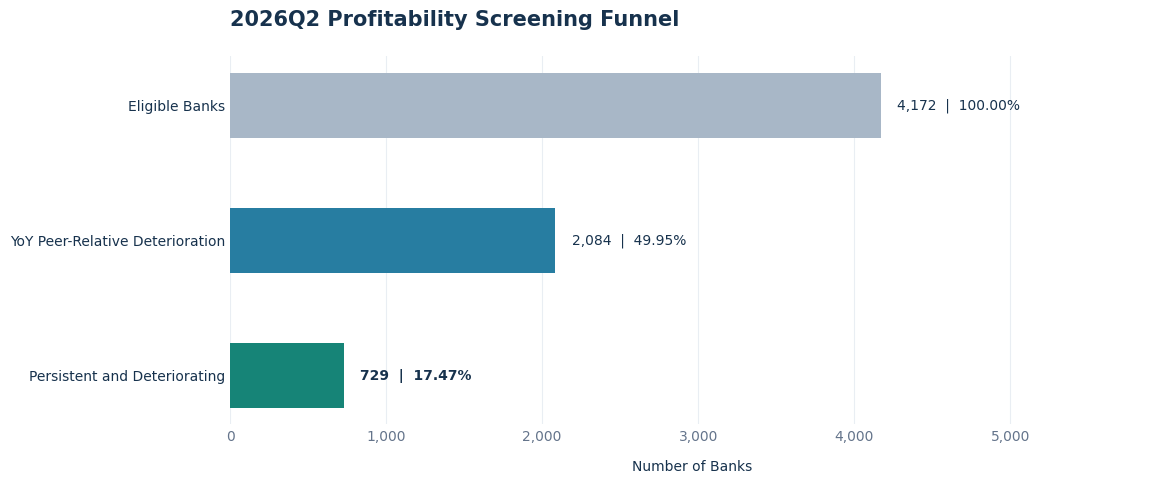

In [0]:
# Visualize the profitability screening funnel

import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 15,
    "axes.labelsize": 10,
    "axes.titleweight": "bold",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white"
})

navy = "#17324D"
teal = "#168477"
muted_blue = "#277DA1"
gray = "#A8B7C7"

stages = screening_funnel["Screening_Stage"]
banks = screening_funnel["Banks_Remaining"]
shares = screening_funnel["Share_of_Eligible_Pct"]

fig, ax = plt.subplots(figsize=(12, 5.2))

bars = ax.barh(
    stages,
    banks,
    color=[gray, muted_blue, teal],
    height=0.48
)

for bar, count, share in zip(bars, banks, shares):
    ax.text(
        bar.get_width() + banks.max() * 0.025,
        bar.get_y() + bar.get_height() / 2,
        f"{count:,}  |  {share:.2f}%",
        va="center",
        fontsize=10,
        fontweight="bold" if count == banks.min() else "normal",
        color=navy
    )

ax.invert_yaxis()
ax.set_xlim(0, banks.max() * 1.42)
ax.set_xlabel("Number of Banks", color=navy, labelpad=12)
ax.set_title(
    "2026Q2 Profitability Screening Funnel",
    loc="left",
    color=navy,
    pad=22
)

ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.grid(axis="x", color="#E9EEF3", linewidth=0.8)
ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.tick_params(axis="y", length=0, labelsize=10, colors=navy)
ax.tick_params(axis="x", length=0, colors="#64748B")

fig.tight_layout(pad=2)
plt.show()

**Key Findings - Profitability Screening Funnel**

At 2026Q2, **4,172 banks** had valid year-over-year peer-relative ROA comparisons.

Of these, **2,084 banks (49.95%)** experienced a decline in their ROA gap relative to the same quarter in the previous year.

Applying the additional requirement of four consecutive quarters below the relevant peer-group median reduced the population to **729 banks (17.47% of eligible banks)**.

These 729 banks form the combined-screening population used for subsequent financial diagnostics and management review.

The screening identifies institutions warranting further investigation, rather than establishing financial distress or regulatory risk classifications.

### 8.3 Dominant Negative Financial Drivers

This visualization summarizes the dominant negative financial contributions identified in Section 7.4 for the 729 combined-screening candidates at 2026Q2.

For each bank, the dominant negative driver is the accounting component with the largest negative contribution to its year-over-year ROA change between 2025Q2 and 2026Q2.

The chart ranks financial drivers by the number and percentage of candidate banks for which each component was the largest negative contributor.

The analysis highlights the prevalence of negative accounting contributions, not their aggregate financial magnitude. These contributions do not necessarily imply an overall decline in ROA and should not be interpreted as independently verified causes of profitability deterioration.

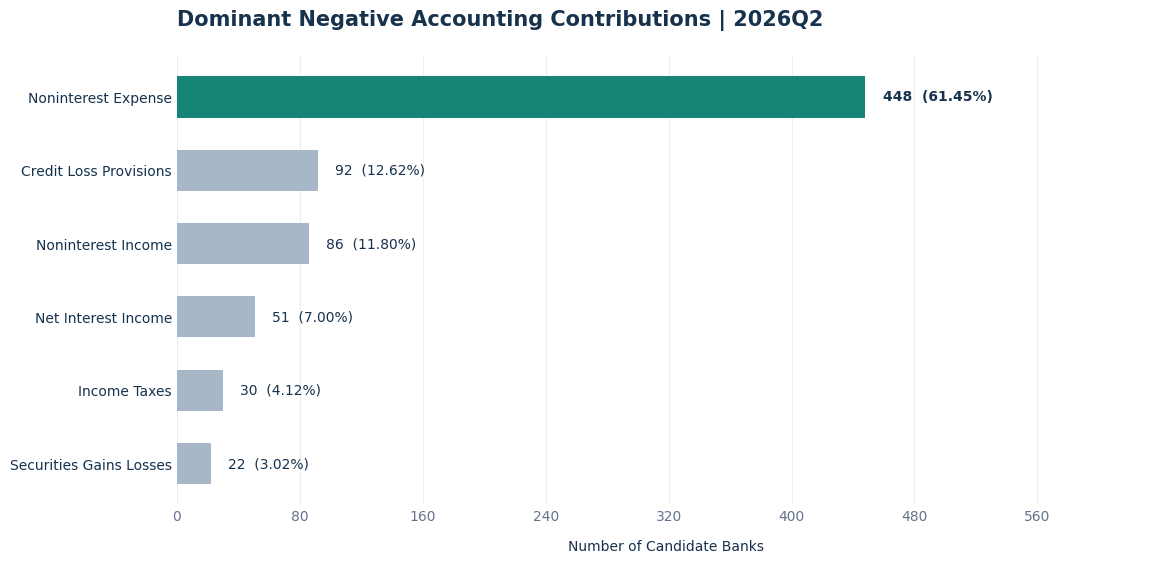

In [0]:
# Visualize dominant negative financial drivers

import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

driver_plot = driver_summary.sort_values(
    "Banks", ascending=True
).copy()

navy = "#17324D"
teal = "#168477"
gray = "#A8B7C7"

fig, ax = plt.subplots(figsize=(12, 6))

maximum_count = driver_plot["Banks"].max()

colors = [
    teal if count == maximum_count else gray
    for count in driver_plot["Banks"]
]

bars = ax.barh(
    driver_plot["DOMINANT_NEGATIVE_DRIVER"],
    driver_plot["Banks"],
    color=colors,
    height=0.56
)

for bar, count, share in zip(
    bars,
    driver_plot["Banks"],
    driver_plot["Share_Pct"]
):
    ax.text(
        bar.get_width() + maximum_count * 0.025,
        bar.get_y() + bar.get_height() / 2,
        f"{count:,}  ({share:.2f}%)",
        va="center",
        fontsize=10,
        color=navy,
        fontweight="bold" if count == maximum_count else "normal"
    )

ax.set_xlim(0, maximum_count * 1.42)
ax.xaxis.set_major_locator(MaxNLocator(integer=True))

ax.set_xlabel("Number of Candidate Banks", color=navy, labelpad=12)
ax.set_title(
    "Dominant Negative Accounting Contributions | 2026Q2",
    loc="left",
    fontsize=15,
    fontweight="bold",
    color=navy,
    pad=22
)

ax.grid(axis="x", color="#E9EEF3", linewidth=0.8)
ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.tick_params(axis="y", length=0, colors=navy)
ax.tick_params(axis="x", length=0, colors="#64748B")

fig.tight_layout(pad=2)
plt.show()

**Key Findings - Dominant Negative Financial Drivers**

Noninterest Expense was the most frequently identified dominant negative accounting contribution, representing **448 of the 729 combined-screening candidates (61.45%)**.

Credit Loss Provisions ranked second with **92 banks (12.62%)**, followed by Noninterest Income with **86 banks (11.80%)** and Net Interest Income with **51 banks (7.00%)**.

The concentration of dominant negative contributions in Noninterest Expense suggests that operating expense trends deserve particular attention during subsequent bank-level financial reviews.

However, these frequencies represent the number of banks for which each component was the largest negative contributor. They do not measure aggregate financial losses or establish the underlying causes of profitability deterioration.

### 8.4 Severity-Based Driver Comparison

This visualization compares the composition of dominant negative financial drivers across the four deterioration severity bands established in Section 6.6.

The analysis covers all 729 combined-screening candidates at 2026Q2:

- **Extreme deterioration:** 73 banks
- **Higher deterioration:** 110 banks
- **Moderate deterioration:** 182 banks
- **Lower deterioration:** 364 banks

Each bank is assigned to the financial component with its largest negative contribution to year-over-year ROA change.

The 100% stacked bar chart displays the distribution of these dominant drivers within each severity band. Percentages are calculated separately for each band, allowing comparisons despite differences in group size.

The visualization describes the composition of dominant negative contributions, not their total financial magnitude or causal impact on profitability.

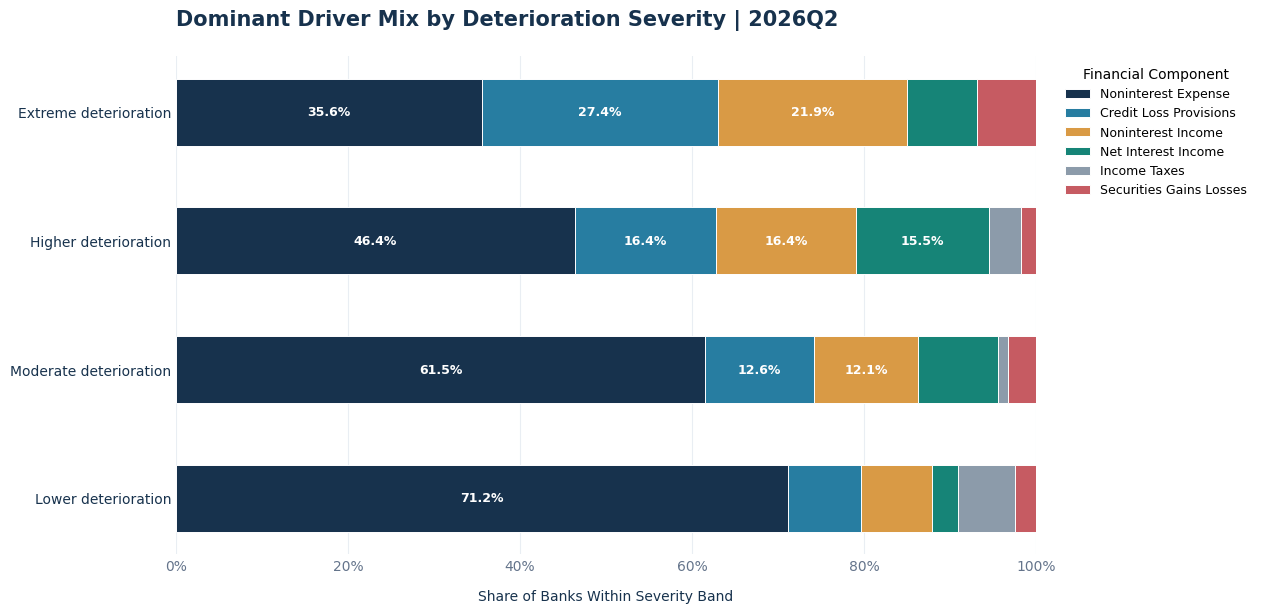

In [0]:
# Visualize financial contribution composition by severity band

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import numpy as np

severity_plot = severity_driver_matrix.T.copy()

navy = "#17324D"

driver_colors = {
    "Noninterest Expense": "#17324D",
    "Credit Loss Provisions": "#277DA1",
    "Noninterest Income": "#D99A45",
    "Net Interest Income": "#168477",
    "Income Taxes": "#8C9BAA",
    "Securities Gains Losses": "#C65B62"
}

fig, ax = plt.subplots(figsize=(13, 6.5))

left = np.zeros(len(severity_plot))

for driver in severity_plot.columns:
    values = severity_plot[driver].to_numpy()

    bars = ax.barh(
        severity_plot.index,
        values,
        left=left,
        label=driver,
        color=driver_colors.get(driver, "#B8C5D1"),
        height=0.52,
        edgecolor="white",
        linewidth=0.7
    )

    for bar, value in zip(bars, values):
        if value >= 10:
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                bar.get_y() + bar.get_height() / 2,
                f"{value:.1f}%",
                ha="center",
                va="center",
                fontsize=9,
                color="white",
                fontweight="bold"
            )

    left += values

ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.xaxis.set_major_formatter(PercentFormatter(xmax=100))

ax.set_xlabel(
    "Share of Banks Within Severity Band",
    color=navy,
    labelpad=12
)

ax.set_title(
    "Dominant Driver Mix by Deterioration Severity | 2026Q2",
    loc="left",
    fontsize=15,
    fontweight="bold",
    color=navy,
    pad=22
)

ax.legend(
    title="Financial Component",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=False,
    fontsize=9,
    title_fontsize=10
)

ax.grid(axis="x", color="#E9EEF3", linewidth=0.8)
ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.tick_params(axis="y", length=0, colors=navy)
ax.tick_params(axis="x", length=0, colors="#64748B")

fig.tight_layout(pad=2)
plt.show()

**Key Findings - Severity-Based Driver Comparison**

The composition of dominant negative accounting contributions varies across the four deterioration severity bands.

Noninterest Expense was the most frequently identified dominant negative contribution in every band, representing **71.15% of banks in the Lower deterioration group**, compared with **35.62% in the Extreme deterioration group**.

Credit Loss Provisions accounted for **8.52%** of banks in the Lower group versus **27.40%** in the Extreme group, while Noninterest Income represented **8.24%** and **21.92%**, respectively.

These patterns suggest that credit loss provisions and noninterest income deserve particular attention when reviewing banks with more severe peer-relative deterioration. The principal patterns remained consistent with the P1-P99 ROA change sensitivity analysis in Section 7.6.

The percentages represent the distribution of dominant negative accounting contributions within each severity band, not the magnitude of financial losses or evidence of causality.

### 8.5 Illustrative Bank-Level ROA Bridge

This section presents an illustrative bank-level example to demonstrate how year-over-year changes in estimated annualized quarterly ROA can be decomposed into earnings contributions and an asset-base effect.

The analysis compares 2025Q2 and 2026Q2 using the accounting bridge developed in Section 7.3.

The illustration follows two levels of decomposition:

1. **ROA Change:** Earnings Effect + Asset Base Effect.
2. **Earnings Effect:** Sum of eight financial statement contributions.

A bank is selected from the Extreme deterioration group, prioritizing cases with a meaningful negative earnings contribution, limited extraordinary-item effects, and a clearly identifiable dominant negative financial driver.

The selected case is intended to explain the accounting methodology rather than represent the typical experience of the 729 screening candidates.

All contributions are expressed in percentage points (pp). The accounting bridge provides descriptive attribution, not evidence of causality.

In [0]:
# Identify suitable banks for an illustrative ROA earnings bridge

illustrative_candidates = driver_analysis.merge(
    severity_df[
        ["CERT", "DETERIORATION_BAND", "GAP_DETERIORATION_PP"]
    ],
    on="CERT",
    how="inner",
    validate="one_to_one"
)

illustrative_candidates = illustrative_candidates.merge(
    bank_lookup[["CERT", "BANK_NAME"]].drop_duplicates("CERT"),
    on="CERT",
    how="left",
    validate="one_to_one"
)

# Focus on interpretable cases within the Extreme group
illustrative_candidates = illustrative_candidates.loc[
    (illustrative_candidates["DETERIORATION_BAND"] == "Extreme deterioration")
    & (illustrative_candidates["EARNINGS_EFFECT_PP"] < 0)
    & (illustrative_candidates["DOMINANT_NEGATIVE_DRIVER"].isin([
        "Noninterest Expense",
        "Credit Loss Provisions"
    ]))
    & (
        illustrative_candidates["Extraordinary_Items_CONTRIBUTION_PP"].abs()
        < illustrative_candidates["EARNINGS_EFFECT_PP"].abs()
    )
].copy()

# Rank cases by proximity to the group's median deterioration
extreme_median = severity_df.loc[
    severity_df["DETERIORATION_BAND"] == "Extreme deterioration",
    "GAP_DETERIORATION_PP"
].median()

illustrative_candidates["DISTANCE_FROM_EXTREME_MEDIAN"] = (
    illustrative_candidates["GAP_DETERIORATION_PP"]
    - extreme_median
).abs()

illustrative_candidates = illustrative_candidates.sort_values(
    ["DISTANCE_FROM_EXTREME_MEDIAN", "CERT"]
)

print("Eligible illustrative cases:", len(illustrative_candidates))

display(
    illustrative_candidates[
        [
            "CERT",
            "BANK_NAME",
            "DOMINANT_NEGATIVE_DRIVER",
            "ACTUAL_ROA_CHANGE_PP",
            "EARNINGS_EFFECT_PP",
            "ASSET_BASE_EFFECT_PP",
            "GAP_DETERIORATION_PP",
            "DISTANCE_FROM_EXTREME_MEDIAN"
        ]
    ].head(10).round(3)
)

Eligible illustrative cases: 46


CERT,BANK_NAME,DOMINANT_NEGATIVE_DRIVER,ACTUAL_ROA_CHANGE_PP,EARNINGS_EFFECT_PP,ASSET_BASE_EFFECT_PP,GAP_DETERIORATION_PP,DISTANCE_FROM_EXTREME_MEDIAN
33753,Citizens Community Bank,Credit Loss Provisions,-1.818,-1.898,0.08,1.955,0.0
9614,Local Bank,Noninterest Expense,-1.389,-1.551,0.162,2.0,0.044
16571,BMO Bank National Association,Noninterest Expense,-1.914,-1.907,-0.007,2.028,0.072
59330,Fortuna Bank,Noninterest Expense,-1.827,-2.887,1.06,2.038,0.083
18568,Community Bank of Easton,Noninterest Expense,-2.008,-2.003,-0.005,2.046,0.091
23989,Miners Exchange Bank,Noninterest Expense,-1.643,-1.641,-0.002,1.854,0.101
11317,The Iuka State Bank,Credit Loss Provisions,-2.185,-2.158,-0.027,2.194,0.238
6100,Harpeth Bank & Trust,Credit Loss Provisions,-1.577,-1.532,-0.046,1.714,0.241
11178,"Transpecos Banks, SSB",Credit Loss Provisions,-2.289,-2.541,0.253,2.297,0.341
32203,Summit State Bank,Credit Loss Provisions,-1.458,-1.422,-0.036,1.613,0.342


In [0]:
# Inspect the financial contributions of the selected bank

# Select the illustrative bank
selected_cert = 33753

# Verify that the bank meets the selection criteria
assert selected_cert in illustrative_candidates["CERT"].values, (
    "The selected bank does not meet the illustrative case criteria."
)

# Retrieve the selected bank's financial data
selected_bank = illustrative_candidates.loc[
    illustrative_candidates["CERT"] == selected_cert
].copy()

# Display bank information
print("Bank:", selected_bank["BANK_NAME"].iloc[0])
print("CERT:", selected_cert)
print(
    "Dominant negative driver:",
    selected_bank["DOMINANT_NEGATIVE_DRIVER"].iloc[0]
)

# Display ROA bridge
print("\nROA Bridge:")
print(
    selected_bank[
        [
            "ACTUAL_ROA_CHANGE_PP",
            "EARNINGS_EFFECT_PP",
            "ASSET_BASE_EFFECT_PP"
        ]
    ].round(4).to_string(index=False)
)

# Display financial contributions
print("\nFinancial Contributions:")
display(
    selected_bank[
        ["CERT"] + component_columns
    ].round(4)
)

Bank: Citizens Community Bank
CERT: 33753
Dominant negative driver: Credit Loss Provisions

ROA Bridge:
 ACTUAL_ROA_CHANGE_PP  EARNINGS_EFFECT_PP  ASSET_BASE_EFFECT_PP
              -1.8184             -1.8985                0.0801

Financial Contributions:


CERT,Net_Interest_Income_CONTRIBUTION_PP,Noninterest_Income_CONTRIBUTION_PP,Noninterest_Expense_CONTRIBUTION_PP,Credit_Loss_Provisions_CONTRIBUTION_PP,Income_Taxes_CONTRIBUTION_PP,Securities_Gains_Losses_CONTRIBUTION_PP,Extraordinary_Items_CONTRIBUTION_PP,Final_Net_Income_Adjustment_CONTRIBUTION_PP
33753,0.1586,-0.1953,-0.2527,-2.2922,0.683,0.0,0.0,0.0


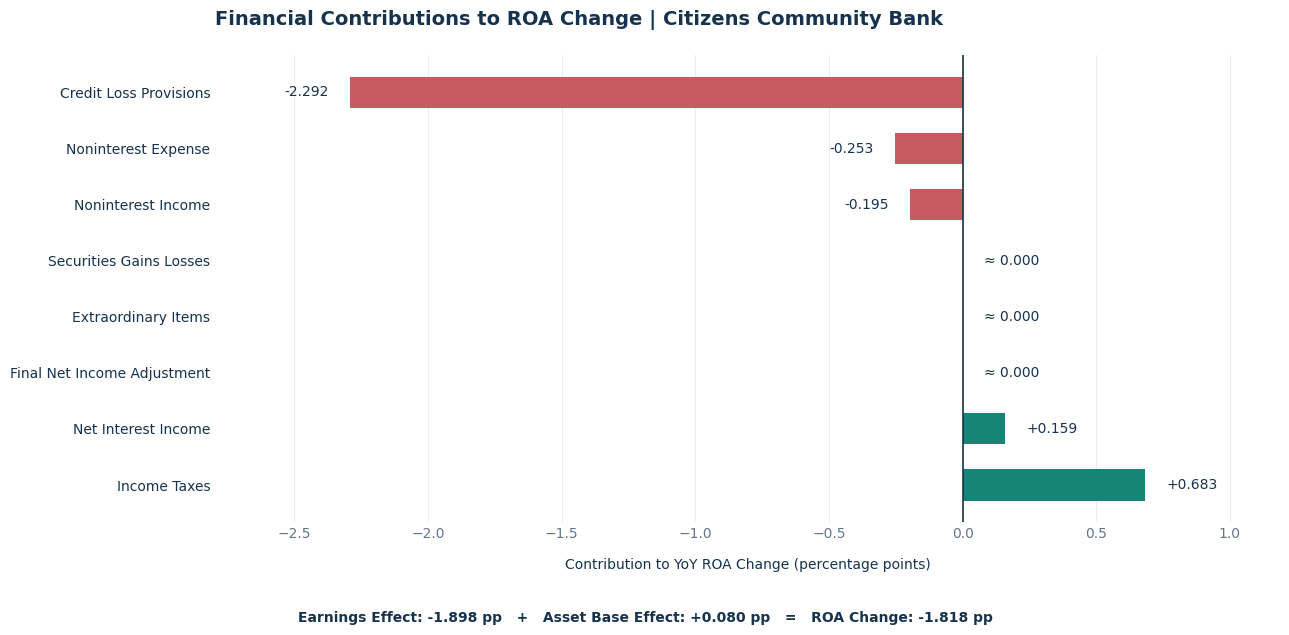

Bank: Citizens Community Bank
Financial components: 8
Earnings bridge reconciliation: PASSED


In [0]:
# Visualize financial contributions to ROA change

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

bank_row = selected_bank.iloc[0]

contributions = pd.DataFrame({
    "Component": [
        column.replace("_CONTRIBUTION_PP", "").replace("_", " ")
        for column in component_columns
    ],
    "Contribution_PP": [
        bank_row[column] for column in component_columns
    ]
})

contributions = contributions.sort_values(
    "Contribution_PP", ascending=True
).reset_index(drop=True)

# Validate the accounting bridge
total_contributions = contributions["Contribution_PP"].sum()
earnings_effect = bank_row["EARNINGS_EFFECT_PP"]
asset_base_effect = bank_row["ASSET_BASE_EFFECT_PP"]
actual_roa_change = bank_row["ACTUAL_ROA_CHANGE_PP"]

assert np.isclose(
    total_contributions, earnings_effect, atol=1e-8
)
assert np.isclose(
    earnings_effect + asset_base_effect,
    actual_roa_change,
    atol=1e-8
)

navy = "#17324D"
teal = "#168477"
negative_red = "#C65B62"

fig, ax = plt.subplots(figsize=(13, 6.5))

colors = [
    negative_red if value < 0 else teal
    for value in contributions["Contribution_PP"]
]

bars = ax.barh(
    contributions["Component"],
    contributions["Contribution_PP"],
    color=colors,
    height=0.56
)

ax.invert_yaxis()

max_abs = max(
    contributions["Contribution_PP"].abs().max(),
    0.001
)

offset = max_abs * 0.035

for bar, value in zip(bars, contributions["Contribution_PP"]):
    y_position = bar.get_y() + bar.get_height() / 2

    ax.text(
        value + (offset if value >= 0 else -offset),
        y_position,
        f"{value:+.3f}" if abs(value) >= 0.0005 else "≈ 0.000",
        ha="left" if value >= 0 else "right",
        va="center",
        fontsize=10,
        color=navy
    )

ax.axvline(0, color=navy, linewidth=1.2)

ax.set_xlim(
    min(contributions["Contribution_PP"].min(), 0) - max_abs * 0.22,
    max(contributions["Contribution_PP"].max(), 0) + max_abs * 0.22
)

ax.set_xlabel(
    "Contribution to YoY ROA Change (percentage points)",
    color=navy,
    labelpad=12
)

ax.set_title(
    f"Financial Contributions to ROA Change | {bank_row['BANK_NAME']}",
    loc="left",
    fontsize=14,
    fontweight="bold",
    color=navy,
    pad=22
)

ax.grid(axis="x", color="#E9EEF3", linewidth=0.8)
ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.tick_params(axis="y", length=0, colors=navy)
ax.tick_params(axis="x", length=0, colors="#64748B")

summary = (
    f"Earnings Effect: {earnings_effect:+.3f} pp"
    f"   +   Asset Base Effect: {asset_base_effect:+.3f} pp"
    f"   =   ROA Change: {actual_roa_change:+.3f} pp"
)

fig.text(
    0.5, 0.035,
    summary,
    ha="center",
    fontsize=10,
    fontweight="bold",
    color=navy
)

fig.tight_layout(rect=[0, 0.09, 1, 1])
plt.show()

print("Bank:", bank_row["BANK_NAME"])
print("Financial components:", len(contributions))
print("Earnings bridge reconciliation: PASSED")

**Key Findings - Illustrative Bank-Level ROA Bridge**

Citizens Community Bank (FDIC CERT 33753) was selected as an illustrative case from the Extreme deterioration group. Its year-over-year peer-relative ROA gap deterioration of approximately 1.955 percentage points was close to the group's median.

Between 2025Q2 and 2026Q2, the bank's estimated annualized quarterly ROA declined by 1.818 percentage points.

The accounting bridge attributed this change to:

- **Earnings Effect:** -1.898 pp
- **Asset Base Effect:** +0.080 pp
- **Actual ROA Change:** -1.818 pp

Credit Loss Provisions represented the largest negative financial contribution (-2.292 pp), followed by Noninterest Expense (-0.253 pp) and Noninterest Income (-0.195 pp).

Positive contributions from Income Taxes (+0.683 pp) and Net Interest Income (+0.159 pp) partially offset these negative contributions.

All eight financial components reconciled to the Earnings Effect, and the combined Earnings Effect and Asset Base Effect reconciled to the actual ROA change.

This case demonstrates how the accounting-based bridge can identify financial components warranting further investigation. It does not establish that changes in credit loss provisions caused the bank's profitability deterioration, nor does it imply that the selected bank represents the broader candidate population.

### 8.6 Management Review Shortlist

This section presents a focused management review shortlist of banks identified through the combined profitability screening at 2026Q2.

The shortlist ranks banks by the magnitude of year-over-year peer-relative ROA gap deterioration, using the validated severity framework from Section 6.6.

For each selected bank, the analysis reports:

- Deterioration severity classification.
- Year-over-year peer-relative ROA gap deterioration.
- Actual year-over-year ROA change.
- Four-quarter average peer-relative ROA gap.
- Dominant negative financial contribution.

The shortlist provides a transparent starting point for targeted financial investigation. Rankings reflect the magnitude of historical peer-relative deterioration, not regulatory risk, future financial distress, or the overall financial condition of each institution.

Extreme observations are retained in the primary shortlist. The outlier trimming in Section 7.6 was used only for sensitivity analysis.

In [0]:
# Build the 2026Q2 management review shortlist

# Start from the validated severity ranking
management_shortlist = severity_review.copy()

# Add the financial driver and ROA bridge results
management_shortlist = management_shortlist.merge(
    driver_analysis[
        [
            "CERT",
            "DOMINANT_NEGATIVE_DRIVER",
            "ACTUAL_ROA_CHANGE_PP",
            "EARNINGS_EFFECT_PP",
            "ASSET_BASE_EFFECT_PP"
        ]
    ],
    on="CERT",
    how="left",
    validate="one_to_one"
)

# Rank banks by peer-relative deterioration magnitude
management_shortlist = management_shortlist.sort_values(
    ["GAP_DETERIORATION_PP", "CERT"],
    ascending=[False, True]
).reset_index(drop=True)

management_shortlist["REVIEW_RANK"] = (
    np.arange(1, len(management_shortlist) + 1)
)

# Validate shortlist coverage
print("Candidate banks:", len(management_shortlist))
print("Unique banks:", management_shortlist["CERT"].nunique())

print(
    "Banks missing dominant driver:",
    management_shortlist["DOMINANT_NEGATIVE_DRIVER"].isna().sum()
)

print(
    "Banks missing four-quarter average gap:",
    management_shortlist["FOUR_QUARTER_AVG_GAP_PP"].isna().sum()
)

# Validate management shortlist completeness

assert len(management_shortlist) == len(severity_review), (
    "Management shortlist does not match the screening population."
)

assert management_shortlist["CERT"].is_unique, (
    "Duplicate banks found in the management shortlist."
)

required_shortlist_columns = [
    "GAP_DETERIORATION_PP",
    "ACTUAL_ROA_CHANGE_PP",
    "FOUR_QUARTER_AVG_GAP_PP",
    "DOMINANT_NEGATIVE_DRIVER"
]

assert management_shortlist[
    required_shortlist_columns
].notna().all().all(), (
    "Missing financial information in the management shortlist."
)

print("Management shortlist validation: PASSED")

# Display the top 10 banks for management review
display(
    management_shortlist[
        [
            "REVIEW_RANK",
            "CERT",
            "BANK_NAME",
            "DETERIORATION_BAND",
            "GAP_DETERIORATION_PP",
            "ACTUAL_ROA_CHANGE_PP",
            "FOUR_QUARTER_AVG_GAP_PP",
            "DOMINANT_NEGATIVE_DRIVER"
        ]
    ].head(10).round(3)
)

Candidate banks: 729
Unique banks: 729
Banks missing dominant driver: 0
Banks missing four-quarter average gap: 0
Management shortlist validation: PASSED


REVIEW_RANK,CERT,BANK_NAME,DETERIORATION_BAND,GAP_DETERIORATION_PP,ACTUAL_ROA_CHANGE_PP,FOUR_QUARTER_AVG_GAP_PP,DOMINANT_NEGATIVE_DRIVER
1,34997,BayFirst National Bank,Extreme deterioration,10.956,-10.848,-6.176,Credit Loss Provisions
2,23864,Summit Bank,Extreme deterioration,9.39,-9.253,-2.43,Noninterest Expense
3,4196,"SNB Bank, National Association",Extreme deterioration,7.638,-7.63,-2.056,Noninterest Income
4,16247,Neighbors Bank,Extreme deterioration,7.086,-6.949,-4.844,Noninterest Expense
5,17388,M C Bank & Trust Company,Extreme deterioration,6.443,-6.312,-2.004,Noninterest Expense
6,15930,Maxwell State Bank,Extreme deterioration,6.041,-5.548,-4.884,Noninterest Expense
7,16910,22nd State Banking Company,Extreme deterioration,5.599,-5.591,-1.388,Noninterest Income
8,1556,Twin Cedars Bank,Extreme deterioration,5.29,-5.158,-2.506,Credit Loss Provisions
9,20026,Eastern National Bank,Extreme deterioration,5.115,-5.379,-5.94,Noninterest Expense
10,28380,Adirondack Bank,Extreme deterioration,4.964,-4.794,-1.928,Noninterest Expense


**Key Findings - Management Review Shortlist**

The management review shortlist ranks the 729 combined-screening candidates by the magnitude of their year-over-year peer-relative ROA gap deterioration at 2026Q2.

All ten highest-ranked banks belonged to the Extreme deterioration group and experienced actual declines in estimated annualized quarterly ROA.

BayFirst National Bank (FDIC CERT 34997) ranked first, with peer-relative gap deterioration of 10.956 percentage points, an actual ROA decline of 10.848 pp, and a four-quarter average peer-relative ROA gap of -6.176 pp. Credit Loss Provisions represented its dominant negative financial contribution.

Summit Bank ranked second with gap deterioration of 9.390 pp, followed by SNB Bank, National Association at 7.638 pp. Their dominant negative contributions were Noninterest Expense and Noninterest Income, respectively.

The variation in dominant financial drivers suggests that bank-level reviews should investigate different accounting components rather than apply a uniform explanation for profitability deterioration.

The shortlist is intended to support transparent prioritization of further financial analysis. Rankings are based on historical peer-relative deterioration and do not constitute regulatory risk assessments, causal explanations, or forecasts of future bank distress.

### 8.7 Actual ROA Direction Among Screening Candidates

This visualization distinguishes between absolute profitability declines and peer-relative deterioration among the 729 combined-screening candidates at 2026Q2.

Banks are classified into two mutually exclusive groups based on their year-over-year change in estimated annualized quarterly ROA:

- **Actual ROA Declined:** Banks with a negative year-over-year ROA change.
- **Actual ROA Stable / Improved:** Banks with a zero or positive year-over-year ROA change.

All 729 banks met the combined screening criteria for persistent peer underperformance and year-over-year peer-relative deterioration.

The comparison highlights why peer-relative profitability analysis provides additional information beyond changes in a bank's own ROA.

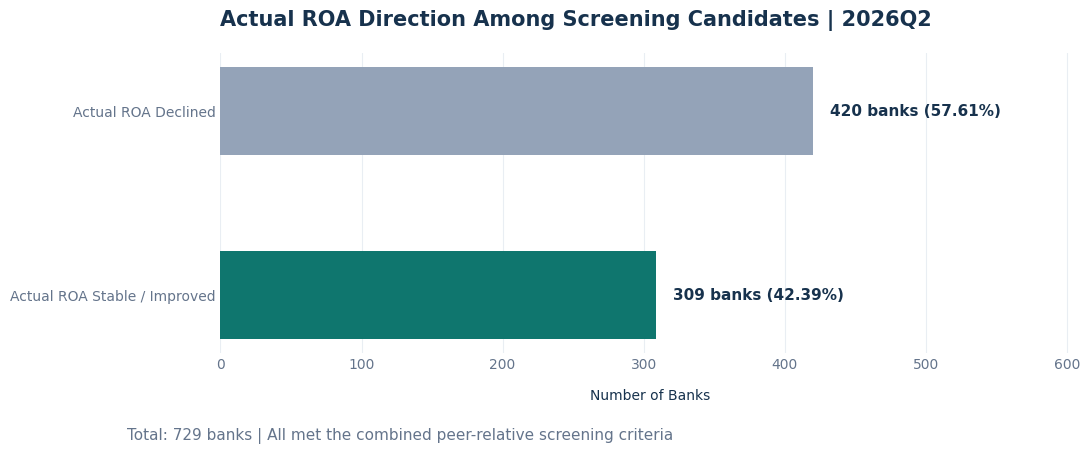

Total screening candidates: 729
Actual ROA declined: 420
Actual ROA stable / improved: 309


In [0]:
# Visualize actual ROA direction among screening candidates

import numpy as np
import matplotlib.pyplot as plt

# Prepare bank-level ROA change data
roa_direction_df = severity_df[
    ["CERT"]
].merge(
    bridge_data[
        ["CERT", "ACTUAL_ROA_CHANGE_PP"]
    ],
    on="CERT",
    how="inner",
    validate="one_to_one"
)

# Validate complete screening population
assert len(roa_direction_df) == len(severity_df), (
    "Some screening candidates are missing."
)

assert np.isfinite(
    roa_direction_df["ACTUAL_ROA_CHANGE_PP"]
).all(), (
    "Missing or non-finite ROA changes found."
)

# Classify banks by actual profitability direction
declined_count = (
    roa_direction_df["ACTUAL_ROA_CHANGE_PP"] < 0
).sum()

stable_improved_count = (
    roa_direction_df["ACTUAL_ROA_CHANGE_PP"] >= 0
).sum()

total_banks = len(roa_direction_df)

assert declined_count + stable_improved_count == total_banks

# Prepare chart values
categories = [
    "Actual ROA Declined",
    "Actual ROA Stable / Improved"
]

counts = [
    declined_count,
    stable_improved_count
]

percentages = [
    count / total_banks * 100
    for count in counts
]

# Section 8 color palette
navy = "#17324D"
teal = "#0F766E"
gray = "#94A3B8"

# Create horizontal bar chart
fig, ax = plt.subplots(figsize=(11, 4.5))

bars = ax.barh(
    categories,
    counts,
    color=[gray, teal],
    height=0.48
)

# Display bank counts and percentages
for bar, count, percentage in zip(
    bars, counts, percentages
):
    ax.text(
        bar.get_width() + 12,
        bar.get_y() + bar.get_height() / 2,
        f"{count:,} banks ({percentage:.2f}%)",
        va="center",
        ha="left",
        fontsize=11,
        fontweight="bold",
        color=navy
    )

# Chart title
ax.set_title(
    "Actual ROA Direction Among Screening Candidates | 2026Q2",
    loc="left",
    fontsize=15,
    fontweight="bold",
    color=navy,
    pad=20
)

ax.set_xlabel(
    "Number of Banks",
    color=navy,
    labelpad=12
)

# Place declining ROA group first
ax.invert_yaxis()

# Leave space for value labels
ax.set_xlim(0, max(counts) * 1.45)

# Clean styling
ax.xaxis.grid(
    color="#E9EEF3",
    linewidth=0.8
)

ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.tick_params(
    axis="both",
    length=0,
    colors="#64748B",
    labelsize=10
)

# Summary note
fig.text(
    0.12,
    0.01,
    f"Total: {total_banks:,} banks | "
    "All met the combined peer-relative screening criteria",
    fontsize=11,
    color="#64748B"
)

fig.tight_layout(rect=[0, 0.06, 1, 1])

plt.show()

# Display validation summary
print("Total screening candidates:", total_banks)
print("Actual ROA declined:", declined_count)
print("Actual ROA stable / improved:", stable_improved_count)

**Key Findings - Actual ROA Direction Among Screening Candidates**

Among the 729 combined-screening candidates at 2026Q2:

- **420 banks (57.61%)** experienced an actual year-over-year decline in estimated annualized quarterly ROA.
- **309 banks (42.39%)** maintained or improved their actual ROA despite deteriorating relative to their peers.

The results demonstrate that peer-relative deterioration does not necessarily indicate an absolute decline in profitability.

For the 309 banks with stable or improved ROA, deterioration reflects weaker profitability performance relative to the improvement or change observed in their respective peer benchmarks.

This distinction reinforces the value of combining absolute and peer-relative profitability measures when identifying banks for further management review.

The findings are descriptive and should not be interpreted as evidence of financial distress or future profitability outcomes.

### 8.8 Executive Takeaways & Limitations

**Key Takeaways**

1. **Targeted screening:** At 2026Q2, 729 of 4,172 eligible banks (17.47%) met both persistent peer underperformance and year-over-year peer-relative deterioration criteria.

2. **Relative vs. actual profitability:** Of these 729 candidates, 420 experienced actual ROA declines, while 309 maintained or improved their ROA but deteriorated relative to their peers.

3. **Dominant accounting contributions:** Noninterest Expense was the most frequent dominant negative accounting contribution (448 banks; 61.45%), followed by Credit Loss Provisions (92; 12.62%) and Noninterest Income (86; 11.80%).

4. **Severity differences:** Credit Loss Provisions and Noninterest Income were more prevalent as dominant negative contributions among banks in the Extreme deterioration group than in the Lower deterioration group, indicating different accounting patterns across severity bands.

5. **Robustness:** The leading dominant negative contribution rankings remained consistent after excluding 16 observations outside the P1-P99 range of actual ROA changes. This sensitivity analysis did not alter the primary 729-bank screening population.

**Management Implications**

Prioritize banks exhibiting sustained peer-relative profitability weakness, distinguish actual ROA declines from relative deterioration, and investigate bank-specific accounting contributions. Use severity bands to organize review priorities rather than interpret them as regulatory risk ratings.

**Key Limitations**

- Peer groups reflect asset size and real-estate loan concentration, but not every dimension of bank similarity.
- Peer-group calibration uses 2026Q2 characteristics retrospectively, limiting historical interpretation.
- Estimated annualized quarterly ROA is not directly equivalent to FDIC-reported year-to-date ROA.
- Accounting contributions describe changes in reported financial components and do not establish causality.
- Severity bands are project-defined, sample-relative categories rather than validated distress thresholds.
- The analysis uses a historical Delta snapshot; refreshing FDIC source data may produce different observations and results.
- Historical findings through 2026Q2 do not predict future bank performance.

**Conclusion**

This project combines peer-adjusted ROA benchmarking, persistent underperformance screening, and accounting-based earnings decomposition to identify and prioritize banks for further financial review. Its value lies in providing a transparent, reproducible analytical methodology within the documented data and environment constraints, rather than predicting bank distress.